# Ion exchange model

Function definitions:
- Model
    - Boundary conditions
    - Initial conditions
    - Parameter definition
    - Equation
    - Solver
    - Visualization
- Sensitivity
    - Local 
    - Global
        - Sampling
        - Evaluation
        - Analysis
- Calibration
    - Objective function
    - Calibration
    - Confidence interval
    - Correlation
- Uncertainty
- Validation

## Library import

In [1]:
import numpy as np
# import skfdiff
from skfdiff import Model, Simulation 

from matplotlib import pyplot as plt
import pandas as pd

from scipy.optimize import curve_fit, least_squares

from SALib.sample import saltelli
from SALib.analyze import sobol
from SALib import ProblemSpec

Zarr module not found, ZarrContainer not available.


## Experimental data

In [2]:
# Import experimental data from Zhang et al. (2015) – first 6 experiments
data = pd.read_csv("expdata.csv")

texp1a = data['time 1a'].dropna().to_numpy()
Cexp1a = data['1a'].dropna().to_numpy()
texp2a = data['time 2a'].dropna().to_numpy()
Cexp2a = data['2a'].dropna().to_numpy()
texp3a = data['time 3a'].dropna().to_numpy()
Cexp3a = data['3a'].dropna().to_numpy()
texp1b = data['time 1b'].dropna().to_numpy()
Cexp1b = data['1b'].dropna().to_numpy()
texp2b = data['time 2b'].dropna().to_numpy()
Cexp2b = data['2b'].dropna().to_numpy()
texp3b = data['time 3b'].dropna().to_numpy()
Cexp3b = data['3b'].dropna().to_numpy()

texp_data = [texp1a, texp2a, texp3a, texp1b, texp2b, texp3b]
Cexp_data = [Cexp1a, Cexp2a, Cexp3a, Cexp1b, Cexp2b, Cexp3b]

# Validation data
data = pd.read_csv("valdata.csv")

tval = data['BV'].dropna().to_numpy()
Cval = data['C/C0'].dropna().to_numpy()
Cerr = data['STD'].dropna().to_numpy()

In [3]:
data = dict(exp1a=(texp1a, Cexp1a), exp2a=(texp2a, Cexp2a), exp3a=(texp3a, Cexp3a), validation=(tval, Cval))

## Model definition

### Define domain

In [4]:
def define_domain(dx=None, Nx=None, L=0.1, dt=None, Nt=None, tmax=6., **parameters):

    # Spatial domain
    L = L
    
    if dx is None and Nx is None:
        Nx = 100
        z  = np.linspace(0, L, Nx+1)
        dx = z[1] - z[0]
        # print('dx =', dx)
    elif dx is not None:
        dx = dx
        # print('dx =', dx)
        Nx = int(round(L/dx))
        z  = np.linspace(0, L, Nx+1)
    elif Nx is not None:
        z  = np.linspace(0, L, Nx+1)
        dx = z[1] - z[0]
        # print('dx =', dx)
    
    # Temporal domain
    if dt is None and Nt is None:
        dt = 0.1
        Nt = int(round(tmax/dt))
        # print('dt =', dt)
    elif dt is not None:
        dt = dt
        # print('dt =', dt)
        Nt = int(round(tmax/dt))
    elif Nt is not None:
        dt = tmax/Nt
        # print('dt =', dt)
    
    return z, dx, Nx, dt, Nt, tmax

# Test the function
z, dx, Nx, dt, Nt, tmax = define_domain()
assert len(z) == 101
assert dx == 0.001
assert z.all() == np.linspace(0, 0.1, 101).all() # type: ignore
assert Nt == 60

z, dx, Nx, dt, Nt, tmax = define_domain(dx=0.01)
assert len(z) == 11
assert dx == 0.01
assert z.all() == np.linspace(0, 0.1, 11).all() # type: ignore
assert Nt == 60

z, dx, Nx, dt, Nt, tmax = define_domain(Nx=100, dt=0.1)
assert len(z) == 101
assert dx == 0.001
assert z.all() == np.linspace(0, 0.1, 101).all() # type: ignore
assert Nt == 60

z, dx, Nx, dt, Nt, tmax = define_domain(Nx=100, Nt=60)
assert len(z) == 101
assert dx == 0.001
assert dt == 0.1

z, dx, Nx, dt, Nt, tmax = define_domain(dt=0.01, tmax=4)
assert Nt == 400

### Parameter definition

In [5]:
def define_parameters(
    
    # Bed properties
    L = 0.1,                         # bed length [m]
    D = 0.01,                        # bed diameter [m]
    e = 0.37,                        # bed porosity [-]

    # Liquid properties
    rho_f = 1e3,                     # density [g/L]     - assumed equal to water
    mu    = 1e-3,                    # viscosity [Pa·s]  – assumed equal to water

    # Resin properties
    rp    = 0.5 * 7.5e-4,            # particle radius [m]
    rho_p = 389,                     # particle density [g/L]

    # Operational properties
    Q  = 2.5e-6/60 * 0.37,           # volumetric flow rate [m3/s]
    C0 = 672/31,                     # influent concentration [mmol/L]
    q0 = None,                       # initial concentration in the resin [mg/g]

    # Intraparticle diffusion
    Dp  = 5.3e-10,                   # intraparticle dispercion coefficient [m2/s]

    # Equilibrium isotherms
    ## Freundlich
    Kf = 0.149, 
    nf = 0.255,

    ## Langmuir
    qmax = 0.291,
    Kl   = 1.18,

    # Simulation parameters
    # Nx    = None, 
    # dx    = None,
    # Nt    = None,
    # dt    = None, 
    # tmax  = 6., 
    
	# Calibration data
    texp = texp1a,
    Cexp = Cexp1a,
    expdata = 'exp1a',
    
	# Additional parameters
    **parameters
    ):

    # Define domain
    z, dx, Nx, dt, Nt, tmax = define_domain(**parameters)

    # Define dependencies
    A = np.pi/4 * D**2              # bed section [m2]
    V = A*L                         # bed volume [m3]

    u   = Q/(A * e)                   # bed velocity [m/s]
    rho = rho_p * (1 - e)             # bed bulk density [g/L] 

    kldf = 15 * Dp / rp**2            # linear driving force coefficient [s-1]

    ## Dimensionless numbers
    tau = L/u                        # residence time [s]
    
    Re  = 2*rp * u * rho_f / mu       # Reynolds number [-]
    phi = 1.7                         # fitted number for calculation of diffusivity (Zhang et al., 2015)

                                        # axial dispersion coefficient [m2/s] from expression (Zhang et al., 2015):
    Dz  = mu / rho_f * phi * Re / (0.20 + 0.011 * Re**0.48)

    Pe = u * L / Dz                 # Peclet number [-]
    
	# Number of calibrated parameters
    Np = parameters['Np'] if 'Np' in parameters else 0
    
	# Number of data points
    N = len(texp)
    global data
    texp = data[expdata][0] # type: ignore
    Cexp = data[expdata][1] # type: ignore

    # Store all parameters in a dictionary
    params = dict(z=z, dx=dx, Nx=Nx, dt=dt, Nt=Nt, L=L, D=D, e=e, rho_f=rho_f, mu=mu, rp=rp, rho_p=rho_p, 
                  Q=Q, C0=C0, q0=q0, Dp=Dp, Kf=Kf, nf=nf, qmax=qmax, Kl=Kl, A=A, V=V, u=u, rho=rho, kldf=kldf,
                  tau=tau, Re=Re, Dz=Dz, Pe=Pe, tmax=tmax, texp=texp, Cexp=Cexp, Np=Np, N=N)
    
    return params

# Test the function
params = define_parameters(Nx=100)
assert params['Nx'] == 100
assert params['dx'] == 0.001 # L is 0.1 by default
assert params['Nt'] == 60

params = define_parameters(qmax=0.3)
assert params['qmax'] == 0.3

params = define_parameters(dt=0.05)
assert params['Nt'] == 120
assert params['L'] == 0.1

params = define_parameters(expdata='exp2a')
assert params['texp'] is texp2a
assert params['Cexp'] is Cexp2a

### Boundary conditions

In [6]:
def boundary_conditions(C_left="dirichlet", C_right="dzC", q_left="dzq", q_right="dzq"):
        
    boundary_conditions = {("C", "z") : (C_left, C_right),
                           ("q", "z") : (q_left, q_right)}
    
    return boundary_conditions

### Initial conditions

In [7]:
def initial_conditions(parameters, C0=20., q0=None, dimensionless=True):

	# Define domain
	z = parameters['z']

	## Initial profiles
	C = 1e-6*np.ones_like(z)  # initial concentration in the liquid along the column
	q = 1e-6*np.ones_like(z)  # initial concentration in the resin along the column

	if dimensionless:
		C[0] = 1.           # type: ignore  initial concentration at the left boundary (normalized)
	else:
		C[0] = C0           # type: ignore  initial concentration at the left boundary (mg/L)

	# Initial conditions for the resin
	if q0 is not None:
		qmax = parameters['qmax']
		Kl = parameters['Kl']
		C0 = parameters['C0']

		qm = qmax * Kl * C0/(1 + Kl * C0)       # maximum sorption capacity
		parameters['qm'] = qm
		print('qm =', qm)
		print('q0 =', q0)

		pfouled = q0/qm                         # percentage of fouled resin at initial conditions
		parameters['pfouled'] = pfouled
		print('pfouled =', pfouled)

		q[0:int(pfouled*Nx+1)] = qmax/2         # type: ignore   # initial percentage of fouled resin

		# Assume linear interpolation of the initial concentration for the rest of the column to reproduce resin profile
		q[int(pfouled*Nx+1):int(Nx/2+1)] = np.interp(z[int(pfouled*Nx+1):int(Nx/2+1)], [z[int(pfouled*Nx+1)], z[int(0.5*Nx+1)]], [qmax/2, 1e-6]) # type: ignore
		# print(q)

		# q0[int(0.05*Nx):] = 0 # type: ignore
		# print(q0)
		# q0 = q0 * np.ones_like(z) # type: ignore
    
    
	return C, q

# Test the function
params = define_parameters(C0=20.)
C, q = initial_conditions(params, dimensionless=True)
assert C[0] == 1.
assert C.shape == (101,)

params = define_parameters(C0=20., Nx=10)
C, q = initial_conditions(params, C0=params['C0'], dimensionless=False)
assert C[0] == 20.
assert C.shape == (11,)

# Test with fouling
params = define_parameters(q0=0.05)
C, q = initial_conditions(params, q0=params['q0'])
assert params['qm'] == 0.2800516529928637           # maximum sorption capacity = 0.291 * 1.18 * 672/31/(1 + 1.18 * 672/31)
assert params['pfouled'] == 0.1785384926875404      # percentage of fouled resin at initial conditions (normalized)


qm = 0.2800516529928637
q0 = 0.05
pfouled = 0.1785384926875404


### Model equations

In [8]:
def define_equations(parameters, boundary_conditions,
                     dimensionless=True, isotherm="Langmuir"):

    if dimensionless:
        # Dimensionless parameters
        C0      = parameters["C0"]              # initial concentration in the liquid [mmol/L]
        tau     = parameters["tau"]             # reference time, equal to residence time [s]
        Pe      = parameters["Pe"]              # Péclet number: advection/dispersion ratio [-]
        kldf    = parameters["kldf"] * tau      # linear driving force transer coefficient [-]
        qmax    = parameters["qmax"]            # maximum sorption capacity [-]  ?
        Kl      = parameters["Kl"]              # Langmuir constant [-]
        rho     = parameters["rho"]             # bulk density of the resin [g/L]
        e       = parameters["e"]               # bed porosity [-]

        if isotherm == "Langmuir":
            z = np.linspace(0, 1, parameters["Nx"]+1) # dimensionless axial coordinate [-]

            qm = qmax * Kl * C0/(1 + Kl * C0)   # maximum normalized sorption capacity [-]
            parameters['qm'] = qm
            Kl = 1

            Dg   = (qm * rho)/(C0 * e)          # solid/liquid ratio [-]
            parameters['Dg'] = Dg

            model = Model(["1/Pe * dzzC - upwind(1, C, z, 1) - Dg * kldf*(qmax*Kl*C/(1+Kl*C) - q)",
                           "kldf*(qmax*Kl*C/(1+Kl*C) - q)"],
                           unknowns=["C(z)", "q(z)"],
                           coordinates=["z"],
                           parameters=["kldf", "Pe", "Dg", "Kl", "qmax"],
                           boundary_conditions=boundary_conditions,
                           backend="numpy"
                           )

            C, q = initial_conditions(parameters, C0=C0, q0=parameters['q0'], dimensionless=True) # initial concentration profiles in the liquid and resin

            initial_fields = model.Fields(z=z, C=C, q=q, Pe=Pe, kldf=kldf, Dg=Dg, Kl=Kl, qmax=qmax)

        ## Freundlich isotherm
        elif isotherm == "Freundlich":
            print("Not implemented yet")

    else:
        print("Not implemented yet")

    return model, initial_fields

# Test the function
params = define_parameters(dt=0.05)
bc = boundary_conditions()
model, initial_fields = define_equations(params, bc)
model
initial_fields
# print(initial_fields.qm)

<xarray.Dataset>
Dimensions:  (z: 101)
Coordinates:
  * z        (z) float64 0.0 0.01 0.02 0.03 0.04 ... 0.96 0.97 0.98 0.99 1.0
Data variables:
    C        (z) float64 1.0 1e-06 1e-06 1e-06 1e-06 ... 1e-06 1e-06 1e-06 1e-06
    q        (z) float64 1e-06 1e-06 1e-06 1e-06 ... 1e-06 1e-06 1e-06 1e-06
    kldf     float64 10.66
    Pe       float64 16.24
    Dg       float64 8.557
    Kl       int64 1
    qmax     float64 0.291

### Solver

In [9]:
def solve_model(model_equations, initial_fields, params, progress=True):
    """
    Solve the model equations using the initial fields and parameters

    Parameters
    ----------
    model_equations : Model
        Model equations
    initial_fields : Fields

    Returns
    -------
    container : Container
    """

    tmax = params['tmax']
    dt = params['dt']
    
    simulation  = Simulation(model_equations, initial_fields, dt=dt, tmax=tmax)
    container   = simulation.attach_container()

    ## Run simulation
    simulation.run(progress)
    
    return container

# Test the function
params = define_parameters(dt=0.05)
bc = boundary_conditions()
model, initial_fields = define_equations(params, bc)
container = solve_model(model, initial_fields, params, progress=False)

### Visualization

#### Concentration profiles

In [10]:
def plot_profiles(results, params, size=6):
    """
    Plot concentration profiles vs column length over time.
    """

    z = results['z']
    L = params['L']
    BV = results['BV']
    texp = results['texp']
    Cexp = results['Cexp']
    C = results['C']
    BC = results['BC']

    fig, ax = plt.subplots(figsize=(size,size))

    plot_every = 1

    for i in range(0, len(C), plot_every):
        ax.plot(z/L, C[i,:])

    ax.set_xlabel('Column length, $z/L$', fontsize=3*size)
    ax.set_ylabel('Normalized concentration, $C/C_0$', fontsize=3*size)
    ax.tick_params(labelsize=3*size)
    ax.set_xlim(0, 1)
    ax.set_ylim(0)
    # ax1.set_xlim(0, max(BV))
    # ax1.legend(fontsize=40)

    # Overimpose breakthrough curve
    ax.plot(BV/int(max(max(BV), max(texp))), BC, 'k-.', lw=5)

    # Plot data
    ax.plot(texp/int(max(max(BV), max(texp))), Cexp, color='darkgreen', marker='s', markersize=10, linestyle='-')

# Test the function
# plot_profiles(results, params)

#### Breakthrough curve

In [11]:
def plot_breakthrough(results, params, size=6):
    """
    Plot validation curve of breakthrough.
    """
    
    BV = results['BV']
    texp = results['texp']
    Cexp = results['Cexp']
    BC = results['BC']
    
    # Plot experimental data
    fig, ax = plt.subplots(figsize=(size,size))
    ax.scatter(texp, Cexp, color='midnightblue', marker='s', s=30*size, label='exp')

    # Plot model
    ax.plot(BV, BC, color='darkorange', linewidth=5, label='model')

    ax.set_xlabel('Bed volumes', fontsize=3*size)
    ax.set_ylabel('Normalized concentration, $C/C_0$', fontsize=3*size)
    ax.tick_params(labelsize=3*size)
    ax.set_xticks(np.linspace(0, 16, 9))
    ax.set_ylim(0)
    ax.set_xlim(0, int(max(max(BV), max(texp))))
    ax.legend(fontsize=4*size)

    plt.show()

    # Test function

# plot_breakthrough(results, params)


### Main function

In [12]:
def model(#Nx=None, dx=None, Nt=None, dt=None, tmax=6.,        # simulation parameters 
		#   texp=texp1a, Cexp=Cexp1a,                           # experimental data for calibration
			isotherm='Langmuir', dimensionless=True,            # model assumptions
			profiles=False, breakthrough=False, progress=True,  # output options
			**parameters                                        # model parameters
			):

	# Define parameters
	params = define_parameters(#Nx=Nx, dx=dx, Nt=Nt, dt=dt, tmax=tmax, 
								**parameters)

	# Boundary conditions
	bc = boundary_conditions(C_left="dirichlet", C_right="dzC", q_left="dzq", q_right="dzq")

	# Define model equations
	model_equations, initial_fields = define_equations(params, bc, isotherm=isotherm, dimensionless=dimensionless)

	# Solve model
	container = solve_model(model_equations, initial_fields, params, progress=progress)

	t = container.data['t'].data * params['tau']      # type:ignore 	time [s] 
	C = container.data['C'].data                      # type:ignore 	concentration profiles in the liquid [-]
	q = container.data['q'].data                      # type:ignore 	concentration profiles in the resin [-]
	BC = container.data['C'].data[:, -1]              # type:ignore 	breakthrough curve [-]

	# Convert time to bed volumes: no. of columns/s / bed volume [-] 
	BV = t * (params['Q']/params['e'])/(params['V']*params['e']) 

	# Calibration data
	texp = params['texp'] 
	Cexp = params['Cexp']
	N = params['N']			# number of data points
	Np = params['Np'] 		# number of parameters

	# interpolate model results at experimental time points from texp of calibration data
	params['Cint'] = Cint = np.interp(texp, BV, BC, left=1e-6, right=1.) 

	# Calculate SSR, RMSE, AIC and BIC for calibration
	params['RMSE_calibration'] = np.sqrt(np.square(Cexp - Cint).mean())
	params['SSR_calibration'] = SSR = np.sum((Cint - Cexp)**2)
	# Akaike Information Criterion (AIC)
	params['AIC_calibration_orig'] = N * np.log(SSR/N) + 2*Np 							# n*log(SSR/n) + 2k
	params['AIC_calibration_corr'] = N * np.log(SSR/N) + 2*Np + 2*Np*(Np+1)/(N-Np-1) 	# n*log(SSR/n) + 2k + 2k(k+1)/(n-k-1)
	# Bayesian Information Criterion (BIC)
	params['BIC_calibration'] = N * np.log(SSR/N) + Np*np.log(N) 						# n*log(SSR/n) + k*log(n)
	
	if progress:
		print(f"No. of parameters = {Np}")
		print(f"RMSE (calibration) = {params['RMSE_calibration']:.4f}")    
		print(f"SSR (calibration) = {params['SSR_calibration']:.4f}")
		print(f"AIC (calibration, original) = {params['AIC_calibration_orig']:.1f}")
		print(f"AIC (calibration, corrected) = {params['AIC_calibration_corr']:.1f}")
		print(f"BIC (calibration) = {params['BIC_calibration']:.1f}")

	# Store results in a dictionary
	results = {'t' : t,                         # time [bed volumes]
				'z' : params['z'],			 	# column domain [m]
				'C' : C,
				'q' : q,
				'BC': BC,
				'BV': BV,
				'texp': texp,
				'Cexp': Cexp,
				'N' : N,
				'Np' : Np,
				'Cint': params['Cint'],
				'RMSE': params['RMSE_calibration'],
				'SSR': params['SSR_calibration'],
				'AIC_orig': params['AIC_calibration_orig'],
				'AIC_corr': params['AIC_calibration_corr'],
				'BIC': params['BIC_calibration'],
				'params': params,
				'container': container,
				'parameters': parameters,
	}

	# Plot results
	if profiles: plot_profiles(results, params)

	if breakthrough: plot_breakthrough(results, params)

	# Return results
	return results, params, container

0f0ad9 running: t: 6: : 60it [00:02, 21.21it/s]                          


No. of parameters = 2
RMSE (calibration) = 0.0864
SSR (calibration) = 0.1491
AIC (calibration, original) = -94.0
AIC (calibration, corrected) = -93.3
BIC (calibration) = -92.0


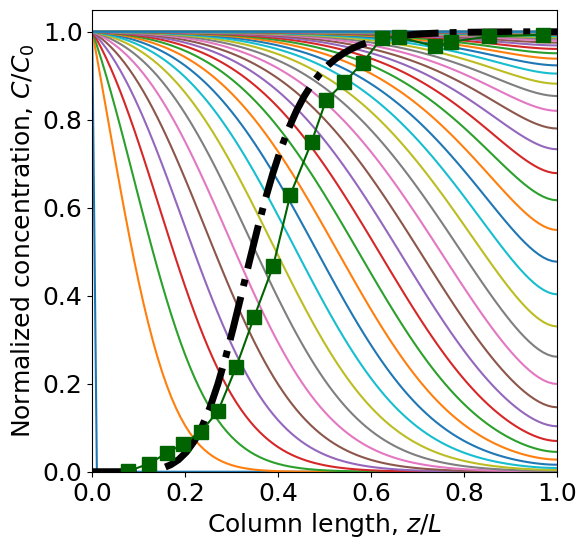

In [13]:
# Test model
results, params, container = model(Nx=100, dt=0.1, tmax=6., isotherm='Langmuir', dimensionless=True, profiles=True, breakthrough=False, texp=texp1a, Cexp=Cexp1a, Np=2)
# results

In [14]:
params

{'z': array([0.   , 0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008,
        0.009, 0.01 , 0.011, 0.012, 0.013, 0.014, 0.015, 0.016, 0.017,
        0.018, 0.019, 0.02 , 0.021, 0.022, 0.023, 0.024, 0.025, 0.026,
        0.027, 0.028, 0.029, 0.03 , 0.031, 0.032, 0.033, 0.034, 0.035,
        0.036, 0.037, 0.038, 0.039, 0.04 , 0.041, 0.042, 0.043, 0.044,
        0.045, 0.046, 0.047, 0.048, 0.049, 0.05 , 0.051, 0.052, 0.053,
        0.054, 0.055, 0.056, 0.057, 0.058, 0.059, 0.06 , 0.061, 0.062,
        0.063, 0.064, 0.065, 0.066, 0.067, 0.068, 0.069, 0.07 , 0.071,
        0.072, 0.073, 0.074, 0.075, 0.076, 0.077, 0.078, 0.079, 0.08 ,
        0.081, 0.082, 0.083, 0.084, 0.085, 0.086, 0.087, 0.088, 0.089,
        0.09 , 0.091, 0.092, 0.093, 0.094, 0.095, 0.096, 0.097, 0.098,
        0.099, 0.1  ]),
 'dx': 0.001,
 'Nx': 100,
 'dt': 0.1,
 'Nt': 60,
 'L': 0.1,
 'D': 0.01,
 'e': 0.37,
 'rho_f': 1000.0,
 'mu': 0.001,
 'rp': 0.000375,
 'rho_p': 389,
 'Q': 1.541666666666667e-08,
 'C0': 21.677

In [15]:
results['t']

array([   0.        ,   18.84955592,   37.69911184,   56.54866776,
         75.39822369,   94.24777961,  113.09733553,  131.94689145,
        150.79644737,  169.64600329,  188.49555922,  207.34511514,
        226.19467106,  245.04422698,  263.8937829 ,  282.74333882,
        301.59289474,  320.44245067,  339.29200659,  358.14156251,
        376.99111843,  395.84067435,  414.69023027,  433.5397862 ,
        452.38934212,  471.23889804,  490.08845396,  508.93800988,
        527.7875658 ,  546.63712172,  565.48667765,  584.33623357,
        603.18578949,  622.03534541,  640.88490133,  659.73445725,
        678.58401318,  697.4335691 ,  716.28312502,  735.13268094,
        753.98223686,  772.83179278,  791.6813487 ,  810.53090463,
        829.38046055,  848.23001647,  867.07957239,  885.92912831,
        904.77868423,  923.62824016,  942.47779608,  961.327352  ,
        980.17690792,  999.02646384, 1017.87601976, 1036.72557568,
       1055.57513161, 1074.42468753, 1093.27424345, 1112.12379

In [16]:
print(results['t'].shape)
print(results['BC'].shape)

(61,)
(61,)


## Discretization analysis

## Sensitivity

### Local sensitivity

#### Plot sensitivities

In [17]:
# Function to plot sensitivities 
def plot_sensitivity(sensitivities, labels=None, size=15, font=20, **parameters):
    
    # Plot sensitivity functions over time
    fig, ax = plt.subplots(1, 2, figsize=(size,6))

    plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
    "text.latex.preamble" : r"\usepackage{amsmath}"
    })


    plt.suptitle('Local sensitivity analysis of breakthrough curve', fontsize=font+5, y=1.02)

    
    plt.rcParams['text.usetex'] = True
    
    ax[0].axhline(y=0., color='grey', ls='-', lw=0.5)
    ax[1].axhline(y=0., color='grey', ls='-', lw=0.5)

    names = []

    for parameter, value in parameters.items():
        
        t = sensitivities['t']
        S = sensitivities[parameter]

        # Scientific notation for exponential values
        def as_si(x, ndp):
            s = '{x:0.{ndp:d}e}'.format(x=x, ndp=ndp)
            m, e = s.split('e')
            return '{m:s}\\cdot 10^{{{e:d}}}'.format(m=m, e=int(e))
        
        # Plot the sensitivity functions
        if labels == None: 
            label = parameter
        else:
            label = dict(zip(parameters.keys(), labels))[parameter]
            names.append(label.split(' ')[0])

        # Plot only sensitivities above a certain value

        # if np.max(np.abs(S)) > 0.1:    
        if value < 1e-2:
            ax[0].plot(t, S, label=label.format(as_si(value,2)))
        else:
            ax[0].plot(t, S, label=label.format(value))

        # ax[0].grid(True, axis='y', which='major', color='gray', linestyle='-', linewidth=0.5)
        ax[0].set_xlim(0, 16)
        ax[0].set_xlabel('Bed volumes', fontsize=font)
        ax[0].set_ylabel(r'Relative sensitivity', fontsize=font)
        ax[0].set_xticks(np.linspace(0, 16, 9), fontsize=font)
        ax[0].set_title('(a) Time variation for all parameters', fontsize=font)
        ax[0].legend(loc='lower right', fontsize=0.8*font)
        ax[0].tick_params(axis='x', labelsize=font)
        ax[0].tick_params(axis='y', labelsize=font)

        # Plot average value
        ax[1].bar(parameter, np.sign(S.mean())*np.abs(S).mean())
        # ax[1].set_yscale('symlog', linthresh=1e-2)
        # # ax[1].set_ylim(-5e-1, 5e-1)
        # ax[1].grid(True, axis='y', which='minor', color='gray', linestyle='-', linewidth=0.2)
        ax[1].set_title('(b) Average sensitivity', fontsize=font)
        # ax[1].grid(True, axis='y', which='major', color='gray', linestyle='-', linewidth=0.5)
        # ax[1].set_ylim(-0.45, 0.45)
        ax[1].set_title('(b) Relative sensitivity: time average with sign', fontsize=font)
        # ax[1].set_ylabel(r'Average relative sensitivity, $S=\frac{\partial C}{\partial \theta}\theta$', fontsize=font)
        ax[1].tick_params(axis='x', labelsize=font)
        ax[1].tick_params(axis='y', labelsize=font)
        # ax[0].set_yticks([1e-3, 1e-2, 1e-1, 1])
        ax[1].set_xlabel('Parameters', fontsize=font)
        # ax[1].set_xlim(-1, 11)

        # ax[1].hlines(0.05, -1, 11, color='gray', linestyle=':', linewidth=1)
        # ax[1].hlines(-0.05, -1, 11, color='gray', linestyle=':', linewidth=1)

        # Print sensitivity values
        print(" {:s}: {:.2f}".format(parameter, np.mean(S)))

    if labels==None: 
        labels = parameters.keys()
        positions = range(len(labels)) 
        ax[1].set_xticks(positions, labels)
    else:
        positions = range(len(labels)) 
        ax[1].set_xticks(positions, names)
    
    # ax[1].tick_params(axis='x', labelsize=font)
    # ax[1].tick_params(axis='y', labelsize=font)
    # # ax[1].set_yticks([-5e-1, -1e-1, 0, 1e-2, 1e-1, 5e-1])
    # # ax[1].set_yticklabels(['-0.5', '-0.1', '0', '0.01', '0.1', '0.5'])
        if labels==None: labels = parameters.keys()
    # positions = range(len(labels)) 
    # ax[1].set_xticks(positions, labels)
    # if np.max(np.abs(S)) < 0.1:    
    #     ax[1].plot(t, S, label= label + ' = ' + str(value))
    #     ax[1].grid(True, axis='y', which='major', color='gray', linestyle='-', linewidth=0.5)
    #     ax[1].set_xlim(0, 16)
    #     ax[1].set_xlabel('Bed volumes', fontsize=font)
    #     # ax[1].set_ylabel(r'Relative sensitivity, $\frac{\partial C}{\partial \theta}\theta$', fontsize=font)
    #     ax[1].set_xticks(np.linspace(0, 16, 9), fontsize=font)
    #     ax[1].set_title('(b) Time variation for S under 0.1', fontsize=font)
    #     ax[1].legend(loc='lower right', fontsize=font-10)
    #     ax[1].tick_params(axis='x', labelsize=font)
    #     ax[1].tick_params(axis='y', labelsize=font)

    # Store figure
    # plt.savefig("sensitivity-local-"+str(len(parameters))+".pdf", format="pdf", bbox_inches="tight")
    # plt.show()

#### Forward sensitivity

In [18]:
def forward_sensitivity(model, xi=1e-5, dt=0.1, relative=True, labels=None, plot=False, progress=True, **parameters):
    """
    Function to calculate sensitivities.
    """
    sensitivities = {}
    
    # 1) First just run the model with original parameter values
    Np = len(parameters)
    print(f"Run 1 of {Np+1:d} : {parameters}")
    # print(parameters.items())
    results1, params1, container1 = model(dt=dt, profiles=False, breakthrough=False, progress=progress, **parameters) 
    
    # Store the time vector
    sensitivities['t'] = results1['BV']
    C1 = results1['BC']

    # Read keyword arguments: parameter-value pairs
    run = 1
    for parameter, value in parameters.items():
        run += 1

        # 2) Now run the model with the adapted parameter value for each parameter
        parameters[parameter] = value*(1 + xi)
        print(f"Run {run:d} of {Np+1:d} : {parameters}")

        results2, params2, container2 = model(dt=dt, profiles=False, breakthrough=False, progress=progress, **parameters)
        C2 = results2['BC']
    
        # Calculate the local relative sensitivity function (wrt. the parameter value)
        if relative: 
            sensitivities[parameter] = (C2 - C1)/xi; 
        else: 
            sensitivities[parameter] = (C2 - C1)/(xi*value)
        
        # Restore original value
        parameters[parameter] = value
        
    # Plot the sensitivity function
    if plot:
        plot_sensitivity(sensitivities, labels=labels, **parameters) # type: ignore

    # Store sensitivity values # TODO
    # N = len(parameters)
    # todisk = pd.DataFrame.from_dict(sensitivities)
    # todisk.to_csv(f"local_N-{N:d}_dt-{dt:f}.csv")
    
    return sensitivities


Run 1 of 2 : {'qmax': 0.291}
Run 2 of 2 : {'qmax': 0.29100291}
 qmax: -0.38


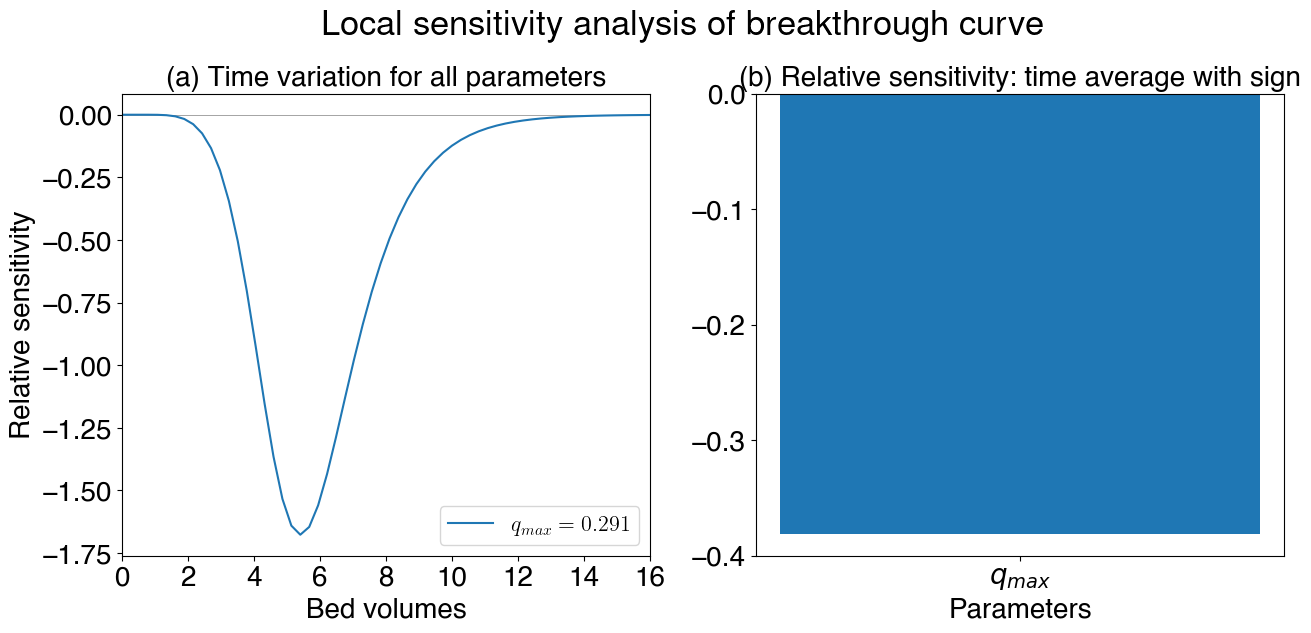

In [18]:
# Test the function

S = forward_sensitivity(model, dt=0.1, labels=['$q_{{max}}$ $ = {{{:.3f}}}$'], plot=True, progress=False, qmax=0.291)

In [19]:
S

{'t': array([ 0.        ,  0.27027027,  0.54054054,  0.81081081,  1.08108108,
         1.35135135,  1.62162162,  1.89189189,  2.16216216,  2.43243243,
         2.7027027 ,  2.97297297,  3.24324324,  3.51351351,  3.78378378,
         4.05405405,  4.32432432,  4.59459459,  4.86486486,  5.13513514,
         5.40540541,  5.67567568,  5.94594595,  6.21621622,  6.48648649,
         6.75675676,  7.02702703,  7.2972973 ,  7.56756757,  7.83783784,
         8.10810811,  8.37837838,  8.64864865,  8.91891892,  9.18918919,
         9.45945946,  9.72972973, 10.        , 10.27027027, 10.54054054,
        10.81081081, 11.08108108, 11.35135135, 11.62162162, 11.89189189,
        12.16216216, 12.43243243, 12.7027027 , 12.97297297, 13.24324324,
        13.51351351, 13.78378378, 14.05405405, 14.32432432, 14.59459459,
        14.86486486, 15.13513514, 15.40540541, 15.67567568, 15.94594595,
        16.21621622]),
 'qmax': array([ 0.00000000e+00, -1.19665655e-06, -1.61850383e-06, -2.93962347e-05,
        -3.5

 qmax: -0.38


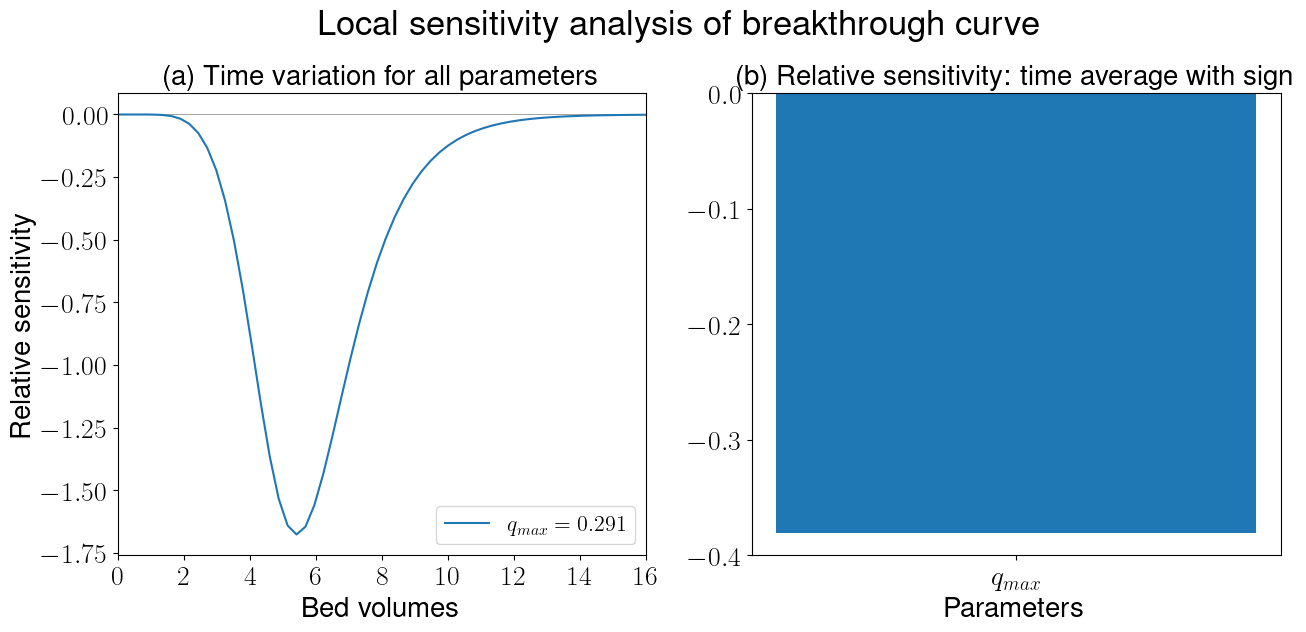

In [20]:
# Test the function
plot_sensitivity(S, labels=['$q_{{max}}$ $ = {{{:.3f}}}$'], qmax=0.291)

#### Optimal perturbation

Not implemented.

#### LSA: N = 11

In [21]:
S11 = forward_sensitivity(model, dt=0.01, plot=False,
                          C0=672/31, 
                          # q0 = 0.05,
                          Q=1.5e-8, 
                          L=0.1, 
                          D=0.01, 
                          rp=3.75e-4, 
                          rho_p=389, 
                          e=0.37,
                          Dz=3.2e-6,
                          Dp=5.3e-10,
                          qmax=0.291,
                          Kl=1.18,
)

Run 1 of 12 : {'C0': 21.677419354838708, 'Q': 1.5e-08, 'L': 0.1, 'D': 0.01, 'rp': 0.000375, 'rho_p': 389, 'e': 0.37, 'Dz': 3.2e-06, 'Dp': 5.3e-10, 'qmax': 0.291, 'Kl': 1.18}


51c65e running: t: 6: : 600it [00:23, 26.06it/s]                            


RMSE (calibration) = 0.0867
SSR (calibration) = 0.1505
AIC (calibration) = -73.8
Run 2 of 12 : {'C0': 21.67763612903226, 'Q': 1.5e-08, 'L': 0.1, 'D': 0.01, 'rp': 0.000375, 'rho_p': 389, 'e': 0.37, 'Dz': 3.2e-06, 'Dp': 5.3e-10, 'qmax': 0.291, 'Kl': 1.18}


9e3e7f running: t: 6: : 600it [00:22, 26.33it/s]                            


RMSE (calibration) = 0.0867
SSR (calibration) = 0.1505
AIC (calibration) = -73.8
Run 3 of 12 : {'C0': 21.677419354838708, 'Q': 1.500015e-08, 'L': 0.1, 'D': 0.01, 'rp': 0.000375, 'rho_p': 389, 'e': 0.37, 'Dz': 3.2e-06, 'Dp': 5.3e-10, 'qmax': 0.291, 'Kl': 1.18}


...

RMSE (calibration) = 0.0867
SSR (calibration) = 0.1505
AIC (calibration) = -73.8
Run 11 of 12 : {'C0': 21.677419354838708, 'Q': 1.5e-08, 'L': 0.1, 'D': 0.01, 'rp': 0.000375, 'rho_p': 389, 'e': 0.37, 'Dz': 3.2e-06, 'Dp': 5.3e-10, 'qmax': 0.29100291, 'Kl': 1.18}


7b5b8f running: t: 6: : 600it [00:22, 27.07it/s]                            


RMSE (calibration) = 0.0867
SSR (calibration) = 0.1505
AIC (calibration) = -73.8
Run 12 of 12 : {'C0': 21.677419354838708, 'Q': 1.5e-08, 'L': 0.1, 'D': 0.01, 'rp': 0.000375, 'rho_p': 389, 'e': 0.37, 'Dz': 3.2e-06, 'Dp': 5.3e-10, 'qmax': 0.291, 'Kl': 1.1800118}


ebd08b running: t: 6: : 600it [00:21, 27.28it/s]                            


RMSE (calibration) = 0.0867
SSR (calibration) = 0.1505
AIC (calibration) = -73.8


 C0: 0.19
 Q: -0.00
 L: -0.02
 D: 0.00
 rp: 0.02
 rho_p: -0.19
 e: 0.31
 Dz: 0.00
 Dp: -0.00
 qmax: -0.39
 Kl: -0.01


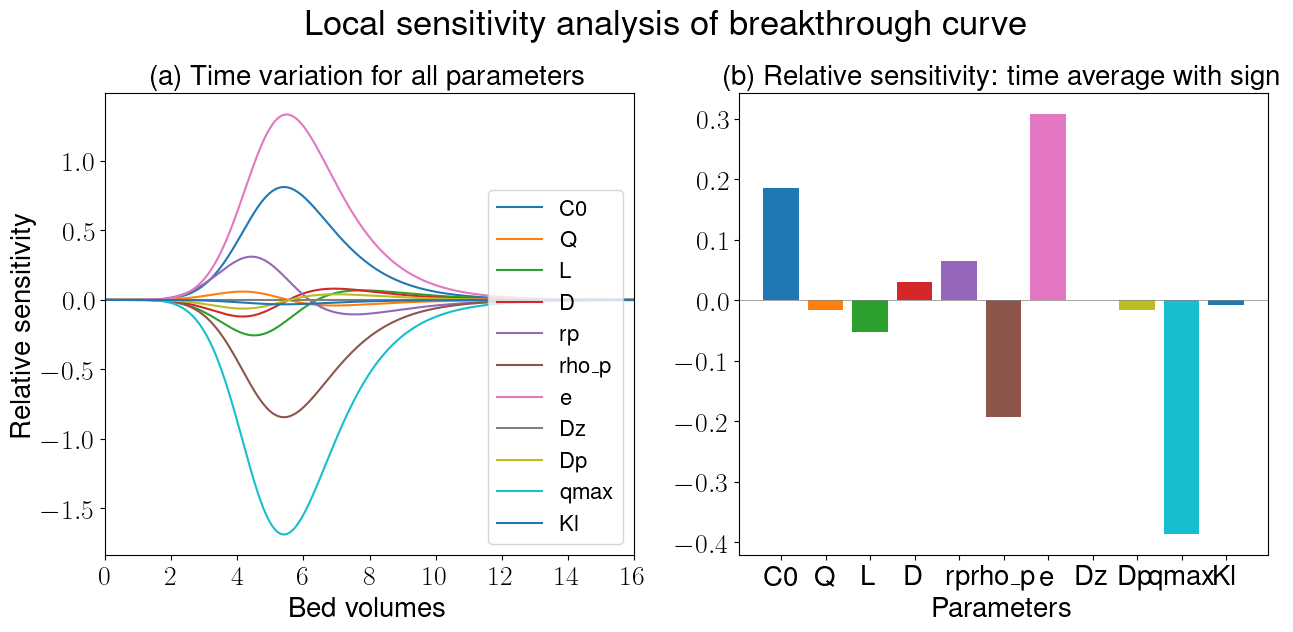

In [22]:
plot_sensitivity(S11, C0=672/31, 
                          # q0 = 0.05,
                          Q=1.5e-8, 
                          L=0.1, 
                          D=0.01, 
                          rp=3.75e-4, 
                          rho_p=389, 
                          e=0.37,
                          Dz=3.2e-6,
                          Dp=5.3e-10,
                          qmax=0.291,
                          Kl=1.18,)

### Global sensitivity

1. Sample parameters
2. Evaluate model
3. Store in disk
4. Calculate indices
5. Plot figure

#### Sampling

In [728]:
# Generate Monte Carlo sampling for parameters

from SALib.sample import saltelli
from SALib.analyze import sobol
from SALib import ProblemSpec

def sampling(N, calc_second_order=True, generate_new=False, **parameters):

    # Define no. of parameters
    Np = len(parameters.keys())
    print("No. of parameters =", Np)

    # Define no. of samples
    if calc_second_order:
        print("No. of samples =", N*(2*Np + 2))
    else:
        print("No. of samples =", N*(  Np + 2))

    # Names of the parameters
    names = [parameters[name][0] for name in parameters.keys()]

    # Define bounds
    bounds = [[(1-parameters[name][2]/100) * parameters[name][1], (1+parameters[name][2]/100) * parameters[name][1]] for name in parameters.keys()]

    # Define problem spec
    sp = ProblemSpec({
        'num_vars': Np,
        'names': names,
        'bounds': bounds, 
        'outputs': ['Y']
    })

    if generate_new==False:
        try:
            print("Reading existing sampling...")
            pars = pd.read_csv(f"sampling_Np-{Np:d}_N-{N:d}.csv")
            sp.set_samples(pars.iloc[:,-Np:].to_numpy())
            return sp
        except:
            print("File not found. Generate new sampling first.")
            return sp
        

    # Generate samples
    print("Generating new sampling...")
    sp.sample_sobol(N=N, calc_second_order=calc_second_order) # type: ignore

    params = sp.samples
    params.shape # type: ignore

    # Store in disk
    sampling = pd.DataFrame(params)
    labels = dict(zip(range(Np), names))
    sampling.rename(columns=labels, inplace=True)
    sampling.to_csv(f"sampling_Np-{Np:d}_N-{N:d}.csv")

    return sp

# Test the function
N = 2**0 # file should not exist

sp = sampling(N=N,                          # no. of samples
              calc_second_order=True,       # calculate second order effects
              generate_new=False,           # generate new sampling

                                            # parameters = (name, value, uncertainty)
              C0    =('$C_0$',          672/31,              20),
              Q     =('$Q$',            2.5e-6/60 * 0.37,    20),
              L     =('$L$',            0.1,                 20), 
              D     =('$D$',            0.01,                20), 
              rp    =('$r_p$',          0.5 * 7.5e-4,        20), # 60% uncertainty
              rho_p =('$\\rho_p$',      389,                 20), 
              e     =('$\\varepsilon$', 0.37,                20), 
              Dp    =('$D_p$',          5.3e-10,             20), 
              qmax  =('$q_{max}$',      0.291,               20), 
              Kl    =('$K_L$',          1.18,                20)
              )

# Generate Monte Carlo sampling for parameters
N = 2**1

sp = sampling(N=N,                          # no. of samples
              calc_second_order=True,       # calculate second order effects
              generate_new=True,            # generate new sampling

                                            # parameters = (name, value, uncertainty)
              C0    =('$C_0$',          672/31,              20), 
              Q     =('$Q$',            2.5e-6/60 * 0.37,    20), 
              L     =('$L$',            0.1,                 20), 
              D     =('$D$',            0.01,                20), 
              rp    =('$r_p$',          0.5 * 7.5e-4,        20), # 20% uncertainty
              rho_p =('$\\rho_p$',      389,                 20), 
              e     =('$\\varepsilon$', 0.37,                20), 
              Dp    =('$D_p$',          5.3e-10,             20), 
              qmax  =('$q_{max}$',      0.291,               20), 
              Kl    =('$K_L$',          1.18,                20)
              )

# Read file
Np = sp['num_vars']
pars = pd.read_csv(f"sampling_Np-{Np:d}_N-{N:d}.csv")
print(sp.samples.shape)

# Load sampling for an existing file withouth generating new sampling
sp = sampling(N=N,                          # no. of samples
              calc_second_order=True,       # calculate second order effects
              generate_new=False,           # generate new sampling

                                            # parameters = (name, value, uncertainty)
              C0    =('$C_0$',          672/31,              20),
              Q     =('$Q$',            2.5e-6/60 * 0.37,    20),
              L     =('$L$',            0.1,                 20), 
              D     =('$D$',            0.01,                20), 
              rp    =('$r_p$',          0.5 * 7.5e-4,        20), # 20% uncertainty
              rho_p =('$\\rho_p$',      389,                 20), 
              e     =('$\\varepsilon$', 0.37,                20), 
              Dp    =('$D_p$',          5.3e-10,             20), 
              qmax  =('$q_{max}$',      0.291,               20), 
              Kl    =('$K_L$',          1.18,                20)
              )
print(sp.samples.shape)


No. of parameters = 10
No. of samples = 22
Reading existing sampling...
File not found. Generate new sampling first.
No. of parameters = 10
No. of samples = 44
Generating new sampling...
(44, 10)
No. of parameters = 10
No. of samples = 44
Reading existing sampling...
(44, 10)


In [729]:
sp = sampling(N=2**8,                          # no. of samples
              calc_second_order=True,       # calculate second order effects
              generate_new=False,            # generate new sampling

                                            # parameters = (name, value, uncertainty)
              C0    =('$C_0$',          672/31,              20), 
              Q     =('$Q$',            2.5e-6/60 * 0.37,    20), 
              L     =('$L$',            0.1,                 20), 
              D     =('$D$',            0.01,                20), 
              rp    =('$r_p$',          0.5 * 7.5e-4,        20), # 20% uncertainty
              rho_p =('$\\rho_p$',      389,                 20), 
              e     =('$\\varepsilon$', 0.37,                20), 
              Dp    =('$D_p$',          5.3e-10,             20), 
              qmax  =('$q_{max}$',      0.291,               20), 
              Kl    =('$K_L$',          1.18,                20)
              )



No. of parameters = 10
No. of samples = 5632
Reading existing sampling...


#### Model evaluation

In [24]:
def evaluation(pars, 
               Nx=100, dt=0.1, tmax=6., progress=False, **parameters):

    # Choose simulation parameters
    Nx    = Nx
    dt    = dt
    tmax  = tmax

    # Create simulation matrices to store data
    Y = np.zeros([pars.shape[0], int(np.ceil(tmax/dt) + 1)]) # no. of samples x no. of time points
    T = np.zeros((pars.shape[0], int(np.ceil(tmax/dt) + 1))) # no. of samples x no. of time points
    BT = np.zeros(pars.shape[0]) # no. of samples

    # Run model
    for i in range(pars.shape[0]): # type: ignore
        D = pars.loc[i]['$D$']
        L = pars.loc[i]['$L$']
        Q = pars.loc[i]['$Q$']
        C0 = pars.loc[i]['$C_0$']
        e = pars.loc[i]['$\\varepsilon$']
        rho_p = pars.loc[i]['$\\rho_p$'] 
        rp = pars.loc[i]['$r_p$']
        qmax = pars.loc[i]['$q_{max}$']
        Kl = pars.loc[i]['$K_L$']
        Dp = pars.loc[i]['$D_p$']
        
        print(f'Run {i+1:d} of {pars.shape[0]}') # type: ignore
        # print(f'qmax = {qmax:.3f}, Kl = {Kl:.2f}, Q = {Q:.3e}, e = {e:.2f}, rp = {rp:.3e}, Dp = {Dp:.2e}, D = {D:.3f}, L = {L:.2f}, rho_p = {rho_p:.3f}, C0 = {C0:.2f}')

        results, params, container = model(Nx=Nx, dt=dt, tmax=tmax, 
                                           D=D, L=L, Q=Q, C0=C0, e=e, rho_p=rho_p, rp=rp, qmax=qmax, Kl=Kl, Dp=Dp,
                                           
                                           isotherm = 'Langmuir',
                                           profiles = False, 
                                           breakthrough = False,
                                           progress=progress,
                                           )
        
        # Store results
        Y[i, :] = results['BC']     # breakthrough curve
        T[i, :] = results['BV']     # time in bed volumes

        # Calculate breakthrough times
        CBT = results['BC'][np.where(results['BC'] >= 0.1)]
        BT[i] = np.min(results['BV'][np.where(results['BC'] >= 0.1)])
        if progress:
            print("Breakthrough: C= {:.4f} at {:.2f} BV".format(np.min(CBT), BT[i]))

        # Store data to disk
        simulations = pd.DataFrame(Y)
        simulations.to_csv(f"simulations_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv")
        times = pd.DataFrame(T)
        times.to_csv(f"times_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv")
        breakthrough = pd.DataFrame(BT)
        breakthrough.to_csv(f"breakthrough_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv")

    return T, Y, BT

# Test the function

T, Y, BT = evaluation(pars, tmax=4)

Run 1 of 44
Run 2 of 44
Run 3 of 44
Run 4 of 44
Run 5 of 44
Run 6 of 44
Run 7 of 44
Run 8 of 44
Run 9 of 44
Run 10 of 44
Run 11 of 44
Run 12 of 44
Run 13 of 44
Run 14 of 44
Run 15 of 44
Run 16 of 44
Run 17 of 44
Run 18 of 44
Run 19 of 44
Run 20 of 44
Run 21 of 44
Run 22 of 44
Run 23 of 44
Run 24 of 44
Run 25 of 44
Run 26 of 44
Run 27 of 44
Run 28 of 44
Run 29 of 44
Run 30 of 44
Run 31 of 44
Run 32 of 44
Run 33 of 44
Run 34 of 44
Run 35 of 44
Run 36 of 44
Run 37 of 44
Run 38 of 44
Run 39 of 44
Run 40 of 44
Run 41 of 44
Run 42 of 44
Run 43 of 44
Run 44 of 44


#### Regression coefficients

In [741]:
sims.shape
pars.shape

(5632, 11)

In [746]:
sims.shape

(5632, 41)

In [749]:
# Calculate breakthrough times
N = 2**8
Np = sp['num_vars']
dt = 0.1
tmax = 4.

pars = pd.read_csv(f"sampling_Np-{Np:d}_N-{N:d}.csv")
sims = pd.read_csv(f"simulations_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv").iloc[:,1:].to_numpy()

BT = np.zeros(sims.shape[0]+1)

for i in range(0, sims.shape[0]):
    CBT = sims[i,[np.where(sims[i] >= 0.1)]] # breakthrough curve
    BT[i] = np.min(CBT)

# Store data to disk
breakthrough = pd.DataFrame(BT)
breakthrough.to_csv(f"breakthrough_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv")

ValueError: zero-size array to reduction operation minimum which has no identity

In [353]:
def regression_coefficients(sp, pars, BT):

    b_init = np.ones(Np+1)

    # Perform a linear regression with a linear combination of the parameters and a bias 
    # We use sickit-learn library to perform the linear regression
    from sklearn.linear_model import LinearRegression

    # y = theta_0 * x_0 + theta_1 * x_1 + ... + b_0
    reg = LinearRegression().fit(pars, BT)

    # print('Coefficients (b_i): ({}), \nIntercept (b_0): {:.4f}, \nR2: {:.4f}\n'.format(reg.coef_,reg.intercept_,reg.score(pars, BT)))

    # Calculate the relative error to test the model predictive power
    # Random point
    # index_rand = 53
    # error_pred = [100*(ys[index_rand]-reg.predict(np.array([params[index_rand,:]])))/ys[index_rand]][0][0]
    # print('Error(%):{:.4f}'.format(error_pred))

    # Calculate SRCs for every parameter:
    names = sp['names']

    # Calculate the output variable standard deviation
    y_sigma = np.std(BT[:,1])
    # print(BT)
    print(f"Standard deviation of breakthrough time [BV]:\n{y_sigma}\n")

    # They should be close to the standard deviation defined previously from np.random.random(mean,std)
    theta_sigma = np.std(pars[:,1:], axis=0)
    # print(pars)
    print(f'Standard deviations:\n{theta_sigma}\n')

    # print(f'sigma_y: {y_sigma:.4f}, sigma_Kf: {Kf_sigma:.4f}, sigma_nf: {nf_sigma:.4f}, sigma_Dz: {Dz_sigma:.4f}, sigma_Dp: {Dp_sigma:.4f}')

    SRC = reg.coef_*np.std(pars, axis=0)/y_sigma
    print(f'SRCs: {SRC}')
    print("len(SRC):", SRC.shape)

    print(names)
    # for i in range(len(SRC)):
        # print(f'SRC_{names[i]:s}: {SRC[i][0,i]:.4f}')

    # Check how close we are if the model would be linear (r2=1 which explaines all the variance in the model)
    print(f'Sum of SRCs:\n{np.sum(SRC**2)}')

    return SRC

# Test the function
N = 2**1
Np = sp['num_vars']
dt = 0.1
tmax = 4.

pars = pd.read_csv(f"sampling_Np-{Np:d}_N-{N:d}.csv").to_numpy()
BT = pd.read_csv(f"breakthrough_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv").to_numpy()

SRC = regression_coefficients(sp, pars, BT)

Standard deviation of breakthrough time [BV]:
0.6440362044607926

Standard deviations:
[2.08634009e+00 9.88924120e-10 1.06461339e-02 1.66955004e-03
 5.78053369e-05 3.54005305e+01 1.71491881e-02 8.10697532e-11
 3.89724552e-02 1.71090835e-01]

SRCs: [[ 1.97169429e+01 -3.59461681e-16  2.09512919e-16 -1.92449372e-16
   3.46624767e-16  3.34079927e-16 -2.19993637e-14 -1.51124695e-16
   1.61861405e-17  1.21085218e-15  2.27577308e-16]
 [-7.71565755e-02 -4.17534601e-01  2.16817022e-02  2.01953013e-01
   1.72701589e-01 -4.58877915e-01  2.91870296e-01 -5.33384740e-01
   1.39130817e-01  1.14410369e+00  1.25334673e-01]]
len(SRC): (2, 11)
['$C_0$', '$Q$', '$L$', '$D$', '$r_p$', '$\\rho_p$', '$\\varepsilon$', '$D_p$', '$q_{max}$', '$K_L$']
Sum of SRCs:
390.9335043268323


#### Scatter plots

In [ ]:
def scatter_plot():
    pass

#### Plot total/first indices

In [754]:
def plot_indices(first_Si, total_Si, font=10):    
# Plot total-order indices and first-order indices

    fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(8,4), constrained_layout=True)
    # plt.rcParams['text.usetex'] = True
    plt.rcParams.update({
        "text.usetex": True,
        "font.family": "sans-serif",
        "font.sans-serif": "Helvetica",
        # "text.latex.preamble" : r"\usepackage{amsmath}"
        })

    gs = fig.add_gridspec(1, 1)
    fig.set_dpi(300)
    # fig.suptitle("Global sensitivity analysis of breakthrough curve: Sobol sensitivity indices", fontsize=font+5, y=1.1)
    axs.remove()

    labels = sp['names']

    indices = {
        # 'Total': Si['ST'],
        'First': first_Si['S1']
    }

    # face_colors = ['#165682' if value < 0.1 else '#1f77b4' for value in indices['First']]
    # face_alphas = [value/np.max(indices['First']) for value in indices['First']]

    # face_colors = list(zip(face_colors, face_alphas))

    x = np.arange(len(labels))  # the label locations
    width = 0.4  # the width of the bars
    multiplier = 1

    # Total-order indices
    ax1 = fig.add_subplot(gs[0])
    ax1.bar(labels, total_Si['ST'], width=width, yerr=total_Si['ST_conf'], capsize=5)
    # ax1.set_title(f"Total-order sensitivity indices $(\sum = {np.sum(Si['ST']):.2f})$ and first-order sensitivity indices $(\sum = {np.sum(Si['S1']):.2f})$")
    ax1.tick_params(axis='x', labelsize=font)
    ax1.tick_params(axis='y', labelsize=font)
    # ax1.set_ylim(-0.02, 0.62)
    # ax1.set_yticks(np.arange(0, 0.62, 0.1), minor=False)
    # ax1.set_yticks(np.arange(0, 0.62, 0.05), minor=True)
    ax1.set_xticks(x + 0.5*width, labels)
    ax1.set_xlim(-0.5, len(labels)+width-0.5)

    # fig, ax = plt.subplots(layout='constrained')

    # face_colors = ['#c9630a' if value < 0.1 else '#ff7f0e' for value in indices['First']]

    for parameter, index in indices.items():
        offset = width * multiplier
        rects = ax1.bar(x + offset, index, width, yerr=first_Si['S1_conf'], capsize=5, label=labels)
        # ax1.bar_label(rects, padding=3)
        multiplier += 1

    ax1.legend([f"Total-order sensitivity indices $(\\sum = {np.sum(total_Si['ST']):.2f})$", f"First-order sensitivity indices $(\\sum = {np.sum(first_Si['S1']):.2f})$"], loc='best')

    ax1.hlines(0.1, -0.5, 10, color='0.2', linestyle=':', lw=0.9)

    # # # First-order indices
    # ax2 = fig.add_subplot(gs[1])
    # ax2.bar(labels, Si['S1'], yerr=Si['S1_conf'], capsize=5)
    # ax2.set_title(f"First-order indices (sum = {np.sum(Si['S1']):.2f})")
    # ax2.tick_params(axis='x', labelsize=font)
    # ax2.tick_params(axis='y', labelsize=font)
    # ax2.set_ylim(-0.06, 0.65)

    # Store figure
    # plt.savefig("Figure_5.pdf", format="pdf", bbox_inches="tight")
    # plt.show()

#### Plot second order effects

In [755]:
def plot_second_order_indices(sp, Si, font=10):

    labels = sp['names']

    fig, ax = plt.subplots(figsize=(12,4), constrained_layout=True)

    for i in range(0, len(labels)):
        for j in range(i+1, len(labels)):
            # if (i != 2 and i != 5 and i != 9) and (j != 2 and j != 5 and j != 9):
                ax.bar(f"{labels[i]}-{labels[j]}", Si['S2'][i,j], yerr=Si['S2_conf'][i,j], capsize=5, color="blue")
    ax.set_title('Second-order indices')
    ax.tick_params(axis='x', labelsize=font, rotation=45)
    ax.tick_params(axis='y', labelsize=font)
            
    ax.autoscale(enable=True, axis='x', tight=True)

    plt.rcParams['text.usetex'] = True

    # plt.show()

# plot_second_order_indices(sp, Si)

In [881]:
def plot_heatmap(Si, sp, vmax=None, font=10):

    Y = sp['names']
    X = sp['names']

    indices = np.transpose(Si['S2'])

    size = 6
    fig, ax = plt.subplots(figsize=(10, size), constrained_layout=True)
    im = ax.imshow(indices, cmap="RdBu", vmin=-vmax, vmax=vmax) # type: ignore
    # fig.set_dpi(300)

    # Show all ticks and label them with the respective list entries
    ax.set_xticks(np.arange(len(X)), labels=X, fontsize=2*size)
    ax.set_yticks(np.arange(len(Y)), labels=Y, fontsize=2*size)

    # Rotate the tick labels and set their alignment.
    plt.setp(ax.get_xticklabels(), rotation=0, ha="center",
            rotation_mode="anchor")

    # Loop over data dimensions and create text annotations.
    for i in range(len(Y)):
        for j in range(len(X)):
            if np.isnan(indices[i, j]): continue
            
            text = ax.text(j, i, '{:.3f}'.format(indices[i, j]),
                        ha="center", va="center", color="k")
            
    # Create colorbar
    cbar = ax.figure.colorbar(im, ax=ax)
    cbar.ax.set_ylabel("", rotation=90, va="top", ha="center", fontsize=3*size)

    # ax.set_ylabel("Second-order global sensitivity indices", fontsize=3*size)
    # ax.set_title("Second-order global sensitivity indices", fontsize=3*size)

    # plt.savefig("Figure_6.pdf", format="pdf", bbox_inches="tight")
    # plt.show()

# Test the function

# plot_heatmap(Si, sp)

#### Analyze indices

In [763]:
def analyze(T, Y, BT, sp, calc_second_order=True, plot=True, **parameters):
    # Sobol indices

    Si = sobol.analyze(sp, BT, print_to_console=True, calc_second_order=calc_second_order)

    labels = sp['names']

    # Print first-order indices
    print("First-order indices:")
    for i in range(0, len(labels)):
        print(labels[i],":", Si['S1'][i])

    # Print second-order indices

    print("\nSecond-order indices:")
    for i in range(0,len(labels)):
        for j in range(i+1,len(labels)):
            print(labels[i],"-",labels[j],":", Si['S2'][i,j])

    # Print total-order indices
    print("\nTotal-order indices:")
    for i in range(0, len(labels)):
        print(labels[i],":", Si['ST'][i])
        
    # Sum of total indices
    print(f"\nSum of total-order indices:\n{np.sum(Si['ST'])}\n")
    print(f"\nSum of first-order indices:\n{np.sum(Si['S1'])}\n")

    # Export indices to Pandas
    if calc_second_order:
        total_Si, first_Si, second_Si = Si.to_df()
    else:
        total_Si, first_Si = Si.to_df()
        second_Si = None

    if plot: 
        plot_indices(first_Si, total_Si)

    return Si, total_Si, first_Si, second_Si

# Test the function
N = 2**1

# Load sampling for an existing file withouth generating new sampling
sp = sampling(N=N,                          # no. of samples
              calc_second_order=True,       # calculate second order effects
              generate_new=False,           # generate new sampling

                                            # parameters = (name, value, uncertainty)
              C0    =('$C_0$',          672/31,              20),
              Q     =('$Q$',            2.5e-6/60 * 0.37,    20),
              L     =('$L$',            0.1,                 20), 
              D     =('$D$',            0.01,                20), 
              rp    =('$r_p$',          0.5 * 7.5e-4,        20), # 60% uncertainty
              rho_p =('$\\rho_p$',      389,                 20), 
              e     =('$\\varepsilon$', 0.37,                20), 
              Dp    =('$D_p$',          5.3e-10,             20), 
              qmax  =('$q_{max}$',      0.291,               20), 
              Kl    =('$K_L$',          1.18,                20)
              )

# Load simulations stored in disk
Np = sp['num_vars']
dt = 0.1
tmax = 4.
T = pd.read_csv(f"times_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv")
Y = pd.read_csv(f"simulations_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv")
BT = pd.read_csv(f"breakthrough_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv")

Si, total_Si, first_Si, second_Si = analyze(T, Y, BT, sp, calc_second_order=True)

No. of parameters = 10
No. of samples = 44
Reading existing sampling...


ValueError: could not broadcast input array from shape (2,2) into shape (4,)

In [766]:
T.shape
Y.shape
BT.shape

(44, 2)

### GSA: Np = 10

#### N = 7

In [883]:
N = 2**7

sp_Np_10_N_7_20percent = sampling(N=N,                          # no. of samples
              calc_second_order=True,       # calculate second order effects
              generate_new=False,            # generate new sampling
                                            # parameters = (name, value, uncertainty)
              C0    =('$C_0$',          672/31,              20), 
              Q     =('$Q$',            2.5e-6/60 * 0.37,    20), 
              L     =('$L$',            0.1,                 20), 
              D     =('$D$',            0.01,                20), 
              rp    =('$r_p$',          0.5 * 7.5e-4,        20), # 20% uncertainty
              rho_p =('$\\rho_p$',      389,                 20), 
              e     =('$\\varepsilon$', 0.37,                20), 
              Dp    =('$D_p$',          5.3e-10,             20), 
              qmax  =('$q_{max}$',      0.291,               20), 
              Kl    =('$K_L$',          1.18,                20)
              )

# Read file
Np = sp['num_vars']
pars = pd.read_csv(f"sampling_Np-{Np:d}_N-{N:d}.csv")
print(pars)

No. of parameters = 10
No. of samples = 2816
Reading existing sampling...
      Unnamed: 0      $C_0$           $Q$       $L$       $D$     $r_p$  \
0              0  23.783088  1.282295e-08  0.083107  0.009987  0.000446   
1              1  22.767946  1.282295e-08  0.083107  0.009987  0.000446   
2              2  23.783088  1.711335e-08  0.083107  0.009987  0.000446   
3              3  23.783088  1.282295e-08  0.098704  0.009987  0.000446   
4              4  23.783088  1.282295e-08  0.083107  0.008422  0.000446   
...          ...        ...           ...       ...       ...       ...   
2811        2811  20.068058  1.447157e-08  0.113727  0.009023  0.000413   
2812        2812  20.068058  1.447157e-08  0.113727  0.009023  0.000413   
2813        2813  20.068058  1.447157e-08  0.113727  0.009023  0.000413   
2814        2814  20.068058  1.447157e-08  0.113727  0.009023  0.000413   
2815        2815  20.068058  1.447157e-08  0.113727  0.009023  0.000413   

        $\rho_p$  $\varep

In [62]:
# N = 2**6
T_Np_10_N_6_20percent, Y_Np_10_N_6_20percent, BT_Np_10_N_6_20percent = evaluation(pars, tmax=4)

Run 1 of 1408
Run 2 of 1408
Run 3 of 1408
Run 4 of 1408
Run 5 of 1408
Run 6 of 1408
Run 7 of 1408
Run 8 of 1408
Run 9 of 1408
Run 10 of 1408
Run 11 of 1408
Run 12 of 1408
Run 13 of 1408
Run 14 of 1408
Run 15 of 1408
Run 16 of 1408
Run 17 of 1408
Run 18 of 1408
Run 19 of 1408
Run 20 of 1408
Run 21 of 1408
Run 22 of 1408
Run 23 of 1408
Run 24 of 1408
Run 25 of 1408
Run 26 of 1408
Run 27 of 1408
Run 28 of 1408
Run 29 of 1408
Run 30 of 1408
Run 31 of 1408
Run 32 of 1408
Run 33 of 1408
Run 34 of 1408
Run 35 of 1408
Run 36 of 1408
Run 37 of 1408
Run 38 of 1408
Run 39 of 1408
Run 40 of 1408
Run 41 of 1408
Run 42 of 1408
Run 43 of 1408
Run 44 of 1408
Run 45 of 1408
Run 46 of 1408
Run 47 of 1408
Run 48 of 1408
Run 49 of 1408
Run 50 of 1408
Run 51 of 1408
Run 52 of 1408
Run 53 of 1408
Run 54 of 1408
Run 55 of 1408
Run 56 of 1408
Run 57 of 1408
Run 58 of 1408
Run 59 of 1408
Run 60 of 1408
Run 61 of 1408
Run 62 of 1408
Run 63 of 1408
Run 64 of 1408
Run 65 of 1408
Run 66 of 1408
Run 67 of 1408
Run 

In [417]:
T_Np_10_N_7_20percent, Y_Np_10_N_7_20percent, BT_Np_10_N_7_20percent = evaluation(pars, tmax=4)

Run 1 of 2816
Run 2 of 2816
Run 3 of 2816
Run 4 of 2816
Run 5 of 2816
Run 6 of 2816
Run 7 of 2816
Run 8 of 2816
Run 9 of 2816
Run 10 of 2816
Run 11 of 2816
Run 12 of 2816
Run 13 of 2816
Run 14 of 2816
Run 15 of 2816
Run 16 of 2816
Run 17 of 2816
Run 18 of 2816
Run 19 of 2816
Run 20 of 2816
Run 21 of 2816
Run 22 of 2816
Run 23 of 2816
Run 24 of 2816
Run 25 of 2816
Run 26 of 2816
Run 27 of 2816
Run 28 of 2816
Run 29 of 2816
Run 30 of 2816
Run 31 of 2816
Run 32 of 2816
Run 33 of 2816
Run 34 of 2816
Run 35 of 2816
Run 36 of 2816
Run 37 of 2816
Run 38 of 2816
Run 39 of 2816
Run 40 of 2816
Run 41 of 2816
Run 42 of 2816
Run 43 of 2816
Run 44 of 2816
Run 45 of 2816
Run 46 of 2816
Run 47 of 2816
Run 48 of 2816
Run 49 of 2816
Run 50 of 2816
Run 51 of 2816
Run 52 of 2816
Run 53 of 2816
Run 54 of 2816
Run 55 of 2816
Run 56 of 2816
Run 57 of 2816
Run 58 of 2816
Run 59 of 2816
Run 60 of 2816
Run 61 of 2816
Run 62 of 2816
Run 63 of 2816
Run 64 of 2816
Run 65 of 2816
Run 66 of 2816
Run 67 of 2816
Run 

In [858]:
# Calculate breakthrough times
N = 2**7
Np = sp['num_vars']
dt = 0.1
tmax = 4.

pars = pd.read_csv(f"sampling_Np-{Np:d}_N-{N:d}.csv").iloc[:,1:].to_numpy()
sims = pd.read_csv(f"simulations_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv").iloc[:,1:].to_numpy()
times = pd.read_csv(f"times_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv").iloc[:,1:].to_numpy()

BT = np.zeros(sims.shape[0])

for i in range(0, sims.shape[0]):
    # print(np.where(sims[i] >= 0.1)[0])
    CBT = np.where(sims[i] >= 0.1)[0]
    # print(np.min(CBT))
    BT[i] = times[i, np.min(CBT)]

# print(BT)
# Store data to disk
breakthrough = pd.DataFrame(BT)
breakthrough.to_csv(f"breakthrough_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv")

                     ST   ST_conf
$C_0$          0.067368  0.022146
$Q$            0.004971  0.002020
$L$            0.024294  0.006529
$D$            0.011340  0.003993
$r_p$          0.038665  0.010653
$\rho_p$       0.075981  0.021693
$\varepsilon$  0.571831  0.155719
$D_p$          0.006448  0.002164
$q_{max}$      0.276446  0.080112
$K_L$          0.001216  0.001028
                     S1   S1_conf
$C_0$          0.046648  0.059389
$Q$            0.018130  0.012511
$L$            0.025133  0.032419
$D$            0.012546  0.025168
$r_p$          0.052059  0.040279
$\rho_p$       0.061926  0.063275
$\varepsilon$  0.512158  0.164877
$D_p$         -0.002665  0.020046
$q_{max}$      0.257908  0.120249
$K_L$          0.003501  0.007357
                                  S2   S2_conf
($C_0$, $Q$)               -0.030861  0.092159
($C_0$, $L$)               -0.023027  0.084856
($C_0$, $D$)               -0.028184  0.089966
($C_0$, $r_p$)             -0.027620  0.088863
($C_0$, $\rho_p$)

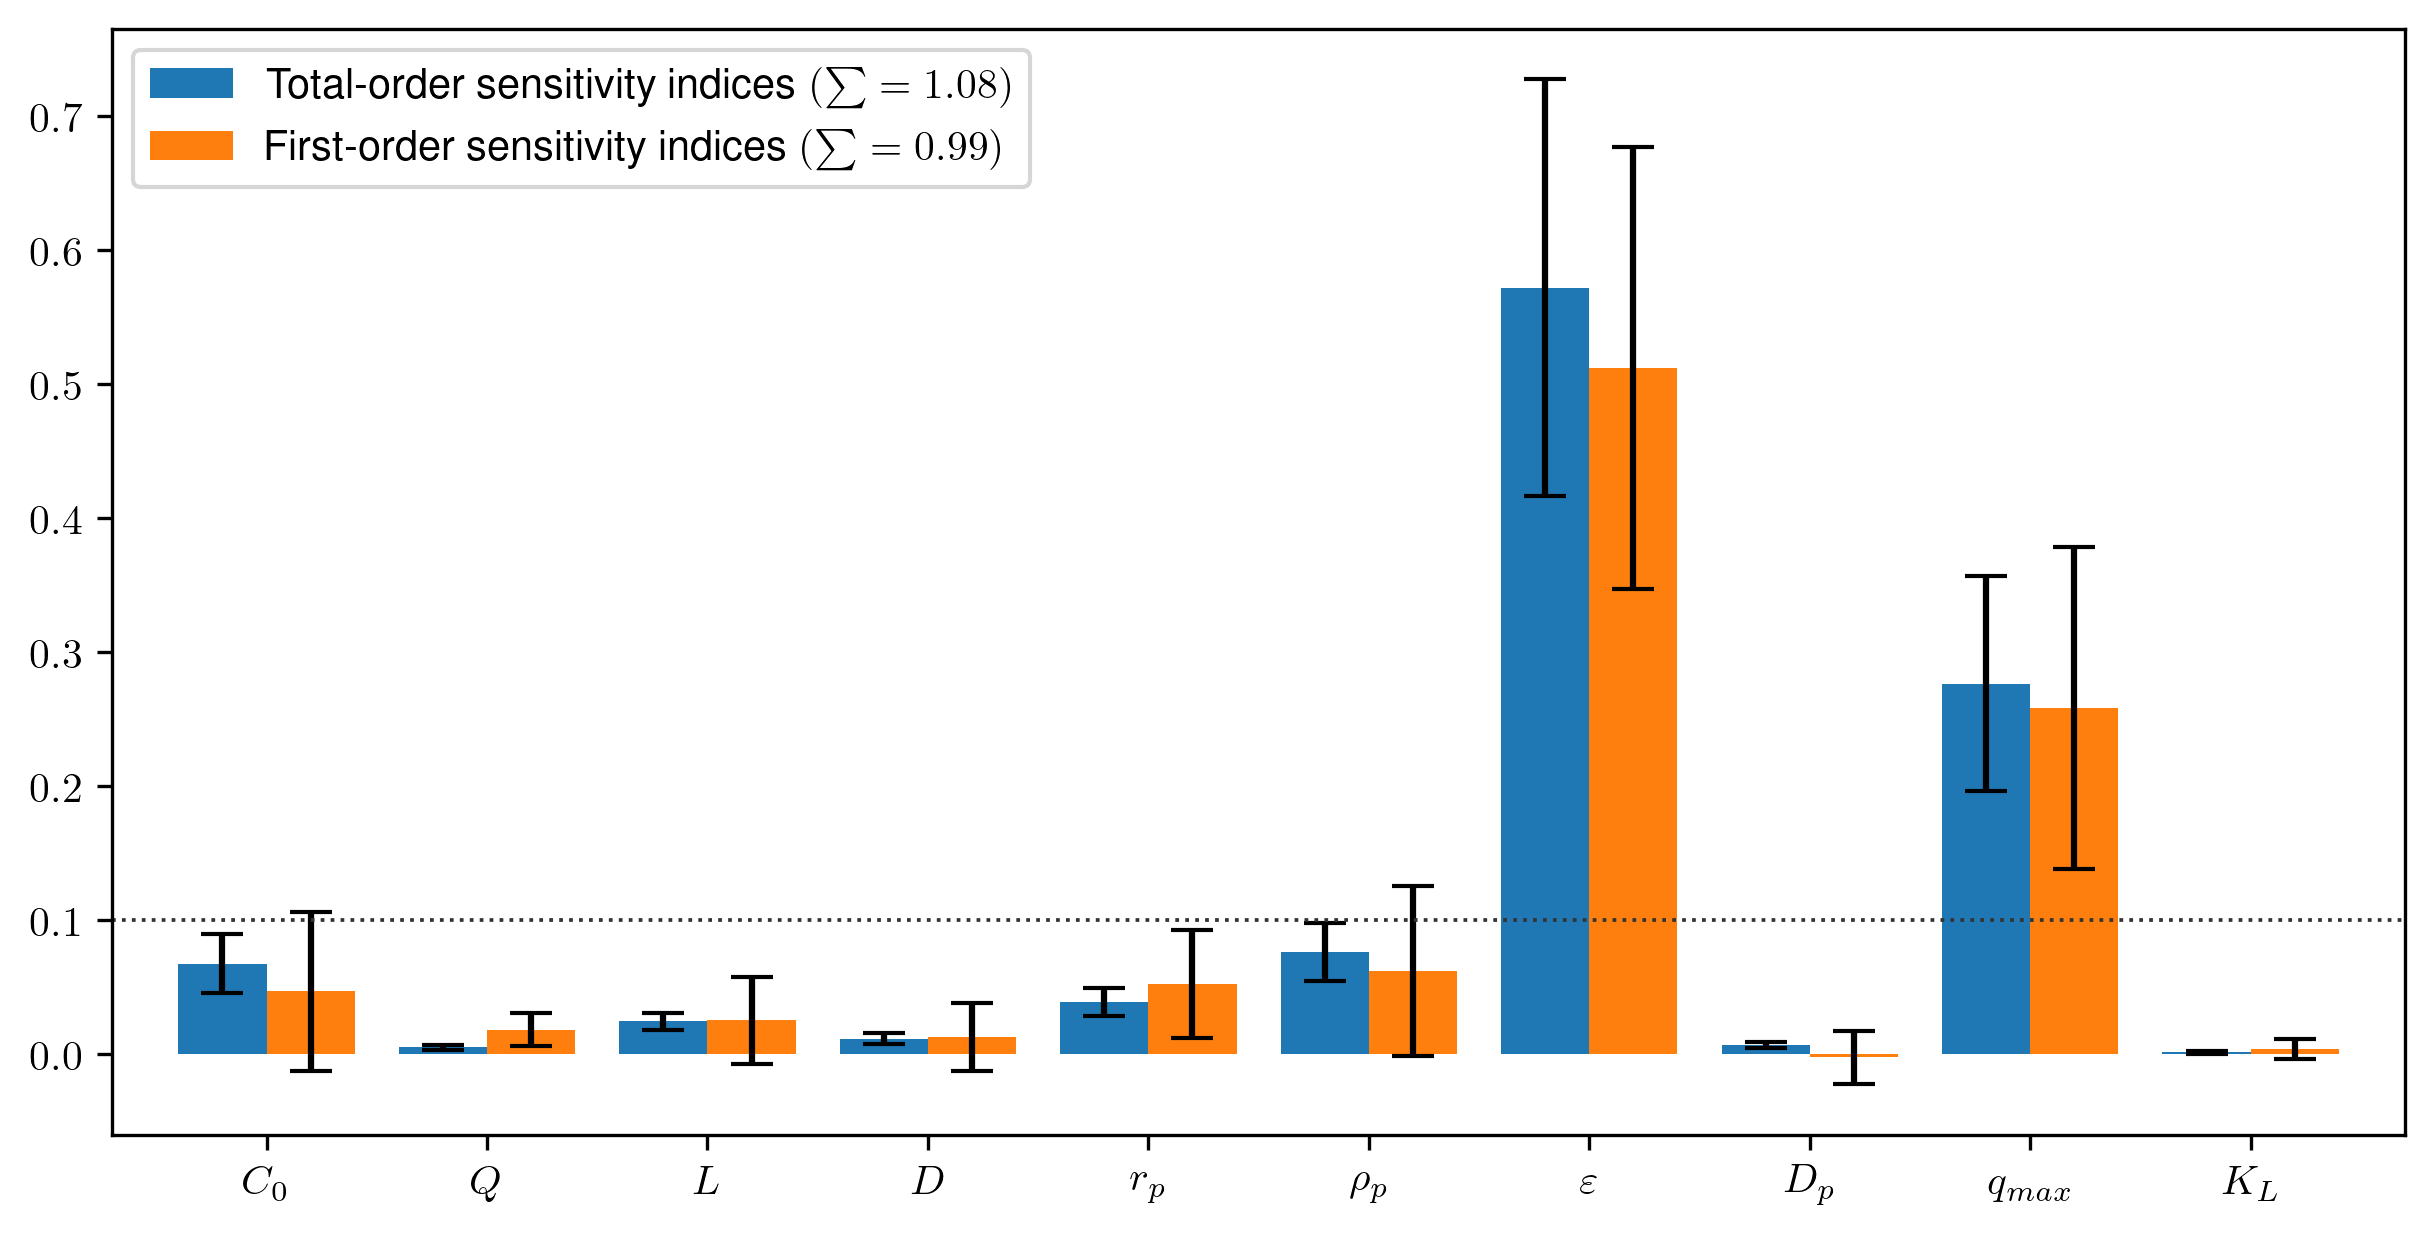

In [874]:
Si, total_Si, first_Si, second_Si = analyze(BT, BT, BT, sp_Np_10_N_7_20percent, calc_second_order=True)

# Store figure
plt.savefig("Figure_5_GSA.pdf", format="pdf", bbox_inches="tight")

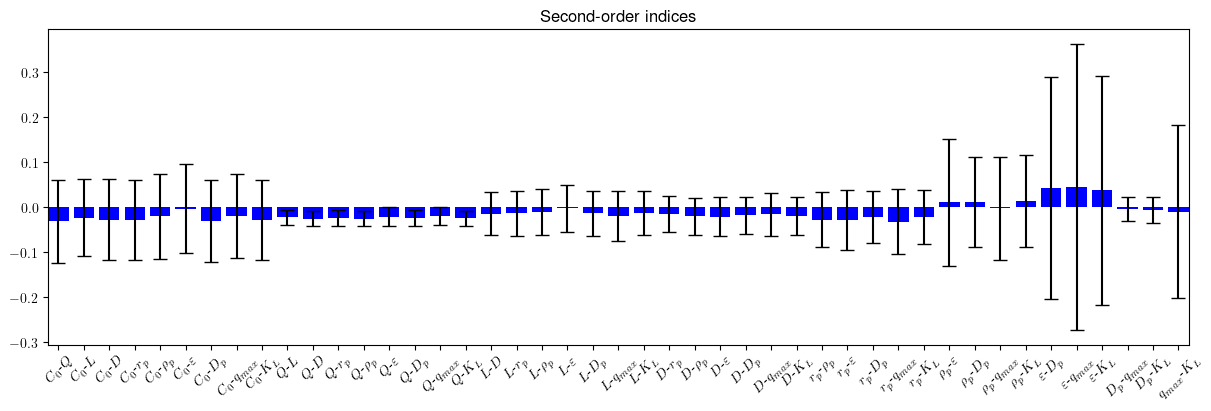

In [875]:
plot_second_order_indices(sp, Si)

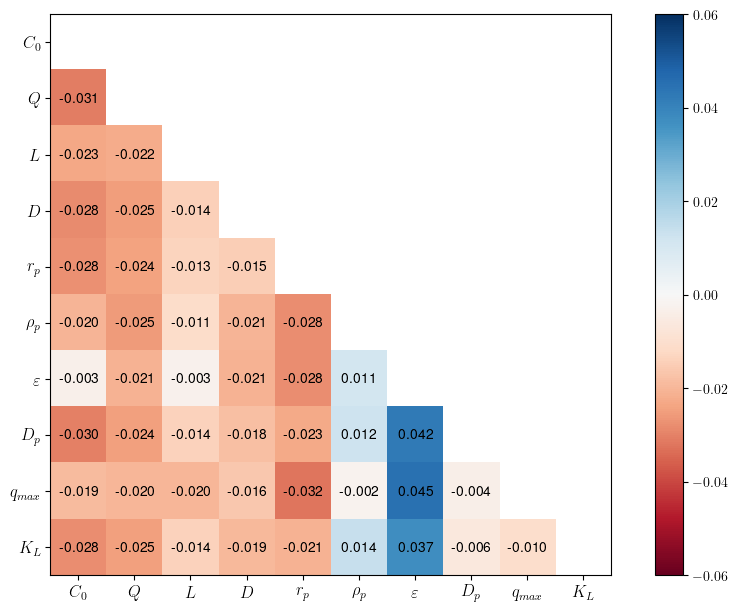

In [882]:
plot_heatmap(Si, sp, vmax=0.06)

# Store figure
plt.savefig("Figure_6_second_order.pdf", format="pdf", bbox_inches="tight")

                     ST   ST_conf
$C_0$          0.067368  0.023174
$Q$            0.004971  0.001893
$L$            0.024294  0.007544
$D$            0.011340  0.003430
$r_p$          0.038665  0.011188
$\rho_p$       0.075981  0.020335
$\varepsilon$  0.571831  0.154969
$D_p$          0.006448  0.002298
$q_{max}$      0.276446  0.088009
$K_L$          0.001216  0.001002
                     S1   S1_conf
$C_0$          0.046648  0.053849
$Q$            0.018130  0.014668
$L$            0.025133  0.034046
$D$            0.012546  0.028482
$r_p$          0.052059  0.038917
$\rho_p$       0.061926  0.054920
$\varepsilon$  0.512158  0.152743
$D_p$         -0.002665  0.020957
$q_{max}$      0.257908  0.128422
$K_L$          0.003501  0.008534
                                  S2   S2_conf
($C_0$, $Q$)               -0.030861  0.087552
($C_0$, $L$)               -0.023027  0.082453
($C_0$, $D$)               -0.028184  0.084977
($C_0$, $r_p$)             -0.027620  0.086494
($C_0$, $\rho_p$)

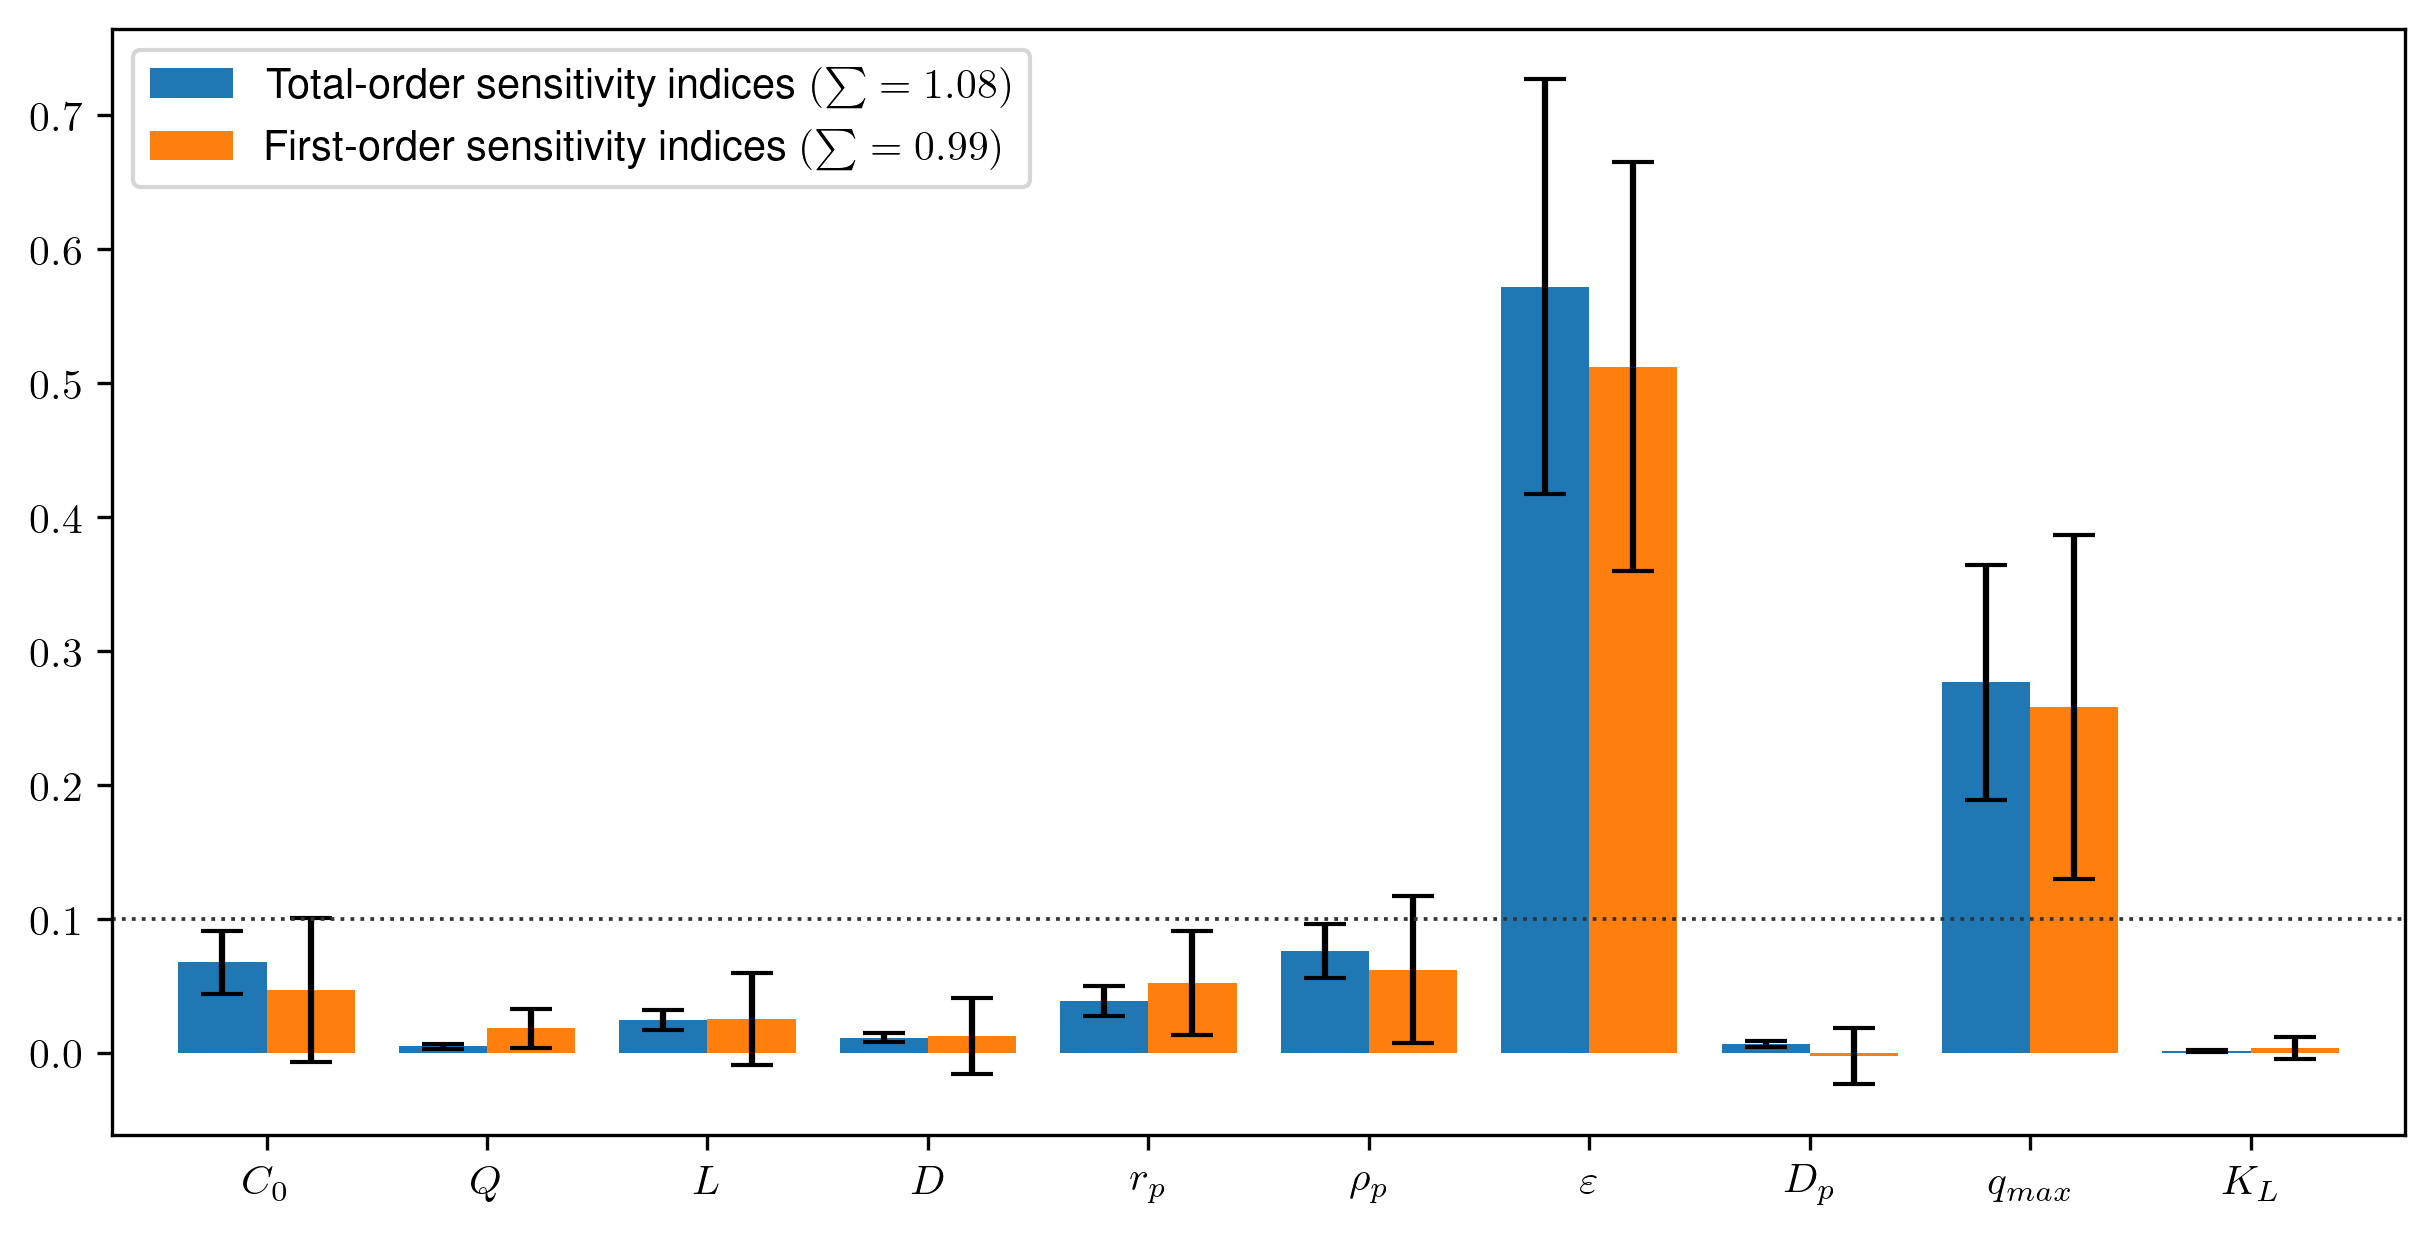

<Figure size 640x480 with 0 Axes>

In [ ]:
Si, total_Si, first_Si, second_Si = analyze(T_Np_10_N_7_20percent, Y_Np_10_N_7_20percent, BT_Np_10_N_7_20percent, sp_Np_10_N_7_20percent, calc_second_order=True)

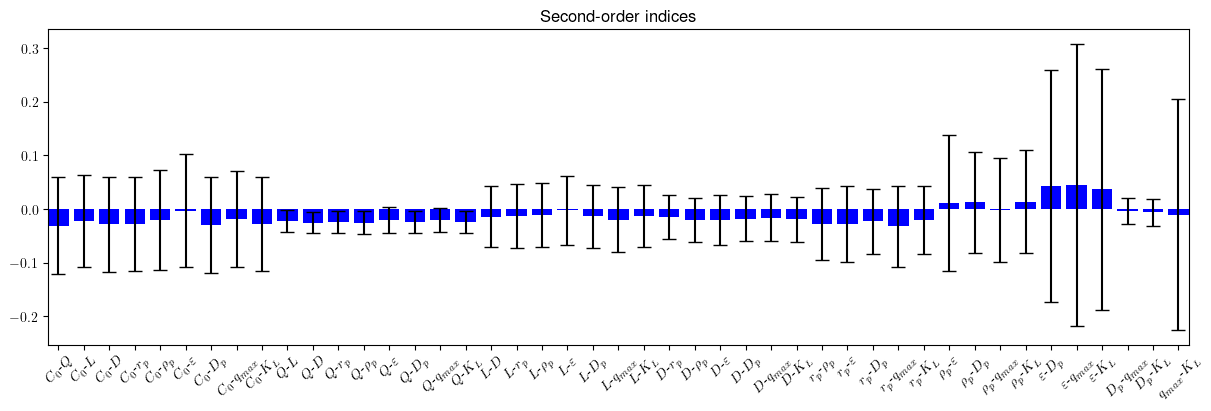

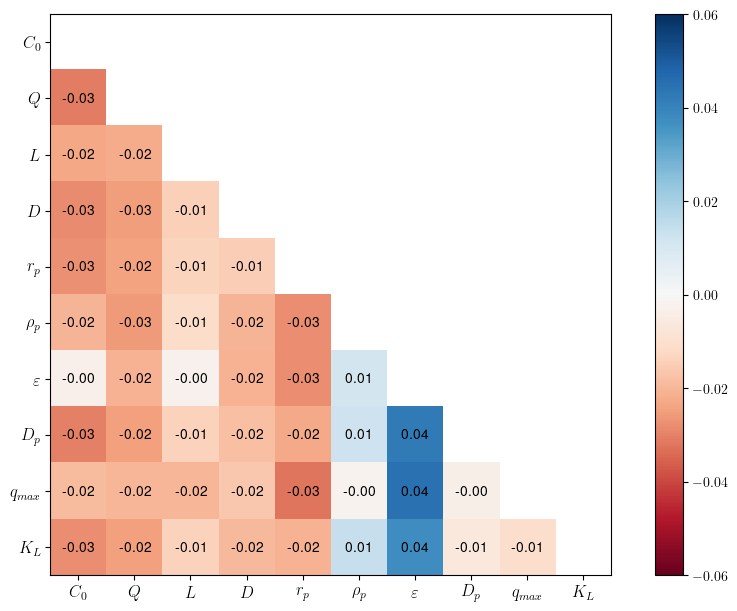

In [424]:
plot_second_order_indices(sp, Si)
plot_heatmap(Si, sp, vmax=0.06)

#### N = 8

In [478]:
N = 2**8

sp_Np_10_N_7_20percent = sampling(N=N,                          # no. of samples
              calc_second_order=True,       # calculate second order effects
              generate_new=True,            # generate new sampling
                                            # parameters = (name, value, uncertainty)
              C0    =('$C_0$',          672/31,              20), 
              Q     =('$Q$',            2.5e-6/60 * 0.37,    20), 
              L     =('$L$',            0.1,                 20), 
              D     =('$D$',            0.01,                20), 
              rp    =('$r_p$',          0.5 * 7.5e-4,        20), # 20% uncertainty
              rho_p =('$\\rho_p$',      389,                 20), 
              e     =('$\\varepsilon$', 0.37,                20), 
              Dp    =('$D_p$',          5.3e-10,             20), 
              qmax  =('$q_{max}$',      0.291,               20), 
              Kl    =('$K_L$',          1.18,                20)
              )

# Read file
Np = sp['num_vars']
pars = pd.read_csv(f"sampling_Np-{Np:d}_N-{N:d}.csv")
print(pars)

No. of parameters = 10
No. of samples = 5632
Generating new sampling...
      Unnamed: 0      $C_0$           $Q$       $L$       $D$     $r_p$  \
0              0  20.582740  1.651746e-08  0.118951  0.010953  0.000333   
1              1  19.014117  1.651746e-08  0.118951  0.010953  0.000333   
2              2  20.582740  1.613354e-08  0.118951  0.010953  0.000333   
3              3  20.582740  1.651746e-08  0.089733  0.010953  0.000333   
4              4  20.582740  1.651746e-08  0.118951  0.009935  0.000333   
...          ...        ...           ...       ...       ...       ...   
5627        5627  18.158228  1.634324e-08  0.082152  0.011888  0.000345   
5628        5628  18.158228  1.634324e-08  0.082152  0.011888  0.000345   
5629        5629  18.158228  1.634324e-08  0.082152  0.011888  0.000345   
5630        5630  18.158228  1.634324e-08  0.082152  0.011888  0.000345   
5631        5631  18.158228  1.634324e-08  0.082152  0.011888  0.000345   

        $\rho_p$  $\varepsi

## Calibration

### Objective function

#### Curve_fit

In [19]:
# Objective function for optimization with curve_fit

def SSE_curve_fit(texp, *values):

    # Counter for number of runs
    global counter, RMSE, names, Cexp
    counter += 1 # type: ignore
    
    # Update parameter values in dictionary and print to screen
    parameters = dict([(name, value) for name, value in zip(names, values)]) # type: ignore
    print(f'Run {counter}: {parameters}')
    
    # Run model with parameter values
    results, pars, container = model(Nx=100, dt=0.1, tmax=6, texp=texp, Cexp=Cexp, # type: ignore
                                    isotherm = 'Langmuir', profiles = False, breakthrough = False, progress=False,
                                    **parameters)
    
    # Interpolate model for experimental points
    # y_int = np.interp(texp, results['BV'], results['BC'])
    
    return results['Cint']

#### Least_squares

In [20]:
# Objective function for optimization with least_squares

def SSE(x, *values, **parameters):

    # Counter for number of runs
    global counter, RMSE
    counter += 1 # type: ignore

    # Calibration data
    texp = values[0]
    Cexp = values[1]
    
    # Update parameter values in dictionary and print to screen
    parameters = dict([(name, value) for name, value in zip(parameters.keys(), x)]) 
    print(f'Run {counter}: {parameters}')
    
    # Run model with parameter values
    results, pars, container = model(Nx=100, dt=0.1, tmax=6, texp=texp, Cexp=Cexp,
                                    isotherm = 'Langmuir', profiles = False, breakthrough = False, progress=False,
                                    **parameters)
    
    # Interpolate model for experimental points
    # y_int = np.interp(texp, results['BV'], results['BC'])
   
    return results['SSR']

### Calibration function

In [21]:
from scipy.optimize import least_squares, curve_fit

def calibration(expdata='exp1a', method='lm', algorithm='ls', tol=1e-4, **parameters):

	# Define parameter values and bounds
	global names, counter, data, Cexp # type: ignore

	# Experimental data used for calibration
	texp = data[expdata][0] # type: ignore
	Cexp = data[expdata][1] # type: ignore
	print("Experimental data for calibration:", expdata)

	names = [name for name in parameters.keys()]
	print("Parameters to calibrate:", names)
	# original_values = [value for value in parameters.values()]
	original_values = np.array([value for value in parameters.values()]) # must be an array
	print("Original values:", original_values)
	bounds = ([0.8 * value for value in parameters.values()], [1.2 * value for value in parameters.values()])

	# Run parameter estimation
	counter = 0

	if method == 'lm':
		print("Method: Levenberg-Marquardt")

		if algorithm == 'ls':
			print("Algorithm: Least-squares")
			calibration_results = least_squares(SSE, x0=original_values, method='lm', args=(texp, Cexp), kwargs=parameters,
											ftol=tol, xtol=tol, gtol=tol,  
											max_nfev=50, x_scale='jac', # type: ignore
											)
			
		elif algorithm == 'cf':
			print("Algorithm: Curve-fitting")
			param_calib, covariance, infodict, mesg, ier = curve_fit(SSE_curve_fit, xdata=texp, ydata=Cexp, p0=original_values, method='lm', 
										ftol=tol, xtol=tol, gtol=tol, full_output=True,
										# *original_values,
										# **parameters
										) 
		
	elif method == 'trf':
		print("Method: Trust Region Reflective")
		print("Bounds:", bounds)

		if algorithm == 'ls':
			print("Algorithm: Least-squares")
			calibration_results = least_squares(SSE, x0=original_values, method='trf', args=(texp, Cexp), kwargs=parameters,
											bounds=bounds, #x_scale='jac', # type: ignore
											ftol=tol, xtol=tol, gtol=tol,
											max_nfev=50, verbose=0
											)
		elif algorithm == 'cf':
			print("Algorithm: Curve-fitting")
			param_calib, covariance = curve_fit(SSE_curve_fit, xdata=texp, ydata=Cexp, p0=original_values, method='trf',
										ftol=tol, xtol=tol, gtol=tol, bounds=bounds, 
										# *original_values,
										# **parameters
										)
		
		else:
			raise ValueError("Choose 'ls' for least-squares or 'cf' for curve-fitting.")
		
	else:
		raise ValueError("Method not implemented. Choose 'lm' or 'trf'.")

	# Print results
	print("Calibration finished.")
	print("Number of runs:", counter)

	if algorithm == 'ls': param_calib = calibration_results.x
	calibrated_parameters = dict([(name, value) for name, value in zip(names, param_calib)])

	# Calculate SSR, RMSE, AIC, BIC
	print("Calculating SSR, RMSE, AIC, BIC...")
	Np = len(calibrated_parameters)
	results_calibrated, _, _= model(texp=texp, Cexp=Cexp, progress=False, Np=Np, **calibrated_parameters) # type: ignore
	# Np = results_calibrated['Np']
	N = results_calibrated['N']
	print(f"Np = {Np}, N = {N}")
	print(f"SSR = {results_calibrated['SSR']:0.4f}")
	print(f"RMSE = {results_calibrated['RMSE']:0.4f}")
	print(f"AIC (original) = {results_calibrated['AIC_orig']:.1f}")
	print(f"AIC (corrected) = {results_calibrated['AIC_corr']:.1f}")
	print(f"BIC = {results_calibrated['BIC']:.1f}")

	# Calculate FIM
	print("Calculating FIM...")
	S = forward_sensitivity(model, dt=0.1, relative=False, plot=False, progress=False, **calibrated_parameters)
	Sint = [np.interp(texp, S['t'], S[name]) for name in names]

	FIM = np.zeros((Np, Np))
	for i in range(Np):
		for j in range(Np):
			FIM[i,j] = np.sum(Sint[i]*Sint[j])

	results_calibrated['FIM'] = FIM

	SSR = results_calibrated['SSR']

	# Calculate covariance matrix
	covariance = np.linalg.inv(FIM) * SSR/(N-Np) # from the FIM
			
	if algorithm == 'ls':
		param_calib = calibration_results.x
		SSR = calibration_results.fun
		jacobian = calibration_results.jac
		covariance = SSR/(N-Np) * np.linalg.inv(np.transpose(jacobian) @ jacobian)  # from the Jacobian
		# covariance = np.linalg.inv(np.transpose(jacobian) @ jacobian) # from the Jacobian
		calibrated_parameters = dict([(name, value) for name, value in zip(names, param_calib)])

		print("Number of function evaluations:", calibration_results.nfev)
		print(calibration_results.message)
		print("Calibrated parameters:", calibrated_parameters)
		print("Jacobian = \n", jacobian)

	elif algorithm == 'cf':
		jacobian = 'Not available'
		if method == 'lm': print(mesg)

	results_calibrated['covariance'] = covariance
	results_calibrated['param_calib'] = calibrated_parameters

	print("FIM = \n", FIM)
	print("SSR = ", SSR)
	print("Calibrated parameters:", calibrated_parameters)
	print("Covariance matrix: \n", covariance)
	print("Condition number: {:.0f}".format(np.linalg.cond(covariance))) # 1 = well conditioned, 1e6 = ill conditioned
	print("Standard deviation: \n", np.sqrt(np.diag(covariance))) # standard deviation of the parameters

	# 95% confidence intervals
	from scipy import stats
	t_estimator = stats.t.ppf((1+0.95)/2, N-Np)
	print("Student's t estimator =", "{:.3f}".format(t_estimator))

	# Calculate confidence intervals
	CI = dict()
	d = dict()
	for name in names:
		i = names.index(name)
		CI[name] = t_estimator * np.sqrt(covariance[i,i])
		d[name] = CI[name]/calibrated_parameters[name]*100
		if calibrated_parameters[name] > 1e-3:
			print(f"CI {names[i]:s} : {calibrated_parameters[name]:.3f} ± {CI[name]:.4f} ({d[name]:.1f}%)")
		else:
			print(f"CI {names[i]:s} : {calibrated_parameters[name]:.3e} ± {CI[name]:.4e} ({d[name]:.1f}%)")
			
	results_calibrated['CI'] = CI
	results_calibrated['d'] = d

	# Calculate correlation coefficients
	r = np.zeros((Np, Np))
	if Np > 1:
		for i in range(Np-1):
			for j in range(i+1, Np):
				r[i,j] = covariance[i,j]/np.sqrt(covariance[i,i]*covariance[j,j])
				print(f"Correlation {names[i]:s}-{names[j]:s} = {r[i,j]:.4f}")
				
	results_calibrated['r'] = r

	return results_calibrated

	# param_uncalibrated, covariance_uncalibrated, results_uncalibrated = calibration(texp=texp1a, Cexp=Cexp1a, method='lm', e=0.37)

### Sequential calibration

Sequential calibration with two different set of parameters: fixed and to be calibrated

#### Calibration function

In [22]:
from scipy.optimize import least_squares, curve_fit

def sequential_calibration(expdata='exp1a', method='lm', algorithm='ls', tol=1e-4, **set_parameters):

	# Define parameter values and bounds
	global names, counter, fixed_params, data, Cexp

	print("Calibrating model with sequential approach...")

	# Experimental data used for calibration
	texp = data[expdata][0] # type: ignore
	Cexp = data[expdata][1] # type: ignore
	print("Experimental data for calibration:", expdata)

	# Separate fixed parameters from parameters to be calibrated
	fixed_params = set_parameters['fixed_parameters']
	parameters = set_parameters['calibrated_parameters']

	print("Fixed parameters:", [[name, value] for name, value in zip(fixed_params.keys(), fixed_params.values())])

	# Define names, original values and bounds
	names = [name for name in parameters.keys()]
	print("Parameters to calibrate:", names)
	# original_values = [value for value in parameters.values()]
	original_values = np.array([value for value in parameters.values()]) # must be an array
	print("Original values:", original_values)
	bounds = ([0.8 * value for value in parameters.values()], [1.2 * value for value in parameters.values()])

	# Run parameter estimation
	counter = 0

	if method == 'lm':
		print("Method: Levenberg-Marquardt")

		if algorithm == 'ls':
			print("Algorithm: Least-squares")
			calibration_results = least_squares(SSE_sequential, x0=original_values, method='lm', args=(texp, Cexp), kwargs=set_parameters, # type: ignore
											ftol=tol, xtol=tol, gtol=tol,  
											max_nfev=50, x_scale='jac', # type: ignore
											)
			
		elif algorithm == 'cf':
			print("Algorithm: Curve-fitting")
			param_calib, covariance, infodict, mesg, ier = curve_fit(SSE_curve_fit_sequential, xdata=texp, ydata=Cexp, p0=original_values, method='lm', # type: ignore
										ftol=tol, xtol=tol, gtol=tol, full_output=True,
										) 
		
	elif method == 'trf':
		print("Method: Trust Region Reflective")
		print("Bounds:", bounds)

		if algorithm == 'ls':
			print("Algorithm: Least-squares")
			calibration_results = least_squares(SSE_sequential, x0=original_values, method='trf', args=(texp, Cexp), kwargs=set_parameters, # type: ignore
											bounds=bounds, #x_scale='jac', # type: ignore
											ftol=tol, xtol=tol, gtol=tol,
											max_nfev=50, verbose=0
											)
		elif algorithm == 'cf':
			print("Algorithm: Curve-fitting")
			param_calib, covariance = curve_fit(SSE_curve_fit_sequential, xdata=texp, ydata=Cexp, p0=original_values, method='trf', # type: ignore
										ftol=tol, xtol=tol, gtol=tol, bounds=bounds, 
										)
		
		else:
			raise ValueError("Choose 'ls' for least-squares or 'cf' for curve-fitting.")
		
	else:
		raise ValueError("Method not implemented. Choose 'lm' or 'trf'.")

	# Print results
	print("Calibration finished.")
	print("Number of runs:", counter)

	if algorithm == 'ls': param_calib = calibration_results.x
	calibrated_parameters = dict([(name, value) for name, value in zip(names, param_calib)])

	# Include calibrated parameters in the set of parameters
	set_parameters['calibrated_parameters'] = calibrated_parameters

	# Calculate SSR, RMSE, AIC
	print("Calculating SSR, RMSE, AIC, BIC...")
	results_calibrated, _, _= model_calibration(texp=texp, progress=False, **set_parameters) # type: ignore
	Np = results_calibrated['Np']
	N = results_calibrated['N']
	print(f"Np = {Np}, N = {N}")
	print(f"SSR = {results_calibrated['SSR']:0.4f}")
	print(f"RMSE = {results_calibrated['RMSE']:0.4f}")
	print(f"AIC (original) = {results_calibrated['AIC_orig']:.1f}")
	print(f"AIC (corrected) = {results_calibrated['AIC_corr']:.1f}")
	print(f"BIC = {results_calibrated['BIC']:.1f}")

	# Calculate FIM
	print("Calculating FIM...")
	S = forward_sensitivity_calibration(model, dt=0.1, relative=False, plot=False, progress=False, **set_parameters) # type: ignore
	Sint = [np.interp(texp, S['t'], S[name]) for name in names]

	FIM = np.zeros((Np, Np))
	for i in range(Np):
		for j in range(Np):
			FIM[i,j] = np.sum(Sint[i]*Sint[j])

	SSR = results_calibrated['SSR']

	# Calculate covariance matrix
	covariance = np.linalg.inv(FIM) * SSR/(N-Np) # from the FIM
			
	if algorithm == 'ls':
		param_calib = calibration_results.x
		SSR = calibration_results.fun
		jacobian = calibration_results.jac
		covariance = SSR/(N-Np) * np.linalg.inv(np.transpose(jacobian) @ jacobian)  # from the Jacobian
		# covariance = np.linalg.inv(np.transpose(jacobian) @ jacobian) # from the Jacobian
		calibrated_parameters = dict([(name, value) for name, value in zip(names, param_calib)])

		print("Number of function evaluations:", calibration_results.nfev)
		print(calibration_results.message)
		print("Calibrated parameters:", calibrated_parameters)
		print("Jacobian = \n", jacobian)

	elif algorithm == 'cf':
		jacobian = 'Not available'
		if method == 'lm': print(mesg)

	print("FIM = \n", FIM)
	print("SSR = ", SSR)
	print("Calibrated parameters:", param_calib)
	print("Covariance matrix: \n", covariance)
	print("Condition number: {:.0f}".format(np.linalg.cond(covariance))) # 1 = well conditioned, 1e6 = ill conditioned
	print("Standard deviation: \n", np.sqrt(np.diag(covariance))) # standard deviation of the parameters

	# 95% confidence intervals
	from scipy import stats
	t_estimator = stats.t.ppf((1+0.95)/2, N-Np)
	print("Student's t estimator =", "{:.3f}".format(t_estimator))

	# Calculate confidence intervals
	for i in range(Np):
		CI = t_estimator * np.sqrt(covariance[i,i])
		d = CI/param_calib[i]*100
		if param_calib[i] > 1e-3:
			print(f"CI {names[i]:s} : {param_calib[i]:.3f} ± {CI:.4f} ({d:.1f}%)")
		else:
			print(f"CI {names[i]:s} : {param_calib[i]:.3e} ± {CI:.4e} ({d:.1f}%)")

	# Calculate correlation coefficients
	if Np > 1:
		for i in range(Np-1):
			for j in range(i+1, Np):
				print(f"Correlation {names[i]:s}-{names[j]:s} = {covariance[i,j]/np.sqrt(covariance[i,i]*covariance[j,j]):.4f}")

	return results_calibrated

	# param_uncalibrated, covariance_uncalibrated, results_uncalibrated = calibration(texp=texp1a, Cexp=Cexp1a, method='lm', e=0.37)

#### Model function

In [23]:
def model_calibration(#Nx=None, dx=None, Nt=None, dt=None, tmax=6.,        # simulation parameters 
        #   texp=texp1a, Cexp=Cexp1a,                           # experimental data for calibration
		expdata='exp1a',
          isotherm='Langmuir', dimensionless=True,            # model assumptions
          profiles=False, breakthrough=False, progress=True,  # output options
          **set_parameters                                        # model parameters
          ):

	# Separate fixed parameters from parameters to be calibrated
	fixed_params = set_parameters['fixed_parameters']
	calibrated_parameters = set_parameters['calibrated_parameters']

	# Create dictionary of both fixed and calibrated parameters
	parameters = {**fixed_params, **calibrated_parameters}
	params = define_parameters(**parameters)

    # Boundary conditions
	bc = boundary_conditions(C_left="dirichlet", C_right="dzC", q_left="dzq", q_right="dzq")

    # Define model equations
	model_equations, initial_fields = define_equations(params, bc, isotherm=isotherm, dimensionless=dimensionless)

    # Solve model
	container = solve_model(model_equations, initial_fields, params, progress=progress)

	t = container.data['t'].data * params['tau']      # type: ignore 	time [s]
	C = container.data['C'].data                      # type: ignore 	concentration profiles in the liquid [-]
	q = container.data['q'].data                      # type: ignore	concentration profiles in the resin [-]
	BC = container.data['C'].data[:, -1]              # type: ignore 	breakthrough curve [-]

	# Convert time to bed volumes: no. of columns/s / bed volume [-] 
	BV = t * (params['Q']/params['e'])/(params['V']*params['e']) 

	# Calibration data
	global data
	print("Validation data:", expdata)
	texp = data[expdata][0] # type: ignore
	Cexp = data[expdata][1] # type: ignore
	N = params['N']						# number of data points
	Np = len(calibrated_parameters) 	# number of parameters

	# interpolate model results at experimental time points from texp of calibration data
	params['Cint'] = Cint = np.interp(texp, BV, BC, left=1e-6, right=1.) 

	# Calculate SSR, RMSE, AIC and BIC for calibration
	params['RMSE_calibration'] = np.sqrt(np.square(Cexp - Cint).mean())
	params['SSR_calibration'] = SSR = np.sum((Cint - Cexp)**2)
	# Akaike Information Criterion (AIC)
	params['AIC_calibration_orig'] = N * np.log(SSR/N) + 2*Np 							# n*log(SSR/n) + 2k
	params['AIC_calibration_corr'] = N * np.log(SSR/N) + 2*Np + 2*Np*(Np+1)/(N-Np-1) 	# n*log(SSR/n) + 2k + 2k(k+1)/(n-k-1)
	# Bayesian Information Criterion (BIC)
	params['BIC_calibration'] = N * np.log(SSR/N) + Np*np.log(N) 	

	if progress:
		print(f"No. of parameters = {Np}")
		print(f"RMSE (validation) = {params['RMSE_calibration']:.4f}")    
		print(f"SSR (validation) = {params['SSR_calibration']:.4f}")
		print(f"AIC (validation, original) = {params['AIC_calibration_orig']:.1f}")
		print(f"AIC (validation, corrected) = {params['AIC_calibration_corr']:.1f}")
		print(f"BIC (validation) = {params['BIC_calibration']:.1f}")

	# Store results in a dictionary
	results = {'t' : t,                         # time [bed volumes]
				'z' : params['z'], 				# column domain [m]
				'C' : C,
				'q' : q,
				'BC': BC,
				'BV': BV,
				'texp': texp,
				'Cexp': Cexp,
				'N' : N,
				'Np' : Np,
				'Cint': params['Cint'],
				'RMSE': params['RMSE_calibration'],
				'SSR': params['SSR_calibration'],
				'AIC_orig': params['AIC_calibration_orig'],
				'AIC_corr': params['AIC_calibration_corr'],
				'BIC': params['BIC_calibration'],
				'params': params, # both fixed and calibrated (all parameters)
				'container': container,
				'parameters': calibrated_parameters, # calibrated parameters only
	}

	# Plot results
	if profiles: plot_profiles(results, params)

	if breakthrough: plot_breakthrough(results, params)

	# Return results
	return results, params, container

In [24]:
# Calibrate qmax and rp with C0=713 mg/L
fixed_parameters = dict(C0=672/31)
calibrated_parameters = dict(qmax=0.291, rp=3.75e-4)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'C0': 21.677419354838708}), ('calibrated_parameters', {'qmax': 0.291, 'rp': 0.000375})])


147371 running: t: 6: : 60it [00:02, 20.74it/s]                          


Validation data: exp1a
No. of parameters = 2
RMSE (validation) = 0.0864
SSR (validation) = 0.1491
AIC (validation, original) = -94.0
AIC (validation, corrected) = -93.3
BIC (validation) = -92.0


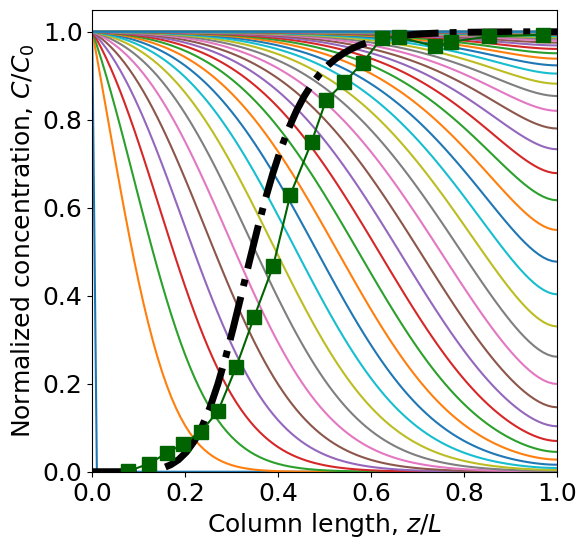

In [205]:
results, params, container = model_calibration(texp=texp1a, Cexp=Cexp1a, profiles=True, progress=True, isotherm='Langmuir', **parameters)

#### Objective functions

##### Least_squares

In [24]:
# Objective function for optimization with least_squares

def SSE_sequential(x, *values, **set_parameters):

	# Counter for number of runs
	global counter, RMSE
	counter += 1 # type: ignore

	# Calibration data
	texp = values[0]
	Cexp = values[1]

	# Update parameter values in dictionary and print to screen
	set_parameters['calibrated_parameters'] = dict([(name, value) for name, value in zip(set_parameters['calibrated_parameters'].keys(), x)]) 
	print(f"Run {counter}: {set_parameters['calibrated_parameters']}")

	# Run model with parameter values
	results, pars, container = model_calibration(texp=texp, Cexp=Cexp, Nx=100, dt=0.1, tmax=6,
									isotherm = 'Langmuir', profiles = False, breakthrough = False, progress=False,
									**set_parameters)

	# Interpolate model for experimental points
	# y_int = np.interp(texp, results['BV'], results['BC'])

	return results['SSR']

##### Curve_fit

In [25]:
# Objective function for optimization with curve_fit

def SSE_curve_fit_sequential(texp, *values):

    # Counter for number of runs
    global counter, RMSE, names, fixed_params, Cexp
    counter += 1 # type: ignore
    
	# Include fixed parameters
    parameters = {'fixed_parameters': fixed_params, 'calibrated_parameters': dict([(name, value) for name, value in zip(names, values)])} # type: ignore
    
    # Update parameter values in dictionary and print to screen
    # parameters = dict([(name, value) for name, value in zip(names, values)])
    print(f'Run {counter}: {parameters}')
    
    # Run model with parameter values
    results, pars, container = model_calibration(Nx=100, dt=0.1, tmax=6, texp=texp, Cexp=Cexp, # type: ignore
                                    isotherm = 'Langmuir', profiles = False, breakthrough = False, progress=False,
                                    **parameters)
    
    # Interpolate model for experimental points
    # y_int = np.interp(texp, results['BV'], results['BC'])
    
    return results['Cint']

#### Sensitivity function (FIM)

In [26]:
def forward_sensitivity_calibration(model, xi=1e-5, dt=0.1, relative=True, labels=None, plot=False, progress=True, **set_parameters):
	"""
	Function to calculate sensitivities.
	"""
	sensitivities = {}

	# Separate fixed parameters from parameters to be calibrated
	fixed_params = set_parameters['fixed_parameters']
	parameters = set_parameters['calibrated_parameters']

	# 1) First just run the model with original parameter values
	Np = len(parameters)
	print(f"Run 1 of {Np+1:d} : {set_parameters}")
	# print(parameters.items())
	results1, params1, container1 = model_calibration(dt=dt, profiles=False, breakthrough=False, progress=progress, **set_parameters) 

	# Store the time vector
	sensitivities['t'] = results1['BV']
	C1 = results1['BC']

	# Read keyword arguments: parameter-value pairs
	run = 1
	for parameter, value in parameters.items():
		run += 1

		# 2) Now run the model with the adapted parameter value for each parameter
		parameters[parameter] = value*(1 + xi)
		print(f"Run {run:d} of {Np+1:d} : {set_parameters}")

		results2, params2, container2 = model_calibration(dt=dt, profiles=False, breakthrough=False, progress=progress, **set_parameters)
		C2 = results2['BC']

		# Calculate the local relative sensitivity function (wrt. the parameter value)
		if relative: 
			sensitivities[parameter] = (C2 - C1)/xi; 
			print("Average sensitivity (relative):", sensitivities[parameter].mean()*np.abs(sensitivities[parameter]).mean())
		else: 
			sensitivities[parameter] = (C2 - C1)/(xi*value)
			print("Average sensitivity (absolute):", sensitivities[parameter].mean()*np.abs(sensitivities[parameter]).mean())
		
		# Restore original value
		parameters[parameter] = value
		
	# Plot the sensitivity function
	if plot:
		plot_sensitivity(sensitivities, labels=labels, **parameters) # type: ignore

	# Store sensitivity values # TODO
	# N = len(parameters)
	# todisk = pd.DataFrame.from_dict(sensitivities)
	# todisk.to_csv(f"local_N-{N:d}_dt-{dt:f}.csv")

	return sensitivities


### Uncalibrated model

958b84 running: t: 6: : 60it [00:02, 21.41it/s]                          


No. of parameters = 0
RMSE (calibration) = 0.0864
SSR (calibration) = 0.1491
AIC (calibration, original) = -98.0
AIC (calibration, corrected) = -98.0
BIC (calibration) = -98.0


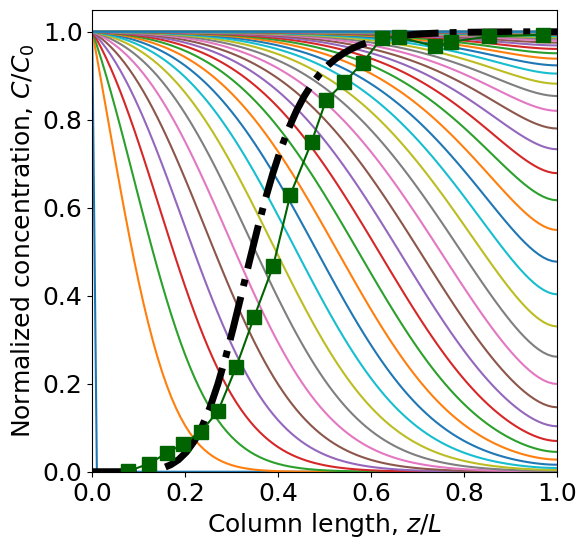

In [29]:
results, params, container = model(Nx=100, dt=0.1, tmax=6., isotherm='Langmuir', dimensionless=True, profiles=True, breakthrough=False)

### Np = 1

#### epsilon (*)

In [196]:
results_e_lm_ls = calibration(method='lm', algorithm='ls', tol=1e-4, e=0.37)

Parameters to calibrate: ['e']
Original values: [0.37]
Method: Levenberg-Marquardt
Algorithm: Least-squares
Run 1: {'e': 0.37}
Run 2: {'e': 0.37}
Run 3: {'e': 0.37}
Run 4: {'e': 0.37000000551342965}
Run 5: {'e': 0.3563284979860401}
Run 6: {'e': 0.3563285032957485}
Run 7: {'e': 0.3492636439217496}
Run 8: {'e': 0.34926364912618346}
Run 9: {'e': 0.3406182735143391}
Run 10: {'e': 0.34572178460115827}
Run 11: {'e': 0.3457217897528143}
Run 12: {'e': 0.3492636439217496}
Run 13: {'e': 0.34666855357799675}
Run 14: {'e': 0.34666855874376074}
Run 15: {'e': 0.34761405187821054}
Run 16: {'e': 0.3467632177535472}
Run 17: {'e': 0.34666855357799675}
Run 18: {'e': 0.3466624981235444}
Run 19: {'e': 0.3466746090324491}
Calibration finished.
Number of runs: 19
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -146.3
Calculating FIM...
Run 1 of 2 : {'e': 0.34666855357799675}
Run 2 of 2 : {'e': 0.34667202026353255}
Number of function evaluations: 14
`xtol` termination condition is satisfied.
Ca

In [290]:
results_e_lm_cf = calibration(method='lm', algorithm='cf', tol=1e-4, e=0.37)

Parameters to calibrate: ['e']
Original values: [0.37]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'e': 0.37}
Run 2: {'e': 0.37}
Run 3: {'e': 0.37}
Run 4: {'e': 0.37000000551342965}
Run 5: {'e': 0.3466396736910033}
Run 6: {'e': 0.34663967885633695}
Run 7: {'e': 0.34673349880694637}
Run 8: {'e': 0.34673350397367814}
Run 9: {'e': 0.34673552254820755}
Calibration finished.
Number of runs: 9
Calculating SSR, RMSE, AIC, BIC...
Np = 1, N = 20
SSR = 0.0109
RMSE = 0.0233
AIC (original) = -148.3
AIC (corrected) = -148.1
BIC = -147.3
Calculating FIM...
Run 1 of 2 : {'e': 0.34673552254820755}
Run 2 of 2 : {'e': 0.34673898990343305}
Both actual and predicted relative reductions in the sum of squares
  are at most 0.000100 and the relative error between two consecutive iterates is at 
  most 0.000100
FIM = 
 [[67.92317198]]
SSR =  0.010875626450749682
Calibrated parameters: {'e': 0.34673552254820755}
Covariance matrix: 
 [[8.42718877e-06]]
Condition number: 1
Standard deviation: 
 

In [48]:
results_e_trf_ls = calibration(method='trf', algorithm='ls', tol=1e-4, e=0.37)

Parameters to calibrate: ['e']
Original values: [0.37]
Method: Trust Region Reflective
Bounds: ([0.296], [0.444])
Algorithm: Least-squares
Run 1: {'e': 0.37}
Run 2: {'e': 0.3700000149011612}
Run 3: {'e': 0.3584522854959283}
Run 4: {'e': 0.3584523003970895}
Run 5: {'e': 0.35141513725023493}
Run 6: {'e': 0.3514151521513961}
Run 7: {'e': 0.34567917099766304}
Run 8: {'e': 0.34567918589882424}
Run 9: {'e': 0.36113979763568504}
Run 10: {'e': 0.34954432765716853}
Run 11: {'e': 0.34664546016253944}
Run 12: {'e': 0.34664547506370064}
Calibration finished.
Number of runs: 12
Calculating SSR, RMSE, AIC, BIC...
Np = 1, N = 20
SSR = 0.0109
RMSE = 0.0233
AIC (original) = -148.3
AIC (corrected) = -148.1
BIC = -147.3
Calculating FIM...
Run 1 of 2 : {'e': 0.34664546016253944}
Run 2 of 2 : {'e': 0.3466489266171411}
Number of function evaluations: 7
`gtol` termination condition is satisfied.
Calibrated parameters: {'e': 0.34664546016253944}
Jacobian = 
 [[-0.05424141]]
FIM = 
 [[67.9978383]]
SSR =  [0.01

In [49]:
results_e_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, e=0.37)

Parameters to calibrate: ['e']
Original values: [0.37]
Method: Trust Region Reflective
Bounds: ([0.296], [0.444])
Algorithm: Curve-fitting
Run 1: {'e': 0.37}
Run 2: {'e': 0.3700000149011612}
Run 3: {'e': 0.35224467533647325}
Run 4: {'e': 0.35224469023763444}
Run 5: {'e': 0.347283216513187}
Run 6: {'e': 0.3472832314143482}
Run 7: {'e': 0.34675240174288535}
Run 8: {'e': 0.34675241664404655}
Run 9: {'e': 0.3467359326499522}
Run 10: {'e': 0.3467359475511134}
Calibration finished.
Number of runs: 10
Calculating SSR, RMSE, AIC, BIC...
Np = 1, N = 20
SSR = 0.0109
RMSE = 0.0233
AIC (original) = -148.3
AIC (corrected) = -148.1
BIC = -147.3
Calculating FIM...
Run 1 of 2 : {'e': 0.3467359326499522}
Run 2 of 2 : {'e': 0.3467394000092788}
FIM = 
 [[67.92283236]]
SSR =  0.0108756264904207
Calibrated parameters: {'e': 0.3467359326499522}
Covariance matrix: 
 [[8.42723094e-06]]
Condition number: 1
Standard deviation: 
 [0.00290297]
Student's t estimator = 2.093
CI e : 0.347 ± 0.0061 (1.8%)


eedf13 running: t: 6: : 120it [00:07, 16.60it/s]                            


No. of parameters = 1
RMSE (calibration) = 0.0234
SSR (calibration) = 0.0109
AIC (calibration, original) = -148.2
AIC (calibration, corrected) = -148.0
BIC (calibration) = -147.2


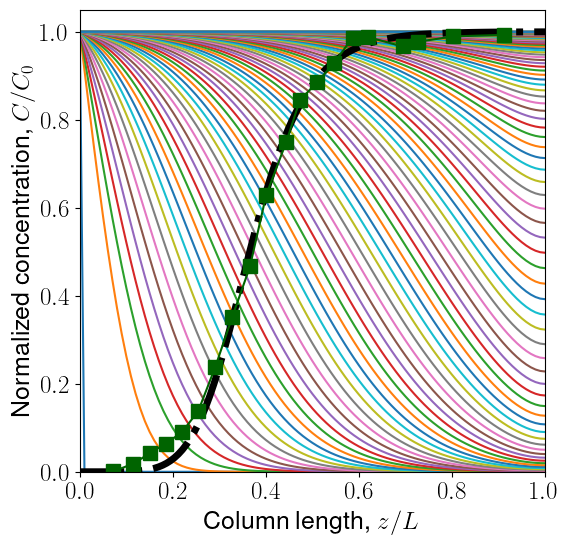

In [292]:
e_calibrated = results_e_lm_cf['params']['e']
results_e_calibrated, _, _ = model(Nx=100, dt=0.05, tmax=6., isotherm='Langmuir', profiles=True, e=e_calibrated, Np=1)

#### qmax (*)

In [208]:
# covariance matrix is too large
qmax_lm_ls = calibration(method='lm', algorithm='ls', tol=1e-4, qmax=0.291)

Parameters to calibrate: ['qmax']
Original values: [0.291]
Method: Levenberg-Marquardt
Algorithm: Least-squares
Run 1: {'qmax': 0.291}
Run 2: {'qmax': 0.291}
Run 3: {'qmax': 0.291}
Run 4: {'qmax': 0.2910000043362379}
Run 5: {'qmax': 0.3094780715995012}
Run 6: {'qmax': 0.3094780762110838}
Run 7: {'qmax': 0.32006453139072416}
Run 8: {'qmax': 0.3200645361600573}
Run 9: {'qmax': 0.3375785050874628}
Run 10: {'qmax': 0.3221818233489688}
Run 11: {'qmax': 0.3221818281498521}
Run 12: {'qmax': 0.3242199361961255}
Run 13: {'qmax': 0.3230807664415946}
Run 14: {'qmax': 0.3230807712558732}
Run 15: {'qmax': 0.3221670517946986}
Run 16: {'qmax': 0.32298936756821806}
Run 17: {'qmax': 0.3230807664415946}
Run 18: {'qmax': 0.32307471098714224}
Run 19: {'qmax': 0.323086821896047}
Calibration finished.
Number of runs: 19
Calculating SSR, RMSE, AIC...
SSR = 0.0136
RMSE = 0.0261
AIC (original) = -141.9
AIC (corrected) = -141.2
Calculating FIM...
Run 1 of 2 : {'qmax': 0.3230807664415946}
Run 2 of 2 : {'qmax': 0

In [50]:
qmax_lm_cf = calibration(method='lm', algorithm='cf', tol=1e-4, qmax=0.291)

Parameters to calibrate: ['qmax']
Original values: [0.291]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'qmax': 0.291}
Run 2: {'qmax': 0.291}
Run 3: {'qmax': 0.291}
Run 4: {'qmax': 0.2910000043362379}
Run 5: {'qmax': 0.3212004514762354}
Run 6: {'qmax': 0.3212004562624951}
Run 7: {'qmax': 0.32295437551536665}
Run 8: {'qmax': 0.32295438032776186}
Run 9: {'qmax': 0.3230569760339615}
Run 10: {'qmax': 0.3230569808478856}
Run 11: {'qmax': 0.32306305900406296}
Calibration finished.
Number of runs: 11
Calculating SSR, RMSE, AIC, BIC...
Np = 1, N = 20
SSR = 0.0136
RMSE = 0.0261
AIC (original) = -143.9
AIC (corrected) = -143.6
BIC = -142.9
Calculating FIM...
Run 1 of 2 : {'qmax': 0.32306305900406296}
Run 2 of 2 : {'qmax': 0.323066289634653}
Both actual and predicted relative reductions in the sum of squares
  are at most 0.000100 and the relative error between two consecutive iterates is at 
  most 0.000100
FIM = 
 [[152.11632661]]
SSR =  0.013598298856516242
Calibrated parameter

In [357]:
qmax_trf_ls = calibration(method='trf', algorithm='ls', tol=1e-4, qmax=0.291)

Parameters to calibrate: ['qmax']
Original values: [0.291]
Method: Trust Region Reflective
Bounds: ([0.2328], [0.34919999999999995])
Algorithm: Least-squares
Run 1: {'qmax': 0.291}
Run 2: {'qmax': 0.2910000149011612}
Run 3: {'qmax': 0.3050251805641523}
Run 4: {'qmax': 0.3050251954653135}
Run 5: {'qmax': 0.31449465912491653}
Run 6: {'qmax': 0.3144946740260777}
Run 7: {'qmax': 0.32228569226375964}
Run 8: {'qmax': 0.32228570716492083}
Calibration finished.
Number of runs: 8
Calculating FIM...
Run 1 of 2 : {'qmax': 0.32228569226375964}
Run 2 of 2 : {'qmax': 0.3222889151206823}
FIM = 
 [[15.75259029]]
Calculating SSR, RMSE, AIC...
SSR = 
 0.013684701201373183
Number of function evaluations: 4
`gtol` termination condition is satisfied.
Calibrated parameters: {'qmax': 0.32228569226375964}
Jacobian = 
 [[-0.22198684]]
Calibrated parameters: [0.32228569]
Covariance matrix: 
 [[0.01461596]]
Condition number: 1
Standard deviation: 
 [0.12089647]
Student's t estimator = 2.093
CI qmax : 0.322 ± 0.2

In [51]:
qmax_trf_cf= calibration(method='trf', algorithm='cf', tol=1e-4, qmax=0.291)

Parameters to calibrate: ['qmax']
Original values: [0.291]
Method: Trust Region Reflective
Bounds: ([0.2328], [0.34919999999999995])
Algorithm: Curve-fitting
Run 1: {'qmax': 0.291}
Run 2: {'qmax': 0.2910000149011612}
Run 3: {'qmax': 0.310883000950662}
Run 4: {'qmax': 0.3108830158518232}
Run 5: {'qmax': 0.3197282123121969}
Run 6: {'qmax': 0.3197282272133581}
Run 7: {'qmax': 0.3225673660996185}
Run 8: {'qmax': 0.3225673810007797}
Run 9: {'qmax': 0.3230260798331228}
Run 10: {'qmax': 0.323026094734284}
Run 11: {'qmax': 0.3230611794850362}
Run 12: {'qmax': 0.3230611943861974}
Calibration finished.
Number of runs: 12
Calculating SSR, RMSE, AIC, BIC...
Np = 1, N = 20
SSR = 0.0136
RMSE = 0.0261
AIC (original) = -143.9
AIC (corrected) = -143.6
BIC = -142.9
Calculating FIM...
Run 1 of 2 : {'qmax': 0.3230611794850362}
Run 2 of 2 : {'qmax': 0.32306441009683107}
FIM = 
 [[152.1152219]]
SSR =  0.013598299568175744
Calibrated parameters: {'qmax': 0.3230611794850362}
Covariance matrix: 
 [[4.70498592e

#### rho

In [53]:
rho_lm_ls = calibration(method='lm', algorithm='ls', tol=1e-4, rho_p=389)

Parameters to calibrate: ['rho_p']
Original values: [389]
Method: Levenberg-Marquardt
Algorithm: Least-squares
Run 1: {'rho_p': 389.0}
Run 2: {'rho_p': 389.0}
Run 3: {'rho_p': 389.0}
Run 4: {'rho_p': 389.0000057965517}
Run 5: {'rho_p': 438.4019380638499}
Run 6: {'rho_p': 438.4019445965479}
Run 7: {'rho_p': 468.8761376096617}
Run 8: {'rho_p': 468.8761445964606}
Run 9: {'rho_p': 513.5876707433846}
Run 10: {'rho_p': 480.16642758676676}
Run 11: {'rho_p': 480.1664347418041}
Run 12: {'rho_p': 469.09121016710645}
Run 13: {'rho_p': 479.0395868307318}
Run 14: {'rho_p': 479.0395939689779}
Run 15: {'rho_p': 479.6037922932863}
Run 16: {'rho_p': 479.60379943993973}
Run 17: {'rho_p': 479.03939806314884}
Run 18: {'rho_p': 479.4457596715731}
Run 19: {'rho_p': 479.44576681587165}
Run 20: {'rho_p': 479.60380172110064}
Run 21: {'rho_p': 479.4457596715731}
Run 22: {'rho_p': 479.44285640961306}
Run 23: {'rho_p': 479.44866293353317}
Calibration finished.
Number of runs: 23
Calculating SSR, RMSE, AIC, BIC...

In [52]:
rho_lm_cf = calibration(method='lm', algorithm='cf', tol=1e-4, rho_p=389)

Parameters to calibrate: ['rho_p']
Original values: [389]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'rho_p': 389}
Run 2: {'rho_p': 389.0}
Run 3: {'rho_p': 389.0}
Run 4: {'rho_p': 389.0000057965517}
Run 5: {'rho_p': 469.74232536944663}
Run 6: {'rho_p': 469.74233236915273}
Run 7: {'rho_p': 478.83617197749203}
Run 8: {'rho_p': 478.836179112707}
Run 9: {'rho_p': 479.4094693541372}
Run 10: {'rho_p': 479.40947649789496}
Run 11: {'rho_p': 479.4436135036978}
Calibration finished.
Number of runs: 11
Calculating SSR, RMSE, AIC, BIC...
Np = 1, N = 20
SSR = 0.0136
RMSE = 0.0261
AIC (original) = -143.9
AIC (corrected) = -143.6
BIC = -142.9
Calculating FIM...
Run 1 of 2 : {'rho_p': 479.4436135036978}
Run 2 of 2 : {'rho_p': 479.44840793983286}
Both actual and predicted relative reductions in the sum of squares
  are at most 0.000100
FIM = 
 [[1.72666613e-05]]
SSR =  0.013598184941052487
Calibrated parameters: {'rho_p': 479.4436135036978}
Covariance matrix: 
 [[41.44946907]]
Conditi

In [220]:
rho_trf_ls = calibration(method='trf', algorithm='ls', tol=1e-4, rho_p=389)

Parameters to calibrate: ['rho_p']
Original values: [389]
Method: Trust Region Reflective
Bounds: ([311.20000000000005], [466.79999999999995])
Algorithm: Least-squares
Run 1: {'rho_p': 389.0}
Run 2: {'rho_p': 389.0000057965517}
Run 3: {'rho_p': 419.2155048882442}
Run 4: {'rho_p': 419.215511135042}
Run 5: {'rho_p': 439.9492420523457}
Run 6: {'rho_p': 439.9492486081003}
Run 7: {'rho_p': 454.1417790450235}
Run 8: {'rho_p': 454.1417858122634}
Run 9: {'rho_p': 462.9531500136841}
Run 10: {'rho_p': 462.9531569122236}
Calibration finished.
Number of runs: 10
Calculating SSR, RMSE, AIC, BIC...
SSR = 0.0180
RMSE = 0.0300
AIC (original) = -136.2
AIC (corrected) = -135.5
BIC = -134.2
Calculating FIM...
Run 1 of 2 : {'rho_p': 462.9531500136841}
Run 2 of 2 : {'rho_p': 462.9577795451842}
Number of function evaluations: 5
`gtol` termination condition is satisfied.
Calibrated parameters: {'rho_p': 462.9531500136841}
Jacobian = 
 [[-0.0005393]]
FIM = 
 [[1.74956118e-05]]
SSR =  [0.01803592]
Calibrated p

In [332]:
rho_trf, results_rho_trf = calibration(method='trf', algorithm='cf', tol=1e-4, rho_p=389)

Parameters to calibrate: ['rho_p']
Original values: [389]
Method: Trust Region Reflective
Bounds: ([311.20000000000005], [466.79999999999995])
Algorithm: Curve-fitting
Run 1: {'rho_p': 389.0}
Run 2: {'rho_p': 389.0000057965517}
Run 3: {'rho_p': 428.62192997420743}
Run 4: {'rho_p': 428.6219363611719}
Run 5: {'rho_p': 449.6185062655399}
Run 6: {'rho_p': 449.61851296537776}
Run 7: {'rho_p': 460.2225824357523}
Run 8: {'rho_p': 460.2225892936032}
Run 9: {'rho_p': 465.0356084165052}
Run 10: {'rho_p': 465.0356153460758}
Run 11: {'rho_p': 466.5957675272173}
Run 12: {'rho_p': 466.595774480036}
Calibration finished.
Number of runs: 12
Calculating FIM...
Run 1 of 2 : {'rho_p': 389}
Run 2 of 2 : {'rho_p': 389.00389}
FIM = 
 [[2.82892236]]
Calculating SSR, RMSE, AIC...
SSR = 
 0.0162895648438529
Calibrated parameters: [466.59576753]
Covariance matrix: 
 [[0.00030306]]
Condition number: 1
Standard deviation: 
 [0.01740874]
Student's t estimator = 2.093
CI = 466.596 ± 0.0364 (0.0%)
SSR = 0.0163
RMSE 

#### rp

In [217]:
# fails
rp_lm_ls = calibration(method='lm', algorithm='ls', tol=1e-14, rp=3.75e-4)

Parameters to calibrate: ['rp']
Original values: [0.000375]
Method: Levenberg-Marquardt
Algorithm: Least-squares
Run 1: {'rp': 0.000375}
Run 2: {'rp': 0.000375}
Run 3: {'rp': 0.000375}
Run 4: {'rp': 0.00037500000558793545}
Run 5: {'rp': -0.0007423740326576094}


/var/folders/vb/76n31gjx2xqb2799fdrgk9dc0000gn/T/ipykernel_3067/1518538600.py:66: RuntimeWarning: invalid value encountered in double_scalars
  Dz  = mu / rho_f * phi * Re / (0.20 + 0.011 * Re**0.48)


RuntimeError: Factor is exactly singular

In [54]:
rp_lm_cf = calibration(method='lm', algorithm='cf', tol=1e-4, rp=3.75e-4)

Parameters to calibrate: ['rp']
Original values: [0.000375]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'rp': 0.000375}
Run 2: {'rp': 0.000375}
Run 3: {'rp': 0.000375}
Run 4: {'rp': 0.00037500000558793545}
Run 5: {'rp': 0.00034465542304517335}
Run 6: {'rp': 0.00034465542818093935}
Run 7: {'rp': 0.0003414289128459586}
Run 8: {'rp': 0.0003414289179336459}
Run 9: {'rp': 0.00034101161745727515}
Calibration finished.
Number of runs: 9
Calculating SSR, RMSE, AIC, BIC...
Np = 1, N = 20
SSR = 0.1468
RMSE = 0.0857
AIC (original) = -96.3
AIC (corrected) = -96.1
BIC = -95.3
Calculating FIM...
Run 1 of 2 : {'rp': 0.00034101161745727515}
Run 2 of 2 : {'rp': 0.0003410150275734497}
Both actual and predicted relative reductions in the sum of squares
  are at most 0.000100
FIM = 
 [[2398263.57993647]]
SSR =  0.14682381152745805
Calibrated parameters: {'rp': 0.00034101161745727515}
Covariance matrix: 
 [[3.22215168e-09]]
Condition number: 1
Standard deviation: 
 [5.67639999e-05]
Student

In [221]:
rp_trf_ls = calibration(method='trf', algorithm='ls', tol=1e-4, rp=3.75e-4)

Parameters to calibrate: ['rp']
Original values: [0.000375]
Method: Trust Region Reflective
Bounds: ([0.00030000000000000003], [0.00045])
Algorithm: Least-squares
Run 1: {'rp': 0.000375}
Run 2: {'rp': 0.00037501490116119386}
Run 3: {'rp': 0.000304718362578612}
Run 4: {'rp': 0.000357429590644653}
Run 5: {'rp': 0.00035744449180584686}
Run 6: {'rp': 0.00032667930855879437}
Run 7: {'rp': 0.0003266942097199882}
Run 8: {'rp': 0.0003379445168978778}
Run 9: {'rp': 0.00033795941805907166}
Run 10: {'rp': 0.00034868287316781535}
Run 11: {'rp': 0.0003406291059653622}
Run 12: {'rp': 0.00034064400712655605}
Calibration finished.
Number of runs: 12
Calculating SSR, RMSE, AIC, BIC...
SSR = 0.1468
RMSE = 0.0857
AIC (original) = -94.3
AIC (corrected) = -93.6
BIC = -92.3
Calculating FIM...
Run 1 of 2 : {'rp': 0.0003406291059653622}
Run 2 of 2 : {'rp': 0.00034063251225642185}
Number of function evaluations: 7
`gtol` termination condition is satisfied.
Calibrated parameters: {'rp': 0.0003406291059653622}
J

In [55]:
rp_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, rp=3.75e-4)

Parameters to calibrate: ['rp']
Original values: [0.000375]
Method: Trust Region Reflective
Bounds: ([0.00030000000000000003], [0.00045])
Algorithm: Curve-fitting
Run 1: {'rp': 0.000375}
Run 2: {'rp': 0.00037501490116119386}
Run 3: {'rp': 0.00035339663271618637}
Run 4: {'rp': 0.0003534115338773802}
Run 5: {'rp': 0.0003443374056411822}
Run 6: {'rp': 0.00034435230680237607}
Run 7: {'rp': 0.0003415729712915902}
Run 8: {'rp': 0.00034158787245278403}
Calibration finished.
Number of runs: 8
Calculating SSR, RMSE, AIC, BIC...
Np = 1, N = 20
SSR = 0.1468
RMSE = 0.0857
AIC (original) = -96.3
AIC (corrected) = -96.1
BIC = -95.3
Calculating FIM...
Run 1 of 2 : {'rp': 0.0003415729712915902}
Run 2 of 2 : {'rp': 0.00034157638702130315}
FIM = 
 [[2394623.91320708]]
SSR =  0.1468246149633354
Calibrated parameters: {'rp': 0.0003415729712915902}
Covariance matrix: 
 [[3.22706679e-09]]
Condition number: 1
Standard deviation: 
 [5.68072776e-05]
Student's t estimator = 2.093
CI rp : 3.416e-04 ± 1.1890e-04 

#### qmax, epsilon fixed

In [30]:
# Calibrate epsilon
e_lm_ls = calibration(method='lm', algorithm='ls', tol=1e-4, e=0.37)

Parameters to calibrate: ['e']
Original values: [0.37]
Method: Levenberg-Marquardt
Algorithm: Least-squares
Run 1: {'e': 0.37}
Run 2: {'e': 0.37}
Run 3: {'e': 0.37}
Run 4: {'e': 0.37000000551342965}
Run 5: {'e': 0.35631705821577975}
Run 6: {'e': 0.35631706352531767}
Run 7: {'e': 0.3492553595132845}
Run 8: {'e': 0.34925536471759494}
Run 9: {'e': 0.3405561837070538}
Run 10: {'e': 0.34581613044864556}
Run 11: {'e': 0.3458161356017075}
Run 12: {'e': 0.3492553595132845}
Run 13: {'e': 0.34669674653797994}
Run 14: {'e': 0.34669675170416403}
Run 15: {'e': 0.3475757000039151}
Run 16: {'e': 0.3467847914923797}
Run 17: {'e': 0.34673557495870555}
Run 18: {'e': 0.34673558012546823}
Run 19: {'e': 0.34669674330012745}
Run 20: {'e': 0.34673557495870555}
Run 21: {'e': 0.3467295195042532}
Run 22: {'e': 0.3467416304131579}
Calibration finished.
Number of runs: 22
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -148.3
Calculating FIM...
Run 1 of 2 : {'e': 0.34673557495870555}
Run 2 of 2 : {

In [289]:
# Fix value for epsilon
e_fixed = e_lm_ls['params']['e']
print("e (calibrated) = ", e_fixed)

e (calibrated) =  0.34673557495870555


In [309]:
# Calibrate qmax
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(qmax=0.31)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'qmax': 0.31})])


dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'qmax': 3.9})])
Run 1 of 2 : {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 3.9}}
Run 2 of 2 : {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 3.900039}}
Average sensitivity (absolute): -4.263075494336734e-15
 qmax: -0.00


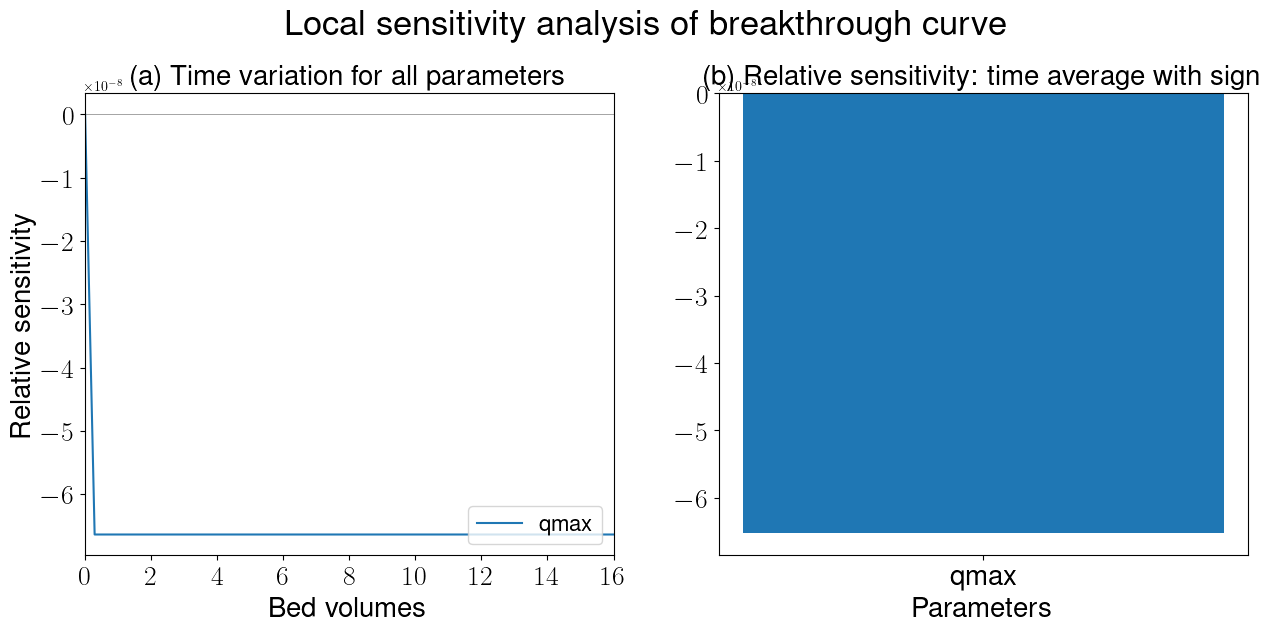

In [291]:
print(parameters.items())
S = forward_sensitivity_calibration(model, dt=0.1, xi=1e-5, relative=False, plot=True, progress=False, **parameters)

a28636 running: t: 6: : 60it [00:03, 18.40it/s]                          


RMSE (calibration) = 0.0600
SSR (calibration) = 0.0719
AIC (calibration) = -110.6


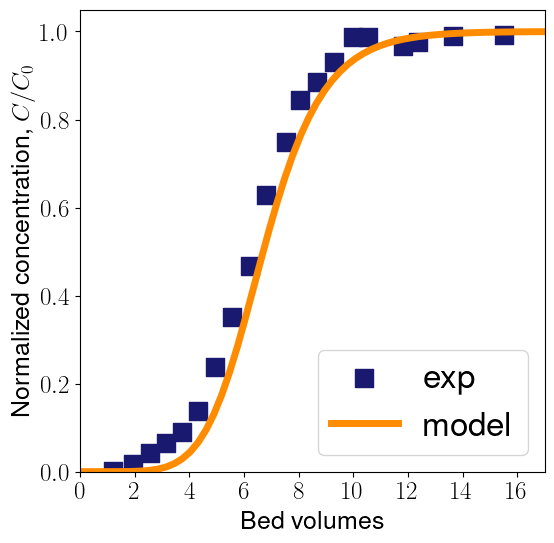

In [310]:
qmax_e_fixed,_,_ = model_calibration(texp=texp1a, Cexp=Cexp1a, progress=True, breakthrough=True, **parameters)

In [229]:
SSR = qmax_e_fixed['SSR']
print("SSR = ", SSR)
AIC = qmax_e_fixed['AIC']
print("AIC = ", AIC)

names = [name for name in parameters['calibrated_parameters'].keys()]
Sint = [np.interp(texp1a, S['t'], S[name]) for name in names]

Smatrix = [S[name] for name in names]
print("Sensitivity matrix = \n", Smatrix)

Np = len(names)
N = len(Cexp1a)

FIM = np.zeros((Np, Np))
for i in range(Np):
	for j in range(Np):
		FIM[i,j] = np.sum(Sint[i]*Sint[j])

print("FIM = \n", FIM)

covariance = np.linalg.inv(FIM) * SSR/(N-Np) # from the FIM
print("Covariance matrix: \n", covariance)

from scipy import stats
t_estimator = stats.t.ppf((1+0.95)/2, N-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

# Calculate confidence intervals
for name in names:
	value = parameters['calibrated_parameters'][name]
	CI = t_estimator * np.sqrt(covariance[i,i])
	d = CI/value*100
	if value > 1e-3:
		print(f"CI {names[i]:s} : {value:.3f} ± {CI:.4f} ({d:.1f}%)")
	else:
		print(f"CI {names[i]:s} : {value:.3e} ± {CI:.4e} ({d:.1f}%)")


SSR =  0.010875626450179752
AIC =  -148.33926745212466
Sensitivity matrix = 
 [array([ 0.00000000e+00, -4.47136033e-06, -5.86383230e-06, -8.23245735e-05,
       -9.48535014e-04, -4.85529115e-03, -1.63975584e-02, -4.31960885e-02,
       -9.63467941e-02, -1.90557670e-01, -3.43833076e-01, -5.76432007e-01,
       -9.08661892e-01, -1.35700106e+00, -1.92828901e+00, -2.61257230e+00,
       -3.37679228e+00, -4.16304396e+00, -4.89506958e+00, -5.49346200e+00,
       -5.89478704e+00, -6.06651520e+00, -6.01158429e+00, -5.76220951e+00,
       -5.36754523e+00, -4.88096103e+00, -4.35071435e+00, -3.81507302e+00,
       -3.30111118e+00, -2.82577245e+00, -2.39793783e+00, -2.02065883e+00,
       -1.69311958e+00, -1.41217185e+00, -1.17344218e+00, -9.72078958e-01,
       -8.03224694e-01, -6.62292195e-01, -5.45108025e-01, -4.47970367e-01,
       -3.67654485e-01, -3.01388189e-01, -2.46811899e-01, -2.01932468e-01,
       -1.65076210e-01, -1.34844256e-01, -1.10071823e-01, -8.97919891e-02,
       -7.32041173e-0

In [314]:
qmax_lm_ls_e_fixed = sequential_calibration(method='lm', algorithm='ls', tol=1e-4, **parameters)

Parameters to calibrate: ['qmax']
Original values: [0.31]
Method: Levenberg-Marquardt
Algorithm: Least-squares
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.31}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.31}}
Run 3: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.31}}
Run 4: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.31000000461935995}}
Run 5: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.31}}
Run 6: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.30999394454554763}}
Run 7: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.31000605545445237}}
Calibration finished.
Number of runs: 7
Calculating SSR, RMSE, AIC...
SSR = 0.071

LinAlgError: Singular matrix

In [315]:
qmax_lm_cf_e_fixed = sequential_calibration(method='lm', algorithm='cf', tol=1e-4, **parameters)

Parameters to calibrate: ['qmax']
Original values: [0.31]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.31}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.31}}
Run 3: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.31}}
Run 4: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.31000000461935995}}
Run 5: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2918783394182402}}
Run 6: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2918783437675664}}
Run 7: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.29084184664280693}}
Run 8: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2908418509766882}}
Run 9: {'fixed_parameters': {'e': 0.34673

In [312]:

qmax_trf_cf_e_fixed = sequential_calibration(method='trf', algorithm='cf', tol=1e-4, **parameters)

Parameters to calibrate: ['qmax']
Original values: [0.31]
Method: Trust Region Reflective
Bounds: ([0.248], [0.372])
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.31}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.3100000149011612}}
Run 3: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2959770394171462}}
Run 4: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2959770543183074}}
Run 5: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2914841630734296}}
Run 6: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2914841779745908}}
Run 7: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.29083576395669947}}
Run 8: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.29

qmax (calibrated) =  0.312000078802312
dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'qmax': 0.312000078802312})])


498868 running: t: 6: : 60it [00:02, 20.12it/s]                          


RMSE (calibration) = 0.0654
SSR (calibration) = 0.0856
AIC (calibration) = -107.1


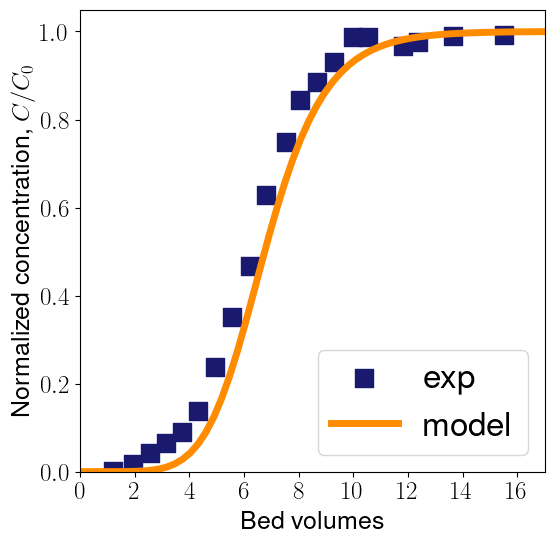

In [302]:
qmax = qmax_lm_ls_e_fixed['params']['qmax']
print("qmax (calibrated) = ", qmax)
parameters['calibrated_parameters']['qmax'] = qmax
print(parameters.items())
qmax_e_fixed,_,_ = model_calibration(texp=texp1a, Cexp=Cexp1a, progress=True, breakthrough=True, **parameters)

In [126]:
# Calibrate qmax
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(qmax=0.291)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

qmax_lm_cf_e_fixed = sequential_calibration(method='lm', algorithm='cf', tol=1e-4, **parameters)

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'qmax': 0.291})])
Parameters to calibrate: ['qmax']
Original values: [0.291]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.291}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.291}}
Run 3: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.291}}
Run 4: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2910000043362379}}
Run 5: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.29080668542994575}}
Run 6: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.29080668976330304}}
Run 7: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2907990729332041}}
Calibration finished.
Number of runs: 7
C

In [165]:
# Calibrate qmax
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(qmax=0.291)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

qmax_trf_ls_e_fixed = sequential_calibration(method='trf', algorithm='ls', tol=1e-14, **parameters)

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'qmax': 0.291})])
Parameters to calibrate: ['qmax']
Original values: [0.291]
Method: Trust Region Reflective
Bounds: ([0.2328], [0.34919999999999995])
Algorithm: Least-squares
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.291}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.2910000149011612}}
Calibration finished.
Number of runs: 2
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -148.3
Calculating FIM...
Run 1 of 2 : {'qmax': 0.291}
Run 2 of 2 : {'qmax': 0.29100291}


LinAlgError: Singular matrix

In [127]:
# Calibrate qmax
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(qmax=0.291)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

qmax_trf_cf_e_fixed = sequential_calibration(method='trf', algorithm='cf', tol=1e-4, **parameters)

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'qmax': 0.291})])
Parameters to calibrate: ['qmax']
Original values: [0.291]
Method: Trust Region Reflective
Bounds: ([0.2328], [0.34919999999999995])
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.291}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2910000149011612}}
Run 3: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.290807325504907}}
Run 4: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2908073404060682}}
Calibration finished.
Number of runs: 4
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -148.4
Calculating FIM...
Run 1 of 2 : {'qmax': 0.290807325504907}
Run 2 of 2 : {'qmax': 0.2908102335781621}
FIM = 
 [[165.0208152]]
SSR =  0.010869214656721108
Calibrated parameters: [0.29080733]
Covar

In [128]:
print(f"e = {qmax_lm_cf_e_fixed['params']['e'] : .3f}") 
print(f"qmax = {qmax_lm_cf_e_fixed['params']['qmax'] : .3f}")

e =  0.347
qmax =  0.291


d9b2b7 running: t: 6: : 60it [00:02, 20.75it/s]                          


RMSE (calibration) = 0.0233
SSR (calibration) = 0.0109
AIC (calibration) = -148.4


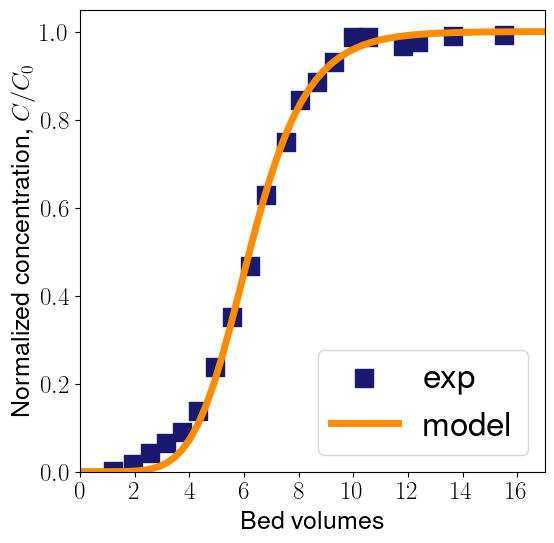

In [132]:
calibrated_parameters = dict(qmax = qmax_lm_cf_e_fixed['params']['qmax'])
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
qmax_e_fixed,_,_ = model_calibration(texp=texp1a, Cexp=Cexp1a, progress=True, breakthrough=True, **parameters) # type: ignore

#### rho, epsilon fixed

In [ ]:
# Calibrate epsilon
# e_lm_ls = calibration(method='lm', algorithm='ls', tol=1e-4, e=0.37)

Parameters to calibrate: ['e']
Original values: [0.37]
Method: Levenberg-Marquardt
Algorithm: Least-squares
Run 1: {'e': 0.37}
Run 2: {'e': 0.37}
Run 3: {'e': 0.37}
Run 4: {'e': 0.37000000551342965}
Run 5: {'e': 0.35631705821577975}
Run 6: {'e': 0.35631706352531767}
Run 7: {'e': 0.3492553595132845}
Run 8: {'e': 0.34925536471759494}
Run 9: {'e': 0.3405561837070538}
Run 10: {'e': 0.34581613044864556}
Run 11: {'e': 0.3458161356017075}
Run 12: {'e': 0.3492553595132845}
Run 13: {'e': 0.34669674653797994}
Run 14: {'e': 0.34669675170416403}
Run 15: {'e': 0.3475757000039151}
Run 16: {'e': 0.3467847914923797}
Run 17: {'e': 0.34673557495870555}
Run 18: {'e': 0.34673558012546823}
Run 19: {'e': 0.34669674330012745}
Run 20: {'e': 0.34673557495870555}
Run 21: {'e': 0.3467295195042532}
Run 22: {'e': 0.3467416304131579}
Calibration finished.
Number of runs: 22
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -148.3
Calculating FIM...
Run 1 of 2 : {'e': 0.34673557495870555}
Run 2 of 2 : {

In [134]:
# Fix value for epsilon
e_fixed = e_lm_ls['params']['e']
print("e (calibrated) = ", e_fixed)

e (calibrated) =  0.34673557495870555


In [188]:
# Calibrate rho
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(rho_p=389)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

rho_lm_ls_e_fixed = sequential_calibration(method='lm', algorithm='ls', tol=1e-4, **parameters)

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'rho_p': 389})])
Parameters to calibrate: ['rho_p']
Original values: [389]
Method: Levenberg-Marquardt
Algorithm: Least-squares
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 389.0}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 389.0}}
Run 3: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 389.0}}
Run 4: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 389.0000057965517}}
Run 5: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 389.0}}
Run 6: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 388.997644428218}}
Run 7: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters'

LinAlgError: Singular matrix

In [168]:
# Calibrate rho
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(rho_p=389)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

rho_lm_cf_e_fixed = sequential_calibration(method='lm', algorithm='cf', tol=1e-8, **parameters)

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'rho_p': 389})])
Parameters to calibrate: ['rho_p']
Original values: [389]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rho_p': 389}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rho_p': 389.0}}
Run 3: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rho_p': 389.0}}
Run 4: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rho_p': 389.0000057965517}}


/Users/Daniel/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/minpack.py:833: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


Calibration finished.
Number of runs: 4
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -148.3
Calculating FIM...
Run 1 of 2 : {'rho_p': 389.0}
Run 2 of 2 : {'rho_p': 389.00389}


LinAlgError: Singular matrix

In [170]:
# Calibrate rho
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(rho_p=389)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

rho_trf_ls_e_fixed = sequential_calibration(method='trf', algorithm='ls', tol=1e-8, **parameters)

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'rho_p': 389})])
Parameters to calibrate: ['rho_p']
Original values: [389]
Method: Trust Region Reflective
Bounds: ([311.20000000000005], [466.79999999999995])
Algorithm: Least-squares
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 389.0}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 389.0000057965517}}
Calibration finished.
Number of runs: 2
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -148.3
Calculating FIM...
Run 1 of 2 : {'rho_p': 389.0}
Run 2 of 2 : {'rho_p': 389.00389}


LinAlgError: Singular matrix

In [169]:
# Calibrate rho
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(rho_p=389)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

rho_trf_cf_e_fixed = sequential_calibration(method='trf', algorithm='cf', tol=1e-8, **parameters)

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'rho_p': 389})])
Parameters to calibrate: ['rho_p']
Original values: [389]
Method: Trust Region Reflective
Bounds: ([311.20000000000005], [466.79999999999995])
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rho_p': 389.0}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rho_p': 389.0000057965517}}
Calibration finished.
Number of runs: 2
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -148.3
Calculating FIM...
Run 1 of 2 : {'rho_p': 389.0}
Run 2 of 2 : {'rho_p': 389.00389}


LinAlgError: Singular matrix

In [95]:
print(f"e = {qmax_lm_cf_e_fixed['params']['e'] : .3f}") 
print(f"rho = {466.595774480036 : .3f}")

e =  0.347
rho =  466.596


dd83d2 running: t: 6: : 60it [00:03, 17.57it/s]                          


RMSE (calibration) = 0.0233
SSR (calibration) = 0.0109
AIC (calibration) = -148.3


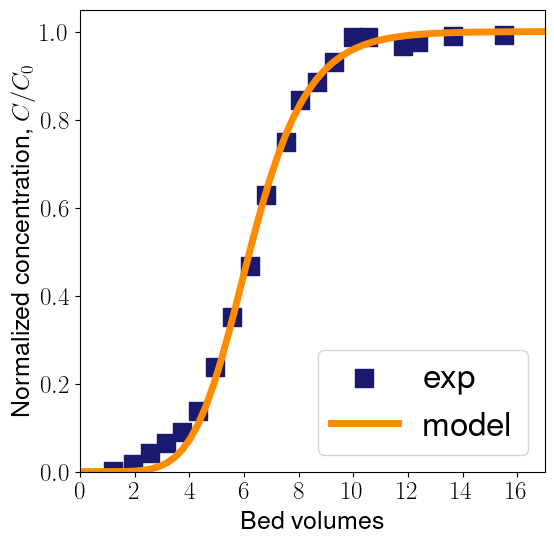

In [187]:
calibrated_parameters = dict(rho_p = 466.595774480036)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
rho_e_fixed,_,_ = model_calibration(texp=texp1a, Cexp=Cexp1a, progress=True, breakthrough=True, **parameters) # type: ignore

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'rho_p': 389})])
Run 1 of 2 : {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rho_p': 389}}
Run 2 of 2 : {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rho_p': 855.8000000000001}}
Average sensitivity (relative): 0.0
 rho_p: 0.00


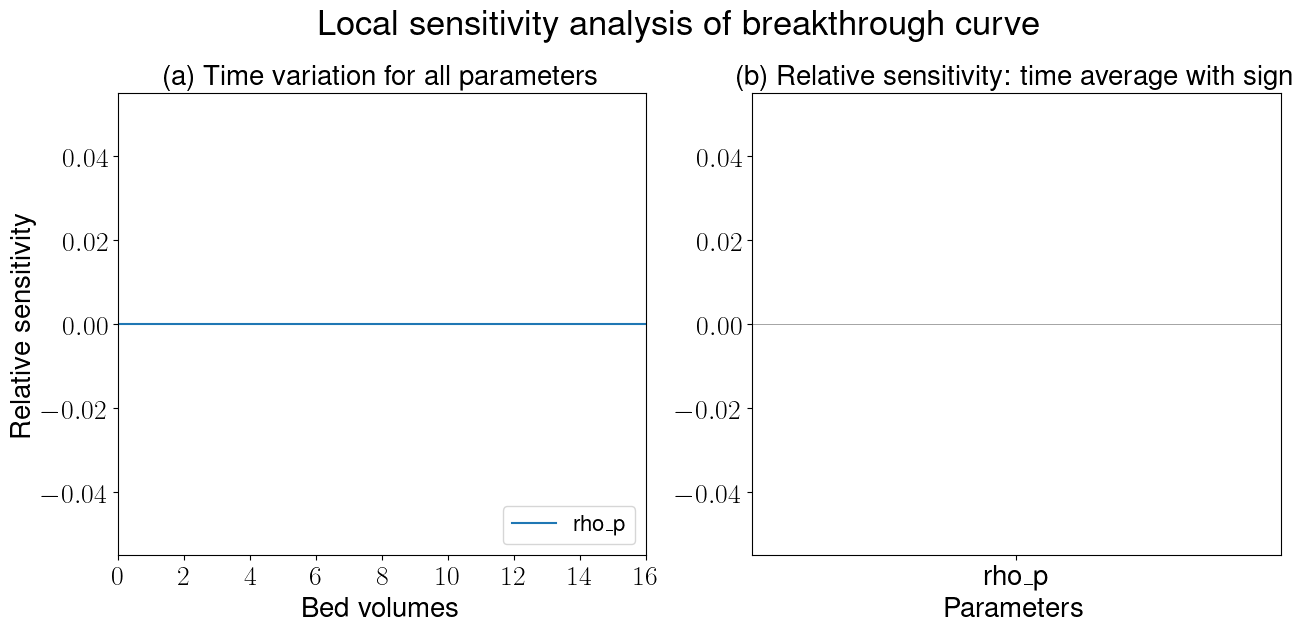

In [216]:
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(rho_p=389)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

S = forward_sensitivity_calibration(model, dt=0.1, xi=1.2, relative=True, plot=True, progress=False, **parameters)

In [113]:
S = forward_sensitivity(model, dt=0.1, relative=False, plot=False, progress=False, rho_p=466.595774480036, e=e_fixed)

Run 1 of 3 : {'rho_p': 466.595774480036, 'e': 0.34673557495870555}
Run 2 of 3 : {'rho_p': 466.60044043778083, 'e': 0.34673557495870555}
Run 3 of 3 : {'rho_p': 466.595774480036, 'e': 0.3467390423144552}


In [190]:
print(S)

{'t': array([ 0.        ,  0.28840421,  0.57680842,  0.86521263,  1.15361684,
        1.44202106,  1.73042527,  2.01882948,  2.30723369,  2.5956379 ,
        2.88404211,  3.17244632,  3.46085053,  3.74925475,  4.03765896,
        4.32606317,  4.61446738,  4.90287159,  5.1912758 ,  5.47968001,
        5.76808422,  6.05648844,  6.34489265,  6.63329686,  6.92170107,
        7.21010528,  7.49850949,  7.7869137 ,  8.07531791,  8.36372213,
        8.65212634,  8.94053055,  9.22893476,  9.51733897,  9.80574318,
       10.09414739, 10.3825516 , 10.67095582, 10.95936003, 11.24776424,
       11.53616845, 11.82457266, 12.11297687, 12.40138108, 12.68978529,
       12.97818951, 13.26659372, 13.55499793, 13.84340214, 14.13180635,
       14.42021056, 14.70861477, 14.99701898, 15.28542319, 15.57382741,
       15.86223162, 16.15063583, 16.43904004, 16.72744425, 17.01584846,
       17.30425267]), 'rho_p': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0

In [177]:
SSR = rho_e_fixed['SSR']
print("SSR = ", SSR)
AIC = rho_e_fixed['AIC']
print("AIC = ", AIC)

names = [name for name in parameters['calibrated_parameters'].keys()]
Sint = [np.interp(texp1a, S['t'], S[name]) for name in names]

Smatrix = [S[name] for name in names]
print("Sensitivity matrix = \n", Smatrix)

Np = len(names)

FIM = np.zeros((Np, Np))
for i in range(Np):
	for j in range(Np):
		FIM[i,j] = np.sum(Sint[i]*Sint[j])

print("FIM = \n", FIM)

covariance = np.linalg.inv(FIM) * SSR/(N-Np) # from the FIM

from scipy import stats
t_estimator = stats.t.ppf((1+0.95)/2, N-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

# Calculate confidence intervals
# for i in range(Np):
# 	CI = t_estimator * np.sqrt(covariance[i,i])
# 	d = CI/calibrated_parameters[i]*100
# 	if cal[i] > 1e-3:
# 		print(f"CI {names[i]:s} : {param_calib[i]:.3f} ± {CI:.4f} ({d:.1f}%)")
# 	else:
# 		print(f"CI {names[i]:s} : {param_calib[i]:.3e} ± {CI:.4e} ({d:.1f}%)")


SSR =  0.010875626450179752
AIC =  -148.33926745212466
Sensitivity matrix = 
 [array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])]
FIM = 
 [[0.]]


LinAlgError: Singular matrix

#### rp, epsilon fixed

In [ ]:
# Calibrate epsilon
# e_lm_ls = calibration(method='lm', algorithm='ls', tol=1e-4, e=0.37)

Parameters to calibrate: ['e']
Original values: [0.37]
Method: Levenberg-Marquardt
Algorithm: Least-squares
Run 1: {'e': 0.37}
Run 2: {'e': 0.37}
Run 3: {'e': 0.37}
Run 4: {'e': 0.37000000551342965}
Run 5: {'e': 0.35631705821577975}
Run 6: {'e': 0.35631706352531767}
Run 7: {'e': 0.3492553595132845}
Run 8: {'e': 0.34925536471759494}
Run 9: {'e': 0.3405561837070538}
Run 10: {'e': 0.34581613044864556}
Run 11: {'e': 0.3458161356017075}
Run 12: {'e': 0.3492553595132845}
Run 13: {'e': 0.34669674653797994}
Run 14: {'e': 0.34669675170416403}
Run 15: {'e': 0.3475757000039151}
Run 16: {'e': 0.3467847914923797}
Run 17: {'e': 0.34673557495870555}
Run 18: {'e': 0.34673558012546823}
Run 19: {'e': 0.34669674330012745}
Run 20: {'e': 0.34673557495870555}
Run 21: {'e': 0.3467295195042532}
Run 22: {'e': 0.3467416304131579}
Calibration finished.
Number of runs: 22
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -148.3
Calculating FIM...
Run 1 of 2 : {'e': 0.34673557495870555}
Run 2 of 2 : {

In [178]:
# Fix value for epsilon
e_fixed = e_lm_ls['params']['e']
print("e (calibrated) = ", e_fixed)

e (calibrated) =  0.34673557495870555


In [179]:
# Calibrate rp
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(rp=3.75e-4)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

rp_lm_ls_e_fixed = sequential_calibration(method='lm', algorithm='ls', tol=1e-4, **parameters)

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'rp': 0.000375})])
Parameters to calibrate: ['rp']
Original values: [0.000375]
Method: Levenberg-Marquardt
Algorithm: Least-squares
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.000375}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.000375}}
Run 3: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.000375}}
Run 4: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.00037500000558793545}}
Run 5: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.000375}}
Run 6: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.00036894454554760667}}
Run 7: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_param

LinAlgError: Singular matrix

In [180]:
# Calibrate rp
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(rp=3.75e-4)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

rp_lm_cf_e_fixed = sequential_calibration(method='lm', algorithm='cf', tol=1e-4, **parameters)

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'rp': 0.000375})])
Parameters to calibrate: ['rp']
Original values: [0.000375]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rp': 0.000375}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rp': 0.000375}}
Run 3: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rp': 0.000375}}
Run 4: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rp': 0.00037500000558793545}}


/Users/Daniel/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/minpack.py:833: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


Calibration finished.
Number of runs: 4
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -148.3
Calculating FIM...
Run 1 of 2 : {'rp': 0.000375}
Run 2 of 2 : {'rp': 0.00037500375000000004}


LinAlgError: Singular matrix

In [182]:
# Calibrate rp
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(rp=3.75e-4)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

rp_trf_ls_e_fixed = sequential_calibration(method='trf', algorithm='ls', tol=1e-4, **parameters)

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'rp': 0.000375})])
Parameters to calibrate: ['rp']
Original values: [0.000375]
Method: Trust Region Reflective
Bounds: ([0.00030000000000000003], [0.00045])
Algorithm: Least-squares
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.000375}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'fixed_parameters': 0.00037501490116119386}}
Calibration finished.
Number of runs: 2
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -148.3
Calculating FIM...
Run 1 of 2 : {'rp': 0.000375}
Run 2 of 2 : {'rp': 0.00037500375000000004}


LinAlgError: Singular matrix

In [183]:
# Calibrate rp
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(rp=3.75e-4)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

rp_trf_cf_e_fixed = sequential_calibration(method='trf', algorithm='cf', tol=1e-12, **parameters)

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'rp': 0.000375})])
Parameters to calibrate: ['rp']
Original values: [0.000375]
Method: Trust Region Reflective
Bounds: ([0.00030000000000000003], [0.00045])
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rp': 0.000375}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'rp': 0.00037501490116119386}}
Calibration finished.
Number of runs: 2
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -148.3
Calculating FIM...
Run 1 of 2 : {'rp': 0.000375}
Run 2 of 2 : {'rp': 0.00037500375000000004}


LinAlgError: Singular matrix

In [ ]:
print(f"e = {qmax_lm_cf_e_fixed['params']['e'] : .3f}") 
print(f"qmax = {qmax_lm_cf_e_fixed['params']['qmax'] : .3f}")

e =  0.347
qmax =  0.323


78ac0b running: t: 6: : 60it [00:02, 20.61it/s]                          


RMSE (calibration) = 0.0969
SSR (calibration) = 0.1876
AIC (calibration) = -91.4


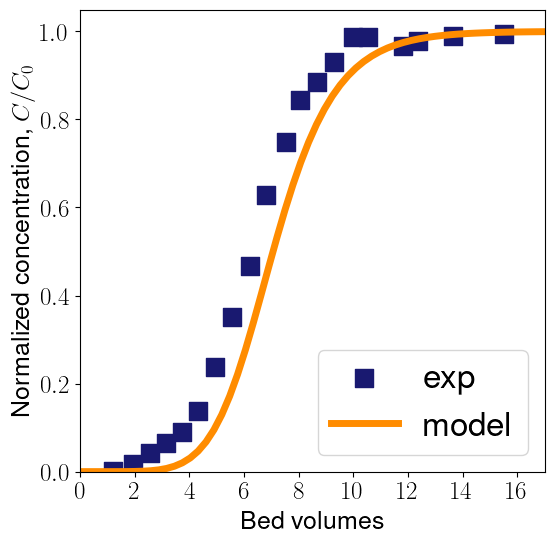

({'t': array([   0.        ,   17.6643557 ,   35.32871141,   52.99306711,
           70.65742281,   88.32177852,  105.98613422,  123.65048992,
          141.31484563,  158.97920133,  176.64355703,  194.30791273,
          211.97226844,  229.63662414,  247.30097984,  264.96533555,
          282.62969125,  300.29404695,  317.95840266,  335.62275836,
          353.28711406,  370.95146977,  388.61582547,  406.28018117,
          423.94453688,  441.60889258,  459.27324828,  476.93760399,
          494.60195969,  512.26631539,  529.93067109,  547.5950268 ,
          565.2593825 ,  582.9237382 ,  600.58809391,  618.25244961,
          635.91680531,  653.58116102,  671.24551672,  688.90987242,
          706.57422813,  724.23858383,  741.90293953,  759.56729524,
          777.23165094,  794.89600664,  812.56036235,  830.22471805,
          847.88907375,  865.55342946,  883.21778516,  900.88214086,
          918.54649656,  936.21085227,  953.87520797,  971.53956367,
          989.20391938, 1006.

In [ ]:
calibrated_parameters = dict(qmax = qmax_lm_cf_e_fixed['params']['qmax'])
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
model_calibration(texp=texp1a, Cexp=Cexp1a, progress=True, breakthrough=True, **parameters) # type: ignore

#### e, qmax fixed

In [232]:
fixed_parameters = dict()
calibrated_parameters = dict(qmax=0.291)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {}), ('calibrated_parameters', {'qmax': 0.291})])


In [235]:
# Calibrate qmax
qmax_lm_cf = sequential_calibration(method='lm', algorithm='cf', tol=1e-4, **parameters)

Parameters to calibrate: ['qmax']
Original values: [0.291]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.291}}
Run 2: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.291}}
Run 3: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.291}}
Run 4: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.2910000043362379}}
Run 5: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.3212004514762354}}
Run 6: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.3212004562624951}}
Run 7: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.32295437551536665}}
Run 8: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.32295438032776186}}
Run 9: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.3230569760339615}}
Run 10: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.3230569808478856}}
Run 11: {'fixed_parameters': {}, 'calibrated_parameter

In [ ]:
# Fix value for qmax
qmax_fixed = qmax_lm_cf['params']['qmax']
print("qmax (calibrated) = ", qmax_fixed)

qmax (calibrated) =  0.32306305900406296


In [237]:
fixed_parameters = dict(qmax=qmax_fixed)
calibrated_parameters = dict(e=0.37)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'qmax': 0.32306305900406296}), ('calibrated_parameters', {'e': 0.37})])


In [239]:
e_lm_cf_qmax_fixed = sequential_calibration(method='lm', algorithm='cf', tol=1e-4, **parameters)

Parameters to calibrate: ['e']
Original values: [0.37]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.37}}
Run 2: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.37}}
Run 3: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.37}}
Run 4: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.37000000551342965}}
Run 5: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.36987046830161446}}
Run 6: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.36987047381311394}}
Run 7: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.3698675531312368}}
Calibration finished.
Number of runs: 7
Calculating SSR, RMSE, AIC...
SSR = 0.0136
RMSE = 0.0261
AIC = -143.9
Calculating FIM...
Run 1 of 2 : {'fixed_para

In [240]:
e_trf_cf_qmax_fixed = sequential_calibration(method='trf', algorithm='cf', tol=1e-4, **parameters)

Parameters to calibrate: ['e']
Original values: [0.37]
Method: Trust Region Reflective
Bounds: ([0.296], [0.444])
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.37}}
Run 2: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.3700000149011612}}
Run 3: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.369870694692019}}
Run 4: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.3698707095931802}}
Run 5: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.3698675584644153}}
Run 6: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.3698675733655765}}
Calibration finished.
Number of runs: 6
Calculating SSR, RMSE, AIC...
SSR = 0.0136
RMSE = 0.0261
AIC = -143.9
Calculating FIM...
Run 1 of 2 : {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_para

0810c9 running: t: 6: : 60it [00:03, 18.42it/s]                          


RMSE (calibration) = 0.0261
SSR (calibration) = 0.0136
AIC (calibration) = -143.9


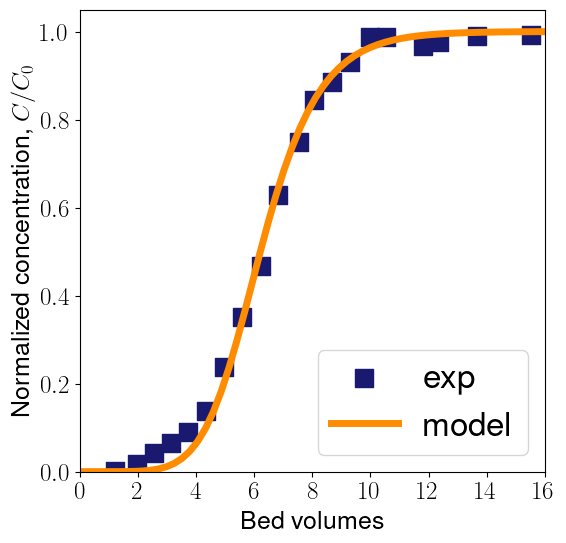

In [241]:
e_qmax_fixed,_,_ = model_calibration(texp=texp1a, Cexp=Cexp1a, progress=True, breakthrough=True, **parameters)

#### rho, qmax fixed

In [242]:
fixed_parameters = dict(qmax=qmax_fixed)
calibrated_parameters = dict(rho_p=389)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'qmax': 0.32306305900406296}), ('calibrated_parameters', {'rho_p': 389})])


In [248]:
rho_trf_cf_qmax_fixed = sequential_calibration(method='trf', algorithm='cf', tol=1e-8, **parameters)

Parameters to calibrate: ['rho_p']
Original values: [389]
Method: Trust Region Reflective
Bounds: ([311.20000000000005], [466.79999999999995])
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'rho_p': 389.0}}
Run 2: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'rho_p': 389.0000057965517}}
Calibration finished.
Number of runs: 2
Calculating SSR, RMSE, AIC...
SSR = 0.0136
RMSE = 0.0261
AIC = -143.9
Calculating FIM...
Run 1 of 2 : {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'rho_p': 389.0}}
Run 2 of 2 : {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'rho_p': 389.00389}}
Average sensitivity (absolute): 0.0


LinAlgError: Singular matrix

#### rp, qmax fixed

In [249]:
fixed_parameters = dict(qmax=qmax_fixed)
calibrated_parameters = dict(rp=3.75e-4)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'qmax': 0.32306305900406296}), ('calibrated_parameters', {'rp': 0.000375})])


Run 1 of 2 : {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'rp': 0.000375}}


dd08d5 running: t: 6: : 60it [00:02, 20.13it/s]                          


RMSE (calibration) = 0.0261
SSR (calibration) = 0.0136
AIC (calibration) = -143.9
Run 2 of 2 : {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'rp': 0.00037500375000000004}}


fe8f70 running: t: 6: : 60it [00:02, 21.31it/s]                          


RMSE (calibration) = 0.0261
SSR (calibration) = 0.0136
AIC (calibration) = -143.9
Average sensitivity (absolute): 0.0
 rp: 0.00


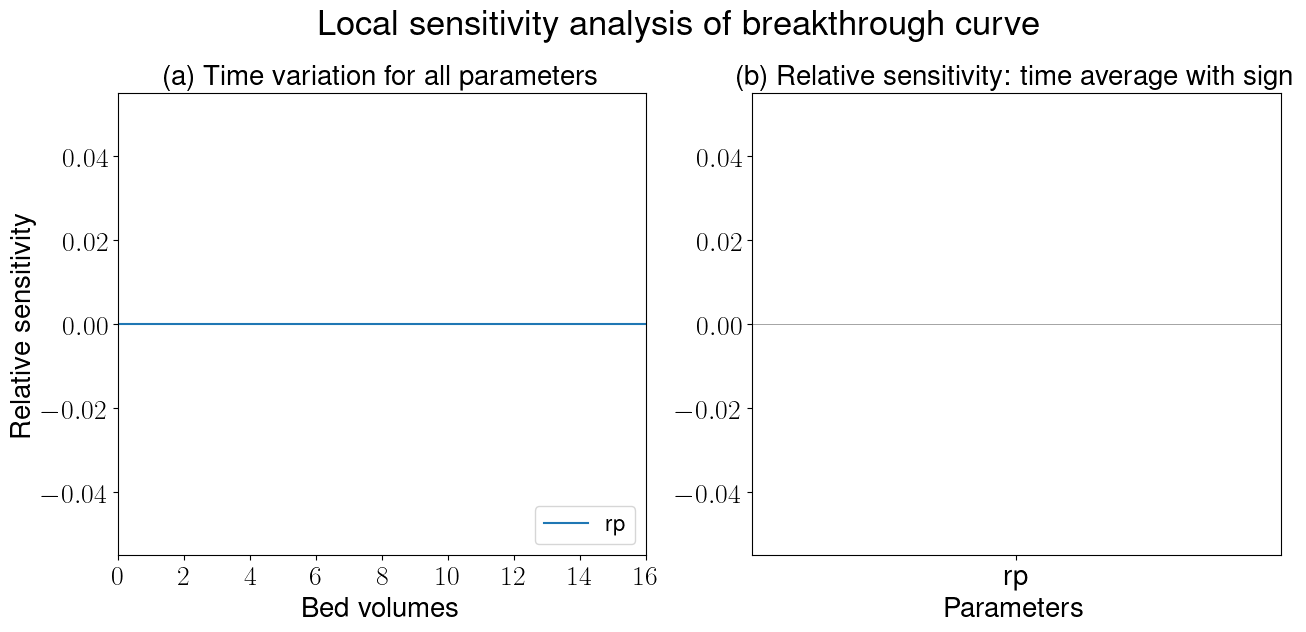

In [252]:
S = forward_sensitivity_calibration(model, dt=0.1, xi=1e-5, relative=False, plot=True, progress=True, **parameters)

In [250]:
rp_trf_cf_qmax_fixed = sequential_calibration(method='trf', algorithm='cf', tol=1e-4, **parameters)

Parameters to calibrate: ['rp']
Original values: [0.000375]
Method: Trust Region Reflective
Bounds: ([0.00030000000000000003], [0.00045])
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'rp': 0.000375}}
Run 2: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'rp': 0.00037501490116119386}}
Calibration finished.
Number of runs: 2
Calculating SSR, RMSE, AIC...
SSR = 0.0136
RMSE = 0.0261
AIC = -143.9
Calculating FIM...
Run 1 of 2 : {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'rp': 0.000375}}
Run 2 of 2 : {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'rp': 0.00037500375000000004}}
Average sensitivity (absolute): 0.0


LinAlgError: Singular matrix

### Np = 2

#### epsilon, qmax

In [ ]:
# does not work for one output variable and two parameters
e_qmax_lm_ls = calibration(method='lm', algorithm='ls', tol=1e-4, e=0.37, qmax=0.291)

Parameters to calibrate: ['e', 'qmax']
Original values: [0.37  0.291]
Method: Levenberg-Marquardt
Algorithm: Least-squares
Run 1: {'e': 0.37, 'qmax': 0.291}


ValueError: Method 'lm' doesn't work when the number of residuals is less than the number of variables.

In [224]:
e_qmax_lm_cf = calibration(method='lm', algorithm='cf', tol=1e-4, e=0.37, qmax=0.291)

Parameters to calibrate: ['e', 'qmax']
Original values: [0.37  0.291]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'qmax': 0.291}
Run 2: {'e': 0.37, 'qmax': 0.291}
Run 3: {'e': 0.37, 'qmax': 0.291}
Run 4: {'e': 0.37000000551342965, 'qmax': 0.291}
Run 5: {'e': 0.37, 'qmax': 0.2910000043362379}
Run 6: {'e': 0.22863143893870475, 'qmax': 0.13477088430603437}
Run 7: {'e': 0.22863144234557867, 'qmax': 0.13477088430603437}
Run 8: {'e': 0.22863143893870475, 'qmax': 0.13477088631427706}
Run 9: {'e': 0.3000115325938169, 'qmax': 0.22671573384276927}
Run 10: {'e': 0.30001153706433714, 'qmax': 0.22671573384276927}
Run 11: {'e': 0.3000115325938169, 'qmax': 0.22671573722109697}
Run 12: {'e': 0.3053298936302299, 'qmax': 0.23593396793795451}
Run 13: {'e': 0.30532989817999984, 'qmax': 0.23593396793795451}
Run 14: {'e': 0.3053298936302299, 'qmax': 0.23593397145364461}
Run 15: {'e': 0.3069133695248449, 'qmax': 0.23806420272097}
Run 16: {'e': 0.30691337409821046, 'qmax': 0.238064

In [223]:
# cannot calculate covariance matrix
e_qmax_trf_ls = calibration(method='trf', algorithm='ls', tol=1e-4, e=0.37, qmax=0.291)

Parameters to calibrate: ['e', 'qmax']
Original values: [0.37  0.291]
Method: Trust Region Reflective
Bounds: ([0.296, 0.2328], [0.444, 0.34919999999999995])
Algorithm: Least-squares
Run 1: {'e': 0.37, 'qmax': 0.291}
Run 2: {'e': 0.3700000149011612, 'qmax': 0.291}
Run 3: {'e': 0.37, 'qmax': 0.2910000149011612}
Run 4: {'e': 0.3614572612585531, 'qmax': 0.2959752069259142}
Run 5: {'e': 0.3614572761597143, 'qmax': 0.2959752069259142}
Run 6: {'e': 0.3614572612585531, 'qmax': 0.2959752218270754}
Run 7: {'e': 0.35644748094199097, 'qmax': 0.2989266323709694}
Run 8: {'e': 0.35644749584315216, 'qmax': 0.2989266323709694}
Run 9: {'e': 0.35644748094199097, 'qmax': 0.2989266472721306}
Run 10: {'e': 0.3517470343299483, 'qmax': 0.30164180639431754}
Run 11: {'e': 0.3517470492311095, 'qmax': 0.30164180639431754}
Run 12: {'e': 0.3517470343299483, 'qmax': 0.30164182129547873}
Run 13: {'e': 0.35729910432094236, 'qmax': 0.29847537496321946}
Run 14: {'e': 0.3531330889444714, 'qmax': 0.3008476361672596}
Run 

LinAlgError: Singular matrix

In [56]:
e_qmax_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, e=0.37, qmax=0.291)

Parameters to calibrate: ['e', 'qmax']
Original values: [0.37  0.291]
Method: Trust Region Reflective
Bounds: ([0.296, 0.2328], [0.444, 0.34919999999999995])
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'qmax': 0.291}
Run 2: {'e': 0.3700000149011612, 'qmax': 0.291}
Run 3: {'e': 0.37, 'qmax': 0.2910000149011612}
Run 4: {'e': 0.3573586020597124, 'qmax': 0.2999074707974764}
Run 5: {'e': 0.3573586169608736, 'qmax': 0.2999074707974764}
Run 6: {'e': 0.3573586020597124, 'qmax': 0.2999074856986376}
Run 7: {'e': 0.35383414334783436, 'qmax': 0.30031509375023513}
Run 8: {'e': 0.35383415824899556, 'qmax': 0.30031509375023513}
Run 9: {'e': 0.35383414334783436, 'qmax': 0.3003151086513963}
Run 10: {'e': 0.34251332708388477, 'qmax': 0.2851708754224018}
Run 11: {'e': 0.34251334198504596, 'qmax': 0.2851708754224018}
Run 12: {'e': 0.34251332708388477, 'qmax': 0.285170890323563}
Run 13: {'e': 0.3234137585253282, 'qmax': 0.2594248955496723}
Run 14: {'e': 0.3234137734264894, 'qmax': 0.2594248955496723}
Run 1

#### epsilon, rho

In [254]:
e_rho_lm_ls= calibration(method='lm', algorithm='cf', tol=1e-4, e=0.37, rho_p=389)

Parameters to calibrate: ['e', 'rho_p']
Original values: [3.70e-01 3.89e+02]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'rho_p': 389.0}
Run 2: {'e': 0.37, 'rho_p': 389.0}
Run 3: {'e': 0.37, 'rho_p': 389.0}
Run 4: {'e': 0.37000000551342965, 'rho_p': 389.0}
Run 5: {'e': 0.37, 'rho_p': 389.0000057965517}
Run 6: {'e': 0.22863066981867988, 'rho_p': -28.68835433930883}
Run 7: {'e': 0.35041767836531, 'rho_p': 400.3721190825011}
Run 8: {'e': 0.3504176835869403, 'rho_p': 400.3721190825011}
Run 9: {'e': 0.35041767836531, 'rho_p': 400.3721250485106}
Run 10: {'e': 0.3256657374879511, 'rho_p': 310.1450008790264}
Run 11: {'e': 0.32566574234074874, 'rho_p': 310.1450008790264}
Run 12: {'e': 0.3256657374879511, 'rho_p': 310.14500550054703}
Run 13: {'e': 0.30168776714052237, 'rho_p': 241.6238937250448}
Run 14: {'e': 0.3016877716360204, 'rho_p': 241.6238937250448}
Run 15: {'e': 0.30168776714052237, 'rho_p': 241.6238973255214}
Run 16: {'e': 0.29975990968081634, 'rho_p': 240.65

In [ ]:
# correlation = -1, invalid covariance matrix
e_rho_trf, results_e_rho_trf = calibration(method='trf', algorithm='ls', tol=1e-4, e=0.37, rho_p=389)

Parameters to calibrate: ['e', 'rho_p']
Original values: [3.70e-01 3.89e+02]
Method: Trust Region Reflective
Bounds: ([0.296, 311.20000000000005], [0.444, 466.79999999999995])
Algorithm: Least-squares
Run 1: {'e': 0.37, 'rho_p': 389.0}
Run 2: {'e': 0.3700000149011612, 'rho_p': 389.0}
Run 3: {'e': 0.37, 'rho_p': 389.0000057965517}
Run 4: {'e': 0.3584529261904039, 'rho_p': 389.0033624454999}
Run 5: {'e': 0.3584529410915651, 'rho_p': 389.0033624454999}
Run 6: {'e': 0.3584529261904039, 'rho_p': 389.00336824210166}
Calibration finished.
Number of runs: 6
Calculating FIM...
Run 1 of 3 : {'e': 0.37, 'rho_p': 389}
Run 2 of 3 : {'e': 0.37000370000000005, 'rho_p': 389}
Run 3 of 3 : {'e': 0.37, 'rho_p': 389.00389}
FIM = 
 [[ 7.09834472 -4.4763437 ]
 [-4.4763437   2.82892236]]
Calculating SSR, RMSE, AIC...
SSR = 
 0.04869992033405381
Number of function evaluations: 2
`xtol` termination condition is satisfied.
Calibrated parameters: {'e': 0.3584529261904039, 'rho_p': 389.0033624454999}
Jacobian = 


/var/folders/vb/76n31gjx2xqb2799fdrgk9dc0000gn/T/ipykernel_2220/1519471399.py:113: RuntimeWarning: invalid value encountered in sqrt
  print("Standard deviation: \n", np.sqrt(np.diag(covariance))) # standard deviation of the parameters
/var/folders/vb/76n31gjx2xqb2799fdrgk9dc0000gn/T/ipykernel_2220/1519471399.py:128: RuntimeWarning: invalid value encountered in sqrt
  CI = t_estimator * np.sqrt(covariance[i,i])


In [253]:
e_rho_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, e=0.37, rho_p=389)

Parameters to calibrate: ['e', 'rho_p']
Original values: [3.70e-01 3.89e+02]
Method: Trust Region Reflective
Bounds: ([0.296, 311.20000000000005], [0.444, 466.79999999999995])
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'rho_p': 389.0}
Run 2: {'e': 0.3700000149011612, 'rho_p': 389.0}
Run 3: {'e': 0.37, 'rho_p': 389.0000057965517}
Run 4: {'e': 0.3552865656927886, 'rho_p': 403.16547230905996}
Run 5: {'e': 0.3552865805939498, 'rho_p': 403.16547230905996}
Run 6: {'e': 0.3552865656927886, 'rho_p': 403.1654783166937}
Run 7: {'e': 0.3513956311785505, 'rho_p': 404.8148513339122}
Run 8: {'e': 0.3513956460797117, 'rho_p': 404.8148513339122}
Run 9: {'e': 0.3513956311785505, 'rho_p': 404.81485736612353}
Run 10: {'e': 0.3445699742262176, 'rho_p': 380.5094715240574}
Run 11: {'e': 0.3445699891273788, 'rho_p': 380.5094715240574}
Run 12: {'e': 0.3445699742262176, 'rho_p': 380.5094771940904}
Run 13: {'e': 0.32712281361176776, 'rho_p': 318.4184404504372}
Run 14: {'e': 0.32712282851292895, 'rho_p': 318.41

#### epsilon, rp (*)

In [289]:
e_rp_lm_ls = calibration(method='lm', algorithm='cf', tol=1e-4, e=0.37, rp=3.75e-4)

Parameters to calibrate: ['e', 'rp']
Original values: [0.37     0.000375]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'rp': 0.000375}
Run 2: {'e': 0.37, 'rp': 0.000375}
Run 3: {'e': 0.37, 'rp': 0.000375}
Run 4: {'e': 0.37000000551342965, 'rp': 0.000375}
Run 5: {'e': 0.37, 'rp': 0.00037500000558793545}
Run 6: {'e': 0.3423571428241473, 'rp': 0.00047291060903235547}
Run 7: {'e': 0.3423571479256663, 'rp': 0.00047291060903235547}
Run 8: {'e': 0.3423571428241473, 'rp': 0.00047291061607927266}
Run 9: {'e': 0.3458039099471678, 'rp': 0.00041323243578166724}
Run 10: {'e': 0.3458039151000476, 'rp': 0.00041323243578166724}
Run 11: {'e': 0.3458039099471678, 'rp': 0.0004132324419393104}
Run 12: {'e': 0.3454633552158045, 'rp': 0.00041132986787323497}
Run 13: {'e': 0.34546336036360964, 'rp': 0.00041132986787323497}
Run 14: {'e': 0.3454633552158045, 'rp': 0.0004113298740025276}
Run 15: {'e': 0.345486790051237, 'rp': 0.0004108127820717976}
Calibration finished.
Number of runs

In [ ]:
e_rp_trf_ls = calibration(method='trf', algorithm='ls', tol=1e-4, e=0.37, rp=3.75e-4)

Parameters to calibrate: ['e', 'rp']
Original values: [0.37     0.000375]
Method: Trust Region Reflective
Bounds: ([0.296, 0.00030000000000000003], [0.444, 0.00045])
Algorithm: Least-squares
Run 1: {'e': 0.37, 'rp': 0.000375}
Run 2: {'e': 0.3700000149011612, 'rp': 0.000375}
Run 3: {'e': 0.37, 'rp': 0.00037501490116119386}
Run 4: {'e': 0.363988439770786, 'rp': 0.000300375}
Run 5: {'e': 0.3639884546719472, 'rp': 0.000300375}
Run 6: {'e': 0.363988439770786, 'rp': 0.00030038990116119387}
Run 7: {'e': 0.36206913207423025, 'rp': 0.0004221132326748879}
Run 8: {'e': 0.36206914697539144, 'rp': 0.0004221132326748879}
Run 9: {'e': 0.36206913207423025, 'rp': 0.0004221281338360817}
Run 10: {'e': 0.36039744909489035, 'rp': 0.0003244958141004545}
Run 11: {'e': 0.36039746399605155, 'rp': 0.0003244958141004545}
Run 12: {'e': 0.36039744909489035, 'rp': 0.0003245107152616483}
Run 13: {'e': 0.3579144024583496, 'rp': 0.0004370392253144046}
Run 14: {'e': 0.3579144173595108, 'rp': 0.0004370392253144046}
Run 

In [ ]:
e_rp_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, e=0.37, rp=3.75e-4)

Parameters to calibrate: ['e', 'rp']
Original values: [0.37     0.000375]
Method: Trust Region Reflective
Bounds: ([0.296, 0.00030000000000000003], [0.444, 0.00045])
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'rp': 0.000375}
Run 2: {'e': 0.3700000149011612, 'rp': 0.000375}
Run 3: {'e': 0.37, 'rp': 0.00037501490116119386}
Run 4: {'e': 0.35086113683411796, 'rp': 0.00041661765415995514}
Run 5: {'e': 0.35086115173527915, 'rp': 0.00041661765415995514}
Run 6: {'e': 0.35086113683411796, 'rp': 0.000416632555321149}
Run 7: {'e': 0.3457476748925897, 'rp': 0.00041538597175372414}
Run 8: {'e': 0.34574768979375087, 'rp': 0.00041538597175372414}
Run 9: {'e': 0.3457476748925897, 'rp': 0.000415400872914918}
Run 10: {'e': 0.34547383209286403, 'rp': 0.00041161351410230155}
Run 11: {'e': 0.3454738469940252, 'rp': 0.00041161351410230155}
Run 12: {'e': 0.34547383209286403, 'rp': 0.0004116284152634954}
Run 13: {'e': 0.3454864733343606, 'rp': 0.0004108544195855232}
Run 14: {'e': 0.3454864882355218, 'rp': 0.

#### qmax, rho

In [57]:
qmax_rho_lm_cf = calibration(method='lm', algorithm='cf', tol=1e-4, qmax=0.291, rho_p=389)

Parameters to calibrate: ['qmax', 'rho_p']
Original values: [2.91e-01 3.89e+02]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'qmax': 0.291, 'rho_p': 389.0}
Run 2: {'qmax': 0.291, 'rho_p': 389.0}
Run 3: {'qmax': 0.291, 'rho_p': 389.0}
Run 4: {'qmax': 0.2910000043362379, 'rho_p': 389.0}
Run 5: {'qmax': 0.291, 'rho_p': 389.0000057965517}
Run 6: {'qmax': -22.699459375277076, 'rho_p': 61935.782566429596}
Run 7: {'qmax': -1.9944557307841047, 'rho_p': 6580.012293350719}
Run 8: {'qmax': 0.07604463343085335, 'rho_p': 1044.4352654166742}
Run 9: {'qmax': 0.28813676969084534, 'rho_p': 477.3972625847935}
Run 10: {'qmax': 0.2881367739844178, 'rho_p': 477.3972625847935}
Run 11: {'qmax': 0.28813676969084534, 'rho_p': 477.3972696985671}
Run 12: {'qmax': 0.2509762568340452, 'rho_p': 611.422351373764}
Run 13: {'qmax': 0.2833181382881042, 'rho_p': 504.25129866289626}
Run 14: {'qmax': 0.28331814250987347, 'rho_p': 504.25129866289626}
Run 15: {'qmax': 0.2833181382881042, 'rho_p': 504.2513061

In [385]:
# singular matrix
qmax_rho_trf_ls = calibration(method='trf', algorithm='ls', tol=1e-4, qmax=0.291, rho_p=389)

Parameters to calibrate: ['qmax', 'rho_p']
Original values: [2.91e-01 3.89e+02]
Method: Trust Region Reflective
Bounds: ([0.2328, 311.20000000000005], [0.34919999999999995, 466.79999999999995])
Algorithm: Least-squares
Run 1: {'qmax': 0.291, 'rho_p': 389.0}
Run 2: {'qmax': 0.2910000149011612, 'rho_p': 389.0}
Run 3: {'qmax': 0.291, 'rho_p': 389.0000057965517}
Run 4: {'qmax': 0.3050238215600005, 'rho_p': 389.00701189921955}
Run 5: {'qmax': 0.3050238364611617, 'rho_p': 389.00701189921955}
Run 6: {'qmax': 0.3050238215600005, 'rho_p': 389.00701769587573}
Calibration finished.
Number of runs: 6
Calculating FIM...
Run 1 of 3 : {'qmax': 0.3050238215600005, 'rho_p': 389.00701189921955}
Run 2 of 3 : {'qmax': 0.30502687179821614, 'rho_p': 389.00701189921955}
Run 3 of 3 : {'qmax': 0.3050238215600005, 'rho_p': 389.0109019693386}
FIM = 
 [[1.41627170e+02 5.55252098e-02]
 [5.55252098e-02 2.17687673e-05]]
Calculating SSR, RMSE, AIC...
SSR = 
 0.05815406443253034


LinAlgError: Singular matrix

In [58]:
qmax_rho_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, qmax=0.291, rho_p=389)

Parameters to calibrate: ['qmax', 'rho_p']
Original values: [2.91e-01 3.89e+02]
Method: Trust Region Reflective
Bounds: ([0.2328, 311.20000000000005], [0.34919999999999995, 466.79999999999995])
Algorithm: Curve-fitting
Run 1: {'qmax': 0.291, 'rho_p': 389.0}
Run 2: {'qmax': 0.2910000149011612, 'rho_p': 389.0}
Run 3: {'qmax': 0.291, 'rho_p': 389.0000057965517}
Run 4: {'qmax': 0.3059588078996043, 'rho_p': 408.99650917180264}
Run 5: {'qmax': 0.3059588228007655, 'rho_p': 408.99650917180264}
Run 6: {'qmax': 0.3059588078996043, 'rho_p': 408.99651526632556}
Run 7: {'qmax': 0.3110183833113087, 'rho_p': 415.76005624680084}
Run 8: {'qmax': 0.3110183982124699, 'rho_p': 415.76005624680084}
Run 9: {'qmax': 0.3110183833113087, 'rho_p': 415.76006244210845}
Run 10: {'qmax': 0.3119222048675316, 'rho_p': 416.9686337379647}
Run 11: {'qmax': 0.3119222197686928, 'rho_p': 416.9686337379647}
Run 12: {'qmax': 0.3119222048675316, 'rho_p': 416.96863995128155}
Run 13: {'qmax': 0.3119951968489731, 'rho_p': 417.070

#### qmax, rp (*)

In [288]:
qmax_rp_lm_cf = calibration(method='trf', algorithm='cf', tol=1e-4, qmax=0.291, rp=3.75e-4)

Parameters to calibrate: ['qmax', 'rp']
Original values: [0.291    0.000375]
Method: Trust Region Reflective
Bounds: ([0.2328, 0.00030000000000000003], [0.34919999999999995, 0.00045])
Algorithm: Curve-fitting
Run 1: {'qmax': 0.291, 'rp': 0.000375}
Run 2: {'qmax': 0.2910000149011612, 'rp': 0.000375}
Run 3: {'qmax': 0.291, 'rp': 0.00037501490116119386}
Run 4: {'qmax': 0.31249965372449634, 'rp': 0.00041319251972999314}
Run 5: {'qmax': 0.31249966862565753, 'rp': 0.00041319251972999314}
Run 6: {'qmax': 0.31249965372449634, 'rp': 0.000413207420891187}
Run 7: {'qmax': 0.32237465857189107, 'rp': 0.00042454427907802713}
Run 8: {'qmax': 0.32237467347305226, 'rp': 0.00042454427907802713}
Run 9: {'qmax': 0.32237465857189107, 'rp': 0.000424559180239221}
Run 10: {'qmax': 0.32577618490526083, 'rp': 0.0004309291459356531}
Run 11: {'qmax': 0.32577619980642203, 'rp': 0.0004309291459356531}
Run 12: {'qmax': 0.32577618490526083, 'rp': 0.00043094404709684693}
Run 13: {'qmax': 0.32620940807640886, 'rp': 0.0

#### epsilon; qmax fixed

In [36]:
# Calibrate qmax
fixed_parameters = dict()
calibrated_parameters = dict(qmax=0.291)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {}), ('calibrated_parameters', {'qmax': 0.291})])


In [39]:
qmax_lm_cf_fixed = sequential_calibration(expdata='exp1a', method='lm', algorithm='cf', tol=1e-4, **parameters)

Calibrating model with sequential approach...
Experimental data for calibration: exp1a
Fixed parameters: []
Parameters to calibrate: ['qmax']
Original values: [0.291]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.291}}
Run 2: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.291}}
Run 3: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.291}}
Run 4: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.2910000043362379}}
Run 5: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.3212004514762354}}
Run 6: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.3212004562624951}}
Run 7: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.32295437551536665}}
Run 8: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.32295438032776186}}
Run 9: {'fixed_parameters': {}, 'calibrated_parameters': {'qmax': 0.3230569760339615}}
Run 10: {'fixed_parameters': {}, '

In [40]:
qmax_fixed = qmax_lm_cf_fixed['params']['qmax']

In [44]:
# Calibrate epsilon
fixed_parameters = dict(qmax=qmax_fixed)
calibrated_parameters = dict(e=0.37)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'qmax': 0.32306305900406296}), ('calibrated_parameters', {'e': 0.37})])


In [45]:
e_trf_cf_qmax_fixed = sequential_calibration(method='trf', algorithm='cf', tol=1e-4, **parameters)

Calibrating model with sequential approach...
Experimental data for calibration: exp1a
Fixed parameters: [['qmax', 0.32306305900406296]]
Parameters to calibrate: ['e']
Original values: [0.37]
Method: Trust Region Reflective
Bounds: ([0.296], [0.444])
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.37}}
Run 2: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.3700000149011612}}
Run 3: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.369870694692019}}
Run 4: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.3698707095931802}}
Run 5: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.3698675584644153}}
Run 6: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.3698675733655765}}
Calibration finished.
Number of runs: 6
Calculating SSR, RMSE, AIC, BIC..

#### epsilon, rp; qmax fixed

In [42]:
# Calibrate rp
fixed_parameters = dict(qmax=qmax_fixed)
calibrated_parameters = dict(e=0.37, rp=3.75e-4)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'qmax': 0.32306305900406296}), ('calibrated_parameters', {'e': 0.37, 'rp': 0.000375})])


In [43]:
e_rp_trf_cf_qmax_fixed = sequential_calibration(method='trf', algorithm='cf', tol=1e-4, **parameters)

Calibrating model with sequential approach...
Experimental data for calibration: exp1a
Fixed parameters: [['qmax', 0.32306305900406296]]
Parameters to calibrate: ['e', 'rp']
Original values: [0.37     0.000375]
Method: Trust Region Reflective
Bounds: ([0.296, 0.00030000000000000003], [0.444, 0.00045])
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.37, 'rp': 0.000375}}
Run 2: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.3700000149011612, 'rp': 0.000375}}
Run 3: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.37, 'rp': 0.00037501490116119386}}
Run 4: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.369870694692019, 'rp': 0.000375}}
Run 5: {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.3698707095931802, 'rp': 0.000375}}
Run 6: {'fixed_parameters': {'qmax': 0.3230630590040

LinAlgError: Singular matrix

f108b6 running: t: 6: : 60it [00:03, 18.86it/s]                          


RMSE (calibration) = 0.0261
SSR (calibration) = 0.0136
AIC (calibration) = -141.9


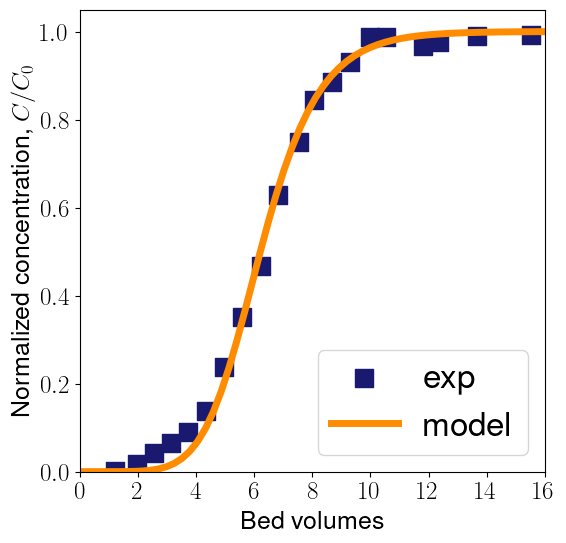

In [279]:
e_rp_qmax_fixed,_,_ = model_calibration(progress=True, plot=True, breakthrough=True, **parameters)

Run 1 of 3 : {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.37, 'rp': 0.000375}}


ab7d8d running: t: 6: : 60it [00:03, 19.94it/s]                          


RMSE (calibration) = 0.0261
SSR (calibration) = 0.0136
AIC (calibration) = -141.9
Run 2 of 3 : {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.37000370000000005, 'rp': 0.000375}}


ffd9c1 running: t: 6: : 60it [00:02, 20.74it/s]                          


RMSE (calibration) = 0.0261
SSR (calibration) = 0.0136
AIC (calibration) = -141.9
Average sensitivity (absolute): 0.40265713988768115
Run 3 of 3 : {'fixed_parameters': {'qmax': 0.32306305900406296}, 'calibrated_parameters': {'e': 0.37, 'rp': 0.00037500375000000004}}


d165c0 running: t: 6: : 60it [00:02, 22.05it/s]                          


RMSE (calibration) = 0.0261
SSR (calibration) = 0.0136
AIC (calibration) = -141.9
Average sensitivity (absolute): 0.0
 e: 0.63
 rp: 0.00


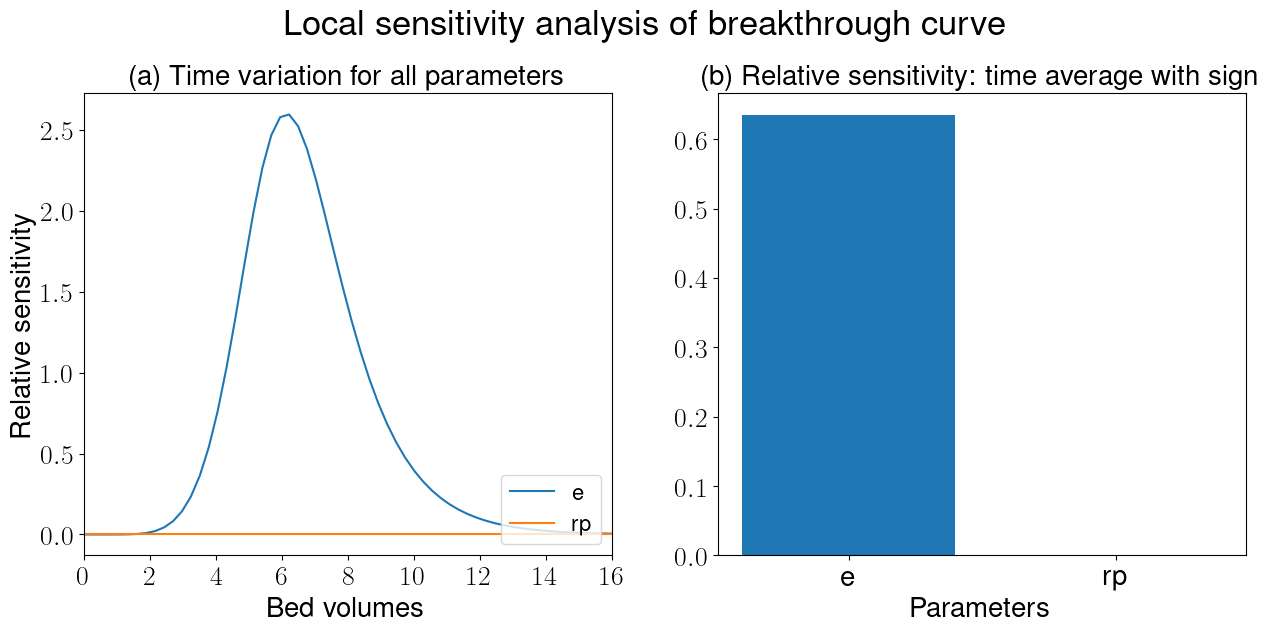

In [285]:
S = forward_sensitivity_calibration(model, dt=0.1, xi=1e-5, relative=False, plot=True, progress=True, **parameters)

In [284]:
print(S)

{'t': array([ 0.        ,  0.27027027,  0.54054054,  0.81081081,  1.08108108,
        1.35135135,  1.62162162,  1.89189189,  2.16216216,  2.43243243,
        2.7027027 ,  2.97297297,  3.24324324,  3.51351351,  3.78378378,
        4.05405405,  4.32432432,  4.59459459,  4.86486486,  5.13513514,
        5.40540541,  5.67567568,  5.94594595,  6.21621622,  6.48648649,
        6.75675676,  7.02702703,  7.2972973 ,  7.56756757,  7.83783784,
        8.10810811,  8.37837838,  8.64864865,  8.91891892,  9.18918919,
        9.45945946,  9.72972973, 10.        , 10.27027027, 10.54054054,
       10.81081081, 11.08108108, 11.35135135, 11.62162162, 11.89189189,
       12.16216216, 12.43243243, 12.7027027 , 12.97297297, 13.24324324,
       13.51351351, 13.78378378, 14.05405405, 14.32432432, 14.59459459,
       14.86486486, 15.13513514, 15.40540541, 15.67567568, 15.94594595,
       16.21621622]), 'e': array([ 0.00000000e+00, -4.50979546e-07, -3.50110874e-07,  4.88444069e-06,
        6.42700122e-05,  3.4

In [288]:
RMSE = e_rp_qmax_fixed['RMSE']
print("RMSE = ", RMSE)
SSR = e_rp_qmax_fixed['SSR']
print("SSR = ", SSR)
AIC = e_rp_qmax_fixed['AIC']
print("AIC = ", AIC)

names = [name for name in parameters['calibrated_parameters'].keys()]
Sint = [np.interp(texp1a, S['t'], S[name]) for name in names]

Smatrix = [S[name] for name in names]
# print("Sensitivity matrix = \n", Smatrix)

Np = len(names)
N = len(Cexp1a)

FIM = np.zeros((Np, Np))
for i in range(Np):
	for j in range(Np):
		FIM[i,j] = np.sum(Sint[i]*Sint[j])

FIM[:,1] = 1e-8
FIM[1,0] = 1e-8
print("FIM = \n", FIM)

covariance = np.linalg.inv(FIM) * SSR/(N-Np) # from the FIM
print("Covariance matrix: \n", covariance)

cond = np.linalg.cond(FIM)
print("Condition number: {:.0f}".format(cond)) # 1 = well conditioned, 1e6 = ill conditioned

from scipy import stats
t_estimator = stats.t.ppf((1+0.95)/2, N-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

# Calculate confidence intervals
for name in names:
	value = parameters['calibrated_parameters'][name]
	CI = t_estimator * np.sqrt(covariance[i,i])
	d = CI/value*100
	if value > 1e-3:
		print(f"CI {name:s} : {value:.3f} ± {CI:.4f} ({d:.1f}%)")
	else:
		print(f"CI {name:s} : {value:.3e} ± {CI:.4e} ({d:.1f}%)")


RMSE =  0.026075178672941287
SSR =  0.013598298856516242
AIC =  -141.8708570339495
FIM = 
 [[2.89917637e+01 1.00000000e-08]
 [1.00000000e-08 1.00000000e-08]]
Covariance matrix: 
 [[ 2.60577817e-05 -2.60577817e-05]
 [-2.60577817e-05  7.55461048e+04]]
Condition number: 2899176369
Student's t estimator = 2.101
CI e : 0.370 ± 577.4521 (156068.1%)
CI rp : 3.750e-04 ± 5.7745e+02 (153987230.4%)


#### qmax, rp, epsilon fixed

In [253]:
# Fix value for epsilon
e_fixed = e_lm_ls['params']['e']
print("e (calibrated) = ", e_fixed)

e (calibrated) =  0.34673557495870555


In [254]:
# Calibrate rp
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(qmax=0.291, rp=3.75e-4)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'qmax': 0.291, 'rp': 0.000375})])


In [256]:
qmax_rp_trf_cf_e_fixed = sequential_calibration(method='trf', algorithm='cf', tol=1e-4, **parameters)

Parameters to calibrate: ['qmax', 'rp']
Original values: [0.291    0.000375]
Method: Trust Region Reflective
Bounds: ([0.2328, 0.00030000000000000003], [0.34919999999999995, 0.00045])
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.291, 'rp': 0.000375}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2910000149011612, 'rp': 0.000375}}
Run 3: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.291, 'rp': 0.00037501490116119386}}
Run 4: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.290807325504907, 'rp': 0.000375}}
Run 5: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2908073404060682, 'rp': 0.000375}}
Run 6: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.290807325504907, 'rp': 0.00037501490116119386}}
Calibration finished.
Number 

LinAlgError: Singular matrix

Run 1 of 4 : {'e': 0.34673557495870555, 'qmax': 0.291, 'rp': 0.000375}


b97dac running: t: 6: : 60it [00:03, 19.63it/s]                          


RMSE (calibration) = 0.0233
SSR (calibration) = 0.0109
AIC (calibration) = -142.3
Run 2 of 4 : {'e': 0.3467390423144552, 'qmax': 0.291, 'rp': 0.000375}


efdc46 running: t: 6: : 60it [00:02, 21.65it/s]                          


RMSE (calibration) = 0.0233
SSR (calibration) = 0.0109
AIC (calibration) = -142.3
Run 3 of 4 : {'e': 0.34673557495870555, 'qmax': 0.29100291, 'rp': 0.000375}


5c144e running: t: 6: : 60it [00:02, 20.41it/s]                          


RMSE (calibration) = 0.0233
SSR (calibration) = 0.0109
AIC (calibration) = -142.3
Run 4 of 4 : {'e': 0.34673557495870555, 'qmax': 0.291, 'rp': 0.00037500375000000004}


02c2b2 running: t: 6: : 60it [00:02, 20.64it/s]                          


RMSE (calibration) = 0.0233
SSR (calibration) = 0.0109
AIC (calibration) = -142.3
 e: 0.93
 qmax: -1.45
 rp: 63.40


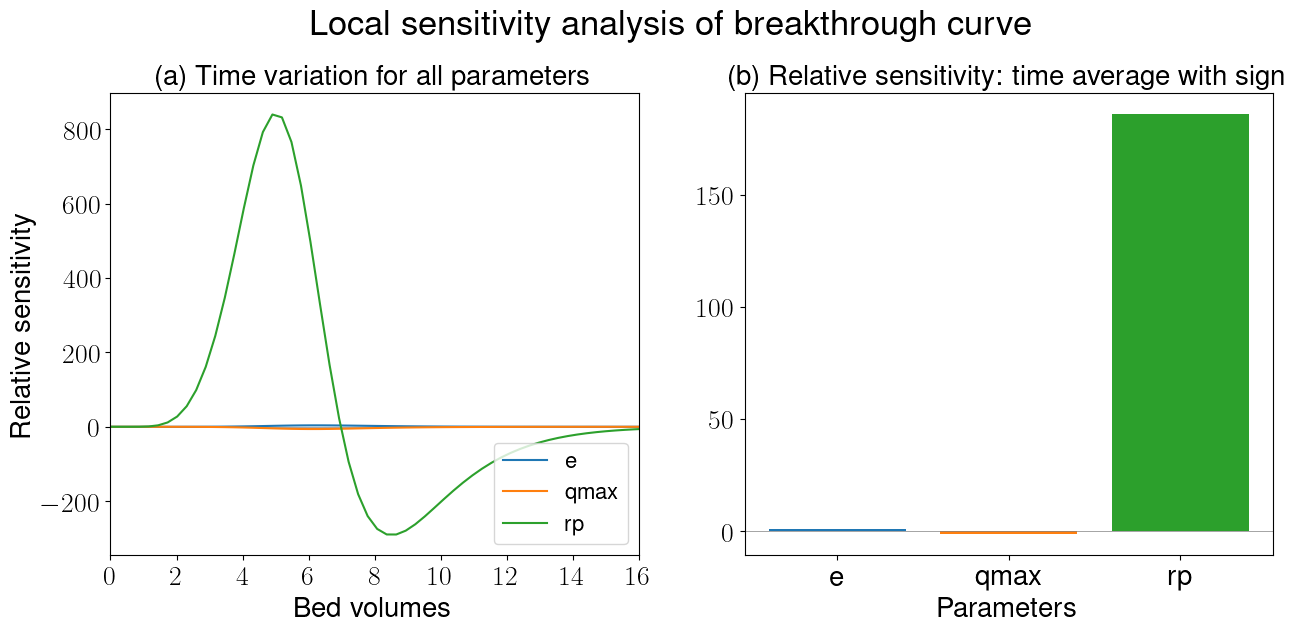

In [261]:
S = forward_sensitivity(model, dt=0.1, relative=False, plot=True, progress=True, e=e_fixed, qmax=0.291, rp=3.75e-4)

In [262]:
print(S)

{'t': array([ 0.        ,  0.28840421,  0.57680842,  0.86521263,  1.15361684,
        1.44202106,  1.73042527,  2.01882948,  2.30723369,  2.5956379 ,
        2.88404211,  3.17244632,  3.46085053,  3.74925475,  4.03765896,
        4.32606317,  4.61446738,  4.90287159,  5.1912758 ,  5.47968001,
        5.76808422,  6.05648844,  6.34489265,  6.63329686,  6.92170107,
        7.21010528,  7.49850949,  7.7869137 ,  8.07531791,  8.36372213,
        8.65212634,  8.94053055,  9.22893476,  9.51733897,  9.80574318,
       10.09414739, 10.3825516 , 10.67095582, 10.95936003, 11.24776424,
       11.53616845, 11.82457266, 12.11297687, 12.40138108, 12.68978529,
       12.97818951, 13.26659372, 13.55499793, 13.84340214, 14.13180635,
       14.42021056, 14.70861477, 14.99701898, 15.28542319, 15.57382741,
       15.86223162, 16.15063583, 16.43904004, 16.72744425, 17.01584846,
       17.30425267]), 'e': array([ 0.00000000e+00, -2.10801423e-06, -1.95558018e-06,  2.26353035e-05,
        3.39422245e-04,  1.9

d828ec running: t: 6: : 60it [00:02, 21.76it/s]                          


RMSE (calibration) = 0.0233
SSR (calibration) = 0.0109
AIC (calibration) = -146.3


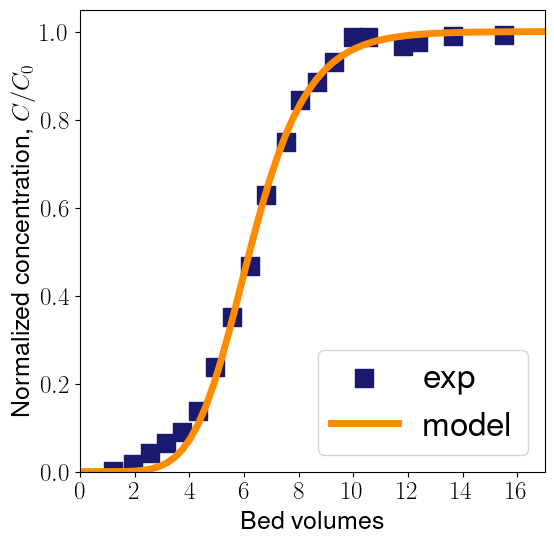

In [268]:
qmax_rp_trf_cf_e_fixed,_,_ = model_calibration(texp=texp1a, Cexp=Cexp1a, progress=True, breakthrough=True, **parameters)

In [271]:
RMSE = qmax_rp_trf_cf_e_fixed['RMSE']
print("RMSE = ", RMSE)
SSR = qmax_e_fixed['SSR']
print("SSR = ", SSR)
AIC = qmax_e_fixed['AIC']
print("AIC = ", AIC)

names = [name for name in parameters['calibrated_parameters'].keys()]
Sint = [np.interp(texp1a, S['t'], S[name]) for name in names]

Smatrix = [S[name] for name in names]
# print("Sensitivity matrix = \n", Smatrix)

Np = len(names)
N = len(Cexp1a)

FIM = np.zeros((Np, Np))
for i in range(Np):
	for j in range(Np):
		FIM[i,j] = np.sum(Sint[i]*Sint[j])

print("FIM = \n", FIM)

covariance = np.linalg.inv(FIM) * SSR/(N-Np) # from the FIM
print("Covariance matrix: \n", covariance)

cond = np.linalg.cond(FIM)
print("Condition number: {:.0f}".format(cond)) # 1 = well conditioned, 1e6 = ill conditioned

from scipy import stats
t_estimator = stats.t.ppf((1+0.95)/2, N-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

# Calculate confidence intervals
for name in names:
	value = parameters['calibrated_parameters'][name]
	CI = t_estimator * np.sqrt(covariance[i,i])
	d = CI/value*100
	if value > 1e-3:
		print(f"CI {name:s} : {value:.3f} ± {CI:.4f} ({d:.1f}%)")
	else:
		print(f"CI {name:s} : {value:.3e} ± {CI:.4e} ({d:.1f}%)")


RMSE =  0.023319119248140303
SSR =  0.010875626450179752
AIC =  -148.33926745212466
FIM = 
 [[ 1.65158936e+02 -9.94827609e+03]
 [-9.94827609e+03  2.51048390e+06]]
Covariance matrix: 
 [[4.80528075e-06 1.90418507e-08]
 [1.90418507e-08 3.16128320e-10]]
Condition number: 19967
Student's t estimator = 2.101
CI qmax : 0.291 ± 0.0000 (0.0%)
CI rp : 3.750e-04 ± 3.7354e-05 (10.0%)


### Np = 3

#### epsilon, qmax, rp

In [59]:
e_qmax_rp_lm_cf = calibration(method='lm', algorithm='cf', tol=1e-4, e=0.37, qmax=0.291, rp=3.75e-4)

Parameters to calibrate: ['e', 'qmax', 'rp']
Original values: [0.37     0.291    0.000375]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'qmax': 0.291, 'rp': 0.000375}
Run 2: {'e': 0.37, 'qmax': 0.291, 'rp': 0.000375}
Run 3: {'e': 0.37, 'qmax': 0.291, 'rp': 0.000375}
Run 4: {'e': 0.37000000551342965, 'qmax': 0.291, 'rp': 0.000375}
Run 5: {'e': 0.37, 'qmax': 0.2910000043362379, 'rp': 0.000375}
Run 6: {'e': 0.37, 'qmax': 0.291, 'rp': 0.00037500000558793545}
Run 7: {'e': 0.3984659803022208, 'qmax': 0.3675153396372446, 'rp': 0.0005114871010211972}
Run 8: {'e': 0.3984659862398266, 'qmax': 0.3675153396372446, 'rp': 0.0005114871010211972}
Run 9: {'e': 0.3984659803022208, 'qmax': 0.3675153451136499, 'rp': 0.0005114871010211972}
Run 10: {'e': 0.3984659803022208, 'qmax': 0.3675153396372446, 'rp': 0.0005114871086429489}
Run 11: {'e': 0.3118989592692735, 'qmax': 0.23716803678837867, 'rp': 0.0003886712599977184}
Run 12: {'e': 0.36696343622756333, 'qmax': 0.3210639734301534

In [391]:
e_qmax_rp_trf_ls = calibration(method='trf', algorithm='ls', tol=1e-4, e=0.37, qmax=0.291, rp=3.75e-4)

Parameters to calibrate: ['e', 'qmax', 'rp']
Original values: [0.37     0.291    0.000375]
Method: Trust Region Reflective
Bounds: ([0.296, 0.2328, 0.00030000000000000003], [0.444, 0.34919999999999995, 0.00045])
Algorithm: Least-squares
Run 1: {'e': 0.37, 'qmax': 0.291, 'rp': 0.000375}
Run 2: {'e': 0.3700000149011612, 'qmax': 0.291, 'rp': 0.000375}
Run 3: {'e': 0.37, 'qmax': 0.2910000149011612, 'rp': 0.000375}
Run 4: {'e': 0.37, 'qmax': 0.291, 'rp': 0.00037501490116119386}
Run 5: {'e': 0.3605807012401627, 'qmax': 0.29624104443515187, 'rp': 0.0004107471641829854}
Run 6: {'e': 0.3605807161413239, 'qmax': 0.29624104443515187, 'rp': 0.0004107471641829854}
Run 7: {'e': 0.3605807012401627, 'qmax': 0.29624105933631306, 'rp': 0.0004107471641829854}
Run 8: {'e': 0.3605807012401627, 'qmax': 0.29624104443515187, 'rp': 0.00041076206534417924}
Run 9: {'e': 0.3556853581771297, 'qmax': 0.2990897597751768, 'rp': 0.00041126291415496057}
Run 10: {'e': 0.3556853730782909, 'qmax': 0.2990897597751768, 'rp'

LinAlgError: Singular matrix

In [60]:
e_qmax_rp_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, e=0.37, qmax=0.291, rp=3.75e-4)

Parameters to calibrate: ['e', 'qmax', 'rp']
Original values: [0.37     0.291    0.000375]
Method: Trust Region Reflective
Bounds: ([0.296, 0.2328, 0.00030000000000000003], [0.444, 0.34919999999999995, 0.00045])
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'qmax': 0.291, 'rp': 0.000375}
Run 2: {'e': 0.3700000149011612, 'qmax': 0.291, 'rp': 0.000375}
Run 3: {'e': 0.37, 'qmax': 0.2910000149011612, 'rp': 0.000375}
Run 4: {'e': 0.37, 'qmax': 0.291, 'rp': 0.00037501490116119386}
Run 5: {'e': 0.3564340539906458, 'qmax': 0.3012997244814781, 'rp': 0.00042685484587760006}
Run 6: {'e': 0.356434068891807, 'qmax': 0.3012997244814781, 'rp': 0.00042685484587760006}
Run 7: {'e': 0.3564340539906458, 'qmax': 0.3012997393826393, 'rp': 0.00042685484587760006}
Run 8: {'e': 0.3564340539906458, 'qmax': 0.3012997244814781, 'rp': 0.0004268697470387939}
Run 9: {'e': 0.3542100968135505, 'qmax': 0.3034436106286703, 'rp': 0.00042265619912774065}
Run 10: {'e': 0.3542101117147117, 'qmax': 0.3034436106286703, 'rp': 0

#### epsilon, qmax, rho

In [63]:
e_qmax_rho_lm_cf = calibration(method='lm', algorithm='cf', tol=1e-4, e=0.37, qmax=0.291, rho=389)

Parameters to calibrate: ['e', 'qmax', 'rho']
Original values: [3.70e-01 2.91e-01 3.89e+02]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0}
Run 2: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0}
Run 3: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0}
Run 4: {'e': 0.37000000551342965, 'qmax': 0.291, 'rho': 389.0}
Run 5: {'e': 0.37, 'qmax': 0.2910000043362379, 'rho': 389.0}
Run 6: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0000057965517}
Run 7: {'e': 0.22863143893870475, 'qmax': 0.13477088430603437, 'rho': 389.0}
Run 8: {'e': 0.22863144234557867, 'qmax': 0.13477088430603437, 'rho': 389.0}
Run 9: {'e': 0.22863143893870475, 'qmax': 0.13477088631427706, 'rho': 389.0}
Run 10: {'e': 0.22863143893870475, 'qmax': 0.13477088430603437, 'rho': 389.0000057965517}
Run 11: {'e': 0.3000115325938169, 'qmax': 0.22671573384276927, 'rho': 389.0}
Run 12: {'e': 0.30001153706433714, 'qmax': 0.22671573384276927, 'rho': 389.0}
Run 13: {'e': 0.3000115325938169, 'qmax': 0.2267157

/Users/Daniel/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/minpack.py:833: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


Calibration finished.
Number of runs: 27
Calculating SSR, RMSE, AIC, BIC...
Np = 3, N = 20
SSR = 0.0085
RMSE = 0.0207
AIC (original) = -149.2
AIC (corrected) = -147.7
BIC = -146.2
Calculating FIM...
Run 1 of 4 : {'e': 0.3101445265344499, 'qmax': 0.24224112151735158, 'rho': 389.0}
Run 2 of 4 : {'e': 0.3101476279797153, 'qmax': 0.24224112151735158, 'rho': 389.0}
Run 3 of 4 : {'e': 0.3101445265344499, 'qmax': 0.24224354392856678, 'rho': 389.0}
Run 4 of 4 : {'e': 0.3101445265344499, 'qmax': 0.24224112151735158, 'rho': 389.00389}


LinAlgError: Singular matrix

In [61]:
e_qmax_rho_trf_ls = calibration(method='trf', algorithm='ls', tol=1e-4, e=0.37, qmax=0.291, rho=389)

Parameters to calibrate: ['e', 'qmax', 'rho']
Original values: [3.70e-01 2.91e-01 3.89e+02]
Method: Trust Region Reflective
Bounds: ([0.296, 0.2328, 311.20000000000005], [0.444, 0.34919999999999995, 466.79999999999995])
Algorithm: Least-squares
Run 1: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0}
Run 2: {'e': 0.3700000149011612, 'qmax': 0.291, 'rho': 389.0}
Run 3: {'e': 0.37, 'qmax': 0.2910000149011612, 'rho': 389.0}
Run 4: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0000057965517}
Run 5: {'e': 0.3614572612585531, 'qmax': 0.2959752069259142, 'rho': 389.0}
Run 6: {'e': 0.3614572761597143, 'qmax': 0.2959752069259142, 'rho': 389.0}
Run 7: {'e': 0.3614572612585531, 'qmax': 0.2959752218270754, 'rho': 389.0}
Run 8: {'e': 0.3614572612585531, 'qmax': 0.2959752069259142, 'rho': 389.0000057965517}
Calibration finished.
Number of runs: 8
Calculating SSR, RMSE, AIC, BIC...
Np = 3, N = 20
SSR = 0.0450
RMSE = 0.0474
AIC (original) = -116.0
AIC (corrected) = -114.5
BIC = -113.0
Calculating FIM...
Run 1 of 4 : {

LinAlgError: Singular matrix

In [62]:
e_qmax_rho_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, e=0.37, qmax=0.291, rho=389)

Parameters to calibrate: ['e', 'qmax', 'rho']
Original values: [3.70e-01 2.91e-01 3.89e+02]
Method: Trust Region Reflective
Bounds: ([0.296, 0.2328, 311.20000000000005], [0.444, 0.34919999999999995, 466.79999999999995])
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0}
Run 2: {'e': 0.3700000149011612, 'qmax': 0.291, 'rho': 389.0}
Run 3: {'e': 0.37, 'qmax': 0.2910000149011612, 'rho': 389.0}
Run 4: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0000057965517}
Run 5: {'e': 0.35657559525091165, 'qmax': 0.29881824556372905, 'rho': 389.0}
Run 6: {'e': 0.35657561015207284, 'qmax': 0.29881824556372905, 'rho': 389.0}
Run 7: {'e': 0.35657559525091165, 'qmax': 0.29881826046489024, 'rho': 389.0}
Run 8: {'e': 0.35657559525091165, 'qmax': 0.29881824556372905, 'rho': 389.0000057965517}
Calibration finished.
Number of runs: 8
Calculating SSR, RMSE, AIC, BIC...
Np = 3, N = 20
SSR = 0.0164
RMSE = 0.0286
AIC (original) = -136.2
AIC (corrected) = -134.7
BIC = -133.2
Calculating FIM...
Run 1 

LinAlgError: Singular matrix

### Np = 4

In [66]:
e_qmax_rho_rp_lm_cf = calibration(method='lm', algorithm='cf', tol=1e-8, e=0.37, qmax=0.291, rho=389, rp=3.75e-4)

Parameters to calibrate: ['e', 'qmax', 'rho', 'rp']
Original values: [3.70e-01 2.91e-01 3.89e+02 3.75e-04]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0, 'rp': 0.000375}
Run 2: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0, 'rp': 0.000375}
Run 3: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0, 'rp': 0.000375}
Run 4: {'e': 0.37000000551342965, 'qmax': 0.291, 'rho': 389.0, 'rp': 0.000375}
Run 5: {'e': 0.37, 'qmax': 0.2910000043362379, 'rho': 389.0, 'rp': 0.000375}
Run 6: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0000057965517, 'rp': 0.000375}
Run 7: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0, 'rp': 0.00037500000558793545}
Run 8: {'e': 0.3984659803022208, 'qmax': 0.3675153396372446, 'rho': 389.0, 'rp': 0.0005114871010211972}
Run 9: {'e': 0.3984659862398266, 'qmax': 0.3675153396372446, 'rho': 389.0, 'rp': 0.0005114871010211972}
Run 10: {'e': 0.3984659803022208, 'qmax': 0.3675153451136499, 'rho': 389.0, 'rp': 0.0005114871010211972}
Run 11: {'e': 0.398465980

/Users/Daniel/opt/anaconda3/lib/python3.8/site-packages/scipy/optimize/minpack.py:833: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


Calibration finished.
Number of runs: 54
Calculating SSR, RMSE, AIC, BIC...
Np = 4, N = 20
SSR = 0.0085
RMSE = 0.0206
AIC (original) = -147.3
AIC (corrected) = -144.7
BIC = -143.4
Calculating FIM...
Run 1 of 5 : {'e': 0.3355239865938486, 'qmax': 0.2770713161083953, 'rho': 389.0, 'rp': 0.00040132321294627073}
Run 2 of 5 : {'e': 0.3355273418337145, 'qmax': 0.2770713161083953, 'rho': 389.0, 'rp': 0.00040132321294627073}
Run 3 of 5 : {'e': 0.3355239865938486, 'qmax': 0.27707408682155643, 'rho': 389.0, 'rp': 0.00040132321294627073}
Run 4 of 5 : {'e': 0.3355239865938486, 'qmax': 0.2770713161083953, 'rho': 389.00389, 'rp': 0.00040132321294627073}
Run 5 of 5 : {'e': 0.3355239865938486, 'qmax': 0.2770713161083953, 'rho': 389.0, 'rp': 0.0004013272261784002}


LinAlgError: Singular matrix

In [64]:
e_qmax_rho_rp_trf_ls = calibration(method='trf', algorithm='ls', tol=1e-8, e=0.37, qmax=0.291, rho=389, rp=3.75e-4)

Parameters to calibrate: ['e', 'qmax', 'rho', 'rp']
Original values: [3.70e-01 2.91e-01 3.89e+02 3.75e-04]
Method: Trust Region Reflective
Bounds: ([0.296, 0.2328, 311.20000000000005, 0.00030000000000000003], [0.444, 0.34919999999999995, 466.79999999999995, 0.00045])
Algorithm: Least-squares
Run 1: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0, 'rp': 0.000375}
Run 2: {'e': 0.3700000149011612, 'qmax': 0.291, 'rho': 389.0, 'rp': 0.000375}
Run 3: {'e': 0.37, 'qmax': 0.2910000149011612, 'rho': 389.0, 'rp': 0.000375}
Run 4: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0000057965517, 'rp': 0.000375}
Run 5: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0, 'rp': 0.00037501490116119386}
Run 6: {'e': 0.363988439770786, 'qmax': 0.29450107348394344, 'rho': 389.0, 'rp': 0.000300375}
Run 7: {'e': 0.3639884546719472, 'qmax': 0.29450107348394344, 'rho': 389.0, 'rp': 0.000300375}
Run 8: {'e': 0.363988439770786, 'qmax': 0.29450108838510464, 'rho': 389.0, 'rp': 0.000300375}
Run 9: {'e': 0.363988439770786, 'qmax': 0.294501073

LinAlgError: Singular matrix

In [65]:
e_qmax_rho_rp_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-8, e=0.37, qmax=0.291, rho=389, rp=3.75e-4)

Parameters to calibrate: ['e', 'qmax', 'rho', 'rp']
Original values: [3.70e-01 2.91e-01 3.89e+02 3.75e-04]
Method: Trust Region Reflective
Bounds: ([0.296, 0.2328, 311.20000000000005, 0.00030000000000000003], [0.444, 0.34919999999999995, 466.79999999999995, 0.00045])
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0, 'rp': 0.000375}
Run 2: {'e': 0.3700000149011612, 'qmax': 0.291, 'rho': 389.0, 'rp': 0.000375}
Run 3: {'e': 0.37, 'qmax': 0.2910000149011612, 'rho': 389.0, 'rp': 0.000375}
Run 4: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0000057965517, 'rp': 0.000375}
Run 5: {'e': 0.37, 'qmax': 0.291, 'rho': 389.0, 'rp': 0.00037501490116119386}
Run 6: {'e': 0.35555740384134593, 'qmax': 0.29877748519138414, 'rho': 389.0, 'rp': 0.000449625}
Run 7: {'e': 0.3555574187425071, 'qmax': 0.29877748519138414, 'rho': 389.0, 'rp': 0.000449625}
Run 8: {'e': 0.35555740384134593, 'qmax': 0.29877750009254533, 'rho': 389.0, 'rp': 0.000449625}
Run 9: {'e': 0.35555740384134593, 'qmax': 0.298

LinAlgError: Singular matrix

## Uncertainty analysis

### Sampling

In [25]:
from SALib.sample import saltelli
from SALib.analyze import sobol
from SALib import ProblemSpec

def uncertainty_sampling(N, calc_second_order=False, generate_new=False, **parameters):

    # Define no. of parameters
    Np = len(parameters.keys())
    print("No. of parameters =", Np)

    # Define no. of samples
    if calc_second_order:
        print("No. of samples =", N*(2*Np + 2))
    else:
        print("No. of samples =", N*(  Np + 2))

    # Names of the parameters
    names = [parameters[name][0] for name in parameters.keys()]
    joined_names = "-".join(names)

    # Define mean and std for each parameter
    bounds = [(parameters[name][1], parameters[name][2]) for name in parameters.keys()]

    # Define problem spec
    sp = ProblemSpec({
        'num_vars': Np,
        'names': names,
        'bounds': bounds, 
        'outputs': ['Y'],
        'dists': ['norm' for i in range(Np)]
    })

    if generate_new==False:
        try:
            print("Reading existing sampling...")
            pars = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv")
            sp.set_samples(pars.iloc[:,-Np:].to_numpy())
            return sp
        except:
            print("File not found. Generate new sampling first.")
            return sp
        

    # Generate samples
    print("Generating new sampling...")
    sp.sample_sobol(N=N, calc_second_order=calc_second_order) # type: ignore

    params = sp.samples
    params.shape # type: ignore

    # Store in disk
    sampling = pd.DataFrame(params)
    labels = dict(zip(range(Np), names))
    sampling.rename(columns=labels, inplace=True)
    sampling.to_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv")

    return sp

# Test the function
N = 2**0 # file should not exist
rp = 3.75e-4
e = 0.37
qmax = 0.291

sp = uncertainty_sampling(N=N,                          # no. of samples
              calc_second_order=False,      # calculate second order effects
              generate_new=False,           # generate new sampling

                                            # parameters = (name, value, uncertainty)
              rp    =('$r_p$',          rp,        1.2),
              e     =('$\\varepsilon$', e,         1.2), 
              qmax  =('$q_{max}$',      qmax,      1.2), 
              )

# Generate Monte Carlo sampling for parameters
N = 2**1

sp = uncertainty_sampling(N=N,                          # no. of samples
              calc_second_order=False,      # calculate second order effects
              generate_new=True,           # generate new sampling

                                            # parameters = (name, value, uncertainty)
              rp    =('$r_p$',          rp,        1.2),
              e     =('$\\varepsilon$', e,         1.2), 
              qmax  =('$q_{max}$',      qmax,      1.2), 
              )

# Read file
Np = sp['num_vars']
pars = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}.csv")
print(sp.samples)

# Load sampling for an existing file withouth generating new sampling
sp = uncertainty_sampling(N=N,                          # no. of samples
              calc_second_order=False,      # calculate second order effects
              generate_new=False,           # generate new sampling

                                            # parameters = (name, value, uncertainty)
              rp    =('$r_p$',          rp,        1.2),
              e     =('$\\varepsilon$', e,         1.2), 
              qmax  =('$q_{max}$',      qmax,      1.2), 
              )

print(sp.samples)



No. of parameters = 3
No. of samples = 5
Reading existing sampling...
File not found. Generate new sampling first.
No. of parameters = 3
No. of samples = 10
Generating new sampling...
[[ 0.14357566  1.12147479  1.42691906]
 [ 0.50687036  1.12147479  1.42691906]
 [ 0.14357566  1.91584769  1.42691906]
 [ 0.14357566  1.12147479  1.83974008]
 [ 0.50687036  1.91584769  1.83974008]
 [-1.0500315  -1.31027373 -0.77689821]
 [-0.30623957 -1.31027373 -0.77689821]
 [-1.0500315  -0.89633647 -0.77689821]
 [-1.0500315  -1.31027373 -0.10544193]
 [-0.30623957 -0.89633647 -0.10544193]]
No. of parameters = 3
No. of samples = 10
Reading existing sampling...
[[ 0.14357566  1.12147479  1.42691906]
 [ 0.50687036  1.12147479  1.42691906]
 [ 0.14357566  1.91584769  1.42691906]
 [ 0.14357566  1.12147479  1.83974008]
 [ 0.50687036  1.91584769  1.83974008]
 [-1.0500315  -1.31027373 -0.77689821]
 [-0.30623957 -1.31027373 -0.77689821]
 [-1.0500315  -0.89633647 -0.77689821]
 [-1.0500315  -1.31027373 -0.10544193]
 [-

### Model evaluation

In [26]:
def evaluation_uncertainty(pars, 
               Nx=100, dt=0.1, tmax=6., progress=False, **parameters):

    # Choose simulation parameters
    Nx    = Nx
    dt    = dt
    tmax  = tmax

    # Create simulation matrices to store data
    Y = np.zeros([pars.shape[0], int(np.ceil(tmax/dt) + 1)]) # no. of samples x no. of time points
    T = np.zeros((pars.shape[0], int(np.ceil(tmax/dt) + 1))) # no. of samples x no. of time points
    BT = np.zeros(pars.shape[0]) # no. of samples

    # Run model
    for i in range(pars.shape[0]): # type: ignore
        parameters = dict([(name, value) for name, value in zip(pars.keys()[1:], pars.iloc[i,1:].to_numpy())]) # type: ignore
        joined_names = "-".join(pars.keys()[1:])
        
        print(f'Run {i+1:d} of {pars.shape[0]}') # type: ignore
        # print(f'qmax = {qmax:.3f}, Kl = {Kl:.2f}, Q = {Q:.3e}, e = {e:.2f}, rp = {rp:.3e}, Dp = {Dp:.2e}, D = {D:.3f}, L = {L:.2f}, rho_p = {rho_p:.3f}, C0 = {C0:.2f}')

        results, params, container = model(Nx=Nx, dt=dt, tmax=tmax, 
                                           isotherm = 'Langmuir',
                                           profiles = False, 
                                           breakthrough = False,
                                           progress=progress,
                                           **parameters
                                           )
        
        # Store results
        Y[i, :] = results['BC']     # breakthrough curve
        T[i, :] = results['BV']     # time in bed volumes

        # Calculate breakthrough times
        CBT = results['BC'][np.where(results['BC'] >= 0.1)]
        BT[i] = np.min(results['BV'][np.where(results['BC'])])
        if progress:
            print("Breakthrough: C= {:.4f} at {:.2f} BV".format(np.min(CBT), BT[i]))

        # Store data to disk
        simulations = pd.DataFrame(Y)
        simulations.to_csv(f"simulations-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv")
        times = pd.DataFrame(T)
        times.to_csv(f"times-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv")
        breakthrough = pd.DataFrame(BT)
        breakthrough.to_csv(f"breakthrough-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv")

    return T, Y, BT

# Test the function

# T, Y, BT = evaluation(pars, tmax=4)

### Np = 1 (qmax)

In [27]:
qmax_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, qmax=0.291)

Experimental data for calibration: exp1a
Parameters to calibrate: ['qmax']
Original values: [0.291]
Method: Trust Region Reflective
Bounds: ([0.2328], [0.34919999999999995])
Algorithm: Curve-fitting
Run 1: {'qmax': 0.291}
Run 2: {'qmax': 0.2910000149011612}
Run 3: {'qmax': 0.310883000950662}
Run 4: {'qmax': 0.3108830158518232}
Run 5: {'qmax': 0.3197282123121969}
Run 6: {'qmax': 0.3197282272133581}
Run 7: {'qmax': 0.3225673660996185}
Run 8: {'qmax': 0.3225673810007797}
Run 9: {'qmax': 0.3230260798331228}
Run 10: {'qmax': 0.323026094734284}
Run 11: {'qmax': 0.3230611794850362}
Run 12: {'qmax': 0.3230611943861974}
Calibration finished.
Number of runs: 12
Calculating SSR, RMSE, AIC, BIC...
Np = 1, N = 20
SSR = 0.0136
RMSE = 0.0261
AIC (original) = -143.9
AIC (corrected) = -143.6
BIC = -142.9
Calculating FIM...
Run 1 of 2 : {'qmax': 0.3230611794850362}
Run 2 of 2 : {'qmax': 0.32306441009683107}
FIM = 
 [[152.1152219]]
SSR =  0.013598299568175744
Calibrated parameters: {'qmax': 0.32306117948

In [28]:
qmax = qmax_trf_cf['params']['qmax']

calibrated_parameters = qmax_trf_cf['param_calib']

In [29]:
names = [name for name in calibrated_parameters.keys()]

Np = len(calibrated_parameters)
N = len(Cexp1a)

FIM = qmax_trf_cf['FIM']
SSR = qmax_trf_cf['SSR']
covariance = qmax_trf_cf['covariance']

print("FIM = \n", FIM)
print("SSR = ", SSR)
print("Calibrated parameters:", calibrated_parameters)
print("Covariance matrix: \n", covariance)
print("Condition number: {:.0f}".format(np.linalg.cond(covariance))) # 1 = well conditioned, 1e6 = ill conditioned
print("Standard deviation: \n", np.sqrt(np.diag(covariance))) # standard deviation of the parameters

# 95% confidence intervals
from scipy import stats
t_estimator = stats.t.ppf((1+0.95)/2, N-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

# Calculate confidence intervals
for parameter in calibrated_parameters.keys():
	CI = qmax_trf_cf['CI']
	d = qmax_trf_cf['d']
	if calibrated_parameters[parameter] > 1e-3:
		print(f"CI {parameter:s} : {calibrated_parameters[parameter]:.3f} ± {CI[parameter]:.4f} ({d[parameter]:.1f}%)")
	else:
		print(f"CI {parameter:s} : {calibrated_parameters[parameter]:.3e} ± {CI[parameter]:.4e} ({d[parameter]:.1f}%)")

# Calculate correlation coefficients
if Np > 1:
	for i in range(Np-1):
		for j in range(i+1, Np):
			r = qmax_trf_cf['r']
			print(f"Correlation {names[i]:s}-{names[j]:s} = {r[i,j]:.4f}")

FIM = 
 [[152.1152219]]
SSR =  0.013598299568175744
Calibrated parameters: {'qmax': 0.3230611794850362}
Covariance matrix: 
 [[4.70498592e-06]]
Condition number: 1
Standard deviation: 
 [0.0021691]
Student's t estimator = 2.093
CI qmax : 0.323 ± 0.0045 (1.4%)


In [30]:
qmax_trf_cf['CI']

{'qmax': 0.004539974187323189}

In [31]:
names

['qmax']

In [286]:
# Generate Monte Carlo sampling for parameters
N = 2**1

sp = uncertainty_sampling(N=N,                          # no. of samples
              calc_second_order=False,      # calculate second order effects
              generate_new=True,           # generate new sampling

                                            # parameters = (name, value, uncertainty)
              qmax    =('qmax', qmax,         qmax_trf_cf['CI']['qmax']/2), 
)

print(sp.samples.shape)

No. of parameters = 1
No. of samples = 6
Generating new sampling...
(6, 1)


N = 6
qmax (mean ± 2*std) = 0.323 ± 2*0.0002 (100.0%)


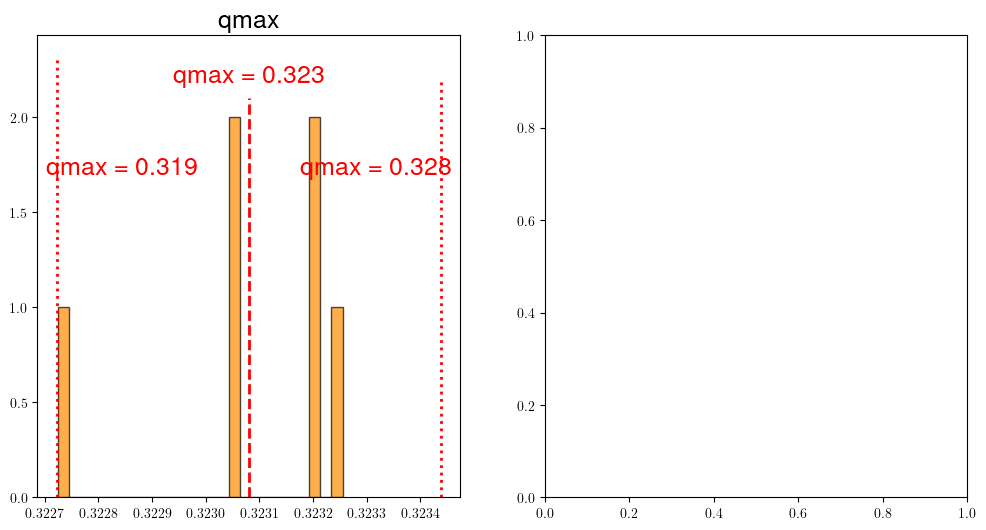

In [290]:
# Read file
N = 2**1
Np = 1
print("N =", N*(Np+2))
names = "qmax"
pars = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{names:s}.csv")

# Verify sampling
results = qmax_trf_cf

inside_qmax = len(pars['qmax'][(pars['qmax'] >= np.mean(pars['qmax']) - 2*np.std(pars['qmax']) ) & (pars['qmax'] <= np.mean(pars['qmax']) + 2*np.std(pars['qmax']))])
total_points = len(pars)
percentage_inside_qmax = (inside_qmax / total_points) * 100

print("qmax (mean ± 2*std) = {:.3f} ± 2*{:.4f} ({:.1f}%)".format(np.mean(pars['qmax']), np.std(pars['qmax']), percentage_inside_qmax))

# Create histograms

size = 6
nbins = 25
fig, ax = plt.subplots(1, Np+1, figsize=(2*size,size))

for parameter in calibrated_parameters.keys():
	i = list(pars.keys()).index(parameter)-1
	ax[i].hist(pars[parameter], bins=nbins, color='darkorange', edgecolor='black', alpha=0.7)
	ax[i].set_title(f'{parameter}', fontsize=3*size)
	ax[i].vlines(np.mean(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dashed', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])+2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])-2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].text(0.5, 0.9, f"{parameter:s} = {calibrated_parameters[parameter]:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.8, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]+2*results['CI'][parameter]/2:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.2, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]-2*results['CI'][parameter]/2:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')

In [291]:
T, Y, BT = evaluation_uncertainty(pars, tmax=6.)

Run 1 of 6
Run 2 of 6
Run 3 of 6
Run 4 of 6
Run 5 of 6
Run 6 of 6


In [292]:
# Read data
# Np = 2
# N = 2**6
tmax = 6.
dt = 0.1

pars1 = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}.csv").iloc[:, 1:].to_numpy()
sims1 = pd.read_csv(f"simulations-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv").iloc[:, 1:].to_numpy()
time1 = pd.read_csv(f"times-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv").iloc[:, 1:].to_numpy()
breakthrough1 = pd.read_csv(f"breakthrough-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv").iloc[:, 1:].to_numpy()

### Np = 2 (qmax, rp)

In [32]:
qmax_rp_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, qmax=0.291, rp=3.75e-4)

Experimental data for calibration: exp1a
Parameters to calibrate: ['qmax', 'rp']
Original values: [0.291    0.000375]
Method: Trust Region Reflective
Bounds: ([0.2328, 0.00030000000000000003], [0.34919999999999995, 0.00045])
Algorithm: Curve-fitting
Run 1: {'qmax': 0.291, 'rp': 0.000375}
Run 2: {'qmax': 0.2910000149011612, 'rp': 0.000375}
Run 3: {'qmax': 0.291, 'rp': 0.00037501490116119386}
Run 4: {'qmax': 0.31249965372449634, 'rp': 0.00041319251972999314}
Run 5: {'qmax': 0.31249966862565753, 'rp': 0.00041319251972999314}
Run 6: {'qmax': 0.31249965372449634, 'rp': 0.000413207420891187}
Run 7: {'qmax': 0.32237465857189107, 'rp': 0.00042454427907802713}
Run 8: {'qmax': 0.32237467347305226, 'rp': 0.00042454427907802713}
Run 9: {'qmax': 0.32237465857189107, 'rp': 0.000424559180239221}
Run 10: {'qmax': 0.32577618490526083, 'rp': 0.0004309291459356531}
Run 11: {'qmax': 0.32577619980642203, 'rp': 0.0004309291459356531}
Run 12: {'qmax': 0.32577618490526083, 'rp': 0.00043094404709684693}
Run 13

In [37]:
qmax = qmax_rp_trf_cf['params']['qmax']
rp = qmax_rp_trf_cf['params']['rp']

calibrated_parameters = qmax_rp_trf_cf['param_calib']
print(calibrated_parameters)

{'qmax': 0.32620940807640886, 'rp': 0.000431546945091672}


In [38]:
names = [name for name in calibrated_parameters.keys()]

Np = len(calibrated_parameters)
N = len(Cexp1a)

FIM = qmax_rp_trf_cf['FIM']
SSR = qmax_rp_trf_cf['SSR']
covariance = qmax_rp_trf_cf['covariance']

print("FIM = \n", FIM)
print("SSR = ", SSR)
print("Calibrated parameters:", calibrated_parameters)
print("Covariance matrix: \n", covariance)
print("Condition number: {:.0f}".format(np.linalg.cond(covariance))) # 1 = well conditioned, 1e6 = ill conditioned
print("Standard deviation: \n", np.sqrt(np.diag(covariance))) # standard deviation of the parameters

# 95% confidence intervals
from scipy import stats
t_estimator = stats.t.ppf((1+0.95)/2, N-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

# Calculate confidence intervals
for parameter in calibrated_parameters.keys():
	CI = qmax_rp_trf_cf['CI']
	d = qmax_rp_trf_cf['d']
	if calibrated_parameters[parameter] > 1e-3:
		print(f"CI {parameter:s} : {calibrated_parameters[parameter]:.3f} ± {CI[parameter]:.4f} ({d[parameter]:.1f}%)")
	else:
		print(f"CI {parameter:s} : {calibrated_parameters[parameter]:.3e} ± {CI[parameter]:.4e} ({d[parameter]:.1f}%)")

# Calculate correlation coefficients
if Np > 1:
	for i in range(Np-1):
		for j in range(i+1, Np):
			r = qmax_rp_trf_cf['r']
			print(f"Correlation {names[i]:s}-{names[j]:s} = {r[i,j]:.4f}")

FIM = 
 [[ 1.34781607e+02 -8.61551551e+03]
 [-8.61551551e+03  2.15247680e+06]]
SSR =  0.008492807191656099
Calibrated parameters: {'qmax': 0.32620940807640886, 'rp': 0.000431546945091672}
Covariance matrix: 
 [[4.70425004e-06 1.88292572e-08]
 [1.88292572e-08 2.94565953e-10]]
Condition number: 21462
Standard deviation: 
 [2.16892832e-03 1.71629238e-05]
Student's t estimator = 2.101
CI qmax : 0.326 ± 0.0046 (1.4%)
CI rp : 4.315e-04 ± 3.6058e-05 (8.4%)
Correlation qmax-rp = 0.5058


In [39]:
qmax_rp_trf_cf['CI']

{'qmax': 0.004556749304087431, 'rp': 3.6057964847742335e-05}

In [54]:
# Generate Monte Carlo sampling for parameters
N = 2**5

sp = uncertainty_sampling(N=N,                          # no. of samples
              calc_second_order=False,      # calculate second order effects
              generate_new=False,           # generate new sampling

                                            # parameters = (name, value, uncertainty)
              qmax    =('qmax', qmax,         qmax_rp_trf_cf['CI']['qmax']/2), 
              rp  =('rp',      	rp,      qmax_rp_trf_cf['CI']['rp']/2), 
)

print(sp.samples.shape)

No. of parameters = 2
No. of samples = 128
Reading existing sampling...
(128, 2)


N = 128
rp (mean ± 2*std) = 4.318e-04 ± 2*1.779e-05 (93.8%)
qmax (mean ± 2*std) = 0.326 ± 2*0.0022 (98.4%)


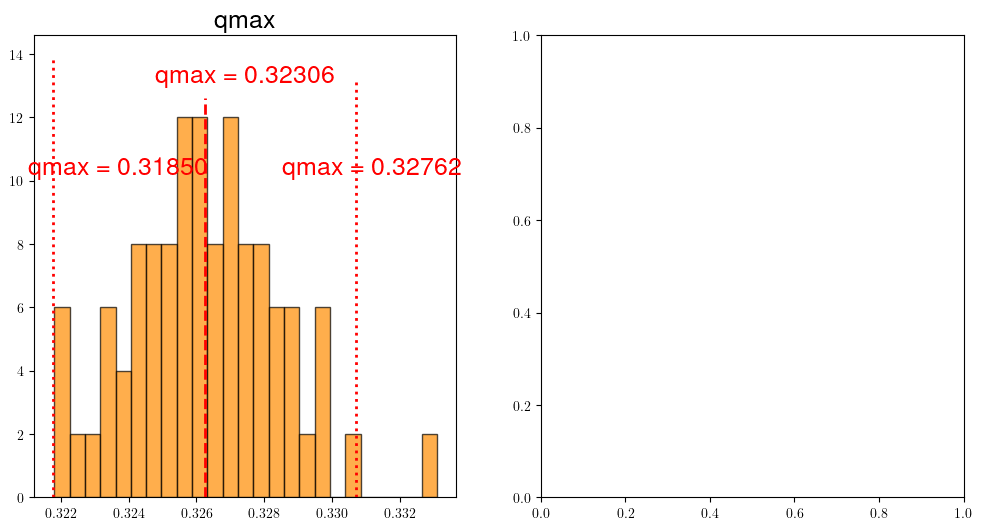

In [55]:
# Read file
Np = 2
# N = 2**6
print("N =", N*(Np+2))
joined_names = "qmax-rp"
pars = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv")

# Verify sampling
results = qmax_rp_trf_cf

inside_qmax = len(pars['qmax'][(pars['qmax'] >= np.mean(pars['qmax']) - 2*np.std(pars['qmax']) ) & (pars['qmax'] <= np.mean(pars['qmax']) + 2*np.std(pars['qmax']))])
inside_rp = len(pars['rp'][(pars['rp'] >= np.mean(pars['rp']) - 2*np.std(pars['rp']) ) & (pars['rp'] <= np.mean(pars['rp']) + 2*np.std(pars['rp']) )])
total_points = len(pars)
percentage_inside_qmax = (inside_qmax / total_points) * 100
percentage_inside_rp = (inside_rp / total_points) * 100

print("rp (mean ± 2*std) = {:.3e} ± 2*{:.3e} ({:.1f}%)".format(np.mean(pars['rp']), np.std(pars['rp']), percentage_inside_rp))
print("qmax (mean ± 2*std) = {:.3f} ± 2*{:.4f} ({:.1f}%)".format(np.mean(pars['qmax']), np.std(pars['qmax']), percentage_inside_qmax))

# Create histograms

size = 6
nbins = 25
fig, ax = plt.subplots(1, Np, figsize=(Np*size,size))

for parameter in calibrated_parameters.keys():
	i = list(pars.keys()).index(parameter)-1
	ax[i].hist(pars[parameter], bins=nbins, color='darkorange', edgecolor='black', alpha=0.7)
	ax[i].set_title(f'{parameter}', fontsize=3*size)
	ax[i].vlines(np.mean(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dashed', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])+2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])-2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)

	ax[i].text(0.5, 0.9, f"{parameter:s} = {calibrated_parameters[parameter]:.5f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.8, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]+2*results['CI'][parameter]/2:.5f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.2, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]-2*results['CI'][parameter]/2:.5f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')

In [714]:
# Run only to generate new model simulations
T, Y, BT = evaluation_uncertainty(pars, tmax=6.)

Run 1 of 128
Run 2 of 128
Run 3 of 128
Run 4 of 128
Run 5 of 128
Run 6 of 128
Run 7 of 128
Run 8 of 128
Run 9 of 128
Run 10 of 128
Run 11 of 128
Run 12 of 128
Run 13 of 128
Run 14 of 128
Run 15 of 128
Run 16 of 128
Run 17 of 128
Run 18 of 128
Run 19 of 128
Run 20 of 128
Run 21 of 128
Run 22 of 128
Run 23 of 128
Run 24 of 128
Run 25 of 128
Run 26 of 128
Run 27 of 128
Run 28 of 128
Run 29 of 128
Run 30 of 128
Run 31 of 128
Run 32 of 128
Run 33 of 128
Run 34 of 128
Run 35 of 128
Run 36 of 128
Run 37 of 128
Run 38 of 128
Run 39 of 128
Run 40 of 128
Run 41 of 128
Run 42 of 128
Run 43 of 128
Run 44 of 128
Run 45 of 128
Run 46 of 128
Run 47 of 128
Run 48 of 128
Run 49 of 128
Run 50 of 128
Run 51 of 128
Run 52 of 128
Run 53 of 128
Run 54 of 128
Run 55 of 128
Run 56 of 128
Run 57 of 128
Run 58 of 128
Run 59 of 128
Run 60 of 128
Run 61 of 128
Run 62 of 128
Run 63 of 128
Run 64 of 128
Run 65 of 128
Run 66 of 128
Run 67 of 128
Run 68 of 128
Run 69 of 128
Run 70 of 128
Run 71 of 128
Run 72 of 128
R

In [56]:
# Read data
# Np = 2
# N = 2**6
tmax = 6.
dt = 0.1

pars1 = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
sims1 = pd.read_csv(f"simulations-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
time1 = pd.read_csv(f"times-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
# breakthrough1 = pd.read_csv(f"breakthrough-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()

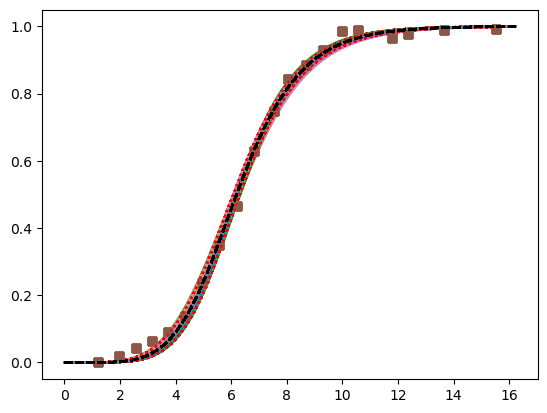

In [43]:
index = pars1.shape[0]
prediction_interval = 95

for i in range(0, index):
    plt.plot(time1[i,:], sims1[i,:])
    plt.plot(texp1a, Cexp1a, 's')
    # # print(sims3[i])
    plt.plot(time1[0], np.percentile(sims1, 50, axis=0), 'k--',zorder=10)
    plt.plot(time1[0], np.percentile(sims1[np.where(sims1[:,-1] >= 0.0)[0],:], 50 - prediction_interval/2., axis=0), 'r:')
    plt.plot(time1[0], np.percentile(sims1[np.where(sims1[:,-1] >= 0.0)[0],:], 50 + prediction_interval/2., axis=0), 'r:')

    # plt.plot(BV_calibrated2, C_calibration_model2, markevery=2, color='green', linestyle='-', linewidth=2.5, label=f'calibrated ($N_p = 2$)')
    
    # tc = np.argmax(time2[i,:] >= 10.)
    # # print(time3[i,tc])
    # if sims2[i,tc] <= 0.1: print(i, tc, sims2[i,tc])
    # if i == index+1 : break

### Np = 2 (e, qmax)

In [33]:
e_qmax_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, e=0.35, qmax=0.291)

Experimental data for calibration: exp1a
Parameters to calibrate: ['e', 'qmax']
Original values: [0.35  0.291]
Method: Trust Region Reflective
Bounds: ([0.27999999999999997, 0.2328], [0.42, 0.34919999999999995])
Algorithm: Curve-fitting
Run 1: {'e': 0.35, 'qmax': 0.291}
Run 2: {'e': 0.35000001490116117, 'qmax': 0.291}
Run 3: {'e': 0.35, 'qmax': 0.2910000149011612}
Run 4: {'e': 0.3467462643459307, 'qmax': 0.2907067775918434}
Run 5: {'e': 0.3467462792470919, 'qmax': 0.2907067775918434}
Run 6: {'e': 0.3467462643459307, 'qmax': 0.2907067924930046}
Run 7: {'e': 0.32964892388566147, 'qmax': 0.2675745299411775}
Run 8: {'e': 0.32964893878682267, 'qmax': 0.2675745299411775}
Run 9: {'e': 0.32964892388566147, 'qmax': 0.26757454484233867}
Run 10: {'e': 0.3231616936601999, 'qmax': 0.2591960254297389}
Run 11: {'e': 0.3231617085613611, 'qmax': 0.2591960254297389}
Run 12: {'e': 0.3231616936601999, 'qmax': 0.2591960403309001}
Run 13: {'e': 0.3125866152447546, 'qmax': 0.24564350782797434}
Run 14: {'e': 

In [45]:
e = e_qmax_trf_cf['params']['e']
qmax = e_qmax_trf_cf['params']['qmax']

calibrated_parameters = e_qmax_trf_cf['param_calib']
print(calibrated_parameters)

{'e': 0.3106369168261434, 'qmax': 0.24289487604995666}


96e9a2 running: t: 6: : 60it [00:03, 18.77it/s]                          


No. of parameters = 0
RMSE (calibration) = 0.0207
SSR (calibration) = 0.0085
AIC (calibration, original) = -155.2
AIC (calibration, corrected) = -155.2
BIC (calibration) = -155.2


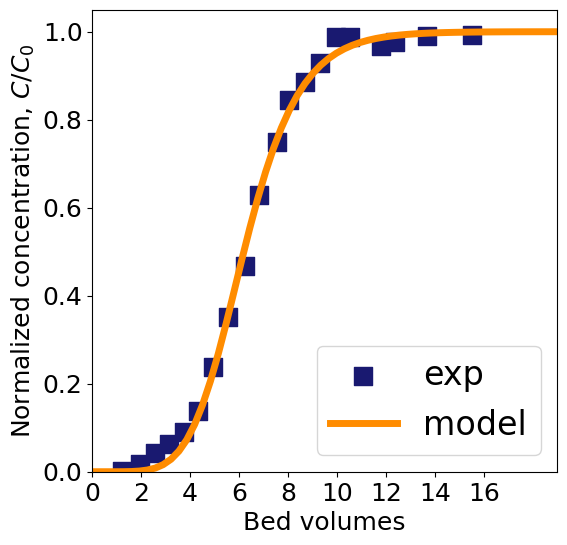

In [46]:
e_qmax, _, _ = model(Nx=100, dt=0.1, tmax=6., progress=True, breakthrough=True, e=e, qmax=qmax)

In [47]:
names = [name for name in calibrated_parameters.keys()]

Np = len(calibrated_parameters)
N = len(Cexp1a)

FIM = e_qmax_trf_cf['FIM']
SSR = e_qmax_trf_cf['SSR']
covariance = e_qmax_trf_cf['covariance']

print("FIM = \n", FIM)
print("SSR = ", SSR)
print("Calibrated parameters:", calibrated_parameters)
print("Covariance matrix: \n", covariance)
print("Condition number: {:.0f}".format(np.linalg.cond(covariance))) # 1 = well conditioned, 1e6 = ill conditioned
print("Standard deviation: \n", np.sqrt(np.diag(covariance))) # standard deviation of the parameters

# 95% confidence intervals
from scipy import stats
t_estimator = stats.t.ppf((1+0.95)/2, N-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

# Calculate confidence intervals
for parameter in calibrated_parameters.keys():
	CI = e_qmax_trf_cf['CI']
	d = e_qmax_trf_cf['d']
	if calibrated_parameters[parameter] > 1e-3:
		print(f"CI {parameter:s} : {calibrated_parameters[parameter]:.3f} ± {CI[parameter]:.4f} ({d[parameter]:.1f}%)")
	else:
		print(f"CI {parameter:s} : {calibrated_parameters[parameter]:.3e} ± {CI[parameter]:.4e} ({d[parameter]:.1f}%)")

# Calculate correlation coefficients
if Np > 1:
	for i in range(Np-1):
		for j in range(i+1, Np):
			r = e_qmax_trf_cf['r']
			print(f"Correlation {names[i]:s}-{names[j]:s} = {r[i,j]:.4f}")

FIM = 
 [[  59.56901442 -105.15299142]
 [-105.15299142  186.34518579]]
SSR =  0.008542049637983759
Calibrated parameters: {'e': 0.3106369168261434, 'qmax': 0.24289487604995666}
Covariance matrix: 
 [[0.00204478 0.00115385]
 [0.00115385 0.00065366]]
Condition number: 1396
Standard deviation: 
 [0.04521928 0.0255667 ]
Student's t estimator = 2.101
CI e : 0.311 ± 0.0950 (30.6%)
CI qmax : 0.243 ± 0.0537 (22.1%)
Correlation e-qmax = 0.9981


In [48]:
e_qmax_trf_cf['CI']

{'e': 0.09500217520464553, 'qmax': 0.0537136503583131}

In [39]:
# Generate Monte Carlo sampling for parameters
N = 2**6
Np = 2
sp = uncertainty_sampling(N=N,                          # no. of samples
              calc_second_order=False,      # calculate second order effects
              generate_new=False,           # generate new sampling

                                            # parameters = (name, value, uncertainty)
              e     =('e', 			e,         e_qmax_trf_cf['CI']['e']/2), 
              qmax  =('qmax',      	qmax,      e_qmax_trf_cf['CI']['qmax']/2), 
)

print(sp.samples.shape)

sp

No. of parameters = 2
No. of samples = 256
Reading existing sampling...
(256, 2)


{'num_vars': 2,
 'names': ['e', 'qmax'],
 'bounds': [(0.37, 0.047501087602322765),
  (0.3230611794850362, 0.02685682517915655)],
 'outputs': ['Y'],
 'dists': ['norm', 'norm'],
 'groups': None}

N = 256
e (mean ± 2*std) = 0.311 ± 2*0.048 (95.3%)
qmax (mean ± 2*std) = 0.243 ± 2*0.0272 (96.1%)


KeyError: 'e'

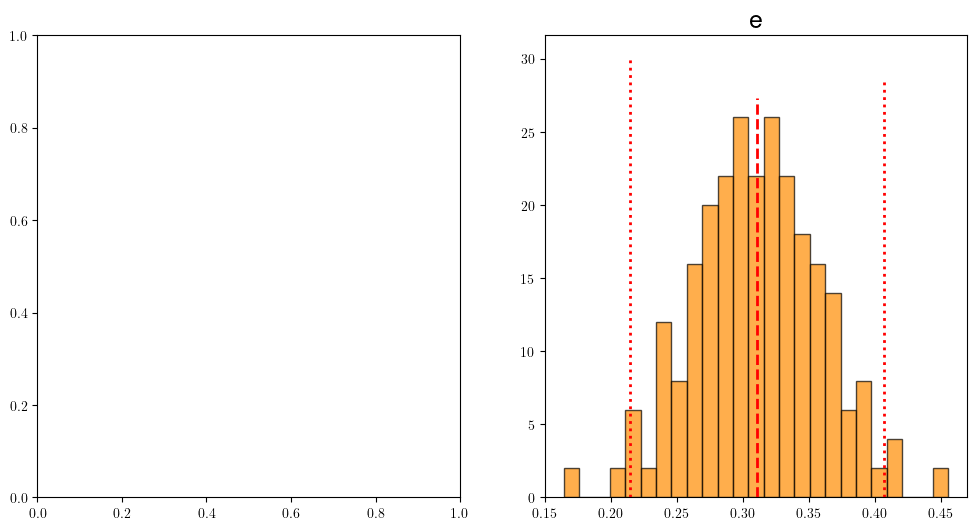

In [40]:
# Read file
# N = 2**1
print("N =", N*(Np+2))
joined_names = "e-qmax"
pars = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv")

# Verify sampling
results = e_qmax_trf_cf

inside_qmax = len(pars['qmax'][(pars['qmax'] >= np.mean(pars['qmax']) - 2*np.std(pars['qmax']) ) & (pars['qmax'] <= np.mean(pars['qmax']) + 2*np.std(pars['qmax']))])
inside_e = len(pars['e'][(pars['e'] >= np.mean(pars['e']) - 2*np.std(pars['e']) ) & (pars['e'] <= np.mean(pars['e']) + 2*np.std(pars['e']) )])
total_points = len(pars)
percentage_inside_qmax = (inside_qmax / total_points) * 100
percentage_inside_e = (inside_e / total_points) * 100

print("e (mean ± 2*std) = {:.3f} ± 2*{:.3f} ({:.1f}%)".format(np.mean(pars['e']), np.std(pars['e']), percentage_inside_e))
print("qmax (mean ± 2*std) = {:.3f} ± 2*{:.4f} ({:.1f}%)".format(np.mean(pars['qmax']), np.std(pars['qmax']), percentage_inside_qmax))

# Create histograms

size = 6
nbins = 25
fig, ax = plt.subplots(1, Np, figsize=(Np*size,size))

for parameter in pars.keys()[1:]:
	i = list(pars.keys()[1:]).index(parameter)-1
	ax[i].hist(pars[parameter], bins=nbins, color='darkorange', edgecolor='black', alpha=0.7)
	ax[i].set_title(f'{parameter}', fontsize=3*size)
	ax[i].vlines(np.mean(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dashed', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])+2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])-2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].text(0.5, 0.9, f"{parameter:s} = {calibrated_parameters[parameter]:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.8, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]+2*results['CI'][parameter]/2:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.2, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]-2*results['CI'][parameter]/2:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')

In [706]:
# Run only to generate new model simulations !!!
T, Y, BT = evaluation_uncertainty(pars, tmax=6.)

Run 1 of 256
Run 2 of 256
Run 3 of 256
Run 4 of 256
Run 5 of 256
Run 6 of 256
Run 7 of 256
Run 8 of 256
Run 9 of 256
Run 10 of 256
Run 11 of 256
Run 12 of 256
Run 13 of 256
Run 14 of 256
Run 15 of 256
Run 16 of 256
Run 17 of 256
Run 18 of 256
Run 19 of 256
Run 20 of 256
Run 21 of 256
Run 22 of 256
Run 23 of 256
Run 24 of 256
Run 25 of 256
Run 26 of 256
Run 27 of 256
Run 28 of 256
Run 29 of 256
Run 30 of 256
Run 31 of 256
Run 32 of 256
Run 33 of 256
Run 34 of 256
Run 35 of 256
Run 36 of 256
Run 37 of 256
Run 38 of 256
Run 39 of 256
Run 40 of 256
Run 41 of 256
Run 42 of 256
Run 43 of 256
Run 44 of 256
Run 45 of 256
Run 46 of 256
Run 47 of 256
Run 48 of 256
Run 49 of 256
Run 50 of 256
Run 51 of 256
Run 52 of 256
Run 53 of 256
Run 54 of 256
Run 55 of 256
Run 56 of 256
Run 57 of 256
Run 58 of 256
Run 59 of 256
Run 60 of 256
Run 61 of 256
Run 62 of 256
Run 63 of 256
Run 64 of 256
Run 65 of 256
Run 66 of 256
Run 67 of 256
Run 68 of 256
Run 69 of 256
Run 70 of 256
Run 71 of 256
Run 72 of 256
R

In [41]:
# Read data
# Np = 2
# N = 2**6
tmax = 6.
dt = 0.1

pars2 = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
sims2 = pd.read_csv(f"simulations-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
time2 = pd.read_csv(f"times-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
breakthrough2 = pd.read_csv(f"breakthrough-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()

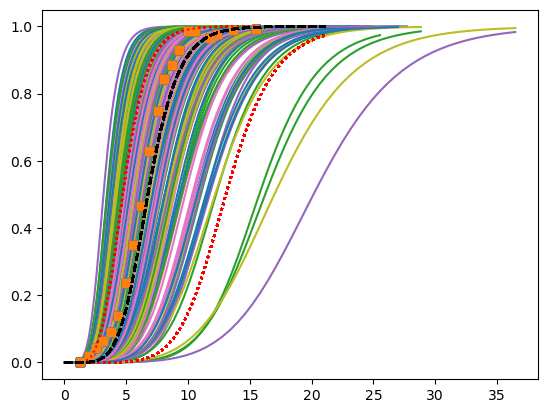

In [52]:
index = pars2.shape[0]
prediction_interval = 100

for i in range(0, index):
    plt.plot(time2[i,:], sims2[i,:])
    plt.plot(texp1a, Cexp1a, 's')
    # # print(sims3[i])
    plt.plot(time2[0], np.percentile(sims2, 50, axis=0), 'k--',zorder=10)
    plt.plot(time2[0], np.percentile(sims2[np.where(sims2[:,-1] >= 0.0)[0],:], 50 - prediction_interval/2., axis=0), 'r:')
    plt.plot(time2[0], np.percentile(sims2[np.where(sims2[:,-1] >= 0.0)[0],:], 50 + prediction_interval/2., axis=0), 'r:')

    # plt.plot(BV_calibrated2, C_calibration_model2, markevery=2, color='green', linestyle='-', linewidth=2.5, label=f'calibrated ($N_p = 2$)')
    
    # tc = np.argmax(time2[i,:] >= 10.)
    # # print(time3[i,tc])
    # if sims2[i,tc] <= 0.1: print(i, tc, sims2[i,tc])
    # if i == index+1 : break

### Np = 2 (e fixed, qmax)

In [591]:
# Calibrate epsilon
e_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, e=0.37)

Parameters to calibrate: ['e']
Original values: [0.37]
Method: Trust Region Reflective
Bounds: ([0.296], [0.444])
Algorithm: Curve-fitting
Run 1: {'e': 0.37}
Run 2: {'e': 0.3700000149011612}
Run 3: {'e': 0.35224467533647325}
Run 4: {'e': 0.35224469023763444}
Run 5: {'e': 0.347283216513187}
Run 6: {'e': 0.3472832314143482}
Run 7: {'e': 0.34675240174288535}
Run 8: {'e': 0.34675241664404655}
Run 9: {'e': 0.3467359326499522}
Run 10: {'e': 0.3467359475511134}
Calibration finished.
Number of runs: 10
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -148.3
Calculating FIM...
Run 1 of 2 : {'e': 0.3467359326499522}
Run 2 of 2 : {'e': 0.3467394000092788}
FIM = 
 [[67.92283236]]
SSR =  0.0108756264904207
Calibrated parameters: {'e': 0.3467359326499522}
Covariance matrix: 
 [[8.42723094e-06]]
Condition number: 1
Standard deviation: 
 [0.00290297]
Student's t estimator = 2.093
CI e : 0.347 ± 0.0061 (1.8%)


In [598]:
# Fix value for epsilon
e_fixed = e_trf_cf['params']['e']
print("e (calibrated) = ", e_fixed)

e (calibrated) =  0.3467359326499522


In [599]:
# Calibrate qmax
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(qmax=0.35)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'e': 0.3467359326499522}), ('calibrated_parameters', {'qmax': 0.35})])


dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'qmax': 3.9})])
Run 1 of 2 : {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 3.9}}
Run 2 of 2 : {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 3.900039}}
Average sensitivity (absolute): -4.263075494336734e-15
 qmax: -0.00


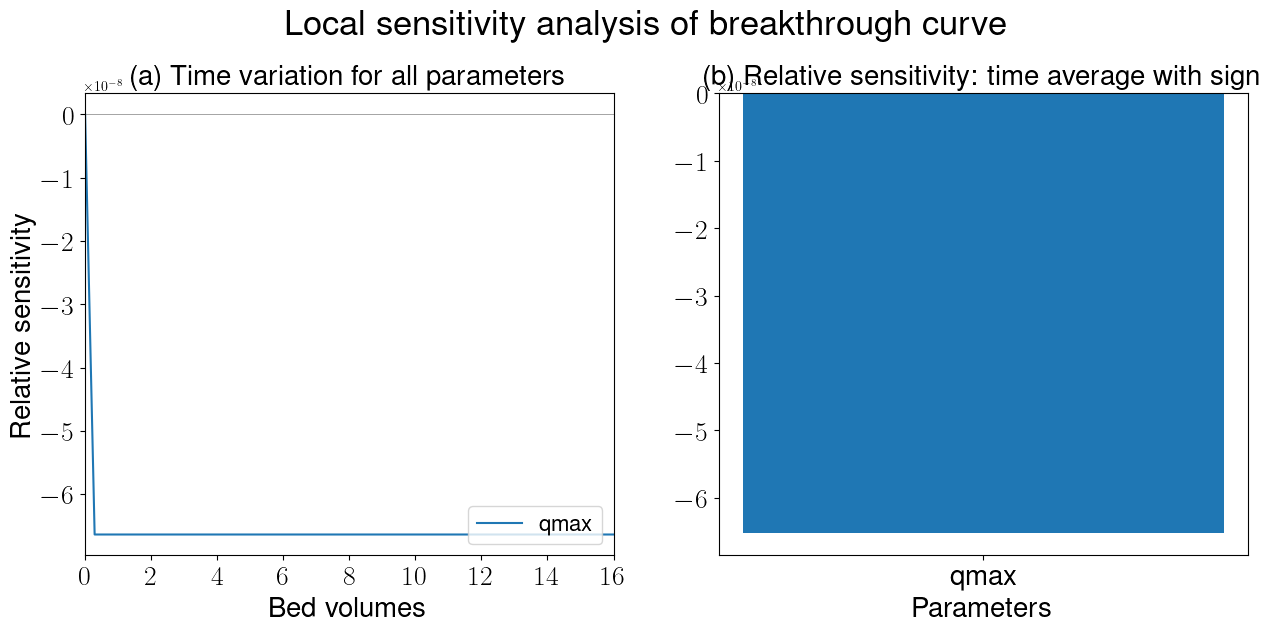

In [ ]:
print(parameters.items())
S = forward_sensitivity_calibration(model, dt=0.1, xi=1e-5, relative=False, plot=True, progress=False, **parameters)

In [ ]:
# Calibrate qmax
fixed_parameters = dict(e=e_fixed)
calibrated_parameters = dict(qmax=0.291)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'e': 0.34673557495870555}), ('calibrated_parameters', {'qmax': 0.291})])
Parameters to calibrate: ['qmax']
Original values: [0.291]
Method: Trust Region Reflective
Bounds: ([0.2328], [0.34919999999999995])
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.291}}
Run 2: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2910000149011612}}
Run 3: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.290807325504907}}
Run 4: {'fixed_parameters': {'e': 0.34673557495870555}, 'calibrated_parameters': {'qmax': 0.2908073404060682}}
Calibration finished.
Number of runs: 4
Calculating SSR, RMSE, AIC...
SSR = 0.0109
RMSE = 0.0233
AIC = -148.4
Calculating FIM...
Run 1 of 2 : {'qmax': 0.290807325504907}
Run 2 of 2 : {'qmax': 0.2908102335781621}
FIM = 
 [[165.0208152]]
SSR =  0.010869214656721108
Calibrated parameters: [0.29080733]
Covar

In [600]:
qmax_trf_cf_e_fixed = sequential_calibration(method='trf', algorithm='cf', tol=1e-4, **parameters)

Parameters to calibrate: ['qmax']
Original values: [0.35]
Method: Trust Region Reflective
Bounds: ([0.27999999999999997], [0.42])
Algorithm: Curve-fitting
Run 1: {'fixed_parameters': {'e': 0.3467359326499522}, 'calibrated_parameters': {'qmax': 0.35}}
Run 2: {'fixed_parameters': {'e': 0.3467359326499522}, 'calibrated_parameters': {'qmax': 0.35000001490116117}}
Run 3: {'fixed_parameters': {'e': 0.3467359326499522}, 'calibrated_parameters': {'qmax': 0.320179342889849}}
Run 4: {'fixed_parameters': {'e': 0.3467359326499522}, 'calibrated_parameters': {'qmax': 0.3201793577910102}}
Run 5: {'fixed_parameters': {'e': 0.3467359326499522}, 'calibrated_parameters': {'qmax': 0.30391278391904253}}
Run 6: {'fixed_parameters': {'e': 0.3467359326499522}, 'calibrated_parameters': {'qmax': 0.3039127988202037}}
Run 7: {'fixed_parameters': {'e': 0.3467359326499522}, 'calibrated_parameters': {'qmax': 0.29571988283276773}}
Run 8: {'fixed_parameters': {'e': 0.3467359326499522}, 'calibrated_parameters': {'qmax'

708cae running: t: 6: : 60it [00:03, 16.85it/s]                          


RMSE (calibration) = 0.0233
SSR (calibration) = 0.0109
AIC (calibration) = -148.4


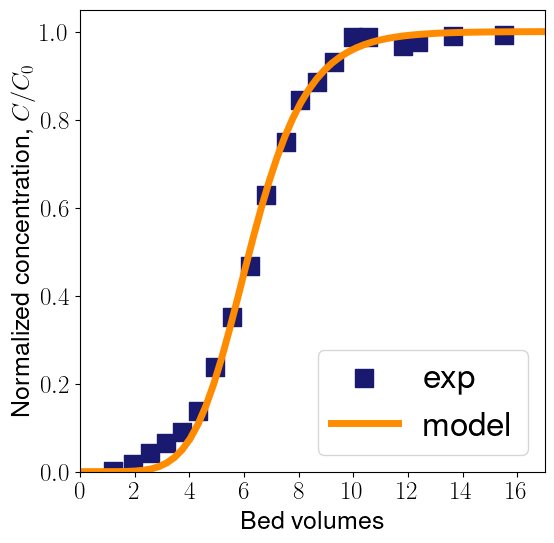

In [601]:
parameters['calibrated_parameters']['qmax'] = qmax_trf_cf_e_fixed['params']['qmax']
qmax_e_fixed,_,_ = model_calibration(texp=texp1a, Cexp=Cexp1a, progress=True, breakthrough=True, **parameters)

In [602]:
SSR = qmax_e_fixed['SSR']
print("SSR = ", SSR)
AIC = qmax_e_fixed['AIC']
print("AIC = ", AIC)

names = [name for name in parameters['calibrated_parameters'].keys()]
Sint = [np.interp(texp1a, S['t'], S[name]) for name in names]

Smatrix = [S[name] for name in names]
print("Sensitivity matrix = \n", Smatrix)

Np = len(names)
N = len(Cexp1a)

FIM = np.zeros((Np, Np))
for i in range(Np):
	for j in range(Np):
		FIM[i,j] = np.sum(Sint[i]*Sint[j])

print("FIM = \n", FIM)

covariance = np.linalg.inv(FIM) * SSR/(N-Np) # from the FIM
print("Covariance matrix: \n", covariance)

from scipy import stats
t_estimator = stats.t.ppf((1+0.95)/2, N-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

# Calculate confidence intervals
for name in names:
	value = parameters['calibrated_parameters'][name]
	CI = t_estimator * np.sqrt(covariance[i,i])
	d = CI/value*100
	if value > 1e-3:
		print(f"CI {names[i]:s} : {value:.3f} ± {CI:.4f} ({d:.1f}%)")
	else:
		print(f"CI {names[i]:s} : {value:.3e} ± {CI:.4e} ({d:.1f}%)")


SSR =  0.010869247000203499
AIC =  -148.35100254025718
Sensitivity matrix = 
 [array([ 0.00000000e+00, -3.84343909e-06, -7.44089229e-06, -2.33765637e-04,
       -2.11037005e-03, -8.86717164e-03, -2.57807215e-02, -6.03570542e-02,
       -1.22306376e-01, -2.23296658e-01, -3.76404539e-01, -5.95105940e-01,
       -8.91623583e-01, -1.27444819e+00, -1.74509035e+00, -2.29452851e+00,
       -2.90042514e+00, -3.52665387e+00, -4.12650855e+00, -4.64978577e+00,
       -5.05208343e+00, -5.30326718e+00, -5.39220866e+00, -5.32658719e+00,
       -5.12862486e+00, -4.82886391e+00, -4.46010290e+00, -4.05282204e+00,
       -3.63250750e+00, -3.21864271e+00, -2.82486094e+00, -2.45974357e+00,
       -2.12786780e+00, -1.83085188e+00, -1.56826758e+00, -1.33837186e+00,
       -1.13865814e+00, -9.66250506e-01, -8.18171928e-01, -6.91517055e-01,
       -5.83555869e-01, -4.91789085e-01, -4.13971176e-01, -3.48112505e-01,
       -2.92468733e-01, -2.45523058e-01, -2.05964989e-01, -1.72668088e-01,
       -1.44668098e-0

In [610]:
e = qmax_e_fixed['params']['e']
qmax = qmax_e_fixed['params']['qmax']

calibrated_parameters = dict(e=e, qmax=qmax)
print(calibrated_parameters)

{'e': 0.3467359326499522, 'qmax': 0.2908081948934646}


In [ ]:
names = [name for name in calibrated_parameters.keys()]

Np = len(calibrated_parameters)
N = len(Cexp1a)

FIM = e_qmax_trf_cf['FIM']
SSR = e_qmax_trf_cf['SSR']
covariance = e_qmax_trf_cf['covariance']

print("FIM = \n", FIM)
print("SSR = ", SSR)
print("Calibrated parameters:", calibrated_parameters)
print("Covariance matrix: \n", covariance)
print("Condition number: {:.0f}".format(np.linalg.cond(covariance))) # 1 = well conditioned, 1e6 = ill conditioned
print("Standard deviation: \n", np.sqrt(np.diag(covariance))) # standard deviation of the parameters

# 95% confidence intervals
from scipy import stats
t_estimator = stats.t.ppf((1+0.95)/2, N-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

# Calculate confidence intervals
for parameter in calibrated_parameters.keys():
	CI = e_qmax_trf_cf['CI']
	d = e_qmax_trf_cf['d']
	if calibrated_parameters[parameter] > 1e-3:
		print(f"CI {parameter:s} : {calibrated_parameters[parameter]:.3f} ± {CI[parameter]:.4f} ({d[parameter]:.1f}%)")
	else:
		print(f"CI {parameter:s} : {calibrated_parameters[parameter]:.3e} ± {CI[parameter]:.4e} ({d[parameter]:.1f}%)")

# Calculate correlation coefficients
if Np > 1:
	for i in range(Np-1):
		for j in range(i+1, Np):
			r = e_qmax_trf_cf['r']
			print(f"Correlation {names[i]:s}-{names[j]:s} = {r[i,j]:.4f}")

FIM = 
 [[  59.56901442 -105.15299142]
 [-105.15299142  186.34518579]]
SSR =  0.008542049637983759
Calibrated parameters: {'e': 0.3106369168261434, 'qmax': 0.24289487604995666}
Covariance matrix: 
 [[0.00204478 0.00115385]
 [0.00115385 0.00065366]]
Condition number: 1396
Standard deviation: 
 [0.04521928 0.0255667 ]
Student's t estimator = 2.101
CI e : 0.311 ± 0.0950 (30.6%)
CI qmax : 0.243 ± 0.0537 (22.1%)
Correlation e-qmax = 0.9981


In [606]:
e_qmax_trf_cf['CI']['e'] = e_trf_cf['CI']['e']
e_qmax_trf_cf['CI']['qmax'] = qmax_trf_cf['CI']['qmax']
e_qmax_trf_cf['CI']

{'e': 0.006075984639424078, 'qmax': 0.004539974187323189}

In [607]:
# Generate Monte Carlo sampling for parameters
N = 2**5
Np = 2
sp = uncertainty_sampling(N=N,                          # no. of samples
              calc_second_order=False,      # calculate second order effects
              generate_new=True,           # generate new sampling

                                            # parameters = (name, value, uncertainty)
              e     =('e', 			e,         e_qmax_trf_cf['CI']['e']/2), 
              qmax  =('qmax',      	qmax,      e_qmax_trf_cf['CI']['qmax']/2), 
)

print(sp.samples.shape)

No. of parameters = 2
No. of samples = 128
Generating new sampling...
(128, 2)


N = 128
e (mean ± 2*std) = 0.347 ± 2*0.001 (93.8%)
qmax (mean ± 2*std) = 0.291 ± 2*0.0011 (95.3%)


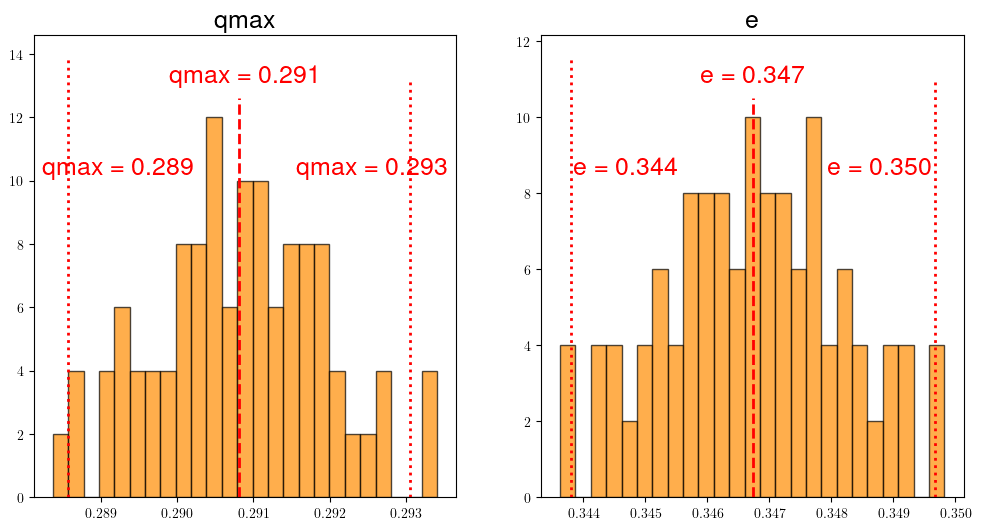

In [611]:
# Read file
# N = 2**1
print("N =", N*(Np+2))
joined_names = "e-qmax"
pars = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv")

# Verify sampling
results = e_qmax_trf_cf

inside_qmax = len(pars['qmax'][(pars['qmax'] >= np.mean(pars['qmax']) - 2*np.std(pars['qmax']) ) & (pars['qmax'] <= np.mean(pars['qmax']) + 2*np.std(pars['qmax']))])
inside_e = len(pars['e'][(pars['e'] >= np.mean(pars['e']) - 2*np.std(pars['e']) ) & (pars['e'] <= np.mean(pars['e']) + 2*np.std(pars['e']) )])
total_points = len(pars)
percentage_inside_qmax = (inside_qmax / total_points) * 100
percentage_inside_e = (inside_e / total_points) * 100

print("e (mean ± 2*std) = {:.3f} ± 2*{:.3f} ({:.1f}%)".format(np.mean(pars['e']), np.std(pars['e']), percentage_inside_e))
print("qmax (mean ± 2*std) = {:.3f} ± 2*{:.4f} ({:.1f}%)".format(np.mean(pars['qmax']), np.std(pars['qmax']), percentage_inside_qmax))

# Create histograms

size = 6
nbins = 25
fig, ax = plt.subplots(1, Np, figsize=(Np*size,size))

for parameter in pars.keys()[1:]:
	i = list(pars.keys()[1:]).index(parameter)-1
	ax[i].hist(pars[parameter], bins=nbins, color='darkorange', edgecolor='black', alpha=0.7)
	ax[i].set_title(f'{parameter}', fontsize=3*size)
	ax[i].vlines(np.mean(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dashed', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])+2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])-2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].text(0.5, 0.9, f"{parameter:s} = {calibrated_parameters[parameter]:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.8, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]+1*results['CI'][parameter]/2:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.2, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]-1*results['CI'][parameter]/2:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')

In [612]:
T, Y, BT = evaluation_uncertainty(pars, tmax=6.)

Run 1 of 128
Run 2 of 128
Run 3 of 128
Run 4 of 128
Run 5 of 128
Run 6 of 128
Run 7 of 128
Run 8 of 128
Run 9 of 128
Run 10 of 128
Run 11 of 128
Run 12 of 128
Run 13 of 128
Run 14 of 128
Run 15 of 128
Run 16 of 128
Run 17 of 128
Run 18 of 128
Run 19 of 128
Run 20 of 128
Run 21 of 128
Run 22 of 128
Run 23 of 128
Run 24 of 128
Run 25 of 128
Run 26 of 128
Run 27 of 128
Run 28 of 128
Run 29 of 128
Run 30 of 128
Run 31 of 128
Run 32 of 128
Run 33 of 128
Run 34 of 128
Run 35 of 128
Run 36 of 128
Run 37 of 128
Run 38 of 128
Run 39 of 128
Run 40 of 128
Run 41 of 128
Run 42 of 128
Run 43 of 128
Run 44 of 128
Run 45 of 128
Run 46 of 128
Run 47 of 128
Run 48 of 128
Run 49 of 128
Run 50 of 128
Run 51 of 128
Run 52 of 128
Run 53 of 128
Run 54 of 128
Run 55 of 128
Run 56 of 128
Run 57 of 128
Run 58 of 128
Run 59 of 128
Run 60 of 128
Run 61 of 128
Run 62 of 128
Run 63 of 128
Run 64 of 128
Run 65 of 128
Run 66 of 128
Run 67 of 128
Run 68 of 128
Run 69 of 128
Run 70 of 128
Run 71 of 128
Run 72 of 128
R

In [613]:
# Read data
# Np = 2
# N = 2**6
tmax = 6.
dt = 0.1

pars2 = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
sims2 = pd.read_csv(f"simulations-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
time2 = pd.read_csv(f"times-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
breakthrough2 = pd.read_csv(f"breakthrough-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()

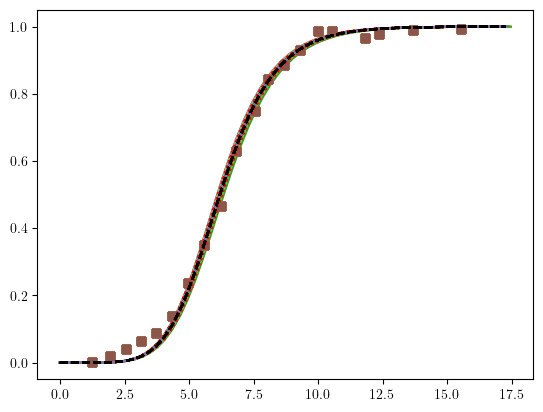

In [614]:
index = N
prediction_interval = 95

for i in range(0, index+1):
    plt.plot(time2[i,:], sims2[i,:])
    plt.plot(texp1a, Cexp1a, 's')
    # # print(sims3[i])
    plt.plot(time2[0], np.percentile(sims2, 50, axis=0), 'k--',zorder=10)
    plt.plot(time2[0], np.percentile(sims2[np.where(sims2[:,-1] >= 0.0)[0],:], 50 - prediction_interval/2., axis=0), 'r:')
    plt.plot(time2[0], np.percentile(sims2[np.where(sims2[:,-1] >= 0.0)[0],:], 50 + prediction_interval/2., axis=0), 'r:')

    # plt.plot(BV_calibrated2, C_calibration_model2, markevery=2, color='green', linestyle='-', linewidth=2.5, label=f'calibrated ($N_p = 2$)')
    
    # tc = np.argmax(time2[i,:] >= 10.)
    # # print(time3[i,tc])
    # if sims2[i,tc] <= 0.1: print(i, tc, sims2[i,tc])
    # if i == index+1 : break

### Np = 2 (e, rp)

In [340]:
e_rp_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, e=0.37, rp=3.75e-4)

Parameters to calibrate: ['e', 'rp']
Original values: [0.37     0.000375]
Method: Trust Region Reflective
Bounds: ([0.296, 0.00030000000000000003], [0.444, 0.00045])
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'rp': 0.000375}
Run 2: {'e': 0.3700000149011612, 'rp': 0.000375}
Run 3: {'e': 0.37, 'rp': 0.00037501490116119386}
Run 4: {'e': 0.35086113683411796, 'rp': 0.00041661765415995514}
Run 5: {'e': 0.35086115173527915, 'rp': 0.00041661765415995514}
Run 6: {'e': 0.35086113683411796, 'rp': 0.000416632555321149}
Run 7: {'e': 0.3457476748925897, 'rp': 0.00041538597175372414}
Run 8: {'e': 0.34574768979375087, 'rp': 0.00041538597175372414}
Run 9: {'e': 0.3457476748925897, 'rp': 0.000415400872914918}
Run 10: {'e': 0.34547383209286403, 'rp': 0.00041161351410230155}
Run 11: {'e': 0.3454738469940252, 'rp': 0.00041161351410230155}
Run 12: {'e': 0.34547383209286403, 'rp': 0.0004116284152634954}
Run 13: {'e': 0.3454864733343606, 'rp': 0.0004108544195855232}
Run 14: {'e': 0.3454864882355218, 'rp': 0.

In [341]:
e = e_rp_trf_cf['params']['e']
rp = e_rp_trf_cf['params']['rp']

calibrated_parameters = e_rp_trf_cf['param_calib']
print(calibrated_parameters)

{'e': 0.3454864733343606, 'rp': 0.0004108544195855232}


In [342]:
names = [name for name in calibrated_parameters.keys()]

Np = len(calibrated_parameters)
N = len(Cexp1a)

FIM = e_rp_trf_cf['FIM']
SSR = e_rp_trf_cf['SSR']
covariance = e_rp_trf_cf['covariance']

print("FIM = \n", FIM)
print("SSR = ", SSR)
print("Calibrated parameters:", calibrated_parameters)
print("Covariance matrix: \n", covariance)
print("Condition number: {:.0f}".format(np.linalg.cond(covariance))) # 1 = well conditioned, 1e6 = ill conditioned
print("Standard deviation: \n", np.sqrt(np.diag(covariance))) # standard deviation of the parameters

# 95% confidence intervals
from scipy import stats
t_estimator = stats.t.ppf((1+0.95)/2, N-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

# Calculate confidence intervals
for parameter in calibrated_parameters.keys():
	CI = e_rp_trf_cf['CI']
	d = e_rp_trf_cf['d']
	if calibrated_parameters[parameter] > 1e-3:
		print(f"CI {parameter:s} : {calibrated_parameters[parameter]:.3f} ± {CI[parameter]:.4f} ({d[parameter]:.1f}%)")
	else:
		print(f"CI {parameter:s} : {calibrated_parameters[parameter]:.3e} ± {CI[parameter]:.4e} ({d[parameter]:.1f}%)")

# Calculate correlation coefficients
if Np > 1:
	for i in range(Np-1):
		for j in range(i+1, Np):
			r = e_rp_trf_cf['r']
			print(f"Correlation {names[i]:s}-{names[j]:s} = {r[i,j]:.4f}")

FIM = 
 [[6.32156857e+01 5.40151760e+03]
 [5.40151760e+03 2.33378898e+06]]
SSR =  0.008538907801768412
Calibrated parameters: {'e': 0.3454864733343606, 'rp': 0.0004108544195855232}
Covariance matrix: 
 [[ 9.35410640e-06 -2.16499310e-08]
 [-2.16499310e-08  2.53376057e-10]]
Condition number: 46019
Standard deviation: 
 [3.05844836e-03 1.59177906e-05]
Student's t estimator = 2.101
CI e : 0.345 ± 0.0064 (1.9%)
CI rp : 4.109e-04 ± 3.3442e-05 (8.1%)
Correlation e-rp = -0.4447


In [343]:
e_rp_trf_cf['CI']

{'e': 0.006425561578725876, 'rp': 3.344203706646198e-05}

In [427]:
# Generate Monte Carlo sampling for parameters
N = 2**5

sp = uncertainty_sampling(N=N,                          # no. of samples
              calc_second_order=False,      # calculate second order effects
              generate_new=True,           # generate new sampling

                                            # parameters = (name, value, uncertainty)
              e     =('e', 			e,         e_rp_trf_cf['CI']['e']/2), 
              qmax  =('rp',      	rp,      e_rp_trf_cf['CI']['rp']/2), 
)

print(sp.samples.shape)

No. of parameters = 2
No. of samples = 128
Generating new sampling...
(128, 2)


In [428]:
# Read file
# N = 2**1
print("N =", N*(Np+2))
joined_names = "e-rp"
pars = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv")

# Verify sampling
results = e_rp_trf_cf

inside_qmax = len(pars['rp'][(pars['rp'] >= np.mean(pars['rp']) - 2*np.std(pars['rp']) ) & (pars['rp'] <= np.mean(pars['rp']) + 2*np.std(pars['rp']))])
inside_e = len(pars['e'][(pars['e'] >= np.mean(pars['e']) - 2*np.std(pars['e']) ) & (pars['e'] <= np.mean(pars['e']) + 2*np.std(pars['e']) )])
total_points = len(pars)
percentage_inside_qmax = (inside_qmax / total_points) * 100
percentage_inside_e = (inside_e / total_points) * 100

print("e (mean ± 2*std) = {:.3f} ± 2*{:.3f} ({:.1f}%)".format(np.mean(pars['e']), np.std(pars['e']), percentage_inside_e))
print("rp (mean ± 2*std) = {:.3e} ± 2*{:.4e} ({:.1f}%)".format(np.mean(pars['rp']), np.std(pars['rp']), percentage_inside_qmax))

# Create histograms

size = 6
nbins = 25
fig, ax = plt.subplots(1, Np, figsize=(Np*size,size))

for parameter in calibrated_parameters.keys():
	i = list(pars.keys()).index(parameter)-1
	ax[i].hist(pars[parameter], bins=nbins, color='darkorange', edgecolor='black', alpha=0.7)
	ax[i].set_title(f'{parameter}', fontsize=3*size)
	ax[i].vlines(np.mean(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dashed', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])+2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])-2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].text(0.5, 0.9, f"{parameter:s} = {calibrated_parameters[parameter]:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.8, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]+2*results['CI'][parameter]/2:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.2, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]-2*results['CI'][parameter]/2:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')

N = 160


FileNotFoundError: [Errno 2] No such file or directory: 'sampling-UA_Np-3_N-32_e-rp.csv'

In [346]:
T, Y, BT = evaluation_uncertainty(pars, tmax=6.)

Run 1 of 32
Run 2 of 32
Run 3 of 32
Run 4 of 32
Run 5 of 32
Run 6 of 32
Run 7 of 32
Run 8 of 32
Run 9 of 32
Run 10 of 32
Run 11 of 32
Run 12 of 32
Run 13 of 32
Run 14 of 32
Run 15 of 32
Run 16 of 32
Run 17 of 32
Run 18 of 32
Run 19 of 32
Run 20 of 32
Run 21 of 32
Run 22 of 32
Run 23 of 32
Run 24 of 32
Run 25 of 32
Run 26 of 32
Run 27 of 32
Run 28 of 32
Run 29 of 32
Run 30 of 32
Run 31 of 32
Run 32 of 32


In [347]:
# Read data
# Np = 2
# N = 2**6
tmax = 6.
dt = 0.1

pars3 = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
sims3 = pd.read_csv(f"simulations-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
time3 = pd.read_csv(f"times-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
breakthrough3 = pd.read_csv(f"breakthrough-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()

### Np = 3 (e, qmax, rp)

In [34]:
e_qmax_rp_trf_cf = calibration(method='trf', algorithm='cf', tol=1e-4, e=0.39, qmax=0.39, rp=4.2e-4)

Experimental data for calibration: exp1a
Parameters to calibrate: ['e', 'qmax', 'rp']
Original values: [0.39    0.39    0.00042]
Method: Trust Region Reflective
Bounds: ([0.31200000000000006, 0.31200000000000006, 0.00033600000000000004], [0.46799999999999997, 0.46799999999999997, 0.000504])
Algorithm: Curve-fitting
Run 1: {'e': 0.39, 'qmax': 0.39, 'rp': 0.00042}
Run 2: {'e': 0.3900000149011612, 'qmax': 0.39, 'rp': 0.00042}
Run 3: {'e': 0.39, 'qmax': 0.3900000149011612, 'rp': 0.00042}
Run 4: {'e': 0.39, 'qmax': 0.39, 'rp': 0.00042001490116119387}
Run 5: {'e': 0.4005641800196739, 'qmax': 0.3790058677572923, 'rp': 0.00044261191625922293}
Run 6: {'e': 0.4005641949208351, 'qmax': 0.3790058677572923, 'rp': 0.00044261191625922293}
Run 7: {'e': 0.4005641800196739, 'qmax': 0.3790058826584535, 'rp': 0.00044261191625922293}
Run 8: {'e': 0.4005641800196739, 'qmax': 0.3790058677572923, 'rp': 0.0004426268174204168}
Run 9: {'e': 0.40313123981859245, 'qmax': 0.37608624548075864, 'rp': 0.00045004707329

In [54]:
e_qmax_rp_trf_cf = calibration(method='lm', algorithm='cf', tol=1e-4, e=0.37, qmax=0.291, rp=3.75e-4)

Experimental data for calibration: exp1a
Parameters to calibrate: ['e', 'qmax', 'rp']
Original values: [0.37     0.291    0.000375]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'e': 0.37, 'qmax': 0.291, 'rp': 0.000375}
Run 2: {'e': 0.37, 'qmax': 0.291, 'rp': 0.000375}
Run 3: {'e': 0.37, 'qmax': 0.291, 'rp': 0.000375}
Run 4: {'e': 0.37000000551342965, 'qmax': 0.291, 'rp': 0.000375}
Run 5: {'e': 0.37, 'qmax': 0.2910000043362379, 'rp': 0.000375}
Run 6: {'e': 0.37, 'qmax': 0.291, 'rp': 0.00037500000558793545}
Run 7: {'e': 0.3984659803022208, 'qmax': 0.3675153396372446, 'rp': 0.0005114871010211972}
Run 8: {'e': 0.3984659862398266, 'qmax': 0.3675153396372446, 'rp': 0.0005114871010211972}
Run 9: {'e': 0.3984659803022208, 'qmax': 0.3675153451136499, 'rp': 0.0005114871010211972}
Run 10: {'e': 0.3984659803022208, 'qmax': 0.3675153396372446, 'rp': 0.0005114871086429489}
Run 11: {'e': 0.3118989592692735, 'qmax': 0.23716803678837867, 'rp': 0.0003886712599977184}
Run 12: {'e': 0.3669

In [55]:
e = e_qmax_rp_trf_cf['params']['e']
qmax = e_qmax_rp_trf_cf['params']['qmax']
rp = e_qmax_rp_trf_cf['params']['rp']

calibrated_parameters = e_qmax_rp_trf_cf['param_calib']
print(calibrated_parameters)

{'e': 0.33419672016625374, 'qmax': 0.2752298108713441, 'rp': 0.0004001841684987312}


In [56]:
names = [name for name in calibrated_parameters.keys()]

Np = len(calibrated_parameters)
N = len(Cexp1a)

FIM = e_qmax_rp_trf_cf['FIM']
SSR = e_qmax_rp_trf_cf['SSR']
covariance = e_qmax_rp_trf_cf['covariance']

print("FIM = \n", FIM)
print("SSR = ", SSR)
print("Calibrated parameters:", calibrated_parameters)
print("Covariance matrix: \n", covariance)
print("Condition number: {:.0f}".format(np.linalg.cond(covariance))) # 1 = well conditioned, 1e6 = ill conditioned
print("Standard deviation: \n", np.sqrt(np.diag(covariance))) # standard deviation of the parameters

# 95% confidence intervals
from scipy import stats
t_estimator = stats.t.ppf((1+0.95)/2, N-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

# Calculate confidence intervals
for parameter in calibrated_parameters.keys():
	CI = e_qmax_rp_trf_cf['CI']
	d = e_qmax_rp_trf_cf['d']
	if calibrated_parameters[parameter] > 1e-3:
		print(f"CI {parameter:s} : {calibrated_parameters[parameter]:.3f} ± {CI[parameter]:.4f} ({d[parameter]:.1f}%)")
	else:
		print(f"CI {parameter:s} : {calibrated_parameters[parameter]:.3e} ± {CI[parameter]:.4e} ({d[parameter]:.1f}%)")

# Calculate correlation coefficients
if Np > 1:
	for i in range(Np-1):
		for j in range(i+1, Np):
			r = e_qmax_rp_trf_cf['r']
			print(f"Correlation {names[i]:s}-{names[j]:s} = {r[i,j]:.4f}")

FIM = 
 [[ 6.21418568e+01 -1.00575703e+02  5.34358048e+03]
 [-1.00575703e+02  1.63320864e+02 -9.67400472e+03]
 [ 5.34358048e+03 -9.67400472e+03  2.41403022e+06]]
SSR =  0.008466772130353604
Calibrated parameters: {'e': 0.33419672016625374, 'qmax': 0.2752298108713441, 'rp': 0.0004001841684987312}
Covariance matrix: 
 [[4.96820797e-01 3.15762523e-01 1.65650878e-04]
 [3.15762523e-01 2.00691996e-01 1.05298129e-04]
 [1.65650878e-04 1.05298129e-04 5.55021406e-08]]
Condition number: 3380907534
Standard deviation: 
 [7.04855160e-01 4.47986603e-01 2.35588923e-04]
Student's t estimator = 2.110
CI e : 0.334 ± 1.4871 (445.0%)
CI qmax : 0.275 ± 0.9452 (343.4%)
CI rp : 4.002e-04 ± 4.9705e-04 (124.2%)
Correlation e-qmax = 1.0000
Correlation e-rp = 0.9976
Correlation qmax-rp = 0.9977


In [57]:
e_qmax_rp_trf_cf['CI']

{'e': 1.4871143966178222,
 'qmax': 0.945169113223536,
 'rp': 0.0004970491796760261}

In [42]:
# Generate Monte Carlo sampling for parameters
N = 2**5
Np = 3

sp = uncertainty_sampling(N=N,                          # no. of samples
              calc_second_order=False,      # calculate second order effects
              generate_new=False,           # generate new sampling

                                            # parameters = (name, value, uncertainty)
              rp    =('rp',         rp,        e_qmax_rp_trf_cf['CI']['rp']/5),
              e     =('e', 			e,         e_qmax_rp_trf_cf['CI']['e']/5), 
              qmax  =('qmax',      	qmax,      e_qmax_rp_trf_cf['CI']['qmax']/5), 
)

print(sp.samples.shape)

No. of parameters = 3
No. of samples = 160
Reading existing sampling...
(160, 3)


N = 160
rp (mean ± 2*std) = 4.64e-04 ± 2*4.92e-05 (95.0%)
e (mean ± 2*std) = 0.410 ± 2*0.153 (96.9%)
qmax (mean ± 2*std) = 0.388 ± 2*0.1339 (93.8%)


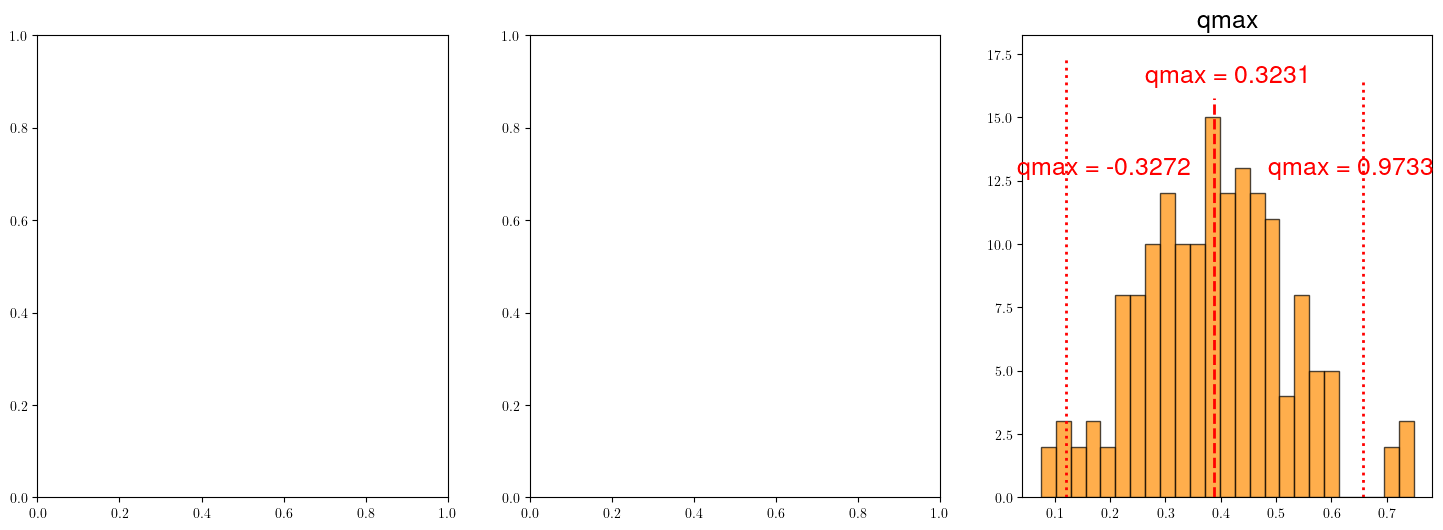

In [43]:
# Read file
# N = 2**
print("N =", N*(Np+2))
joined_names = "rp-e-qmax"
pars = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv")

# Verify sampling

inside_qmax = len(pars['qmax'][(pars['qmax'] >= np.mean(pars['qmax']) - 2*np.std(pars['qmax']) ) & (pars['qmax'] <= np.mean(pars['qmax']) + 2*np.std(pars['qmax']))])
inside_rp = len(pars['rp'][(pars['rp'] >= np.mean(pars['rp']) - 2*np.std(pars['rp']) ) & (pars['rp'] <= np.mean(pars['rp']) + 2*np.std(pars['rp']) )])
inside_e = len(pars['e'][(pars['e'] >= np.mean(pars['e']) - 2*np.std(pars['e']) ) & (pars['e'] <= np.mean(pars['e']) + 2*np.std(pars['e']) )])
total_points = len(pars)
percentage_inside_qmax = (inside_qmax / total_points) * 100
percentage_inside_rp = (inside_rp / total_points) * 100
percentage_inside_e = (inside_e / total_points) * 100


print("rp (mean ± 2*std) = {:.2e} ± 2*{:.2e} ({:.1f}%)".format(np.mean(pars['rp']), np.std(pars['rp']), percentage_inside_rp))
print("e (mean ± 2*std) = {:.3f} ± 2*{:.3f} ({:.1f}%)".format(np.mean(pars['e']), np.std(pars['e']), percentage_inside_e))
print("qmax (mean ± 2*std) = {:.3f} ± 2*{:.4f} ({:.1f}%)".format(np.mean(pars['qmax']), np.std(pars['qmax']), percentage_inside_qmax))

# Create histograms

size = 6
nbins = 25
fig, ax = plt.subplots(1, Np, figsize=(Np*size,size))

for parameter in calibrated_parameters.keys():
	i = list(pars.keys()).index(parameter)-1
	ax[i].hist(pars[parameter], bins=nbins, color='darkorange', edgecolor='black', alpha=0.7)
	ax[i].set_title(f'{parameter}', fontsize=3*size)
	ax[i].vlines(np.mean(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dashed', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])+2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])-2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].text(0.5, 0.9, f"{parameter:s} = {calibrated_parameters[parameter]:.4f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.8, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]+e_qmax_rp_trf_cf['CI'][parameter]/2:.4f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.2, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]-e_qmax_rp_trf_cf['CI'][parameter]/2:.4f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')

In [528]:
T, Y, BT = evaluation_uncertainty(pars, tmax=8.)

Run 1 of 160
Run 2 of 160
Run 3 of 160
Run 4 of 160
Run 5 of 160
Run 6 of 160
Run 7 of 160
Run 8 of 160
Run 9 of 160
Run 10 of 160
Run 11 of 160
Run 12 of 160
Run 13 of 160
Run 14 of 160
Run 15 of 160
Run 16 of 160
Run 17 of 160
Run 18 of 160
Run 19 of 160
Run 20 of 160
Run 21 of 160
Run 22 of 160
Run 23 of 160
Run 24 of 160
Run 25 of 160
Run 26 of 160
Run 27 of 160
Run 28 of 160
Run 29 of 160
Run 30 of 160
Run 31 of 160
Run 32 of 160
Run 33 of 160
Run 34 of 160
Run 35 of 160
Run 36 of 160
Run 37 of 160
Run 38 of 160
Run 39 of 160
Run 40 of 160
Run 41 of 160
Run 42 of 160
Run 43 of 160
Run 44 of 160
Run 45 of 160
Run 46 of 160
Run 47 of 160
Run 48 of 160
Run 49 of 160
Run 50 of 160
Run 51 of 160
Run 52 of 160
Run 53 of 160
Run 54 of 160
Run 55 of 160
Run 56 of 160
Run 57 of 160
Run 58 of 160
Run 59 of 160
Run 60 of 160
Run 61 of 160
Run 62 of 160
Run 63 of 160
Run 64 of 160
Run 65 of 160
Run 66 of 160
Run 67 of 160
Run 68 of 160
Run 69 of 160
Run 70 of 160
Run 71 of 160
Run 72 of 160
R

In [44]:
# Read data
# Np = 2
# N = 2**6
tmax = 8.
dt = 0.1

pars3 = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
sims3 = pd.read_csv(f"simulations-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
time3 = pd.read_csv(f"times-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()
breakthrough3 = pd.read_csv(f"breakthrough-UA_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}_{joined_names:s}.csv").iloc[:, 1:].to_numpy()

In [61]:
print(time3[1])
np.argmax((time3[1] >= 12.) & (time3[1] <= 20.))

[ 0.          0.20923119  0.41846239  0.62769358  0.83692478  1.04615597
  1.25538716  1.46461836  1.67384955  1.88308075  2.09231194  2.30154313
  2.51077433  2.72000552  2.92923671  3.13846791  3.3476991   3.5569303
  3.76616149  3.97539268  4.18462388  4.39385507  4.60308627  4.81231746
  5.02154865  5.23077985  5.44001104  5.64924224  5.85847343  6.06770462
  6.27693582  6.48616701  6.6953982   6.9046294   7.11386059  7.32309179
  7.53232298  7.74155417  7.95078537  8.16001656  8.36924776  8.57847895
  8.78771014  8.99694134  9.20617253  9.41540373  9.62463492  9.83386611
 10.04309731 10.2523285  10.46155969 10.67079089 10.88002208 11.08925328
 11.29848447 11.50771566 11.71694686 11.92617805 12.13540925 12.34464044
 12.55387163 12.76310283 12.97233402 13.18156522 13.39079641 13.6000276
 13.8092588  14.01848999 14.22772118 14.43695238 14.64618357 14.85541477
 15.06464596 15.27387715 15.48310835 15.69233954 15.90157074 16.11080193
 16.32003312 16.52926432 16.73849551]


58

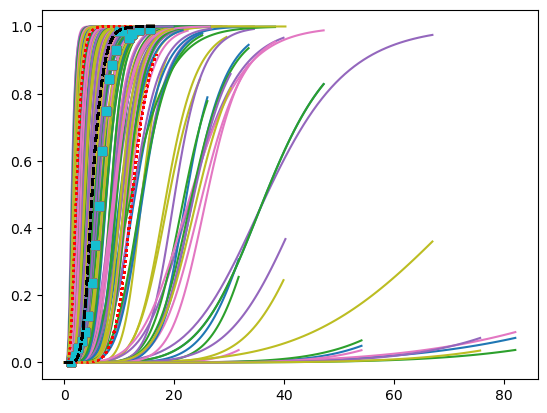

In [62]:
index = N*(Np+2)
prediction_interval = 95
tmin = 16
Cmin = 0.85

for i in range(0, index):
    plt.plot(time3[i,:], sims3[i,:])
    plt.plot(texp1a, Cexp1a, 's')
    # # print(sims3[i])
    plt.plot(time3[0], np.percentile(sims3, 50, axis=0), 'k--',zorder=10)
    plt.plot(time3[0], np.percentile(sims3[np.where((time3[:,-1] >= tmin) & (sims3[:,-1] >= Cmin))[0],:], 50 - prediction_interval/2., axis=0), 'r:')
    plt.plot(time3[0], np.percentile(sims3[np.where((time3[:,-1] >= tmin) & (sims3[:,-1] >= Cmin))[0],:], 50 + prediction_interval/2., axis=0), 'r:')

    # plt.plot(BV_calibrated2, C_calibration_model2, markevery=2, color='green', linestyle='-', linewidth=2.5, label=f'calibrated ($N_p = 2$)')
    
    # tc = np.argmax(np.where(time3[i] >= 16.))
    # print(tc)
    # print(time3[i,tc])
    # if sims2[i,tc] <= 0.1: print(i, tc, sims2[i,tc])
    # if i == index+1 : break

### Figure 8

In [35]:
BV_calibrated1 = qmax_rp_trf_cf['BV']
C_calibration_model1 = qmax_rp_trf_cf['BC']
RMSE_calibrated1 = qmax_rp_trf_cf['RMSE']

In [36]:
BV_calibrated2 = e_qmax_trf_cf['BV']
C_calibration_model2 = e_qmax_trf_cf['BC']
RMSE_calibrated2 = e_qmax_trf_cf['RMSE']

In [37]:
BV_calibrated3 = e_qmax_rp_trf_cf['BV']
C_calibration_model3 = e_qmax_rp_trf_cf['BC']
RMSE_calibrated3 = e_qmax_rp_trf_cf['RMSE']

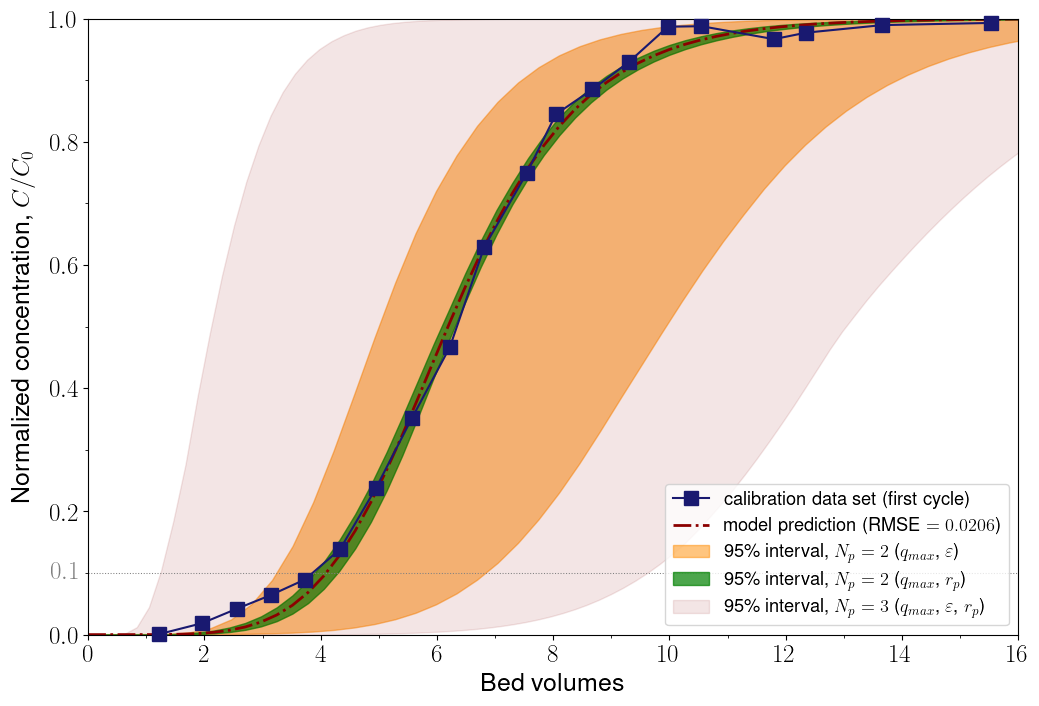

In [129]:
# Plot all simulations
size = 12
fig, ax1 = plt.subplots(figsize=(size, 8))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
    })

# Plot data
ax1.plot(texp1a, Cexp1a, color='midnightblue', linestyle='-', marker='s', markersize=10, label=f'calibration data set (first cycle)', zorder=3, clip_on=False)

# Plot model
ax1.plot(BV_calibrated1, C_calibration_model1, color='darkred', linewidth=2, linestyle='-.', label=f'model prediction (RMSE $= {RMSE_calibrated1:.4f}$)', clip_on=True)
# ax1.plot(BV_calibrated2, C_calibration_model2, color='darkorange', linewidth=2, linestyle='--', label=f'model (RMSE $= {RMSE_calibrated2:.4f}$)', clip_on=True)
# ax1.plot(BV_calibrated3, C_calibration_model3, color='darkred', linewidth=2, linestyle='--', label=f'model (RMSE $= {RMSE_calibrated3:.4f}$)', clip_on=True)

# Plot uncertainty bands
prediction_interval = 95


ax1.fill_between(time2[0,:],
                 np.percentile(sims2, 50 - prediction_interval/2., axis=0),
                 np.percentile(sims2, 50 + prediction_interval/2., axis=0),
                 alpha=0.5, color='darkorange',
                 label=f"{prediction_interval:d}\% interval, $N_p = 2$ ($q_{{max}}$, $\\varepsilon$)")

ax1.fill_between(time1[0,:],
                 np.percentile(sims1, 50 - prediction_interval/2., axis=0),
                 np.percentile(sims1, 50 + prediction_interval/2., axis=0),
                 alpha=0.7, color='green',
                 label=f"{prediction_interval:d}\% interval, $N_p = 2$ ($q_{{max}}$, $r_p$)")


Cmin = 0.5
tmin = 1

ax1.fill_between(time3[0,:],
                 np.percentile(sims3[np.where((time3[:,-1] >= tmin) & (sims3[:,-1] >= Cmin))[0],:], 50 - prediction_interval/2., axis=0),
                 np.percentile(sims3[np.where((time3[:,-1] >= tmin) & (sims3[:,-1] >= Cmin))[0],:], 50 + prediction_interval/2., axis=0),
                 alpha=0.1, color='darkred',
                 label=f"{prediction_interval:d}\% interval, $N_p = 3$ ($q_{{max}}$,  $\\varepsilon$, $r_p$)")

ax1.set_ylabel('Normalized concentration, $C/C_0$', fontsize=1.5*size, labelpad=10)
ax1.set_yticks(np.arange(0, 1, 0.1), minor=True)
ax1.tick_params(labelsize=1.5*size)
ax1.set_ylim(0, 1)
ax1.set_xlim(0, 16)
ax1.set_xticks(np.arange(0, 17, 2))
ax1.set_xticks(np.arange(0, 17, 1), minor=True)
ax1.set_xlabel('Bed volumes', fontsize=1.5*size)
ax1.legend(loc='lower right', fontsize=1.1*size)

ax1.text(-0.15, 0.1, "$0.1$", color='grey', fontsize=1.5*size, ha='right', va='center')
ax1.hlines(0.1, 0, 16, color='grey', linestyle=':', lw=0.75)

# Store figure
plt.savefig(f"Figure_8_uncertainty.pdf", format="pdf", bbox_inches="tight")


## Validation

Validation of second cycle. Assumptions:
- 5% fouling

### Calibration of qmax and rp for C0=672 mg/L

In [59]:
qmax_rp_lm_cf = calibration(method='lm', algorithm='cf', tol=1e-4, qmax=0.291, rp=3.75e-4)

Experimental data for calibration: exp1a
Parameters to calibrate: ['qmax', 'rp']
Original values: [0.291    0.000375]
Method: Levenberg-Marquardt
Algorithm: Curve-fitting
Run 1: {'qmax': 0.291, 'rp': 0.000375}
Run 2: {'qmax': 0.291, 'rp': 0.000375}
Run 3: {'qmax': 0.291, 'rp': 0.000375}
Run 4: {'qmax': 0.2910000043362379, 'rp': 0.000375}
Run 5: {'qmax': 0.291, 'rp': 0.00037500000558793545}
Run 6: {'qmax': 0.32872462823540405, 'rp': 0.0004920260682109179}
Run 7: {'qmax': 0.3287246331337827, 'rp': 0.0004920260682109179}
Run 8: {'qmax': 0.32872462823540405, 'rp': 0.0004920260755426777}
Run 9: {'qmax': 0.3259102736190668, 'rp': 0.0004339664161363243}
Run 10: {'qmax': 0.32591027847550835, 'rp': 0.0004339664161363243}
Run 11: {'qmax': 0.3259102736190668, 'rp': 0.0004339664226029278}
Run 12: {'qmax': 0.3262103560539786, 'rp': 0.0004317909742104078}
Run 13: {'qmax': 0.3262103609148917, 'rp': 0.0004317909742104078}
Run 14: {'qmax': 0.3262103560539786, 'rp': 0.0004317909806445947}
Run 15: {'qmax

In [60]:
qmax = qmax_rp_lm_cf['params']['qmax']
rp = qmax_rp_lm_cf['params']['rp']
qmax, rp

(0.32619983527566204, 0.00043138665770629277)

f0b0a5 running: t: 5.92: : 60it [00:02, 20.85it/s]                       


No. of parameters = 2
RMSE (calibration) = 0.0206
SSR (calibration) = 0.0085
AIC (calibration, original) = -151.3
AIC (calibration, corrected) = -150.6
BIC (calibration) = -149.3


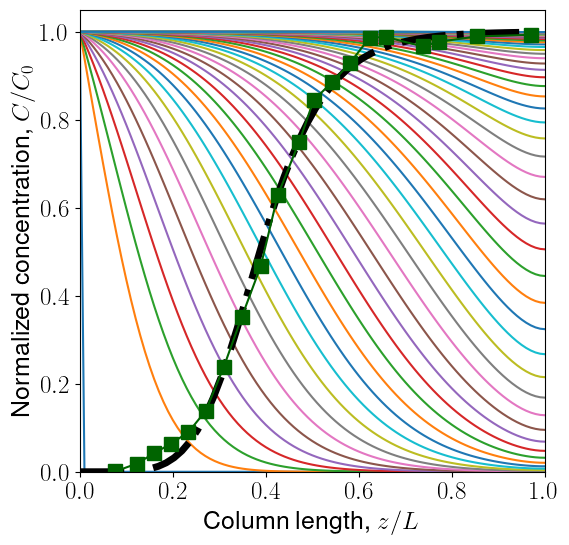

In [61]:
results_calibrated, _, _ = model(dt = 0.1, profiles=True, breakthrough=False, tmax=5.92, qmax=qmax, rp=rp, q0=None, Np=2)

In [62]:
C_calibrated = results_calibrated['Cint']
C_calibrated_model = results_calibrated['BC']
BV_calibrated_model = results_calibrated['BV']
RMSE_calibrated_model = results_calibrated['RMSE']

Breakthrough time

In [63]:
t10_1st_cycle = results_calibrated['BV'][np.where(results_calibrated['BC'] >= 0.1)[0][0]]
t10_1st_cycle

4.324324324324326

In [64]:
t10 = np.linspace(0, 25, 1000)
t10_1st_cycle = t10[np.where(np.interp(t10, results_calibrated['BV'], results_calibrated['BC']) >= 0.1)[0][0]]
t10_1st_cycle

4.104104104104104

In [65]:
t10 = np.linspace(0, 25, 1000)
t10_1st_cycle_data = t10[np.where(np.interp(t10, texp1a, Cexp1a) >= 0.1)[0][0]]
t10_1st_cycle_data = 3.8
t10_1st_cycle_data

3.8

In [66]:
100*t10_1st_cycle/t10_1st_cycle_data-100

8.002739581686967

Saturation time

In [67]:
t90 = np.linspace(0, 25, 1000)
t90_1st_cycle = t90[np.where(np.interp(t90, results_calibrated['BV'], results_calibrated['BC']) >= 0.9)[0][0]]
t90_1st_cycle

8.983983983983984

In [68]:
t90_1st_cycle_data = t90[np.where(np.interp(t10, texp1a, Cexp1a) >= 0.9)[0][0]]
t90_1st_cycle_data = 8.8
t90_1st_cycle_data

8.8

In [69]:
100*t90_1st_cycle/t90_1st_cycle_data-100

2.0907270907270856

### Calculation of q0 for second cycle

In [70]:
C_in = 672/31
Kl = 1.
# qmax = 0.326
qm = qmax * Kl * C_in/(1 + Kl * C_in) # 0.312 mmol/g of maximum adsorption capacity for C0 = 672 mg/L
qm

0.31181548976563994

In [71]:
rho_p = qmax_rp_lm_cf['params']['rho_p'] 
V = qmax_rp_lm_cf['params']['V'] 

m = rho_p * 1e-3 * V * 1e6 	# 3.112 g of resin in the column (8 mL)
print('m =', m) 

q1 = 1.7/31 / m 			# 0.0171 mmol/g adsorbed/fouled in the resin after the first cycle
print("Profile of initial concentration in the resin after the regeneration")
print('q =', q) 

q0_second = q1 
print("Initial concentration in the resin before the second cycle")
print('q0 =', q0_second)			# 0.0171 mmol/g of fouled resin

pfouled = q1/qm
print("Percentage of fouled resin in the column")
print('pfouled =', pfouled) # 0.056 (5.6% of the resin is fouled)

m = 3.0551988556160743
Profile of initial concentration in the resin after the regeneration
q = [1.45500000e-01 1.45500000e-01 1.45500000e-01 1.45500000e-01
 1.45500000e-01 1.45500000e-01 1.45500000e-01 1.45500000e-01
 1.45500000e-01 1.45500000e-01 1.45500000e-01 1.45500000e-01
 1.45500000e-01 1.45500000e-01 1.45500000e-01 1.45500000e-01
 1.45500000e-01 1.45500000e-01 1.45500000e-01 1.41090939e-01
 1.36681879e-01 1.32272818e-01 1.27863758e-01 1.23454697e-01
 1.19045636e-01 1.14636576e-01 1.10227515e-01 1.05818455e-01
 1.01409394e-01 9.70003333e-02 9.25912727e-02 8.81822121e-02
 8.37731515e-02 7.93640909e-02 7.49550303e-02 7.05459697e-02
 6.61369091e-02 6.17278485e-02 5.73187879e-02 5.29097273e-02
 4.85006667e-02 4.40916061e-02 3.96825455e-02 3.52734848e-02
 3.08644242e-02 2.64553636e-02 2.20463030e-02 1.76372424e-02
 1.32281818e-02 8.81912121e-03 4.41006061e-03 1.00000000e-06
 1.00000000e-06 1.00000000e-06 1.00000000e-06 1.00000000e-06
 1.00000000e-06 1.00000000e-06 1.00000000e-06 1.00

### Validation: 2nd cycle

qm = 0.3139271583331582
q0 = 0.017949309445640403
pfouled = 0.05717666971199582


5fe1b6 running: t: 5.92: : 60it [00:02, 20.99it/s]                       


No. of parameters = 2
RMSE (calibration) = 0.0653
SSR (calibration) = 0.0938
AIC (calibration, original) = -103.2
AIC (calibration, corrected) = -102.5
BIC (calibration) = -101.2


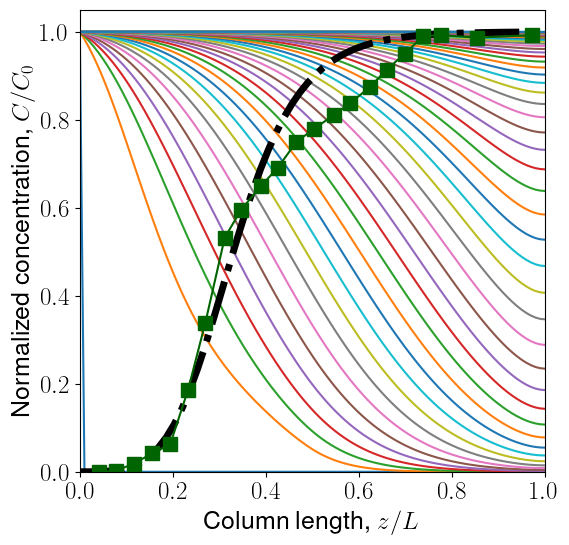

In [72]:
results_validated, params, _ = model(dt = 0.1, profiles=False, breakthrough=False, tmax=5.92, qmax=qmax, rp=rp, q0=q1, expdata='exp2a', Np=2)
C_validated = results_validated['Cint']
C_validated_model = results_validated['BC']
BV_validated_model = results_validated['BV']
RMSE_validated_model = results_validated['RMSE']

plot_profiles(results_validated, params)

In [73]:
t10_2nd_cycle = results_validated['BV'][np.where(results_validated['BC'] >= 0.1)[0][0]]
t10_2nd_cycle

3.2432432432432434

In [74]:
# Calibrate qmax and rp with C0=713 mg/L
fixed_parameters = dict(q0=q1, tmax=6.6, Np=2, expdata='exp2a')
calibrated_parameters = dict(qmax=qmax, rp=rp)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'q0': 0.017949309445640403, 'tmax': 6.6, 'Np': 2, 'expdata': 'exp2a'}), ('calibrated_parameters', {'qmax': 0.32619983527566204, 'rp': 0.00043138665770629277})])


qm = 0.3139271583331582
q0 = 0.017949309445640403
pfouled = 0.05717666971199582


e80a3c running: t: 6.6: : 66it [00:03, 21.55it/s]                        


Validation data: exp2a
No. of parameters = 2
RMSE (validation) = 0.0653
SSR (validation) = 0.0938
AIC (validation, original) = -103.2
AIC (validation, corrected) = -102.5
BIC (validation) = -101.2


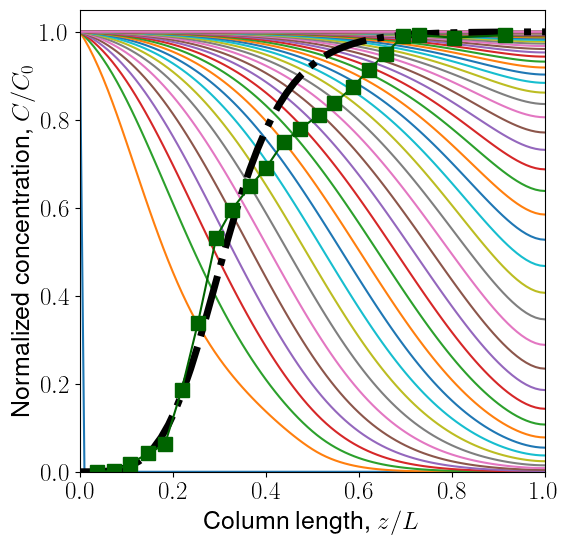

In [75]:
results_validated2, params2, container = model_calibration(expdata='exp2a', profiles=True, **parameters)

In [211]:
[print(params[param] == params2[param], param, params[param], params2[param]) for param in params]

[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True] z [0.    0.001 0.002 0.003 0.004 0.005 0.006 0.007 0.008 0.009 0.01  0.011
 0.012 0.013 0.014 0.015 0.016 0.017 0.018 0.019 0.02  0.021 0.022 0.023
 0.024 0.025 0.026 0.027 0.028 0.029 0.03  0.031 0.032 0.033 0.034 0.035
 0.036 0.037 0.038 0.039 0.04  0.041 0.042 0.043 0.044 0.045 0.046 0.047
 0.048 0.049 0.05  0.051 0.052 0.053 0.054 0.055 0.056 0.057 0.058 0.059
 0.06  0.061 0.06

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

Breakthrough time

In [76]:
t10_2nd_cycle = results_validated2['BV'][np.where(results_validated2['BC'] >= 0.1)[0][0]]
t10_2nd_cycle

3.2432432432432434

In [77]:
t10 = np.linspace(0, 25, 1000)
t10_2nd_cycle = t10[np.where(np.interp(t10, results_validated2['BV'], results_validated2['BC']) >= 0.1)[0][0]]
t10_2nd_cycle

3.1781781781781784

In [78]:
t10 = np.linspace(0, 25, 1000)
t10_2nd_cycle_data = t10[np.where(np.interp(t10, texp2a, Cexp2a) >= 0.1)[0][0]]
t10_2nd_cycle_data = 3.2
t10_2nd_cycle_data

3.2

In [79]:
100*t10_2nd_cycle/t10_2nd_cycle_data-100

-0.6819319319319277

Saturation time

In [80]:
t90 = np.linspace(0, 25, 1000)
t90_2nd_cycle = t90[np.where(np.interp(t90, results_validated2['BV'], results_validated2['BC']) >= 0.9)[0][0]]
t90_2nd_cycle

8.083083083083084

In [81]:
t90_2nd_cycle_data = t90[np.where(np.interp(t10, texp2a, Cexp2a) >= 0.9)[0][0]]
t90_2nd_cycle_data = 10.3
t90_2nd_cycle_data

10.3

In [82]:
100*t90_2nd_cycle/t90_2nd_cycle_data-100

-21.523465212785595

### Validation: 3rd cycle

In [83]:
# Fouling after second cycle
q = 15.8/31 / m # 0.159 mmol/g adsorbed/fouled in the resin after the second cycle
print('q =', q)
q2 = q  # 53.5 % fouled after the second cycle
print('q0 =', q2)

q = 0.1668229936712461
q0 = 0.1668229936712461


qm = 0.3139271583331582
q0 = 0.1668229936712461
pfouled = 0.531406694970314


18a736 running: t: 5.92: : 60it [00:02, 21.52it/s]                       


No. of parameters = 2
RMSE (calibration) = 0.0755
SSR (calibration) = 0.1254
AIC (calibration, original) = -97.4
AIC (calibration, corrected) = -96.7
BIC (calibration) = -95.4


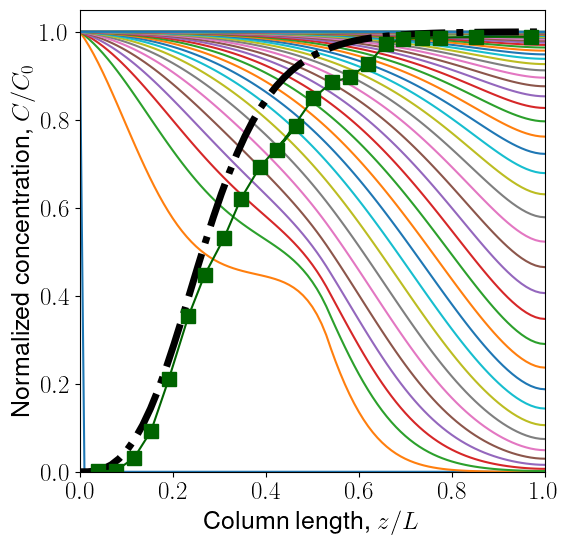

In [84]:
results_validated3, params3, _ = model(dt = 0.1, profiles=False, breakthrough=False, tmax=5.92, qmax=qmax, rp=rp, q0=q2, expdata='exp3a', Np=2)
C_validated2 = results_validated3['Cint']
C_validated_model2 = results_validated3['BC']
BV_validated_model2 = results_validated3['BV']
RMSE_validated_model2 = results_validated3['RMSE']

plot_profiles(results_validated3, params3)

In [85]:
# Calibrate qmax and rp with C0=713 mg/L
fixed_parameters = dict(q0=q2, tmax=6.6, Np=2, expdata='exp3a')
calibrated_parameters = dict(qmax=qmax, rp=rp)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'q0': 0.1668229936712461, 'tmax': 6.6, 'Np': 2, 'expdata': 'exp3a'}), ('calibrated_parameters', {'qmax': 0.32619983527566204, 'rp': 0.00043138665770629277})])


qm = 0.3139271583331582
q0 = 0.1668229936712461
pfouled = 0.531406694970314


b51371 running: t: 6.6: : 66it [00:03, 21.83it/s]                        


Validation data: exp3a
No. of parameters = 2
RMSE (validation) = 0.0755
SSR (validation) = 0.1254
AIC (validation, original) = -97.4
AIC (validation, corrected) = -96.7
BIC (validation) = -95.4


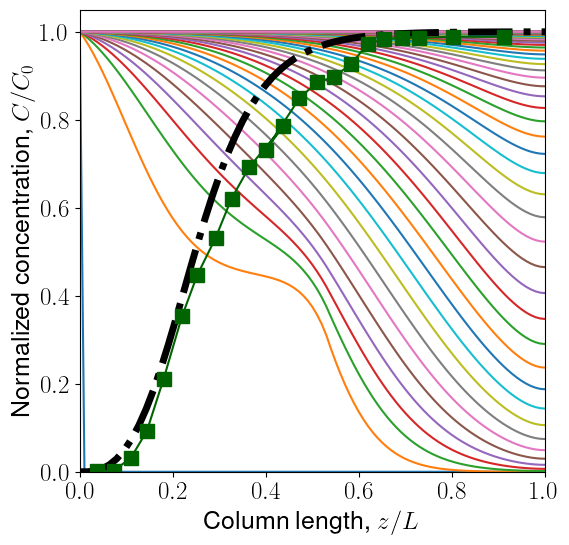

In [86]:
results_validated3, params3, container = model_calibration(expdata='exp3a', profiles=True, **parameters)

Breakthrough time

In [87]:
t10_3rd_cycle = results_validated3['BV'][np.where(results_validated3['BC'] >= 0.1)[0][0]]
t10_3rd_cycle

2.1621621621621623

In [88]:
t10 = np.linspace(0, 25, 1000)
t10_3rd_cycle = t10[np.where(np.interp(t10, results_validated3['BV'], results_validated3['BC']) >= 0.1)[0][0]]
t10_3rd_cycle

2.1271271271271273

In [89]:
t10 = np.linspace(0, 25, 1000)
t10_3rd_cycle_data = t10[np.where(np.interp(t10, texp3a, Cexp3a) >= 0.1)[0][0]]
t10_3rd_cycle_data = 2.4
t10_3rd_cycle_data

2.4

In [90]:
100*t10_3rd_cycle/t10_3rd_cycle_data-100

-11.3697030363697

Saturation time

In [91]:
t90 = np.linspace(0, 25, 1000)
t90_3rd_cycle = t90[np.where(np.interp(t90, results_validated3['BV'], results_validated3['BC']) >= 0.9)[0][0]]
t90_3rd_cycle

7.107107107107107

In [92]:
t90 = np.linspace(0, 25, 1000)
t90_3rd_cycle_data = t90[np.where(np.interp(t10, texp3a, Cexp3a) >= 0.9)[0][0]]
t90_3rd_cycle_data = 9.3
t90_3rd_cycle_data

9.3

In [93]:
100*t90_3rd_cycle/t90_3rd_cycle_data-100

-23.5794934719666

### Validation: test set

#### C0 = 713 mg/L

#### Validation

In [94]:
# Calibrate qmax and rp with C0=713 mg/L
fixed_parameters = dict(C0=713/31, tmax=5.92)
calibrated_parameters = dict(qmax=qmax, rp=rp)
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'C0': 23.0, 'tmax': 5.92}), ('calibrated_parameters', {'qmax': 0.32619983527566204, 'rp': 0.00043138665770629277})])


bc99d7 running: t: 5.92: : 60it [00:02, 20.18it/s]                       


Validation data: validation
No. of parameters = 2
RMSE (validation) = 0.0550
SSR (validation) = 0.0997
AIC (validation, original) = -102.0
AIC (validation, corrected) = -101.3
BIC (validation) = -100.0


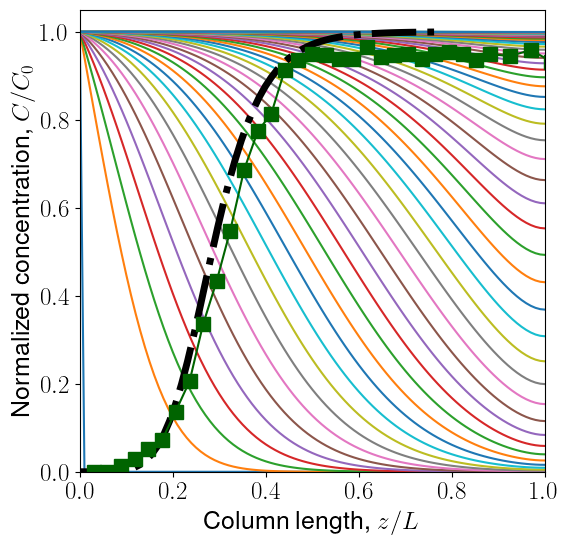

In [95]:
results, params, container = model_calibration(expdata='validation', profiles=True, progress=True, **parameters) # type: ignore

In [96]:
C_validated3 = results['Cint']
C_validated_model3 = results['BC']
BV_validated_model3 = results['BV']
RMSE_validated_model3 = results['RMSE']

Breakthrough time

In [97]:
t10_validation = results['BV'][np.where(results['BC'] >= 0.1)[0][0]]
t10_validation

4.054054054054054

In [98]:
t10 = np.linspace(0, 25, 100)
t10_validation = t10[np.where(np.interp(t10, results['BV'], results['BC']) >= 0.1)[0][0]]
t10_validation

4.040404040404041

In [99]:
t10 = np.linspace(0, 6.6, 1000)
t10_validation_data = t10[np.where(np.interp(t10, tval, Cval) >= 0.1)[0][0]]
# t10_validation_data = 4.3
t10_validation_data

3.9837837837837835

In [100]:
100*t10_validation/t10_validation_data-100

1.421268314077011

Saturation time

In [101]:
t90_validation = results['BV'][np.where(results['BC'] >= 0.9)[0][0]]
t90_validation

8.918918918918925

In [102]:
t90 = np.linspace(0, 25, 100)
t90_validation = t90[np.where(np.interp(t90, results['BV'], results['BC']) >= 0.9)[0][0]]
t90_validation

8.83838383838384

In [103]:
t90 = np.linspace(0, 25, 100)
t90_validation_data = t90[np.where(np.interp(t90, tval, Cval) >= 0.9)[0][0]]
# t10_validation_data = 4.3
t90_validation_data

9.343434343434344

In [104]:
100*t90_validation/t90_validation_data-100

-5.4054054054054035

#### Uncalibrated model

In [105]:
# Simulate C0=713 mg/L with original parameter values
fixed_parameters = dict(C0=713/31, tmax=7.)
calibrated_parameters = dict()
parameters = {'fixed_parameters': fixed_parameters, 'calibrated_parameters': calibrated_parameters}
print(parameters.items())

dict_items([('fixed_parameters', {'C0': 23.0, 'tmax': 7.0}), ('calibrated_parameters', {})])


53d566 running: t: 7: : 70it [00:03, 21.43it/s]                          


Validation data: validation
No. of parameters = 0
RMSE (validation) = 0.1088
SSR (validation) = 0.3910
AIC (validation, original) = -78.7
AIC (validation, corrected) = -78.7
BIC (validation) = -78.7


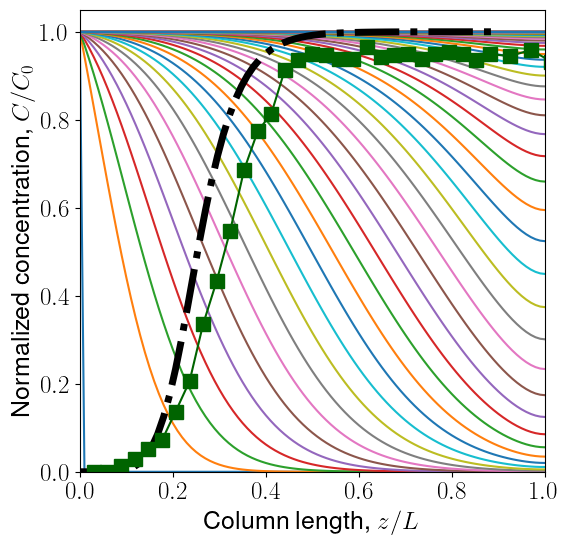

In [106]:
results_uncalibrated, params, container = model_calibration(expdata='validation', profiles=True, progress=True, **parameters) # type: ignore

Breakthrough time

In [107]:
t10_validation = results_uncalibrated['BV'][np.where(results_uncalibrated['BC'] >= 0.1)[0][0]]
t10_validation

3.7837837837837847

In [108]:
t10 = np.linspace(0, 25, 100)
t10_validation = t10[np.where(np.interp(t10, results_uncalibrated['BV'], results_uncalibrated['BC']) >= 0.1)[0][0]]
t10_validation

3.787878787878788

In [109]:
t10 = np.linspace(0, 6.6, 1000)
t10_validation_data = t10[np.where(np.interp(t10, tval, Cval) >= 0.1)[0][0]]
t10_validation_data = 4.0
t10_validation_data

4.0

In [110]:
100*t10_validation/t10_validation_data-100

-5.303030303030297

Saturation time

In [111]:
t90_validation = results_uncalibrated['BV'][np.where(results_uncalibrated['BC'] >= 0.9)[0][0]]
t90_validation

7.567567567567571

In [112]:
t90 = np.linspace(0, 25, 100)
t90_validation = t90[np.where(np.interp(t90, results_uncalibrated['BV'], results_uncalibrated['BC']) >= 0.9)[0][0]]
t90_validation

7.575757575757576

In [113]:
t90 = np.linspace(0, 25, 100)
t90_validation_data = t90[np.where(np.interp(t90, tval, Cval) >= 0.9)[0][0]]
t10_validation_data = 9.3
t90_validation_data

9.343434343434344

In [114]:
100*t90_validation/t90_validation_data-100

-18.91891891891892

### Plot all simulations

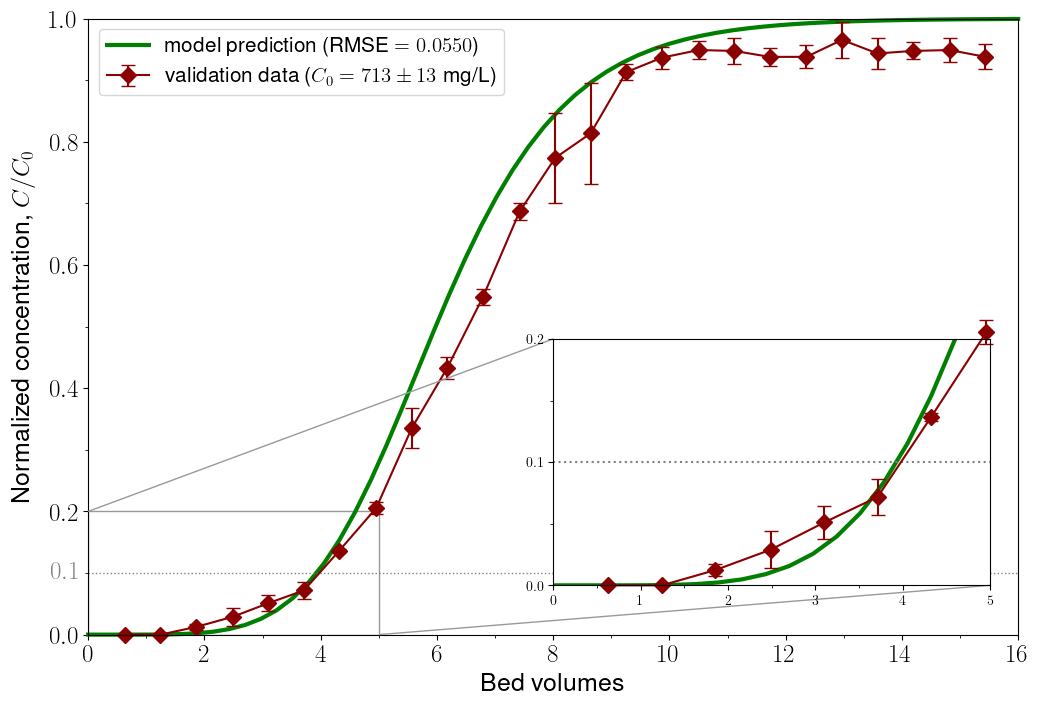

In [117]:
# Plot all simulations
size = 12
fig, ax1 = plt.subplots(figsize=(size, 8))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
    })

ax1.set_clip_on(False)

# Plot model
ax1.plot(BV_validated_model3, C_validated_model3, color='green', linewidth=3, linestyle='-', label=f'model prediction (RMSE $= {RMSE_validated_model3:.4f}$)', clip_on=False, zorder=2)

# Plot data
npoints = 25
# ax1.plot(tval, Cval, color='darkred', linewidth=1, linestyle='-', marker='D', markersize=10, zorder=2, label=f'validation data', clip_on=False)
ax1.errorbar(tval[:npoints], Cval[:npoints], yerr=(1*Cerr[:npoints]), fmt='-', color='darkred', marker='D', markersize=8, zorder=2, capsize=5, label=f'validation data ($C_0 = 713 \pm 13$ mg/L)', clip_on=False)

ax1.text(-0.15, 0.1, "$0.1$", color='grey', fontsize=1.5*size, ha='right', va='center')
ax1.hlines(0.1, 0, 16, color='grey', linestyle=':', lw=1)
ax1.set_ylabel('Normalized concentration, $C/C_0$', fontsize=1.5*size, labelpad=10)
ax1.set_yticks(np.linspace(0, 1, 11))
ax1.tick_params(labelsize=1.5*size)
ax1.set_ylim(0, 1)
ax1.legend(loc='upper left', fontsize=1.25*size)
ax1.set_xlim(0, 16)
ax1.set_yticks(np.arange(0, 1.1, 0.2))
ax1.set_yticks(np.arange(0, 1.1, 0.1), minor=True)
ax1.set_xticks(np.arange(0, 17, 2))
ax1.set_xticks(np.arange(0, 16, 1), minor=True)
ax1.set_xlabel('Bed volumes', fontsize=1.5*size)

# Inset graph
from mpl_toolkits.axes_grid.inset_locator import (inset_axes, InsetPosition, mark_inset) # type: ignore
# Create a set of inset Axes: these should fill the bounding box allocated to them.
ax2 = plt.axes([0, 0, 1, 1]) # type: ignore
# Manually set the position and relative size of the inset axes within ax1
ip = InsetPosition(ax1, [0.5,0.08,0.47,0.4])
ax2.set_axes_locator(ip)
# Mark the region corresponding to the inset axes on ax1 and draw lines in grey linking the two axes.
mark_inset(ax1, ax2, loc1=2, loc2=4, fc="none", ec='0.6')
# The data: only display for low temperature in the inset figure.
tmaxmin = 7

# ax2.fill_between(time[0,:],
#                  np.percentile(sims, 50 - prediction_interval/2., axis=0),
#                  np.percentile(sims, 50 + prediction_interval/2., axis=0),
#                  alpha=0.4, color='midnightblue',
#                  label=f"{prediction_interval:d}\% prediction interval")


# Plot model
ax2.plot(BV_validated_model3, C_validated_model3, color='green', linewidth=3)

# Plot data
npoints = 8
# ax2.plot(texp1a, 672*Cexp1a, color='midnightblue', linestyle='-', marker='s', markersize=10,    label=f'calibration data $C_0 = 672$ mg/L', zorder=3)
ax2.errorbar(tval[:npoints], Cval[:npoints], yerr=(1*Cerr[:npoints]), fmt='-', color='darkred', marker='D', markersize=8, zorder=2, capsize=5, label=f'validation data,  $C_0 = 713$ mg/L', clip_on=False)
# ax2.plot(tval[:8], Cval[:8], color='darkred', linewidth=1, linestyle='-', marker='D', markersize=10, zorder=2, clip_on=False)

# ax2.plot([0, 16],[0.05,0.05], color='gray', linestyle=':')
# ax1.plot([0, 16],[0.1,0.1], color='gray', linestyle=':', alpha=0.5)

ax2.set_xlim(0, 5)
ax2.set_ylim(0, 0.2)
ax2.set_xticks(np.arange(0, 6, 1))
ax2.set_xticks(np.arange(0, 4, 0.5), minor=True)
ax2.set_yticks(np.arange(0, 0.25, 0.1))
ax2.set_yticks(np.arange(0, 0.25, 0.05), minor=True)
ax2.hlines(0.1, 0, 16, color='grey', linestyle=':')

plt.savefig("Figure_9"+".pdf", format="pdf", bbox_inches="tight")

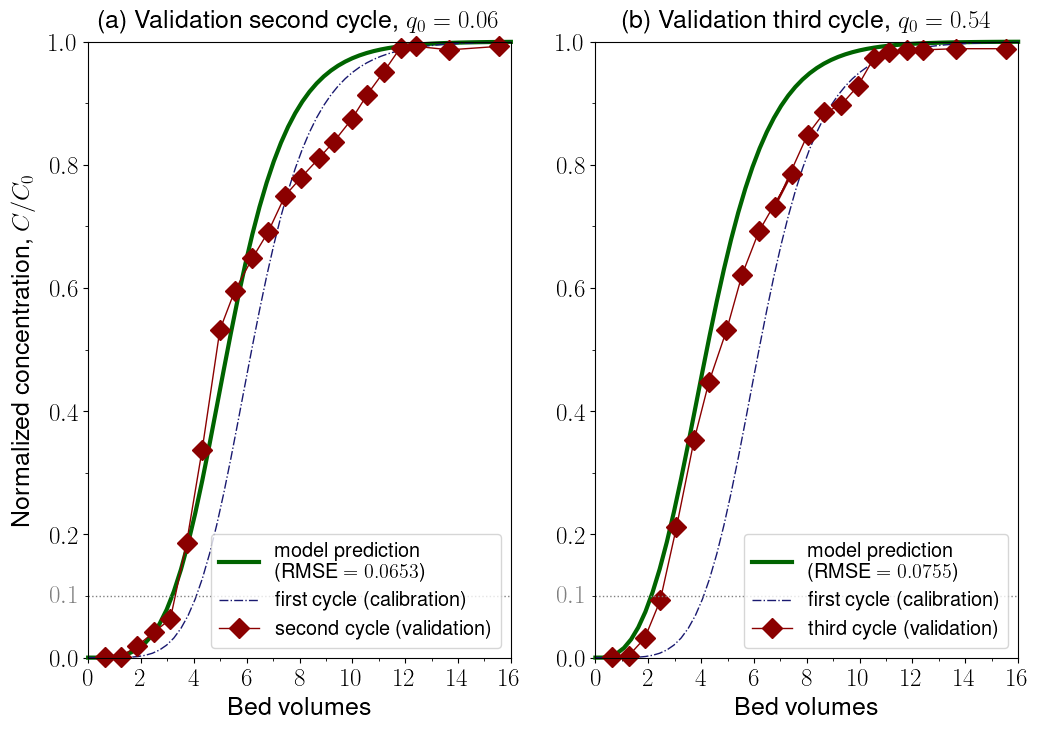

In [127]:
# Plot all simulations
size = 12
fig, ax1 = plt.subplots(nrows=1, ncols=2, figsize=(size, 8))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
    })

# Plot model
ax1[0].plot(BV_validated_model, C_validated_model, color='darkgreen', linewidth=3, linestyle='-', label=f'model prediction \n (RMSE $= {RMSE_validated_model:.4f}$)', clip_on=False)
ax1[1].plot(BV_validated_model2, C_validated_model2, color='darkgreen', linewidth=3, linestyle='-', label=f'model prediction \n (RMSE $= {RMSE_validated_model2:.4f}$)', clip_on=False)

# Plot calibration
ax1[0].plot(BV_calibrated_model, C_calibrated_model, color='midnightblue', linewidth=1, linestyle='-.', label=f'first cycle (calibration)', clip_on=False)
ax1[1].plot(BV_calibrated_model, C_calibrated_model, color='midnightblue', linewidth=1, linestyle='-.', label=f'first cycle (calibration)', clip_on=False)
# ax1[1].plot(BV_validated_model, C_validated_model, color='grey', linewidth=1, linestyle='-.', label=f'second cycle (validation)', clip_on=False)

# Plot data
ax1[0].plot(texp2a, Cexp2a, color='darkred', linewidth=1, linestyle='-', marker='D', markersize=10, zorder=2, label=f'second cycle (validation)', clip_on=False)
ax1[1].plot(texp3a, Cexp3a, color='darkred', linewidth=1, linestyle='-', marker='D', markersize=10, zorder=2, label=f'third cycle (validation)', clip_on=False)

ax1[0].text(-0.35, 0.1, "$0.1$", color='grey', fontsize=1.5*size, ha='right', va='center')
ax1[0].hlines(0.1, 0, 16, color='grey', linestyle=':', lw=1)
ax1[0].set_ylabel('Normalized concentration, $C/C_0$', fontsize=1.5*size, labelpad=10)
ax1[0].set_yticks(np.linspace(0, 1, 11))
ax1[0].tick_params(labelsize=1.5*size)
ax1[0].set_ylim(0, 1)
ax1[0].legend(loc='best', fontsize=1.2*size)
ax1[0].set_xlim(0, 16) 
ax1[0].set_yticks(np.arange(0, 1.1, 0.2))
ax1[0].set_yticks(np.arange(0, 1.1, 0.1), minor=True)
ax1[0].set_xticks(np.arange(0, 17, 2))
ax1[0].set_xticks(np.arange(0, 16, 1), minor=True)
ax1[0].set_xlabel('Bed volumes', fontsize=1.5*size)
ax1[0].set_title(f'(a) Validation second cycle, $q_0 = {q1/qm:.2f}$', fontsize=1.5*size, pad=10)

ax1[1].text(-0.36, 0.1, "$0.1$", color='grey', fontsize=1.5*size, ha='right', va='center')
ax1[1].hlines(0.1, 0, 16, color='grey', linestyle=':', lw=1)
# ax1[1].set_ylabel('Normalized concentration, $C/C_0$', fontsize=1.5*size, labelpad=10)
ax1[1].set_yticks(np.linspace(0, 1, 11))
ax1[1].tick_params(labelsize=1.5*size)
ax1[1].set_ylim(0, 1)
ax1[1].legend(loc='best', fontsize=1.2*size)
ax1[1].set_xlim(0, 16) 
ax1[1].set_yticks(np.arange(0, 1.1, 0.2))
ax1[1].set_yticks(np.arange(0, 1.1, 0.1), minor=True)
ax1[1].set_xticks(np.arange(0, 17, 2))
ax1[1].set_xticks(np.arange(0, 16, 1), minor=True)
ax1[1].set_xlabel('Bed volumes', fontsize=1.5*size)
ax1[1].set_title(f'(b) Validation third cycle, $q_0 = {q2/qm:.2f}$', fontsize=1.5*size, pad=10)

plt.savefig("Figure_10"+".pdf", format="pdf", bbox_inches="tight")

## Figures

### Figure 2

In [71]:
def plot_figure_2(y, z, L, size=10):
    """
    Plot concentration profiles vs column length over time.
    """

    fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(2*size,size))

    plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
    # "text.latex.preamble" : r"\usepackage{amsmath}"
    })

    for axis in ax:
        axis.set_clip_on(False)

    every = 7
    
	# Profiles

    for i in [1, 3]:
        ax[0].plot(z/L, y[i,:], color='midnightblue', lw=1)
        ax[0].plot(1, y[i,-1], 'o', color='midnightblue', markersize=5, clip_on=False)

    for i in range(1, len(y), every):
        ax[0].plot(z/L, y[i,:], color='midnightblue', lw=1)
        ax[0].plot(1, y[i,-1], 'o', color='midnightblue', markersize=5, clip_on=False)

    ax[0].vlines(1, 0, 1, color='black', linestyle=':', lw=1, zorder=0)
    ax[0].text(1, 1.01, "column\noutlet", fontsize=2.5*size, color='black', ha='center', va='bottom')

    index = np.where(y[:,-1] > 0.1)[0][0]
    print(index)

    ax[0].hlines(0.1, 0, 1, color='darkorange', linestyle=':', lw=0.75)
    ax[0].text(-0.0275, 0.1, "$0.1$", color='darkorange', fontsize=2.5*size, ha='right', va='center')
    ax[0].plot(z/L, y[index,:], color='darkorange', linestyle='-', lw=3, clip_on=False, zorder=3)
    ax[0].plot(1, y[index,-1], '*', color='darkorange', markersize=12, clip_on=False, zorder=3)

    ax[0].set_xlabel('Column length, $z/L$', fontsize=3*size)
    ax[0].set_ylabel('Normalized concentration, $C/C_0$', fontsize=3*size)
    ax[0].set_xticks(np.arange(0, 1.1, 0.1), minor=True)
    ax[0].set_yticks(np.arange(0, 1.1, 0.1), minor=True)
    ax[0].tick_params(labelsize=2.5*size)
    ax[0].set_xlim(0, 1)
    ax[0].set_ylim(0, 1)
    # ax.legend(fontsize=40)
    ax[0].set_title('(a) Concentration profiles', fontsize=3*size)

    ax[0].arrow(0.2, 0.5, 0.6, 0, head_width=0.02, head_length=0.05, fc='black', ec='black', linestyle='-', zorder=10)

    # Breakthrough curve
    
    # ax[1].plot(BV, C, 'k-.', lw=2, label='model')
    ax[1].set_xlabel('Bed volumes', fontsize=3*size)
    ax[1].set_xlim(0, 16)
    ax[1].set_ylim(0, 1.)
    ax[1].set_xticks(np.arange(0, 17, 2), minor=False)
    ax[1].set_xticks(np.arange(0, 17, 1), minor=True)
    ax[1].set_yticks(np.arange(0, 1.1, 0.1), minor=True)
    ax[1].tick_params(labelsize=2.5*size)
    ax[1].set_title('(b) Breakthrough curve', fontsize=3*size)

    ax[1].plot(t[::every], C[::every], 'o', color='midnightblue', markersize=5, linestyle='-', label='process model', clip_on=False)
    ax[1].plot(t[index], C[index], '*', color='darkorange', markersize=12, linestyle='', label='breakthrough', clip_on=False)
    ax[1].text(-0.425, 0.1, "$0.1$", color='darkorange', fontsize=2.5*size, ha='right', va='center')
    ax[1].hlines(0.1, 0, 16, color='darkorange', linestyle=':', lw=0.75)

    # ax[1].scatter(texp1a, Cexp1a, color='darkgreen', marker='s', s=10*size, label='calibration set', clip_on=False)
    ax[1].legend(fontsize=3*size)

# Test function
# plot_figure_2(y, z, L, size=5)

249251 running: t: 6: : 600it [00:21, 27.72it/s]                            


RMSE (calibration) = 0.0865
SSR (calibration) = 0.1496
AIC (calibration) = -91.9


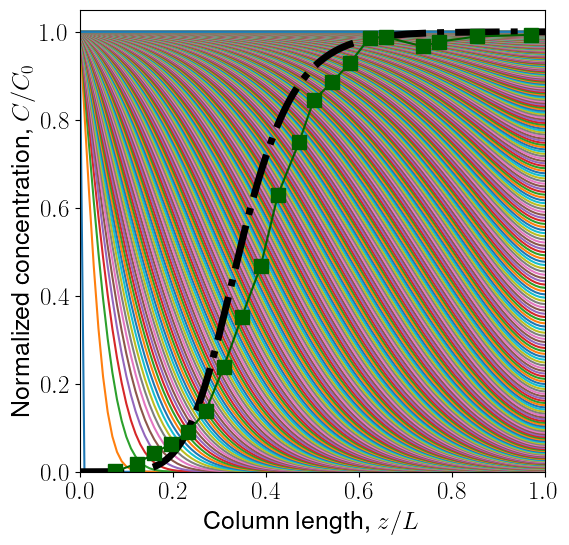

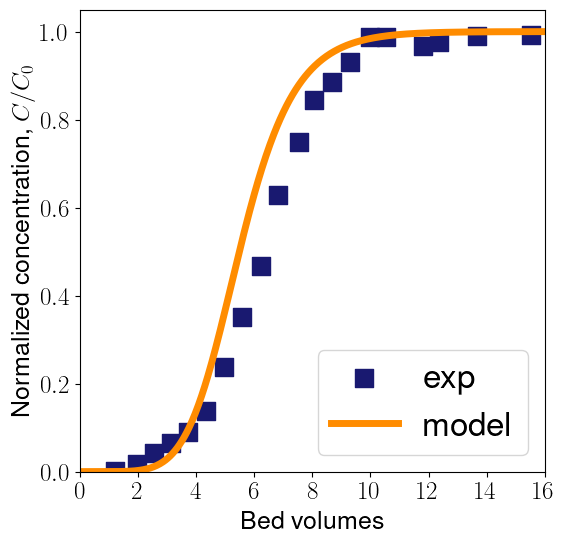

In [60]:
# Perform simulation
results, pars, cont = model(Nx=100, dt=0.01, tmax=6, isotherm='Langmuir', dimensionless=True, profiles=True, breakthrough=True)
z = results['params']['z']
L = results['params']['L']
y = results['C']
C = results['BC']
t = results['BV']

140


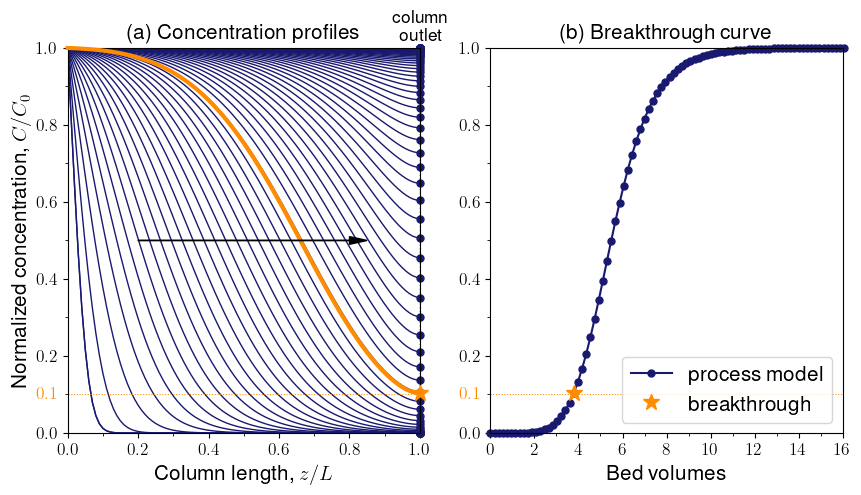

In [72]:
# Test function
plot_figure_2(y, z, L, size=5)

# Store figure
plt.savefig("Figure_2_profiles"+".pdf", format="pdf", bbox_inches="tight")

In [15]:
y[1,:]

array([1.00000000e+00, 8.14873040e-01, 6.33132612e-01, 4.67324211e-01,
       3.26897130e-01, 2.16423023e-01, 1.35550041e-01, 8.03272231e-02,
       4.50630732e-02, 2.39501847e-02, 1.20709536e-02, 5.77569500e-03,
       2.62698484e-03, 1.13754541e-03, 4.69914637e-04, 1.85795837e-04,
       7.07926681e-05, 2.64395487e-05, 1.01144408e-05, 4.37108556e-06,
       2.43710121e-06, 1.81300759e-06, 1.61980575e-06, 1.56238009e-06,
       1.54598159e-06, 1.54148107e-06, 1.54029392e-06, 1.53999303e-06,
       1.53991981e-06, 1.53990272e-06, 1.53989890e-06, 1.53989808e-06,
       1.53989791e-06, 1.53989788e-06, 1.53989788e-06, 1.53989788e-06,
       1.53989787e-06, 1.53989787e-06, 1.53989787e-06, 1.53989787e-06,
       1.53989787e-06, 1.53989787e-06, 1.53989787e-06, 1.53989787e-06,
       1.53989787e-06, 1.53989787e-06, 1.53989787e-06, 1.53989787e-06,
       1.53989787e-06, 1.53989787e-06, 1.53989787e-06, 1.53989787e-06,
       1.53989787e-06, 1.53989787e-06, 1.53989787e-06, 1.53989787e-06,
      

### Figure 3

C0: 0.19
Q: -0.02
L: -0.05
D: 0.03
rp: 0.07
rho_p: -0.19
e: 0.31
Dp: -0.02
Dz: 0.00
qmax: -0.39
Kl: -0.01


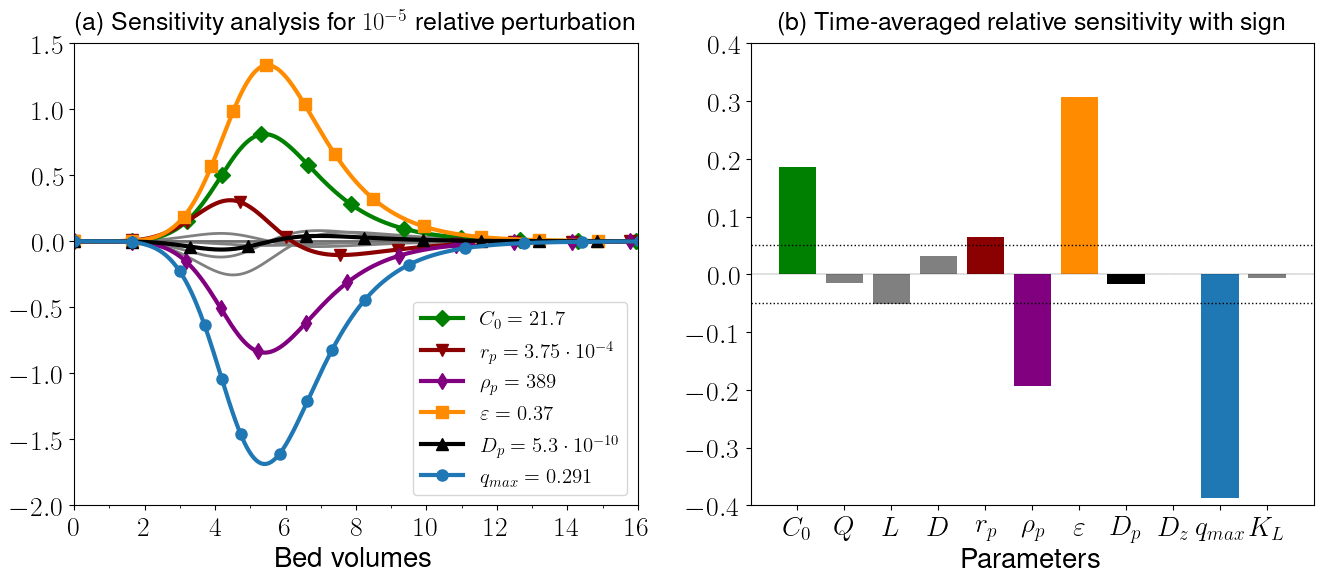

In [99]:
def plot_figure_3(sensitivities, labels=None, size=16, font=20, **parameters):
    
	# Plot sensitivity functions over time
	fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(size,6))
	# plt.suptitle('Local sensitivity analysis of breakthrough curve', fontsize=font+5, y=1.02, )

	plt.rcParams.update({
	"text.usetex": True,
	"font.family": "sans-serif",
	"font.sans-serif": "Helvetica",
	# "text.latex.preamble" : r"\usepackage{amsmath}"
	})

	ax[0].axhline(y=0., color='0', ls='-', lw=0.2)
	ax[1].axhline(y=0., color='0', ls=':', lw=0.2)

    # linestyles = ['--', '-.', '-.', '-.', '-.', '-.', '-.', '-.', '-.', '-.', ':', '-.']
    # markerstyles = ['^', '-', '-', '-', '-', '-', '-', '-', '-', '-', 'o', '-']
    
	# Scientific notation for exponential values
	def as_si(x, ndp):
		s = '{x:0.{ndp:d}e}'.format(x=x, ndp=ndp)
		m, e = s.split('e')
		if x < 1e-2:
			return '{m:s}\\cdot 10^{{{e:d}}}'.format(m=m, e=int(e))
		else:
			return '{x}'.format(x=x)

	names = []

	for parameter, value in parameters.items():
		
		t = sensitivities['t']
		S = sensitivities[parameter]
		
		# Plot all sensitivities and highlight most sensitive parameters
		N = 0.08
		Nm = 8
		if parameter != 'qmax' and parameter != 'e' and parameter != 'rp' and parameter != 'C0' and parameter != 'rho_p' and parameter != 'Dp':
			ax[0].plot(t, S, lw=2, color='gray', linestyle='-', zorder=-1)
		elif parameter == 'qmax':
			ax[0].plot(t, S, label=f"$q_{{max}} = {{{value:.3f}}}$", lw=3, linestyle='-', color='#1f77b4', marker='o', markersize=Nm, markevery=N)
		elif parameter == 'e':
			ax[0].plot(t, S, label=f"$\\varepsilon = {{{value:.2f}}}$", lw=3, linestyle='-', color='darkorange', marker='s', markersize=Nm, markevery=N)
		elif parameter == 'rp':
			ax[0].plot(t, S, label=f"$r_p = {{{as_si(value,2):s}}}$", lw=3, linestyle='-', color='darkred', marker='v', markersize=Nm, markevery=N)
		elif parameter == 'C0':
			ax[0].plot(t, S, label=f"$C_0 = {{{value:.1f}}}$", lw=3, linestyle='-', color='green', marker='D', markersize=Nm, markevery=N)
		elif parameter == 'rho_p':
			ax[0].plot(t, S, label=f"$\\rho_p = {{{value:.0f}}}$", lw=3, linestyle='-', color='purple', marker='d', markersize=Nm, markevery=N)
		elif parameter == 'Dp':
			ax[0].plot(t, S, label=f"$D_p = {{{as_si(value,1):s}}}$", lw=3, linestyle='-', color='black', marker='^', markersize=Nm, markevery=N)

	# ax[0].grid(True, axis='y', which='major', color='gray', linestyle='-', linewidth=0.5)
	ax[0].set_xlim(0, 16)
	ax[0].set_xlabel('Bed volumes', fontsize=font)
	# ax[0].set_ylabel(r'Relative sensitivity', fontsize=font)
	ax[0].set_xticks(np.arange(0, 17, 2), fontsize=font)
	ax[0].set_xticks(np.arange(0, 17, 1), fontsize=font, minor=True)    
	ax[0].set_yticks(np.arange(-2, 1.6, 0.5), fontsize=font)
	ax[0].set_title(r'(a) Sensitivity analysis for $10^{-5}$ relative perturbation', fontsize=0.9*font, pad=10)
	ax[0].legend(loc='lower right', fontsize=font*0.75)
	ax[0].tick_params(axis='x', labelsize=font)
	ax[0].tick_params(axis='y', labelsize=font)

	# Plot average sensitivity coefficients in a bar plot
	ax[1].axhline(y=0., color='0', ls='-', lw=0.1)

	for parameter, value in parameters.items():
		S = sensitivities[parameter]
		
		# Plot average sensitivity coefficient in a bar plot
		Smean = np.mean(np.abs(S))

		# label = dict(zip(parameters.keys(), labels))[parameter]

		if parameter != 'qmax' and parameter != 'e' and parameter != 'rp' and parameter != 'C0' and parameter != 'rho_p' and parameter != 'Dp':
			ax[1].bar(parameter, Smean*np.sign(np.mean(S)), color='gray')
		elif parameter == 'C0':
			ax[1].bar(parameter, Smean*np.sign(np.mean(S)), color='green')
		elif parameter == 'rp':
			ax[1].bar(parameter, Smean*np.sign(np.mean(S)), color='darkred')
		elif parameter == 'rho_p':
			ax[1].bar(parameter, Smean*np.sign(np.mean(S)), color='purple')
		elif parameter == 'e':
			ax[1].bar(parameter, Smean*np.sign(np.mean(S)), color='darkorange')
		elif parameter == 'Dp':
			ax[1].bar(parameter, Smean*np.sign(np.mean(S)), color='black')
		elif parameter == 'qmax':
			ax[1].bar(parameter, Smean*np.sign(np.mean(S)), color='#1f77b4')
		
		# Print sensitivity values
		print("{:s}: {:.2f}".format(parameter, np.mean(np.abs(S))*np.sign(np.mean(S))))

	# ax[1].grid(True, axis='y', which='major', color='gray', linestyle='-', linewidth=0.5)
	ax[1].set_ylim(-0.4, 0.4)
	ax[1].set_yticks(np.arange(-0.4, 0.41, 0.1), fontsize=font)
	ax[1].set_title(r'(b) Time-averaged relative sensitivity with sign', fontsize=0.9*font, pad=10)
	# ax[1].set_ylabel(r'Average relative sensitivity', fontsize=font)
	ax[1].tick_params(axis='x', labelsize=font)
	ax[1].tick_params(axis='y', labelsize=font)
	ax[1].set_xlabel('Parameters', fontsize=font)
	ax[1].set_xlim(-1, 11)

	if labels==None: 
		labels = parameters.keys()
		positions = range(len(labels)) 
		ax[1].set_xticks(positions, labels)
	else:
		labels = labels.values()
		positions = range(len(labels)) 
		ax[1].set_xticks(positions, labels)

	ax[1].hlines(0.05, -1, 11, color='k', linestyle=':', linewidth=1)
	ax[1].hlines(-0.05, -1, 11, color='k', linestyle=':', linewidth=1)

# Test function
plot_figure_3(S11, size=16, font=20,  
			  labels = dict(C0='$C_0$', Q='$Q$', L='$L$', D='$D$', rp='$r_p$', rho_p='$\\rho_p$', e='$\\varepsilon$', Dp='$D_p$', Dz='$D_z$', qmax='$q_{max}$', Kl='$K_L$'),
			  C0    = 672/31,
			  Q     = 1.5e-8, 
			  L     = 0.1, 
			  D     = 0.01, 
			  rp    = 0.5 * 7.5e-4, 
			  rho_p = 389, 
			  e     = 0.37, 
			  Dp    = 5.3e-10, 
			  Dz    = 3.2e-6,
			  qmax  = 0.291, 
			  Kl    = 1.18, 
			  )

# Store figure
plt.savefig("Figure_3_sensitivity"+".pdf", format="pdf", bbox_inches="tight")

### Figure 4

In [74]:
dt=0.02
tmax = 5.9
results_original, _, _ = model(dt = dt, profiles=False, breakthrough=False, qmax=0.291, C0=672/31, tmax=tmax) 
results_qmax, _, _ = model(dt = dt, profiles=False, breakthrough=False, qmax=0.291*1.10, e=0.37, C0=672/31, tmax=tmax) 
results_e, _, _ = model(dt = dt, profiles=False, breakthrough=False, qmax=0.291, e=0.37*1.10, C0=672/31, tmax=tmax) 
results_C0, _, _ = model(dt = dt, profiles=False, breakthrough=False, qmax=0.291, e=0.37, C0=672/31*1.10, tmax=5.8) 
results_rp, _, _ = model(dt = dt, profiles=False, breakthrough=False, qmax=0.291, e=0.37, C0=672/31, rp=0.5 * 7.5e-4*1.10, Dp=5.3e-10, tmax=tmax)


C1 = results_original['BC']
C2 = results_qmax['BC']
C3 = results_e['BC']
C4 = results_C0['BC']
C5 = results_rp['BC']

BV1 = results_original['BV']
BV2 = results_qmax['BV']
BV3 = results_e['BV']
BV4 = results_C0['BV']
BV5 = results_rp['BV']

RMSE1 = results_original['RMSE']
RMSE2 = results_qmax['RMSE']
RMSE3 = results_e['RMSE']
RMSE4 = results_C0['RMSE']
RMSE5 = results_rp['RMSE']

baac2d running: t: 5.9: 100%|██████████| 295/295.0 [00:11<00:00, 25.45it/s] 


RMSE (calibration) = 0.0865
SSR (calibration) = 0.1496
AIC (calibration) = -89.9


378f1d running: t: 5.9: 100%|██████████| 295/295.0 [00:11<00:00, 26.10it/s] 


RMSE (calibration) = 0.0274
SSR (calibration) = 0.0151
AIC (calibration) = -133.8


7bc587 running: t: 5.9: 100%|██████████| 295/295.0 [00:11<00:00, 26.34it/s] 


RMSE (calibration) = 0.1919
SSR (calibration) = 0.7363
AIC (calibration) = -56.0


348627 running: t: 5.8: : 290it [00:10, 26.75it/s]                          


RMSE (calibration) = 0.1168
SSR (calibration) = 0.2727
AIC (calibration) = -75.9


1eda31 running: t: 5.9: 100%|██████████| 295/295.0 [00:11<00:00, 25.99it/s] 


RMSE (calibration) = 0.0886
SSR (calibration) = 0.1570
AIC (calibration) = -82.9


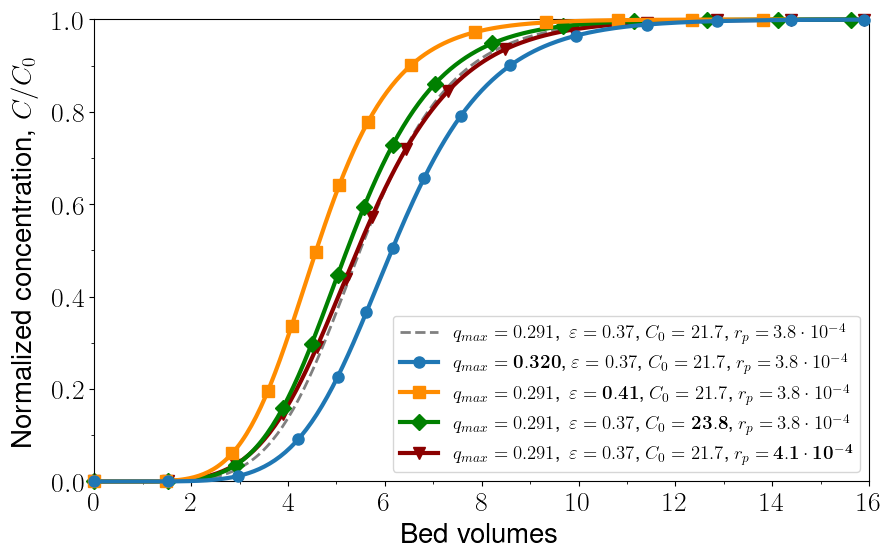

In [100]:
def plot_figure_4(labels=None, size=16, font=20, **parameters):

	## Plot impact of sensitive parameters on breakthrough curve
	size = 10
	fig, ax = plt.subplots(1, 1, figsize=(size,6))
	# plt.suptitle('Impact of parameter sensitivity on breakthrough curve', fontsize=font+5, y=1.05)

	plt.rcParams['text.usetex'] = True
    
	def as_si(x, ndp):
		s = '{x:0.{ndp:d}e}'.format(x=x, ndp=ndp)
		m, e = s.split('e')
		if x < 1e-2:
			return '{m:s}\\cdot 10^{{{e:d}}}'.format(m=m, e=int(e))
		else:
			return '{x}'.format(x=x)

	# Plot breakthrough curve with change in parameter value
	N = 0.08
	ax.plot(BV1, C1, '--', lw=2, color='gray', clip_on=False, label= r'$q_{{max}} = {{{0:.3f}}}$, $\,\varepsilon = {{{1:.2f}}}$, $C_0 = {{{2:.1f}}}$, $r_p = \,$'.format(0.291, 0.37, 672/31)+'${{{0:s}}}$'.format(as_si(0.5 * 7.5e-4, 1)), zorder=-1)
	ax.plot(BV2, C2, '-', lw=3, color='#1f77b4', markevery=N, marker='o', markersize=8, clip_on=False, label= r'$q_{{max}} = \mathbf{{{{{0:.3f}}}}}$, $\varepsilon = {{{1:.2f}}}$, $C_0 = {{{2:.1f}}}$, $r_p = \,$'.format(0.291 * 1.10, 0.37, 672/31)+'$ {{{0:s}}}$'.format(as_si(0.5 * 7.5e-4, 1)), zorder=4)
	ax.plot(BV3, C3, '-', lw=3, color='darkorange', markevery=N, marker='s', markersize=8, clip_on=False, label= r'$q_{{max}} = {{{0:.3f}}}$, $\,\varepsilon = \mathbf{{{{{1:.2f}}}}}$, $C_0 = {{{2:.1f}}}$, $r_p = \,$'.format(0.291, 0.37 * 1.10, 672/31)+'$ {{{0:s}}}$'.format(as_si(0.5 * 7.5e-4, 1)), zorder=3)
	ax.plot(BV4, C4, '-', lw=3, color='green', markevery=N, marker='D', markersize=8, clip_on=False, label= r'$q_{{max}} = {{{0:.3f}}}$, $\,\varepsilon = {{{1:.2f}}}$, $C_0 = \mathbf{{{{{2:.1f}}}}}$, $r_p = \,$'.format(0.291, 0.37, 672/31 * 1.10)+'$ {{{0:s}}}$'.format(as_si(0.5 * 7.5e-4, 1)), zorder=2)
	ax.plot(BV5, C5, '-', lw=3, color='darkred', markevery=N, marker='v', markersize=8, clip_on=False, label= r'$q_{{max}} = {{{0:.3f}}}$, $\,\varepsilon = {{{1:.2f}}}$, $C_0 = {{{2:.1f}}}$, $r_p = \,$'.format(0.291, 0.37, 672/31)+r'$ \mathbf{{{{{0:s}}}}}$'.format(as_si(0.5 * 7.5e-4 * 1.10, 1)), zorder=1)


	ax.set_xlabel('Bed volumes', fontsize=font)
	ax.set_xticks(np.arange(0, 17, 2), fontsize=font)
	ax.set_xticks(np.arange(0, 17, 1), fontsize=font, minor=True)
	# ax.set_title(r'Breakthrough concentration: 10\% relative increase in $q_{max}$, $\varepsilon$, $C_0$, $r_p$', fontsize=0.9*font, pad=15)
	ax.set_xlim(0, 16.)
	ax.set_ylim(0, 1)
	ax.set_yticks(np.arange(0, 1.1, 0.2), fontsize=font)
	ax.set_yticks(np.arange(0, 1.1, 0.1), fontsize=font, minor=True)
	# fig.tight_layout()
	ax.legend(loc='lower right', fontsize=font*0.68)
	ax.tick_params(axis='x', labelsize=font)
	ax.tick_params(axis='y', labelsize=font)
	# ax.grid(True, axis='y', which='major', color='gray', linestyle='-', linewidth=0.5)
	ax.set_ylabel(r'Normalized concentration, $C/C_0$', fontsize=font, labelpad=10)

# Test function
plot_figure_4()

# Store figure
plt.savefig("Figure_4_breakthrough.pdf", format="pdf", bbox_inches="tight")

### Figure 5 – GSA

In [ ]:
N = 2**7

sp_Np_10_N_7_20percent = sampling(N=N,                          # no. of samples
              calc_second_order=True,       # calculate second order effects
              generate_new=False,            # generate new sampling
                                            # parameters = (name, value, uncertainty)
              C0    =('$C_0$',          672/31,              20), 
              Q     =('$Q$',            2.5e-6/60 * 0.37,    20), 
              L     =('$L$',            0.1,                 20), 
              D     =('$D$',            0.01,                20), 
              rp    =('$r_p$',          0.5 * 7.5e-4,        20), # 20% uncertainty
              rho_p =('$\\rho_p$',      389,                 20), 
              e     =('$\\varepsilon$', 0.37,                20), 
              Dp    =('$D_p$',          5.3e-10,             20), 
              qmax  =('$q_{max}$',      0.291,               20), 
              Kl    =('$K_L$',          1.18,                20)
              )

# Read file
Np = sp['num_vars']
pars = pd.read_csv(f"sampling_Np-{Np:d}_N-{N:d}.csv")
print(pars)

No. of parameters = 10
No. of samples = 2816
Reading existing sampling...
      Unnamed: 0      $C_0$           $Q$       $L$       $D$     $r_p$  \
0              0  23.783088  1.282295e-08  0.083107  0.009987  0.000446   
1              1  22.767946  1.282295e-08  0.083107  0.009987  0.000446   
2              2  23.783088  1.711335e-08  0.083107  0.009987  0.000446   
3              3  23.783088  1.282295e-08  0.098704  0.009987  0.000446   
4              4  23.783088  1.282295e-08  0.083107  0.008422  0.000446   
...          ...        ...           ...       ...       ...       ...   
2811        2811  20.068058  1.447157e-08  0.113727  0.009023  0.000413   
2812        2812  20.068058  1.447157e-08  0.113727  0.009023  0.000413   
2813        2813  20.068058  1.447157e-08  0.113727  0.009023  0.000413   
2814        2814  20.068058  1.447157e-08  0.113727  0.009023  0.000413   
2815        2815  20.068058  1.447157e-08  0.113727  0.009023  0.000413   

        $\rho_p$  $\varep

In [ ]:
T_Np_10_N_7_20percent, Y_Np_10_N_7_20percent, BT_Np_10_N_7_20percent = evaluation(pars, tmax=4)

Run 1 of 2816
Run 2 of 2816
Run 3 of 2816
Run 4 of 2816
Run 5 of 2816
Run 6 of 2816
Run 7 of 2816
Run 8 of 2816
Run 9 of 2816
Run 10 of 2816
Run 11 of 2816
Run 12 of 2816
Run 13 of 2816
Run 14 of 2816
Run 15 of 2816
Run 16 of 2816
Run 17 of 2816
Run 18 of 2816
Run 19 of 2816
Run 20 of 2816
Run 21 of 2816
Run 22 of 2816
Run 23 of 2816
Run 24 of 2816
Run 25 of 2816
Run 26 of 2816
Run 27 of 2816
Run 28 of 2816
Run 29 of 2816
Run 30 of 2816
Run 31 of 2816
Run 32 of 2816
Run 33 of 2816
Run 34 of 2816
Run 35 of 2816
Run 36 of 2816
Run 37 of 2816
Run 38 of 2816
Run 39 of 2816
Run 40 of 2816
Run 41 of 2816
Run 42 of 2816
Run 43 of 2816
Run 44 of 2816
Run 45 of 2816
Run 46 of 2816
Run 47 of 2816
Run 48 of 2816
Run 49 of 2816
Run 50 of 2816
Run 51 of 2816
Run 52 of 2816
Run 53 of 2816
Run 54 of 2816
Run 55 of 2816
Run 56 of 2816
Run 57 of 2816
Run 58 of 2816
Run 59 of 2816
Run 60 of 2816
Run 61 of 2816
Run 62 of 2816
Run 63 of 2816
Run 64 of 2816
Run 65 of 2816
Run 66 of 2816
Run 67 of 2816
Run 

In [ ]:
# Calculate breakthrough times
N = 2**7
Np = sp['num_vars']
dt = 0.1
tmax = 4.

pars = pd.read_csv(f"sampling_Np-{Np:d}_N-{N:d}.csv").iloc[:,1:].to_numpy()
sims = pd.read_csv(f"simulations_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv").iloc[:,1:].to_numpy()
times = pd.read_csv(f"times_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv").iloc[:,1:].to_numpy()

BT_Np_10_N_7_20percent = np.zeros(sims.shape[0])

for i in range(0, sims.shape[0]):
    # print(np.where(sims[i] >= 0.1)[0])
    CBT = np.where(sims[i] >= 0.1)[0]
    # print(np.min(CBT))
    BT_Np_10_N_7_20percent[i] = times[i, np.min(CBT)]

# print(BT)
# Store data to disk
breakthrough = pd.DataFrame(BT)
breakthrough.to_csv(f"breakthrough_Np-{Np:d}_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:.2f}.csv")

                     ST   ST_conf
$C_0$          0.067368  0.022146
$Q$            0.004971  0.002020
$L$            0.024294  0.006529
$D$            0.011340  0.003993
$r_p$          0.038665  0.010653
$\rho_p$       0.075981  0.021693
$\varepsilon$  0.571831  0.155719
$D_p$          0.006448  0.002164
$q_{max}$      0.276446  0.080112
$K_L$          0.001216  0.001028
                     S1   S1_conf
$C_0$          0.046648  0.059389
$Q$            0.018130  0.012511
$L$            0.025133  0.032419
$D$            0.012546  0.025168
$r_p$          0.052059  0.040279
$\rho_p$       0.061926  0.063275
$\varepsilon$  0.512158  0.164877
$D_p$         -0.002665  0.020046
$q_{max}$      0.257908  0.120249
$K_L$          0.003501  0.007357
                                  S2   S2_conf
($C_0$, $Q$)               -0.030861  0.092159
($C_0$, $L$)               -0.023027  0.084856
($C_0$, $D$)               -0.028184  0.089966
($C_0$, $r_p$)             -0.027620  0.088863
($C_0$, $\rho_p$)

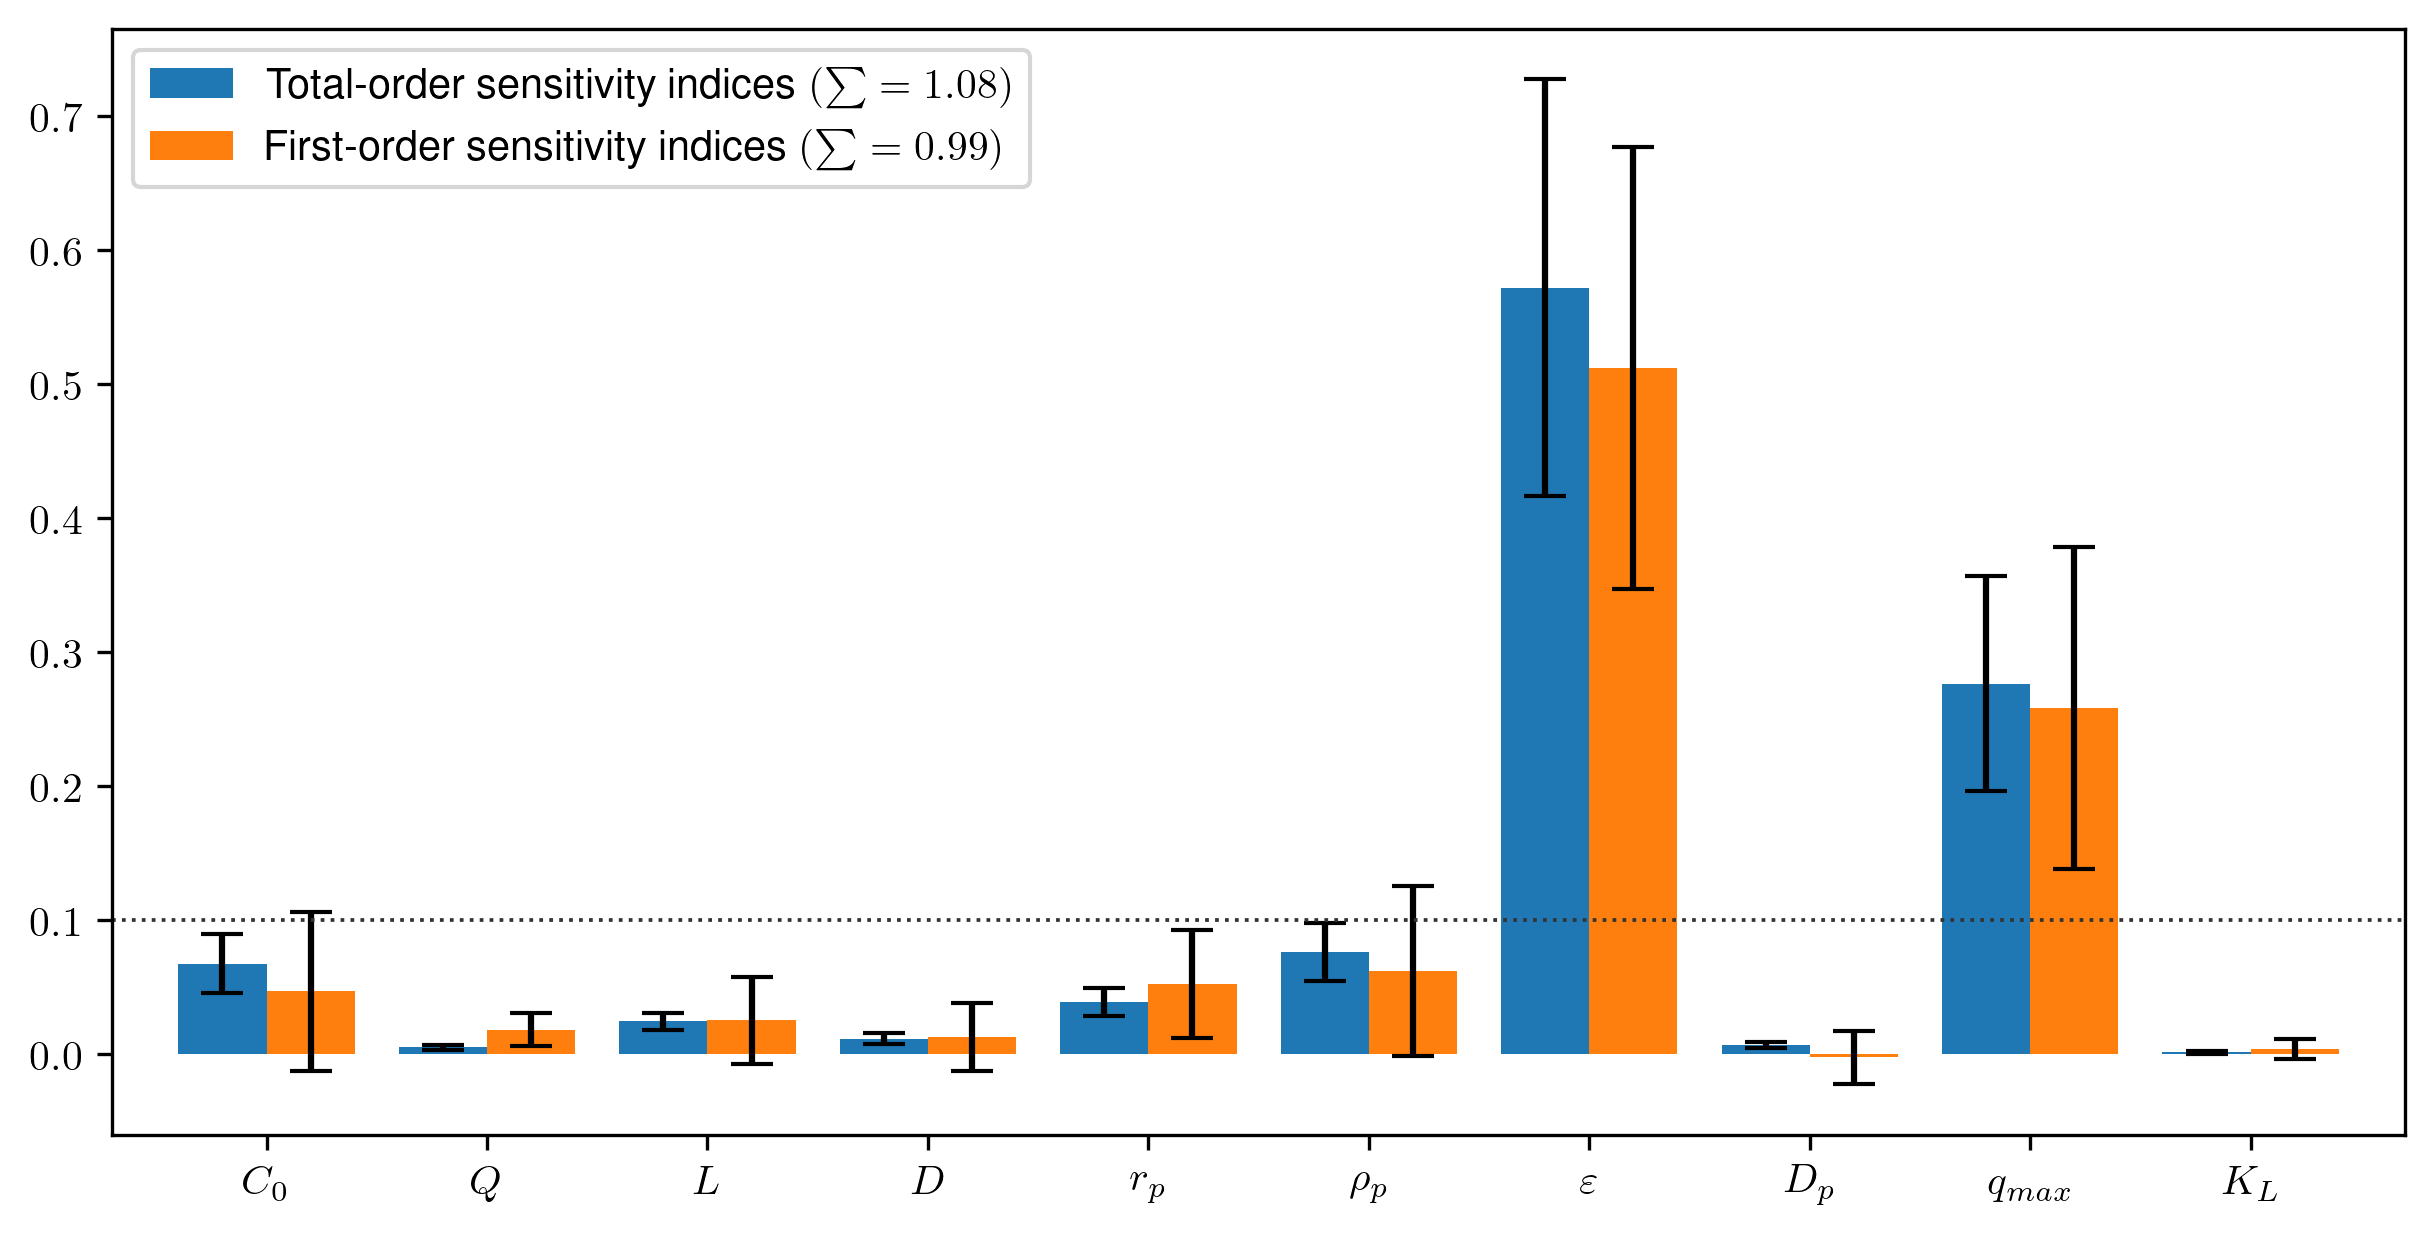

In [ ]:
Si, total_Si, first_Si, second_Si = analyze(T_Np_10_N_7_20percent, Y_Np_10_N_7_20percent, BT_Np_10_N_7_20percent, sp_Np_10_N_7_20percent, calc_second_order=True)

# Store figure
plt.savefig("Figure_5_GSA.pdf", format="pdf", bbox_inches="tight")

### Figure 6 – Heatmap

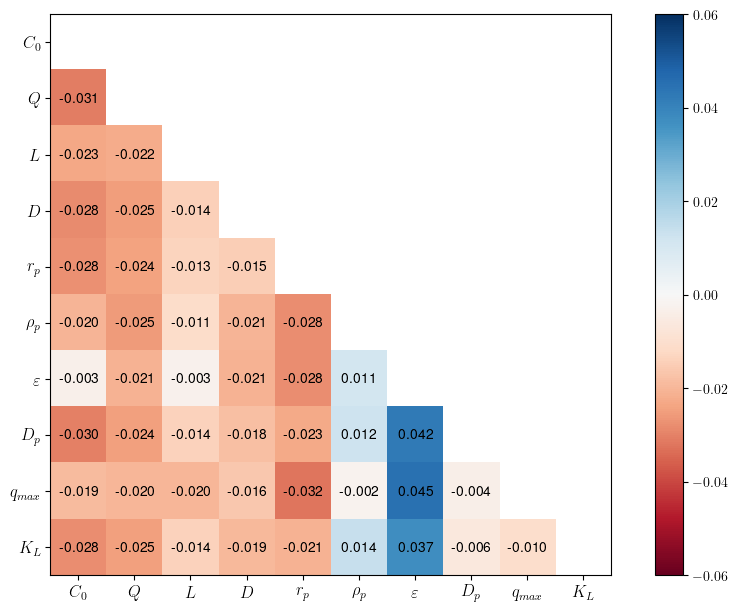

In [ ]:
plot_heatmap(Si, sp, vmax=0.06)

# Store figure
plt.savefig("Figure_6_second_order.pdf", format="pdf", bbox_inches="tight")

### Figure 7 – Calibration 

In [936]:
results_uncalibrated, _, _ = model(dt = 0.1, profiles=False, breakthrough=False, tmax=6.6)
C_uncalibrated = results_uncalibrated['Cint']
C_uncalibrated_model = results_uncalibrated['BC']
BV_uncalibrated_model = results_uncalibrated['BV']
RMSE_uncalibrated_model = results_uncalibrated['RMSE']

8aceff running: t: 6.6: : 66it [00:03, 19.48it/s]                        


RMSE (calibration) = 0.0864
SSR (calibration) = 0.1491
AIC (calibration) = -94.0


In [934]:
results_calibrated, _, _ = model(dt = 0.1, profiles=False, breakthrough=False, tmax=6.6, e=e_trf_cf['params']['e'])
C_calibrated1 = results_calibrated['Cint']
C_calibrated_model1 = results_calibrated['BC']
BV_calibrated_model1 = results_calibrated['BV']
RMSE_calibrated_model1 = results_calibrated['RMSE']

a38665 running: t: 6.6: : 66it [00:04, 15.08it/s]                        


RMSE (calibration) = 0.0233
SSR (calibration) = 0.0109
AIC (calibration) = -144.3


In [935]:
results_calibrated2, _, _ = model(dt = 0.1, profiles=False, breakthrough=False, tmax=6.6, qmax=qmax_rp_trf_cf['params']['qmax'], rp=qmax_rp_trf_cf['params']['rp'])
C_calibrated2 = results_calibrated2['Cint']
C_calibrated_model2 = results_calibrated2['BC']
BV_calibrated_model2 = results_calibrated2['BV']
RMSE_calibrated_model2 = results_calibrated2['RMSE']

ce5d94 running: t: 6.6: : 66it [00:03, 17.37it/s]                        


RMSE (calibration) = 0.0206
SSR (calibration) = 0.0085
AIC (calibration) = -147.3


In [932]:
results_calibrated3, _, _ = model(dt = 0.1, profiles=False, breakthrough=False, tmax=6.6, e=e_qmax_rp_trf_cf['params']['e'], qmax=e_qmax_rp_trf_cf['params']['qmax'], rp=e_qmax_rp_trf_cf['params']['rp'])
C_calibrated3 = results_calibrated3['Cint']
C_calibrated_model3 = results_calibrated3['BC']
BV_calibrated_model3 = results_calibrated3['BV']
RMSE_calibrated_model3 = results_calibrated3['RMSE']

5f6a24 running: t: 6.6: : 66it [00:03, 16.86it/s]                        


RMSE (calibration) = 0.0206
SSR (calibration) = 0.0085
AIC (calibration) = -145.3


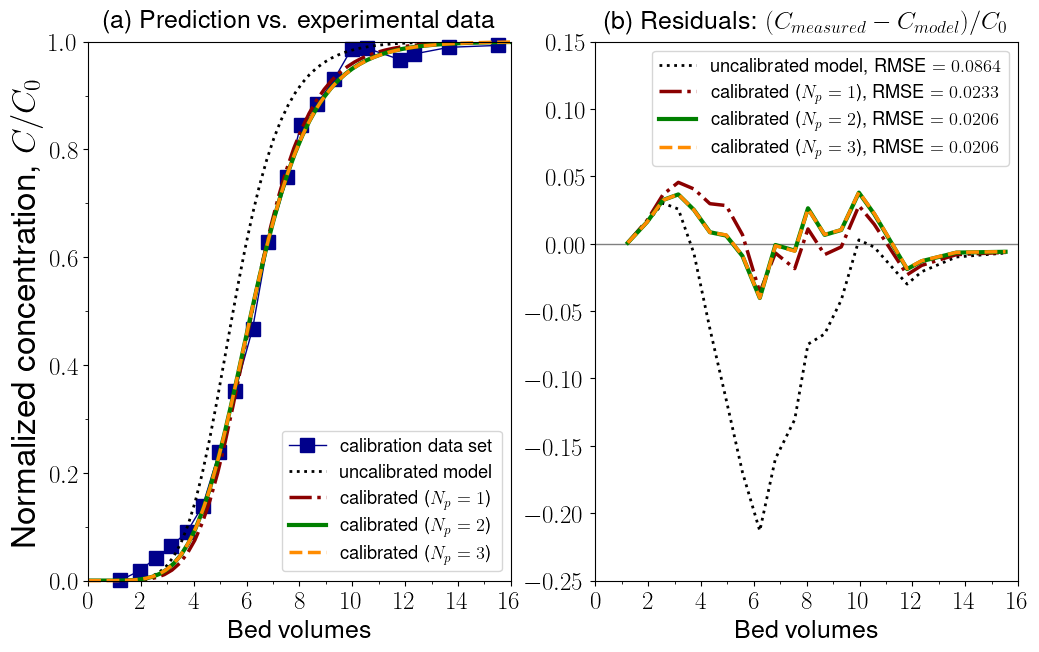

In [944]:
# Plot results
size = 12
fig, ax = plt.subplots(1, 2, figsize=(size,size-5))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
    # "text.latex.preamble" : r"\usepackage{amsmath}"
    })

# Scientific notation for exponential values
def as_si(x, ndp):
    s = '{x:0.{ndp:d}e}'.format(x=x, ndp=ndp)
    m, e = s.split('e')
    return r'{m:s}\times 10^{{{e:d}}}'.format(m=m, e=int(e))

# Run model with original and calibrated parameters
global RMSE
# C_uncalibrated, _, _, _, _, _, RMSE_uncalibrated = model(**uncalibrated_values)
# RMSE_uncalibrated = RMSE
# C_calibrated = y_func(texp, *param_calib)
# RMSE_calibrated = RMSE
t = np.linspace(0, tmax, int(tmax/dt +1))

# Create figure
plt.rcParams['text.usetex'] = True
# plt.suptitle(r"Breakthrough curve: calibration of model parameters $N_p =$ 1–3", fontsize=2*size, y=1.02) # $q_{max}$, $r_p$, $\varepsilon$

# Plot experimental data
ax[0].plot(texp1a, Cexp1a, color='darkblue', marker='s', markersize=10, lw=1, label='calibration data set', clip_on=False)

# Plot original values
ax[0].plot(BV_uncalibrated_model, C_uncalibrated_model, linestyle=':', color='black', linewidth=2, label=f'uncalibrated model', clip_on=True)

# Plot calibrated values
ax[0].plot(BV_calibrated_model1, C_calibrated_model1, markevery=2, color='darkred', linestyle='-.', linewidth=2.5, label=f'calibrated ($N_p = 1$)', clip_on=True)
ax[0].plot(BV_calibrated_model2, C_calibrated_model2, markevery=2, color='green', linestyle='-', linewidth=3, label=f'calibrated ($N_p = 2$)', clip_on=True)
ax[0].plot(BV_calibrated_model3, C_calibrated_model3, markevery=2, color='darkorange', linestyle='--', linewidth=2.5, label=f'calibrated ($N_p = 3$)', clip_on=False)

# ax[0].set_title("$q_{max}=\\,$"+"${:.3f}$".format(calibrated_parameters['qmax'])+
            #  ", $r_p=\\,$"+"${0:s}$".format(as_si(calibrated_parameters['rp'],2)), fontsize=2*size, pad=10)
ax[0].set_title(r'(a) Prediction vs. experimental data', fontsize=1.5*size, pad=10)
ax[0].set_xlabel(r'Bed volumes', fontsize=1.5*size)
ax[0].set_ylabel(r'Normalized concentration, $C/C_0$', fontsize=2*size)
ax[0].tick_params(labelsize=1.5*size)
ax[0].set_xticks(np.arange(0, 17, 2))
ax[0].set_xticks(np.arange(0, 16, 1), minor=True)
ax[0].set_yticks(np.arange(0, 1, 0.1), minor=True)
ax[0].set_ylim(0, 1)
ax[0].set_xlim(0, 16)
ax[0].legend(fontsize=1.1*size, loc='lower right')

# Plot residuals
ax[1].set_title(r'(b) Residuals: $(C_{measured}-C_{model})/C_0$', fontsize=1.5*size, pad=10)
ax[1].axhline(0, color='gray', linewidth=1, linestyle='-')
# ax[1].scatter(texp, Cexp-C_uncalibrated, color='darkorange', marker='s', s=10*size)
# ax[1].scatter(texp, Cexp-C_calibrated, color='green', marker='s', s=10*size)
res_uncalibrated = Cexp1a - C_uncalibrated
res_calibrated1 = Cexp1a - C_calibrated1
res_calibrated2 = Cexp1a - C_calibrated2
res_calibrated3 = Cexp1a - C_calibrated3
# print(res_calibrated)
# print(res_calibrated2)
# print(res_calibrated - res_calibrated2)
ax[1].plot(texp1a, res_uncalibrated, ':', color='black', linewidth=2, label=f'uncalibrated model, RMSE $= {RMSE_uncalibrated_model:.4f}$')
ax[1].plot(texp1a, res_calibrated1, '-.', color='darkred', linewidth=2.5, label=f'calibrated ($N_p = 1$), RMSE $={RMSE_calibrated_model1:.4f}$')
ax[1].plot(texp1a, res_calibrated2, '-', color='green', linewidth=3, label=f'calibrated ($N_p = 2$), RMSE $={RMSE_calibrated_model2:.4f}$')
ax[1].plot(texp1a, res_calibrated3, '--', color='darkorange', linewidth=2.5, label=f'calibrated ($N_p = 3$), RMSE $= {RMSE_calibrated_model3:.4f}$')
# ax[1].set_ylabel(r'Residuals, $C_{exp}-C$', fontsize=2*size)
ax[1].set_xticks(np.arange(0, 16, 1), minor=True)
ax[1].set_xticks(np.arange(0, 17, 2))
ax[1].set_xlim(0, 16)
ax[1].set_ylim(-0.25, 0.15)
ax[1].set_yticks(np.arange(-0.25, 0.16, 0.05))
ax[1].set_xlabel(r'Bed volumes', fontsize=1.5*size)
ax[1].tick_params(labelsize=1.5*size)
ax[1].legend(fontsize=1.1*size, loc='upper right')

# Store results
plt.savefig(f"Figure_7_calibration.pdf", format="pdf", bbox_inches="tight")

### Figure 8 – Uncertainty

In [719]:
BV_calibrated1 = qmax_rp_trf_cf['BV']
C_calibration_model1 = qmax_rp_trf_cf['BC']
RMSE_calibrated1 = qmax_rp_trf_cf['RMSE']

In [567]:
BV_calibrated2 = e_qmax_trf_cf['BV']
C_calibration_model2 = e_qmax_trf_cf['BC']
RMSE_calibrated2 = e_qmax_trf_cf['RMSE']

In [549]:
BV_calibrated3 = e_qmax_rp_trf_cf['BV']
C_calibration_model3 = e_qmax_rp_trf_cf['BC']
RMSE_calibrated3 = e_qmax_rp_trf_cf['RMSE']

In [174]:
# Estimate earliest breakthrough time
t = np.linspace(0, 16, 500)
sims1_LCI = np.percentile(sims1, 50 - prediction_interval/2., axis=0)
sims1_UCI = np.percentile(sims1, 50 + prediction_interval/2., axis=0)
t[np.where(np.interp(t, time1[0,:], sims1_LCI) >= 0.1)[0][0]]
# t[np.where(np.interp(t, time1[0,:], sims1_UCI) >= 0.1)[0][0]]

4.296593186372745

In [173]:
sims2_LCI = np.percentile(sims2, 50 - prediction_interval/2., axis=0)
sims2_UCI = np.percentile(sims2, 50 + prediction_interval/2., axis=0)
t[np.where(np.interp(t, time2[0,:], sims2_LCI) >= 0.1)[0][0]]
# t[np.where(np.interp(t, time2[0,:], sims2_UCI) >= 0.1)[0][0]]

6.861723446893787

In [172]:
sims3_LCI = np.percentile(sims3[np.where((time3[:,-1] >= tmin) & (sims3[:,-1] >= Cmin))[0],:], 50 - prediction_interval/2., axis=0)
sims3_UCI = np.percentile(sims3[np.where((time3[:,-1] >= tmin) & (sims3[:,-1] >= Cmin))[0],:], 50 + prediction_interval/2., axis=0)
t[np.where(np.interp(t, time3[0,:], sims3_LCI) >= 0.1)[0][0]]
t[np.where(np.interp(t, time3[0,:], sims3_UCI) >= 0.1)[0][0]]

1.250501002004008

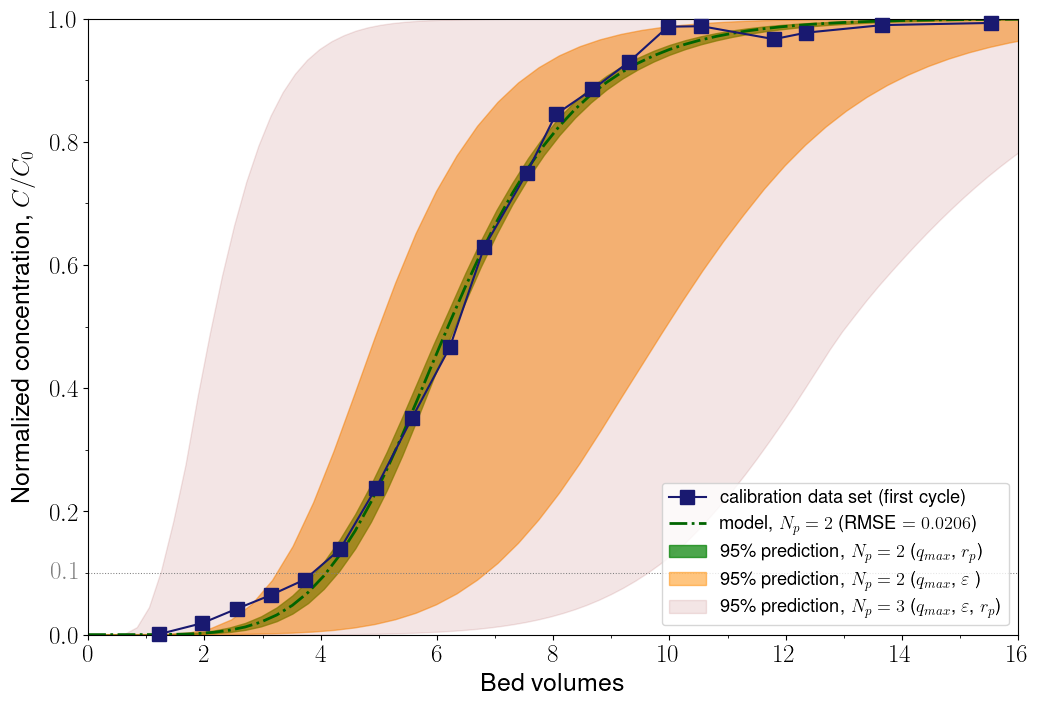

In [727]:
# Plot all simulations
size = 12
fig, ax1 = plt.subplots(figsize=(size, 8))

plt.rcParams['text.usetex'] = True

# Plot data
ax1.plot(texp1a, Cexp1a, color='midnightblue', linestyle='-', marker='s', markersize=10, label=f'calibration data set (first cycle)', zorder=3, clip_on=False)

# Plot model
ax1.plot(BV_calibrated1, C_calibration_model1, color='darkgreen', linewidth=2, linestyle='-.', label=f'model, $N_p = 2$ (RMSE $= {RMSE_calibrated1:.4f}$)', clip_on=True)
# ax1.plot(BV_calibrated2, C_calibration_model2, color='darkorange', linewidth=2, linestyle='--', label=f'model (RMSE $= {RMSE_calibrated2:.4f}$)', clip_on=True)
# ax1.plot(BV_calibrated3, C_calibration_model3, color='darkred', linewidth=2, linestyle='--', label=f'model (RMSE $= {RMSE_calibrated3:.4f}$)', clip_on=True)

# Plot uncertainty bands
prediction_interval = 95

ax1.fill_between(time1[0,:],
                 np.percentile(sims1, 50 - prediction_interval/2., axis=0),
                 np.percentile(sims1, 50 + prediction_interval/2., axis=0),
                 alpha=0.7, color='green',
                 label=f"{prediction_interval:d}\% prediction, $N_p = 2$ ($q_{{max}}$, $r_p$)")

ax1.fill_between(time2[0,:],
                 np.percentile(sims2, 50 - prediction_interval/2., axis=0),
                 np.percentile(sims2, 50 + prediction_interval/2., axis=0),
                 alpha=0.5, color='darkorange',
                 label=f"{prediction_interval:d}\% prediction, $N_p = 2$ ($q_{{max}}$, $\\varepsilon$)")

Cmin = 0.5
tmin = 1

ax1.fill_between(time3[0,:],
                 np.percentile(sims3[np.where((time3[:,-1] >= tmin) & (sims3[:,-1] >= Cmin))[0],:], 50 - prediction_interval/2., axis=0),
                 np.percentile(sims3[np.where((time3[:,-1] >= tmin) & (sims3[:,-1] >= Cmin))[0],:], 50 + prediction_interval/2., axis=0),
                 alpha=0.1, color='darkred',
                 label=f"{prediction_interval:d}\% prediction, $N_p = 3$ ($q_{{max}}$, $\\varepsilon$, $r_p$)")

ax1.set_ylabel('Normalized concentration, $C/C_0$', fontsize=1.5*size, labelpad=10)
ax1.set_yticks(np.arange(0, 1, 0.1), minor=True)
ax1.tick_params(labelsize=1.5*size)
ax1.set_ylim(0, 1)
ax1.set_xlim(0, 16)
ax1.set_xticks(np.arange(0, 17, 2))
ax1.set_xticks(np.arange(0, 17, 1), minor=True)
ax1.set_xlabel('Bed volumes', fontsize=1.5*size)
ax1.legend(loc='lower right', fontsize=1.1*size)

ax1.text(-0.15, 0.1, "$0.1$", color='grey', fontsize=1.5*size, ha='right', va='center')
ax1.hlines(0.1, 0, 16, color='grey', linestyle=':', lw=0.75)

# Store figure
plt.savefig(f"Figure_8_uncertainty.pdf", format="pdf", bbox_inches="tight")


## Figure 9

In [ ]:
# Plot all simulations
size = 12
fig, ax1 = plt.subplots(figsize=(size, 8))

# plt.rcParams['text.usetex'] = True
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
    # "text.latex.preamble" : r"\usepackage{amsmath}"
    })

ax1.set_clip_on(False)

# Plot model
ax1.plot(BV_validated_model, C_validated_model, color='green', linewidth=3, linestyle='-', label=f'prediction ($q_0 = {q1/qm:.2f}$, RMSE $= {RMSE_validated_model:.4f}$)', clip_on=False)
# ax1.plot(BV_validated2, C_validated_model2, color='darkred', linewidth=3, linestyle='--', label=f'prediction ($q_0 = {q02/qm:.2f}$, RMSE $= {RMSE_validation2:.4f}$)', clip_on=False)
# ax1.plot(BV_uncalibrated, C_uncalibrated_model, color='grey', linestyle='--', linewidth=3, label=f'uncalibrated (RMSE = ${RMSE_uncalibrated:.4f}$)')

# Plot data
# ax1.plot(texp1a, Cexp1a, color='midnightblue', linestyle='-', marker='s', markersize=10,    label=f'calibration data, $C_0 = 672$ mg/L', zorder=3)
ax1.plot(texp2a, Cexp2a, color='darkred', linewidth=1, linestyle='-', marker='D', markersize=10, zorder=2, label=f'validation data (second cycle)', clip_on=False)
# ax1.plot(texp3a, Cexp3a, color='darkred', linewidth=1, linestyle='-', marker='D', markersize=10, zorder=2, label=f'validation data (third cycle)', clip_on=False)

ax1.text(-0.15, 0.1, "$0.1$", color='grey', fontsize=1.5*size, ha='right', va='center')
ax1.hlines(0.1, 0, 16, color='grey', linestyle=':')

ax1.set_ylabel('Normalized concentration, $C/C_0$', fontsize=1.5*size, labelpad=10)
ax1.set_yticks(np.linspace(0, 1, 11))
ax1.tick_params(labelsize=1.5*size)
ax1.set_ylim(0, 1)
ax1.legend(loc='upper left', fontsize=1.25*size)

# Time in minutes
ax1.set_xlim(0, 16)
ax1.set_yticks(np.arange(0, 1.1, 0.2))
ax1.set_yticks(np.arange(0, 1.1, 0.1), minor=True)
ax1.set_xticks(np.arange(0, 17, 2))
ax1.set_xticks(np.arange(0, 16, 1), minor=True)
ax1.set_xlabel('Bed volumes', fontsize=1.5*size)

# Inset graph
from mpl_toolkits.axes_grid.inset_locator import (inset_axes, InsetPosition, mark_inset) # type: ignore
# Create a set of inset Axes: these should fill the bounding box allocated to them.
ax2 = plt.axes([0, 0, 1, 1]) # type: ignore
# Manually set the position and relative size of the inset axes within ax1
ip = InsetPosition(ax1, [0.5,0.08,0.47,0.4])
ax2.set_axes_locator(ip)
# Mark the region corresponding to the inset axes on ax1 and draw lines in grey linking the two axes.
mark_inset(ax1, ax2, loc1=2, loc2=4, fc="none", ec='0.6')
# The data: only display for low temperature in the inset figure.
tmaxmin = 7

# ax2.fill_between(time[0,:],
#                  np.percentile(sims, 50 - prediction_interval/2., axis=0),
#                  np.percentile(sims, 50 + prediction_interval/2., axis=0),
#                  alpha=0.4, color='midnightblue',
#                  label=f"{prediction_interval:d}\% prediction interval")


# Plot model
# ax2.plot(BV, 672*C_calibrated_model, color='darkred', linewidth=3, linestyle='--',                        label=f'calibrated   (RMSE = {RMSE_calibrated:.4f})')
ax2.plot(BV_validated_model, C_validated_model, color='green', linewidth=3)
# ax2.plot(BV_validated2, C_validated_model2, color='darkred', linewidth=3, linestyle='--')

# ax2.plot(BV_uncalibrated, C_uncalibrated_model, color='grey', linestyle='--', linewidth=3, label=f'uncalibrated (RMSE = ${RMSE_uncalibrated:.4f}$)')

# Plot data
# ax2.plot(texp1a, 672*Cexp1a, color='midnightblue', linestyle='-', marker='s', markersize=10,    label=f'calibration data $C_0 = 672$ mg/L', zorder=3)
# ax2.errorbar(tval, Cval, yerr=(1*Cerr), fmt='-', color='darkorange', marker='D', markersize=8, zorder=3, capsize=5, label=f'validation data,  $C_0 = 713$ mg/L')
ax2.plot(texp2a, Cexp2a, color='darkred', linewidth=1, linestyle='-', marker='D', markersize=10, zorder=2, clip_on=True)
# ax2.plot(texp3a, Cexp3a, color='darkred', linewidth=1, linestyle='-', marker='D', markersize=10, zorder=2, clip_on=True)

# ax2.plot([0, 16],[0.05,0.05], color='gray', linestyle=':')
# ax1.plot([0, 16],[0.1,0.1], color='gray', linestyle=':', alpha=0.5)

ax2.set_xlim(0, 4)
ax2.set_ylim(0, 0.2)
ax2.set_xticks(np.arange(0, 5, 1))
ax2.set_xticks(np.arange(0, 4, 0.5), minor=True)
ax2.set_yticks(np.arange(0, 0.25, 0.1))
ax2.set_yticks(np.arange(0, 0.25, 0.05), minor=True)
ax2.hlines(0.1, 0, 16, color='grey', linestyle=':')

# plt.savefig("Figure_10"+".pdf", format="pdf", bbox_inches="tight")

## Figure 10

## Graphical abstract

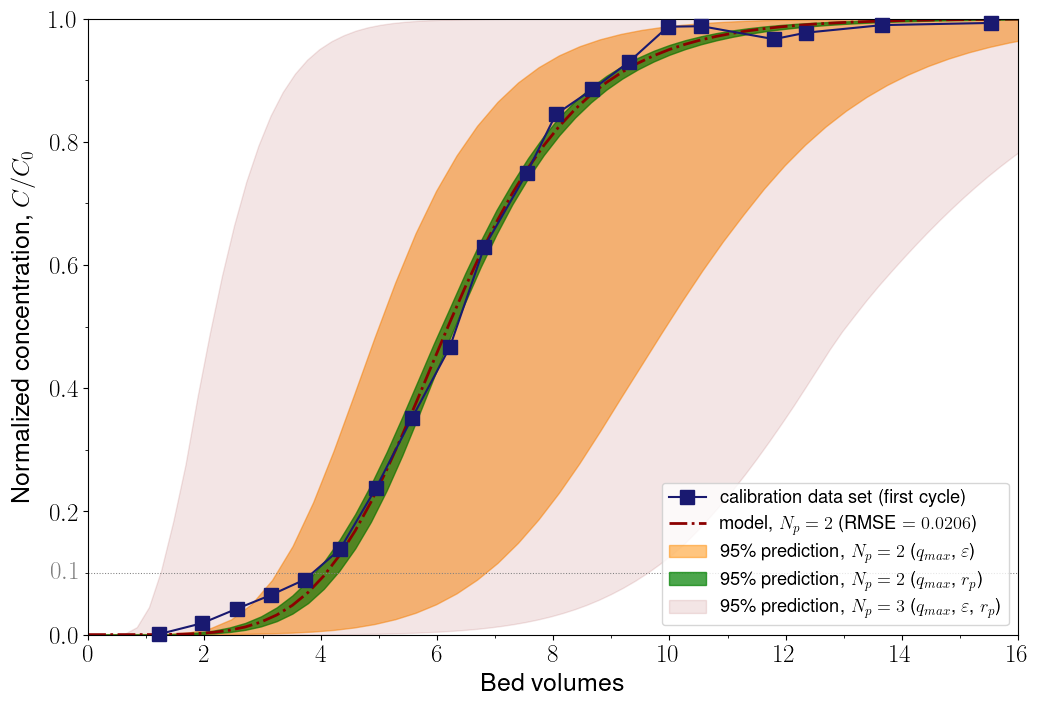

In [130]:
# Plot all simulations
size = 12
fig, ax1 = plt.subplots(figsize=(size, 8))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
    })

# Plot data
ax1.plot(texp1a, Cexp1a, color='midnightblue', linestyle='-', marker='s', markersize=10, label=f'calibration data set (first cycle)', zorder=3, clip_on=False)

# Plot model
ax1.plot(BV_calibrated1, C_calibration_model1, color='darkred', linewidth=2, linestyle='-.', label=f'model, $N_p = 2$ (RMSE $= {RMSE_calibrated1:.4f}$)', clip_on=True)
# ax1.plot(BV_calibrated2, C_calibration_model2, color='darkorange', linewidth=2, linestyle='--', label=f'model (RMSE $= {RMSE_calibrated2:.4f}$)', clip_on=True)
# ax1.plot(BV_calibrated3, C_calibration_model3, color='darkred', linewidth=2, linestyle='--', label=f'model (RMSE $= {RMSE_calibrated3:.4f}$)', clip_on=True)

# Plot uncertainty bands
prediction_interval = 95


ax1.fill_between(time2[0,:],
                 np.percentile(sims2, 50 - prediction_interval/2., axis=0),
                 np.percentile(sims2, 50 + prediction_interval/2., axis=0),
                 alpha=0.5, color='darkorange',
                 label=f"{prediction_interval:d}\% prediction, $N_p = 2$ ($q_{{max}}$, $\\varepsilon$)")

ax1.fill_between(time1[0,:],
                 np.percentile(sims1, 50 - prediction_interval/2., axis=0),
                 np.percentile(sims1, 50 + prediction_interval/2., axis=0),
                 alpha=0.7, color='green',
                 label=f"{prediction_interval:d}\% prediction, $N_p = 2$ ($q_{{max}}$, $r_p$)")


Cmin = 0.5
tmin = 1

ax1.fill_between(time3[0,:],
                 np.percentile(sims3[np.where((time3[:,-1] >= tmin) & (sims3[:,-1] >= Cmin))[0],:], 50 - prediction_interval/2., axis=0),
                 np.percentile(sims3[np.where((time3[:,-1] >= tmin) & (sims3[:,-1] >= Cmin))[0],:], 50 + prediction_interval/2., axis=0),
                 alpha=0.1, color='darkred',
                 label=f"{prediction_interval:d}\% prediction, $N_p = 3$ ($q_{{max}}$,  $\\varepsilon$, $r_p$)")

ax1.set_ylabel('Normalized concentration, $C/C_0$', fontsize=1.5*size, labelpad=10)
ax1.set_yticks(np.arange(0, 1, 0.1), minor=True)
ax1.tick_params(labelsize=1.5*size)
ax1.set_ylim(0, 1)
ax1.set_xlim(0, 16)
ax1.set_xticks(np.arange(0, 17, 2))
ax1.set_xticks(np.arange(0, 17, 1), minor=True)
ax1.set_xlabel('Bed volumes', fontsize=1.5*size)
ax1.legend(loc='lower right', fontsize=1.1*size)

ax1.text(-0.15, 0.1, "$0.1$", color='grey', fontsize=1.5*size, ha='right', va='center')
ax1.hlines(0.1, 0, 16, color='grey', linestyle=':', lw=0.75)

# Store figure
plt.savefig(f"Figure_8_uncertainty.pdf", format="pdf", bbox_inches="tight")


### Confidence regions

N = 256
rp (mean ± 2*std) = 4.316e-04 ± 2*9.169e-06 (94.5%)
qmax (mean ± 2*std) = 0.326 ± 2*0.0012 (96.9%)


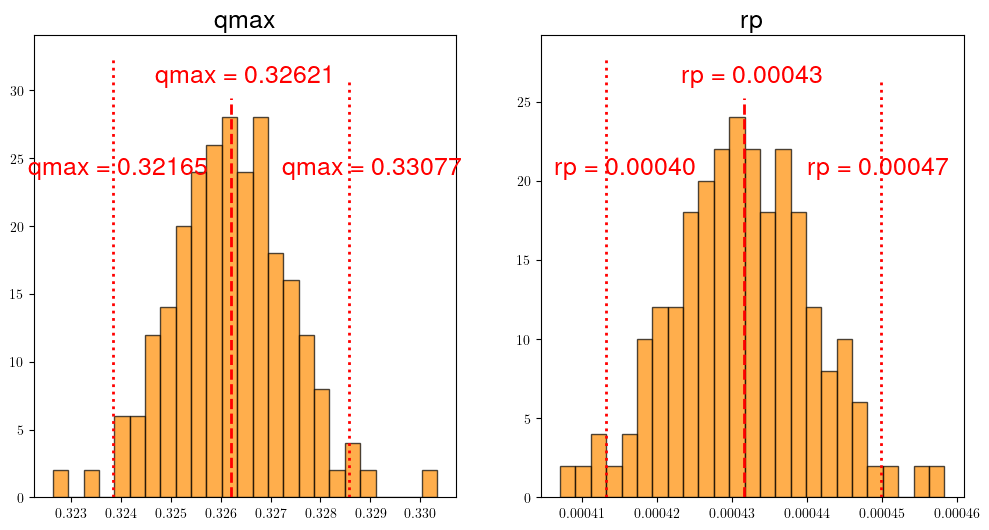

In [119]:
# Read file
Np= 2
N = 2**6
print("N =", N*(Np+2))
calibrated_parameters = qmax_rp_trf_cf['param_calib']
joined_names = "qmax-rp"
pars = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv")

# Verify sampling
results = qmax_rp_trf_cf

inside_qmax = len(pars['qmax'][(pars['qmax'] >= np.mean(pars['qmax']) - 2*np.std(pars['qmax']) ) & (pars['qmax'] <= np.mean(pars['qmax']) + 2*np.std(pars['qmax']))])
inside_rp = len(pars['rp'][(pars['rp'] >= np.mean(pars['rp']) - 2*np.std(pars['rp']) ) & (pars['rp'] <= np.mean(pars['rp']) + 2*np.std(pars['rp']) )])
total_points = len(pars)
percentage_inside_qmax = (inside_qmax / total_points) * 100
percentage_inside_rp = (inside_rp / total_points) * 100

print("rp (mean ± 2*std) = {:.3e} ± 2*{:.3e} ({:.1f}%)".format(np.mean(pars['rp']), np.std(pars['rp']), percentage_inside_rp))
print("qmax (mean ± 2*std) = {:.3f} ± 2*{:.4f} ({:.1f}%)".format(np.mean(pars['qmax']), np.std(pars['qmax']), percentage_inside_qmax))

# Create histograms

size = 6
nbins = 25
fig, ax = plt.subplots(1, Np, figsize=(Np*size,size))

for parameter in calibrated_parameters.keys():
	i = list(pars.keys()).index(parameter)-1
	ax[i].hist(pars[parameter], bins=nbins, color='darkorange', edgecolor='black', alpha=0.7)
	ax[i].set_title(f'{parameter}', fontsize=3*size)
	ax[i].vlines(np.mean(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dashed', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])+2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])-2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)

	ax[i].text(0.5, 0.9, f"{parameter:s} = {calibrated_parameters[parameter]:.5f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.8, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]+2*results['CI'][parameter]/2:.5f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.2, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]-2*results['CI'][parameter]/2:.5f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')

In [124]:
# Read file
Np = 2
N = 2**6
print("N =", N*(Np+2))
joined_names = "e-qmax"
pars1 = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv")
calibrated_parameters = e_qmax_trf_cf['param_calib']
covariance1 = e_qmax_trf_cf['covariance']
FIM1 = e_qmax_trf_cf['FIM']

# Verify sampling
results = e_qmax_trf_cf

inside_qmax = len(pars['qmax'][(pars['qmax'] >= np.mean(pars['qmax']) - 2*np.std(pars['qmax']) ) & (pars['qmax'] <= np.mean(pars['qmax']) + 2*np.std(pars['qmax']))])
inside_e = len(pars['e'][(pars['e'] >= np.mean(pars['e']) - 2*np.std(pars['e']) ) & (pars['e'] <= np.mean(pars['e']) + 2*np.std(pars['e']) )])
total_points = len(pars)
percentage_inside_qmax = (inside_qmax / total_points) * 100
percentage_inside_e = (inside_e / total_points) * 100

print("e (mean ± 2*std) = {:.3f} ± 2*{:.3f} ({:.1f}%)".format(np.mean(pars['e']), np.std(pars['e']), percentage_inside_e))
print("qmax (mean ± 2*std) = {:.3f} ± 2*{:.4f} ({:.1f}%)".format(np.mean(pars['qmax']), np.std(pars['qmax']), percentage_inside_qmax))

# Create histograms

size = 6
nbins = 25
fig, ax = plt.subplots(1, Np, figsize=(Np*size,size))

for parameter in pars.keys()[1:]:
	i = list(pars.keys()[1:]).index(parameter)-1
	ax[i].hist(pars[parameter], bins=nbins, color='darkorange', edgecolor='black', alpha=0.7)
	ax[i].set_title(f'{parameter}', fontsize=3*size)
	ax[i].vlines(np.mean(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dashed', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])+2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])-2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].text(0.5, 0.9, f"{parameter:s} = {calibrated_parameters[parameter]:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.8, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]+2*results['CI'][parameter]/2:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.2, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]-2*results['CI'][parameter]/2:.3f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')

N = 256


KeyError: 'e'

N = 160
rp (mean ± 2*std) = 4.64e-04 ± 2*4.92e-05 (95.0%)
e (mean ± 2*std) = 0.410 ± 2*0.153 (96.9%)
qmax (mean ± 2*std) = 0.388 ± 2*0.1339 (93.8%)


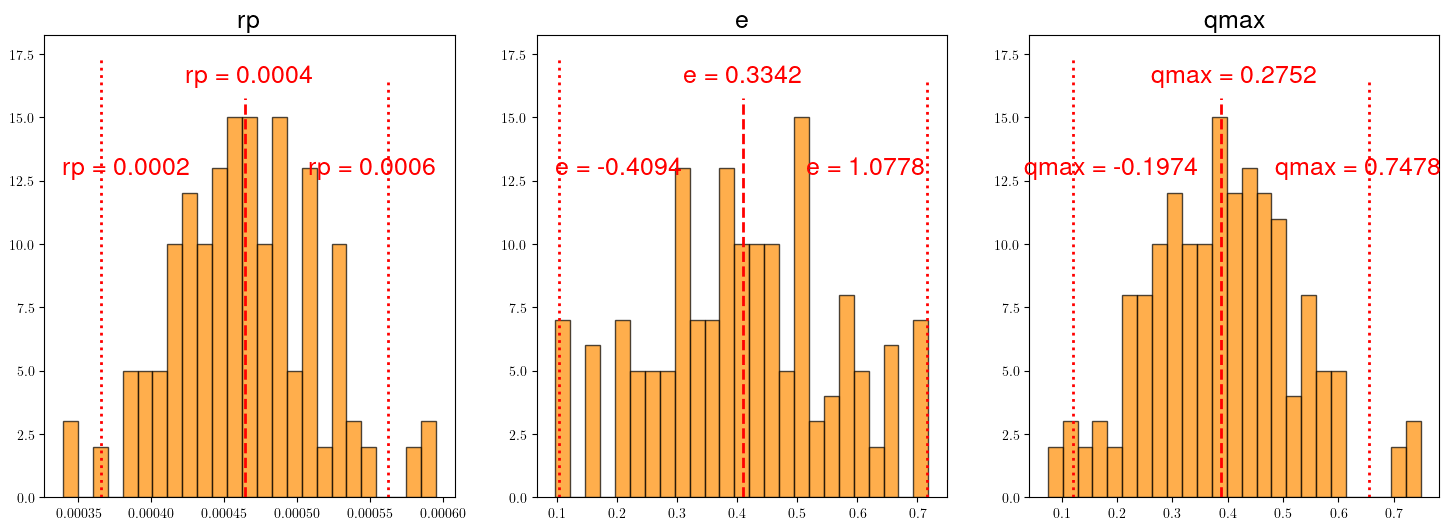

In [100]:
# Read file
Np = 3
N = 2**5
print("N =", N*(Np+2))
joined_names = "rp-e-qmax"
pars3 = pd.read_csv(f"sampling-UA_Np-{Np:d}_N-{N:d}_{joined_names:s}.csv")
calibrated_parameters = e_qmax_rp_trf_cf['param_calib']

# Verify sampling

inside_qmax = len(pars['qmax'][(pars['qmax'] >= np.mean(pars['qmax']) - 2*np.std(pars['qmax']) ) & (pars['qmax'] <= np.mean(pars['qmax']) + 2*np.std(pars['qmax']))])
inside_rp = len(pars['rp'][(pars['rp'] >= np.mean(pars['rp']) - 2*np.std(pars['rp']) ) & (pars['rp'] <= np.mean(pars['rp']) + 2*np.std(pars['rp']) )])
inside_e = len(pars['e'][(pars['e'] >= np.mean(pars['e']) - 2*np.std(pars['e']) ) & (pars['e'] <= np.mean(pars['e']) + 2*np.std(pars['e']) )])
total_points = len(pars)
percentage_inside_qmax = (inside_qmax / total_points) * 100
percentage_inside_rp = (inside_rp / total_points) * 100
percentage_inside_e = (inside_e / total_points) * 100


print("rp (mean ± 2*std) = {:.2e} ± 2*{:.2e} ({:.1f}%)".format(np.mean(pars['rp']), np.std(pars['rp']), percentage_inside_rp))
print("e (mean ± 2*std) = {:.3f} ± 2*{:.3f} ({:.1f}%)".format(np.mean(pars['e']), np.std(pars['e']), percentage_inside_e))
print("qmax (mean ± 2*std) = {:.3f} ± 2*{:.4f} ({:.1f}%)".format(np.mean(pars['qmax']), np.std(pars['qmax']), percentage_inside_qmax))

# Create histograms

size = 6
nbins = 25
fig, ax = plt.subplots(1, Np, figsize=(Np*size,size))

for parameter in calibrated_parameters.keys():
	i = list(pars.keys()).index(parameter)-1
	ax[i].hist(pars[parameter], bins=nbins, color='darkorange', edgecolor='black', alpha=0.7)
	ax[i].set_title(f'{parameter}', fontsize=3*size)
	ax[i].vlines(np.mean(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dashed', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])+2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].vlines(np.mean(pars[parameter])-2*np.std(pars[parameter]), ymin=0, ymax=ax[i].get_ylim()[1], color='red', linestyle='dotted', linewidth=2)
	ax[i].text(0.5, 0.9, f"{parameter:s} = {calibrated_parameters[parameter]:.4f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.8, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]+e_qmax_rp_trf_cf['CI'][parameter]/2:.4f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')
	ax[i].text(0.2, 0.7, f"{parameter:s} = {calibrated_parameters[parameter]-e_qmax_rp_trf_cf['CI'][parameter]/2:.4f}", fontsize=3*size, transform=ax[i].transAxes, color='red', ha='center')

In [127]:
eig1 = np.linalg.eigvals(FIM1)
eig1

array([1.75989942e-01, 2.45738210e+02])

Text(0, 0.5, '$\\varepsilon$')

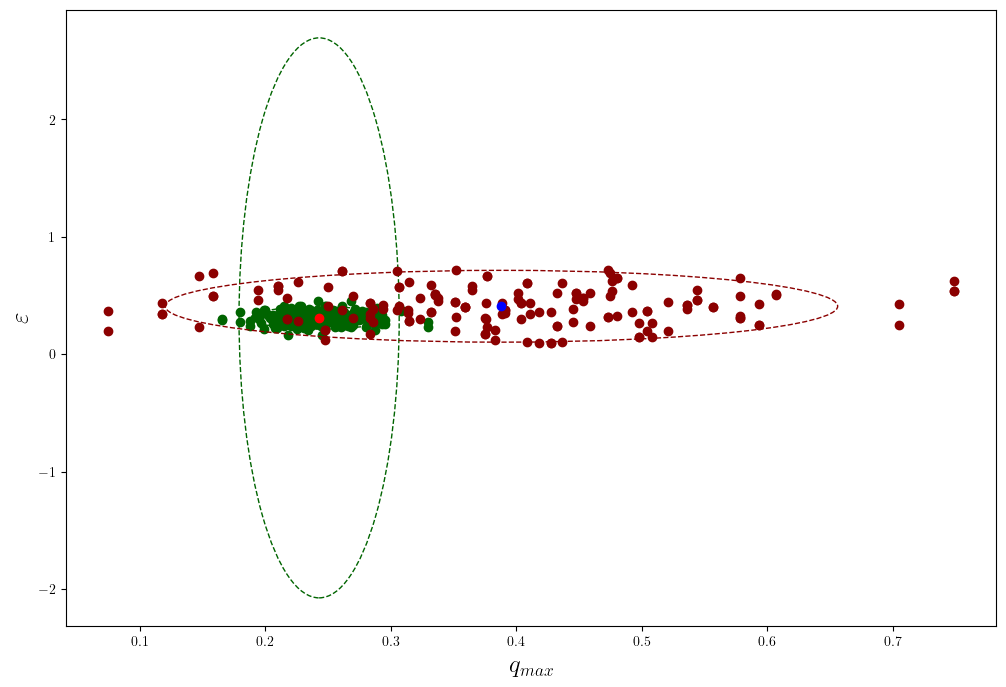

In [129]:
size = 12
fig, ax1 = plt.subplots(figsize=(size, 8))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
    })

# e and qmax

ax1.scatter(pars1['qmax'], pars1['e'], color='darkgreen')
ax1.scatter(np.mean(pars1['qmax']), np.mean(pars1['e']), color='red')

from matplotlib.patches import Ellipse
ellipse1 = Ellipse((np.mean(pars1['qmax']), np.mean(pars1['e'])), 
                      width=2 * 2*np.std(pars1['qmax']), 
                      height=2 * 2*np.std(pars1['e']),
                      angle=0,
                      facecolor='none', 
                      edgecolor='darkgreen', 
                      linestyle='dashed', 
                      linewidth=1
                      )

elleig1 = Ellipse((np.mean(pars1['qmax']), np.mean(pars1['e'])), 
                      width=2 * 1/np.sqrt(eig1[1]), 
                      height=2 * 1/np.sqrt(eig1[0]),
                      angle=0,
                      facecolor='none', 
                      edgecolor='darkgreen', 
                      linestyle='dashed', 
                      linewidth=1
                      )

ax1.add_patch(ellipse1)
ax1.add_patch(elleig1)

# rp and qmax
# ax1.scatter(pars2['qmax'], pars2['rp'], color='darkgreen')
# ax1.scatter(np.mean(pars2['qmax']), np.mean(pars2['rp']), color='red')

# ellipse1 = Ellipse((np.mean(pars2['qmax']), np.mean(pars2['rp'])), 
#                       width=2 * 2*np.std(pars2['qmax']), 
#                       height=2 * 2*np.std(pars2['rp']),
#                       angle=0,
#                       facecolor='none', 
#                       edgecolor='darkgreen', 
#                       linestyle='dashed', 
#                       linewidth=1
#                       )

# ax1.add_patch(ellipse1)

# rp, epsilon and qmax
ax1.scatter(pars3['qmax'], pars3['e'], color='darkred')
ax1.scatter(np.mean(pars3['qmax']), np.mean(pars3['e']), color='blue')

ellipse2 = Ellipse((np.mean(pars3['qmax']), np.mean(pars3['e'])), 
                      width=2 * 2*np.std(pars3['qmax']), 
                      height=2 * 2*np.std(pars3['e']),
                      angle=0,
                      facecolor='none', 
                      edgecolor='darkred', 
                      linestyle='dashed', 
                      linewidth=1
                      )

ax1.add_patch(ellipse2)

ax1.set_xlabel(r'$q_{max}$', fontsize=1.5*size)
ax1.set_ylabel(r'$\varepsilon$', fontsize=1.5*size)
# ax1.set_xticks(np.arange(0.1, 0.8, 0.1))
# ax1.set_yticks(np.arange(3.5e-4, 5.8e-4, 0.2e-4))
# ax1.legend([ellipse1, ellipse2], [r'$N_p = 2$', r'$N_p = 3$'], fontsize=1.1*size, loc='upper left')
